<a href="https://colab.research.google.com/github/JulTob/Modelling/blob/main/GLM/C3/Actuario.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cox07 · Análisis Unificado

---

# Cartera de seguros de automovil

Cuaderno de trabajo del caso 2 de Modelos Lineales Generalizados. Cada bloque reúne el texto, los cálculos, las figuras y las comprobaciones de su analista. El índice lateral de Colab permite saltar a cualquiera de ellos.

| Analista | Material |
|---|---|
| Luis Cartagena Galiano | P1 · Zona, vehículo y partes. P4 · Transiciones del bonus-malus y presupuesto. |
| Jorge Cheng Huang | P2 · Tarifa y validación. P3 · Red territorial. Exploración anterior de cuatro vías. |
| Salvador Cabanes | P5 · Riesgos por etapas, fragilidad y predicción individual. |
| Julio Toboso | [Coste por siniestro y por póliza, e impacto en el presupuesto](#scrollTo=F6FRRnvhjJb4). |

Los textos de los compañeros se conservan como borradores editables.
Las observaciones añadidas durante la integración llevan el rótulo *Nota de integración*.

## ⚠️ IMPORTANTE: NOTA A EDITORES
Colab en Github NO se auto-guarda. Cualquier cambio se debe ejecutar con `File`/`Save` y asegurarse de que se sobreescribe el archivo en su dirección absoluta en Github como sobreescritura en GitHub.
POR DEFECTO se guarda en un Google Drive particular, y la dirección de Github al seleccionarse __no tiene por qué__ ser el proyecto o carpeta de GLM para el equipo.

## Preparación
Los cinco análisis usan los datos del equipo 07. El RDS conserva los parámetros del generador que Luis y Salvador consultan al final de sus comprobaciones. Se reutiliza la descarga durante la sesión.

La primera celda prepara la sesión de R.

In [ ]:
SEMILLA_CURSO <- 20252026L

repositorio_r <- function() {
    if (!file.exists("/etc/os-release")) {
        return("https://cloud.r-project.org")
        }

    sistema <- readLines("/etc/os-release", warn = FALSE)
    linea <- grep("^VERSION_CODENAME=", sistema, value = TRUE)
    codigo <- gsub('"', "", sub("^VERSION_CODENAME=", "", linea))

    if (length(codigo) == 1L && codigo %in% c("jammy", "noble", "resolute")) {
        return(paste0(
            "https://packagemanager.posit.co/cran/__linux__/",
            codigo, "/latest"
            ))
        }

    "https://cloud.r-project.org"
    }

cargar_paquetes <- function(paquetes) {
    faltan <- setdiff(paquetes, rownames(installed.packages()))
    if (length(faltan)) {
        agente <- paste(getRversion(), R.version$platform, R.version$arch, R.version$os)
        anteriores <- options(
            HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(), agente),
            download.file.method = "libcurl"
            )
        on.exit(options(anteriores))
        message("Instalando para este apartado: ", paste(faltan, collapse = ", "))
        install.packages(
            faltan,
            repos = repositorio_r(),
            dependencies = NA
            )
        }

    for (paquete in paquetes) {
        suppressPackageStartupMessages(library(paquete, character.only = TRUE))
        }
    }

#-- Preparación de P4: conservar el ajuste de Luis si ha convergido. Evita discrepancias entre Windows y entornos Linux/Mac/Gnu...
completar_cuasisimetria <- function(
        intento,
        simetria,
        tabla
    ) {
    if (inherits(intento, "try-error")) {
        error <- attr(intento, "condition")
        if (!grepl("NA/NaN/Inf", conditionMessage(error), fixed = TRUE)) {
            stop(error)
            }
        message("El primer ajuste falló: ", conditionMessage(error))
        }
    else if (isTRUE(intento$converged)) {
        return(intento)
        }
    else {
        message("El primer ajuste no alcanzó la convergencia.")
        }

    message("Se repite el mismo modelo partiendo del ajuste de simetría.")
    modelo <- glm(
        Freq ~ prev + act + par,
        family = poisson,
        data = tabla,
        etastart = log(pmax(0.01, fitted(simetria)))
        )
    stopifnot("El segundo ajuste tampoco convergió" = isTRUE(modelo$converged))
    message("El segundo ajuste ha convergido.")
    modelo
    }

# Especificación territorial final de Jorge, compartida con el comité.
formula_cliente_p3 <- n_siniestros ~
    edad_conductor + zona_circulacion + log(km_anuales) + uso +
    offset(log(antiguedad))

message("Preparación lista. Puedes ir directamente al borrador del informe.")

Preparación lista. Puedes ir directamente al borrador del informe.



In [ ]:
cargar_paquetes(c("MASS", "tidyverse"))
#-- Paquetes que utiliza Luis en P4.
cargar_paquetes(c("broom", "patchwork", "vcd"))
theme_set(theme_minimal(base_size = 12))

base_equipo <- paste0(
  "https://raw.githubusercontent.com/asunmayoral/GLM/",
  "b05aeaecde9dca0049ea0ca55fbe162a9b964cbc/",
  "caso2/datos_equipos_auto/equipo_07/"
)
huellas <- c(
  "cartera.csv" = "6a8a1cd5a22ec0813be10b4d2173b28f",
  "panel.csv" = "813f20b73d15d78bb5777a21268d07c8",
  "siniestros.csv" = "9523e2bd2665c492d8dc1fbe5502d7de",
  "cartera.rds" = "949486c1f1c5b51ef43f441748e1932d"
)
archivo_equipo <- function(nombre) {
  ruta <- file.path("datos", nombre)
  if (!file.exists(ruta)) {
    ruta <- file.path(tempdir(), nombre)
    if (!file.exists(ruta)) {
      download.file(paste0(base_equipo, nombre), ruta, mode = "wb", quiet = TRUE)
    }
  }
  stopifnot("Huella incorrecta para los datos del equipo 07" =
              unname(tools::md5sum(ruta)) == huellas[[nombre]])
  ruta
}
cartera_original <- readr::read_csv(archivo_equipo("cartera.csv"), show_col_types = FALSE)
panel <- readr::read_csv(archivo_equipo("panel.csv"), show_col_types = FALSE)
siniestros <- readr::read_csv(archivo_equipo("siniestros.csv"), show_col_types = FALSE)
cartera_rds <- readRDS(archivo_equipo("cartera.rds"))
stopifnot(
  !anyDuplicated(cartera_original$id_poliza),
  sum(cartera_original$n_siniestros) == nrow(siniestros),
  sum(panel$n_partes_anual) == nrow(siniestros)
)
# Sorteo único de P2. Jorge, el contraste actuarial y el comité reutilizan los IDs.
ids_ajuste_p2 <- withr::with_seed(
    SEMILLA_CURSO,
    sample(cartera_original$id_poliza, floor(0.75 * nrow(cartera_original)))
    )
ids_reserva_p2 <- cartera_original$id_poliza[
    !cartera_original$id_poliza %in% ids_ajuste_p2
    ]
stopifnot(
    length(ids_ajuste_p2) == 2296L,
    length(ids_reserva_p2) == 766L,
    !anyDuplicated(c(ids_ajuste_p2, ids_reserva_p2))
    )

tibble(pólizas = nrow(cartera_original), partes = nrow(siniestros), filas_anuales = nrow(panel))

pólizas,partes,filas_anuales
<int>,<int>,<int>
3062,1770,14444


In [ ]:
#@title Explorador de la cartera de Cox07 (Seleccionar y ▶️)
zona <- "Todas"          #@param ["Todas", "urbana", "mixta", "rural"]
vehiculo <- "Todos"      #@param ["Todos", "turismo", "moto", "furgoneta"]
pagina <- 1              #@param {type:"integer"}

local({
    filas <- cartera_original
    if (zona != "Todas") filas <- dplyr::filter(filas, zona_circulacion == zona)
    if (vehiculo != "Todos") filas <- dplyr::filter(filas, tipo_vehiculo == vehiculo)
    total <- nrow(filas)
    ultima <- max(1L, ceiling(total / 10))
    actual <- max(1L, min(as.integer(pagina), ultima))
    indices <- head(seq_len(total)[seq_len(total) > (actual - 1L) * 10L], 10L)
    vista <- dplyr::relocate(filas[indices, ],
        id_poliza, zona_circulacion, tipo_vehiculo, n_siniestros,
        bonus_malus_prev, bonus_malus_act, coste_total
        )
    names(vista)[1:7] <- c("Póliza", "Zona", "Vehículo", "Partes",
        "Nivel previo", "Nivel actual", "Coste total (€)")
    tabla <- knitr::kable(vista, format = "html", row.names = FALSE, escape = TRUE)
    IRdisplay::display_html(paste0(
        '<style>.cox{font:14px system-ui;color:#18394c;background:white;padding:16px;border-top:3px solid #16736e}.cox h3{color:#102a43!important;font:600 22px Georgia;margin:0}.cox p{color:#496273}.cox table{border-collapse:collapse;white-space:nowrap;font-variant-numeric:tabular-nums}.cox th,.cox td{padding:6px 10px;border-bottom:1px solid #dce6e8}.cox th{background:#eaf2f2}.cox tr:nth-child(even){background:#f6f9fa}</style>',
        '<section class="cox"><h3>Cartera de autos · Cox07</h3><p>',
        total, ' de ', nrow(cartera_original), ' pólizas · Página ', actual, ' de ', ultima,
        ' · Una fila por póliza</p><div style="overflow-x:auto">', tabla,
        '</div><p>Para explorar, cambia los filtros o la página y ejecuta esta celda.</p></section>'
        ))
    })

Póliza,Zona,Vehículo,Partes,Nivel previo,Nivel actual,Coste total (€),id_agencia,id_region,antiguedad,exposicion,edad_conductor,edad_tramo,antiguedad_carnet,potencia_cv,cilindrada,antiguedad_vehiculo,valor_vehiculo,densidad,km_anuales,uso,combustible,sexo,color_vehiculo,estado_civil,forma_pago,financiado,n_conductores,nivel_estudios,medio_contacto,n_asistencia,n_fraude,n_gestiones,t_primer_sin,evento,t_baja,baja,motivo_fin,coste_medio,tuvo_siniestro
1,mixta,turismo,1,3,3,1334.03,1,1,1.082,0.1082,33,25-35,7,85,1417,6,35790,197,8974,particular,diesel,H,rojo,soltero,anual,0,1,superior,presencial,0,0,0,0.765,1,10.000,0,fin_estudio,1334.03,1
2,urbana,turismo,0,1,1,0.00,1,1,6.687,0.6687,44,35-65,13,142,2423,12,22089,1728,6294,particular,gasolina,M,gris,casado,anual,0,1,basico,presencial,1,3,8,6.687,0,6.826,0,fin_estudio,NA,0
3,mixta,furgoneta,4,4,4,8752.17,1,1,5.732,0.5732,62,35-65,36,118,1831,6,31528,647,9621,particular,gasolina,H,rojo,casado,mensual,1,1,superior,presencial,5,0,2,0.976,1,8.598,0,fin_estudio,2188.04,1
4,rural,turismo,0,1,1,0.00,1,1,1.397,0.1397,25,18-25,6,76,1278,9,25948,99,7485,particular,gasolina,H,otro,casado,anual,1,2,medio,presencial,0,0,0,1.397,0,1.938,0,fin_estudio,NA,0
5,urbana,turismo,0,5,4,0.00,1,1,1.968,0.1968,66,65+,36,55,824,10,20714,1046,5562,particular,diesel,H,blanco,soltero,mensual,1,1,basico,presencial,0,0,0,1.968,0,6.802,0,fin_estudio,NA,0
6,mixta,turismo,1,5,4,3584.94,1,1,3.159,0.3159,25,18-25,7,120,1816,6,15821,637,8363,particular,diesel,M,negro,casado,mensual,0,1,medio,presencial,2,0,2,0.112,1,4.188,0,fin_estudio,3584.94,1
7,urbana,turismo,3,3,4,4068.17,1,1,3.821,0.3821,18,18-25,0,143,1730,11,23040,1230,7681,particular,diesel,M,otro,otro,mensual,1,1,medio,presencial,0,2,2,0.657,1,3.821,1,baja,1356.06,1
8,mixta,moto,0,1,1,0.00,1,1,7.807,0.7807,44,35-65,11,64,1006,10,20111,180,18079,particular,diesel,H,negro,otro,mensual,0,1,superior,presencial,5,1,2,7.807,0,7.807,1,baja,NA,0
9,rural,turismo,0,1,1,0.00,1,1,4.022,0.4022,49,35-65,30,113,1624,19,38016,124,12587,comercial,diesel,M,blanco,soltero,anual,1,1,basico,presencial,1,1,3,4.022,0,4.022,1,baja,NA,0
10,rural,turismo,0,1,1,0.00,1,1,4.420,0.4420,36,35-65,7,136,2448,4,26977,57,7068,particular,gasolina,H,otro,soltero,anual,0,1,superior,presencial,0,0,1,4.420,0,9.966,0,fin_estudio,NA,0


In [ ]:
#@title Diccionario de la cartera · Categorías y cantidades
local({
    datos <- cartera_original
    nominales <- names(datos)[vapply(datos, is.character, logical(1))]
    identificadores <- c("id_poliza", "id_agencia", "id_region")
    indicadores <- c("financiado", "evento", "baja", "tuvo_siniestro")
    ordinales <- c("edad_tramo", "nivel_estudios", "bonus_malus_prev", "bonus_malus_act")
    categorias <- unique(c(nominales, identificadores, indicadores, ordinales))
    numericas <- setdiff(names(datos), categorias)
    euros <- c("valor_vehiculo", "coste_total", "coste_medio")
    reales <- c("antiguedad", "exposicion", "t_primer_sin", "t_baja")
    unidades <- c(antiguedad="años", exposicion="décadas", t_primer_sin="años", t_baja="años",
        edad_conductor="años", antiguedad_carnet="años", antiguedad_vehiculo="años",
        potencia_cv="CV", cilindrada="cm³", km_anuales="km/año", densidad="hab./km²",
        n_conductores="conductores", n_siniestros="partes", n_asistencia="asistencias",
        n_fraude="casos", n_gestiones="gestiones")
    stopifnot(all(vapply(datos[numericas], is.numeric, logical(1))))

    tipo_categoria <- function(k) {
        if (k %in% identificadores) return("Identificador")
        if (k %in% indicadores) return("Indicador binario")
        if (k %in% ordinales) return("Ordinal")
        "Nominal"
        }

    frecuencias <- function(k) {
        x <- datos[[k]]
        n <- table(x, useNA = "ifany")
        etiquetas <- names(n)
        etiquetas[is.na(etiquetas)] <- "Sin dato"
        f <- data.frame(Valor = etiquetas, Pólizas = as.integer(n),
            Porcentaje = sprintf("%.2f %%", 100 * as.integer(n) / nrow(datos)))
        stopifnot(sum(f$Pólizas) == nrow(datos))
        paste0('<details', if (k == "zona_circulacion") ' open' else '', '><summary>',
            k, ' · ', tipo_categoria(k), ' · ', length(unique(x[!is.na(x)])),
            ' valores distintos</summary><div class="lista">',
            knitr::kable(f, format="html", row.names=FALSE), '</div></details>')
        }

    resumen <- function(k) {
        x <- datos[[k]]
        validos <- x[!is.na(x)]
        tipo <- if (k %in% euros) "Monetario" else if (k %in% reales) "Real" else "Entero"
        data.frame(Atributo=k, Tipo=tipo, Unidad=if (k %in% euros) "€" else unname(unidades[k]),
            Válidos=length(validos), Ausentes=sum(is.na(x)), Mínimo=min(validos),
            Mediana=median(validos), Máximo=max(validos))
        }
    cifras <- do.call(rbind, lapply(numericas, resumen))
    stopifnot(nrow(cifras) + length(categorias) == ncol(datos))
    estilo <- '<style>.dic{color:#18394c;background:white;font:14px system-ui;padding:14px 18px;border-top:3px solid #13756e}.dic h3{color:#102a43!important;font:600 22px Georgia;margin:10px 0}.dic p{color:#334e62}.dic details{border-bottom:1px solid #d6e0e5}.dic summary{color:#102a43;cursor:pointer;padding:6px 0}.dic .lista{max-height:230px;overflow:auto}.dic th,.dic td{padding:5px 10px;border-bottom:1px solid #e3e9ed;white-space:nowrap}.dic th{background:#eaf2f2}.dic table{border-collapse:collapse;font-variant-numeric:tabular-nums}</style>'
    IRdisplay::display_html(paste0(estilo,
        '<section class="dic"><h3>Atributos numéricos</h3><p>Cartera oficial completa · ',
        nrow(datos), ' pólizas · ', ncol(datos), ' atributos. Los resúmenes usan los valores disponibles de cada columna. El coste medio queda vacío cuando la póliza no tiene partes.</p><div style="overflow:auto">',
        knitr::kable(cifras, format="html", digits=4, row.names=FALSE),
        '</div><h3>Categorías e identificadores</h3><p>Abre un atributo para ver sus valores y el número de pólizas de cada uno. Los porcentajes se calculan sobre la cartera completa.</p>',
        paste(vapply(categorias, frecuencias, character(1)), collapse=""), '</section>'))
    })

Atributo,Tipo,Unidad,Válidos,Ausentes,Mínimo,Mediana,Máximo
antiguedad,Real,años,3062,0,0.100,3.7680,9.9960
exposicion,Real,décadas,3062,0,0.010,0.3768,0.9996
edad_conductor,Entero,años,3062,0,18.000,45.0000,88.0000
antiguedad_carnet,Entero,años,3062,0,0.000,17.0000,69.0000
potencia_cv,Entero,CV,3062,0,55.000,110.0000,239.0000
cilindrada,Entero,cm³,3062,0,800.000,1636.0000,4209.0000
antiguedad_vehiculo,Entero,años,3062,0,0.000,8.0000,24.0000
valor_vehiculo,Monetario,€,3062,0,1500.000,24883.5000,52249.0000
densidad,Entero,hab./km²,3062,0,7.000,302.5000,15934.0000
km_anuales,Entero,km/año,3062,0,1863.000,11873.5000,60000.0000


## Luis Cartagena Galiano

- P1
- P4

Comparación de modelos sobre tablas y contraste del resultado con el generador de los datos.

### P1 · Zona, vehículo y siniestralidad

[Fuente del equipo · P1.qmd](https://github.com/GLM-2026/proy2-07-Cox/blob/92f8dd5847e03b0de7ca027ef63b269f4b4387a3/Analisis/P1.qmd)

In [ ]:
set.seed(SEMILLA_CURSO)
cartera <- cartera_original
cart_tab <- cartera |>
  dplyr::mutate(siniestro = factor(ifelse(tuvo_siniestro == 1, "con", "sin"),
                                  levels = c("sin", "con")))
tab3 <- xtabs(~ zona_circulacion + tipo_vehiculo + siniestro, data = cart_tab)
d3 <- as.data.frame(tab3)

#### Analisis Exploratorio de los Datos:

**Qué hacemos:** miramos la tasa de asistencias según cada característica de la cartera, para tener una primera idea de qué variables parecen relevantes.

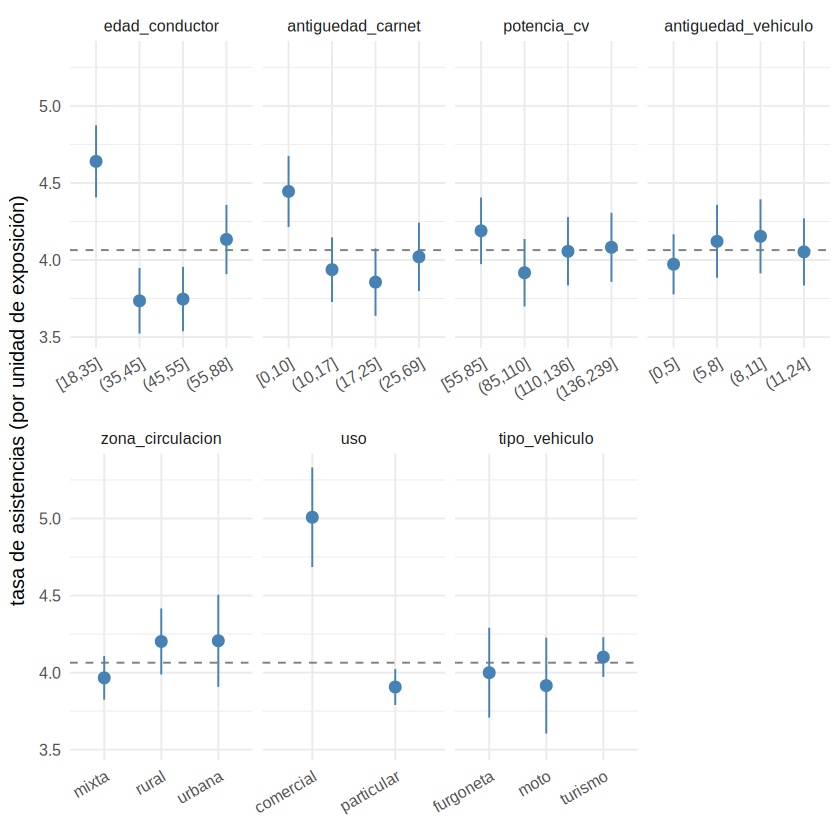

In [ ]:
tasa_por_nivel <- function(var, nivel) {
  tibble::tibble(nivel = nivel, y = cartera$n_asistencia, e = cartera$exposicion) |>
    dplyr::group_by(nivel) |>
    dplyr::summarise(tasa = sum(y) / sum(e), ee = sqrt(sum(y)) / sum(e), .groups = "drop") |>
    dplyr::mutate(predictor = var, nivel = as.character(nivel))
}
continuos   <- c("edad_conductor", "antiguedad_carnet", "potencia_cv", "antiguedad_vehiculo")
categoricos <- c("zona_circulacion", "uso", "tipo_vehiculo")
tasas_eda <- dplyr::bind_rows(
  # cut_number: cuartiles etiquetados con su rango, más legibles que "1, 2, 3, 4"
  purrr::map(continuos,   \(v) tasa_por_nivel(v, ggplot2::cut_number(cartera[[v]], 4))),
  purrr::map(categoricos, \(v) tasa_por_nivel(v, cartera[[v]]))) |>
  dplyr::mutate(nivel     = forcats::fct_inorder(nivel),
                predictor = factor(predictor, levels = c(continuos, categoricos)))
tasa_global <- sum(cartera$n_asistencia) / sum(cartera$exposicion)

ggplot(tasas_eda, aes(nivel, tasa)) +
  geom_hline(yintercept = tasa_global, linetype = "dashed", colour = "grey50") +
  geom_pointrange(aes(ymin = tasa - 1.96 * ee, ymax = tasa + 1.96 * ee), colour = "steelblue") +
  facet_wrap(~ predictor, scales = "free_x", nrow = 2) +
  labs(x = NULL, y = "tasa de asistencias (por unidad de exposición)") +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))

**Resultado:** al poner la tasa de asistencias en relación con el resto de variables se aprecian distintos tipos de relaciones.

#### Pregunta 1:

#### ¿Qué clientes dan más siniestros: depende del vehículo, de la zona o de las dos cosas? Si, por ejemplo, las motos circularan sobre todo por ciudad, ¿cuál de las dos pesaría de verdad?

**Qué hacemos:** cruzamos zona, tipo de vehículo y haber tenido siniestro en una tabla de tres vías (3 × 3 × 2 = 18 celdas). Antes de fiarnos de cualquier p-valor, comprobamos que ninguna celda está casi vacía.

In [ ]:
tab3 <- xtabs(~ zona_circulacion + tipo_vehiculo + siniestro, data = cart_tab)
d3 <- as.data.frame(tab3)
ftable(tab3)
length(tab3)
min(tab3)
sum(tab3 < 5)

                               siniestro sin con
zona_circulacion tipo_vehiculo                  
mixta            furgoneta               155  78
                 moto                    143  81
                 turismo                 947 404
rural            furgoneta                76  21
                 moto                     82  24
                 turismo                 479 147
urbana           furgoneta                37  34
                 moto                     23  25
                 turismo                 171 135

[1] 18

[1] 21

[1] 0

**Resultado:** la tabla tiene 18 celdas, la más pequeña cuenta con 21 pólizas y ninguna tiene menos de 5.

**Por tanto**, los p-valores que obtengamos son válidos: este tipo de contrastes puede distorsionarse si alguna casilla tiene muy pocos casos, pero  la celda más pequeña supera el mínimo de 5.

#### Los cinco modelos

Para responder planteamos cinco modelos, con distintos factores e interacciones que representan los eventos de interés:

- mutua: nada se asocia con nada, sencillamente afecta.

- conjunta: zona y tipo pueden estar relacionados, pero el siniestro no depende de ninguno

- condicional: zona y tipo se asocian con el siniestro, pero no entre sí

- homogénea: las tres parejas asociadas, cada asociación igual en todos los niveles del tercero: el modelo en el que se separa el peso de cada factor si las motos fueran sobre todo urbanas

- saturado: la asociación entre dos cambia según el tercero

Con estos 5 modelos queremos responder a:

1. ¿Se asocia cada factor (zona, tipo) con tener siniestro?
2. ¿Se asocian zona y tipo entre sí? (¿las motos, sobre todo en ciudad?)
3. ¿La diferencia entre zonas es la misma para todos los tipos?

**Qué hacemos:** ajustamos los cinco modelos sobre las frecuencias de la tabla.

In [ ]:
m_mutua <- glm(Freq ~ zona_circulacion + tipo_vehiculo + siniestro, family = poisson, data = d3)
m_conjunta <- glm(Freq ~ zona_circulacion * tipo_vehiculo + siniestro, family = poisson, data = d3)
m_condicional <- glm(Freq ~ zona_circulacion * siniestro + tipo_vehiculo * siniestro, family = poisson, data = d3)
m_homogenea <- glm(Freq ~ (zona_circulacion + tipo_vehiculo + siniestro)^2, family = poisson, data = d3)
m_saturado <- glm(Freq ~ zona_circulacion * tipo_vehiculo * siniestro, family = poisson, data = d3)

modelos <- list(mutua = m_mutua, conjunta = m_conjunta, condicional = m_condicional,homogenea = m_homogenea, saturado = m_saturado)

In [ ]:
summary(m_mutua)
summary(m_conjunta)
summary(m_condicional)
summary(m_homogenea)
summary(m_saturado)


Call:
glm(formula = Freq ~ zona_circulacion + tipo_vehiculo + siniestro, 
    family = poisson, data = d3)

Coefficients:
                       Estimate Std. Error z value Pr(>|z|)    
(Intercept)             5.09615    0.05354  95.177   <2e-16 ***
zona_circulacionrural  -0.77976    0.04194 -18.590   <2e-16 ***
zona_circulacionurbana -1.44789    0.05391 -26.859   <2e-16 ***
tipo_vehiculomoto      -0.05907    0.07169  -0.824     0.41    
tipo_vehiculoturismo    1.73928    0.05415  32.122   <2e-16 ***
siniestrocon           -0.80046    0.03908 -20.484   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 3684.160  on 17  degrees of freedom
Residual deviance:   76.826  on 12  degrees of freedom
AIC: 203.23

Number of Fisher Scoring iterations: 4



Call:
glm(formula = Freq ~ zona_circulacion * tipo_vehiculo + siniestro, 
    family = poisson, data = d3)

Coefficients:
                                            Estimate Std. Error z value
(Intercept)                                  5.08008    0.06662  76.252
zona_circulacionrural                       -0.87633    0.12084  -7.252
zona_circulacionurbana                      -1.18836    0.13556  -8.766
tipo_vehiculomoto                           -0.03939    0.09357  -0.421
tipo_vehiculoturismo                         1.75756    0.07094  24.776
siniestrocon                                -0.80046    0.03908 -20.484
zona_circulacionrural:tipo_vehiculomoto      0.12812    0.16882   0.759
zona_circulacionurbana:tipo_vehiculomoto    -0.35209    0.20898  -1.685
zona_circulacionrural:tipo_vehiculoturismo   0.10708    0.13015   0.823
zona_circulacionurbana:tipo_vehiculoturismo -0.29666    0.14961  -1.983
                                            Pr(>|z|)    
(Intercept)                 


Call:
glm(formula = Freq ~ zona_circulacion * siniestro + tipo_vehiculo * 
    siniestro, family = poisson, data = d3)

Coefficients:
                                    Estimate Std. Error z value Pr(>|z|)    
(Intercept)                          5.06201    0.06373  79.431  < 2e-16 ***
zona_circulacionrural               -0.67012    0.04871 -13.756  < 2e-16 ***
zona_circulacionurbana              -1.68447    0.07164 -23.513  < 2e-16 ***
siniestrocon                        -0.69379    0.11092  -6.255 3.97e-10 ***
tipo_vehiculomoto                   -0.07756    0.08811  -0.880    0.379    
tipo_vehiculoturismo                 1.78490    0.06601  27.039  < 2e-16 ***
zona_circulacionrural:siniestrocon  -0.40566    0.09673  -4.194 2.75e-05 ***
zona_circulacionurbana:siniestrocon  0.61905    0.10983   5.636 1.74e-08 ***
siniestrocon:tipo_vehiculomoto       0.05474    0.15157   0.361    0.718    
siniestrocon:tipo_vehiculoturismo   -0.14437    0.11547  -1.250    0.211    
---
Signif. codes:


Call:
glm(formula = Freq ~ (zona_circulacion + tipo_vehiculo + siniestro)^2, 
    family = poisson, data = d3)

Coefficients:
                                            Estimate Std. Error z value
(Intercept)                                  5.05721    0.07505  67.386
zona_circulacionrural                       -0.76141    0.12385  -6.148
zona_circulacionurbana                      -1.43402    0.14468  -9.911
tipo_vehiculomoto                           -0.07474    0.10697  -0.699
tipo_vehiculoturismo                         1.79081    0.08033  22.293
siniestrocon                                -0.72848    0.11247  -6.477
zona_circulacionrural:tipo_vehiculomoto      0.13692    0.16932   0.809
zona_circulacionurbana:tipo_vehiculomoto    -0.36764    0.21025  -1.749
zona_circulacionrural:tipo_vehiculoturismo   0.09858    0.13051   0.755
zona_circulacionurbana:tipo_vehiculoturismo -0.28128    0.15061  -1.868
zona_circulacionrural:siniestrocon          -0.40571    0.09680  -4.191
zona_circ


Call:
glm(formula = Freq ~ zona_circulacion * tipo_vehiculo * siniestro, 
    family = poisson, data = d3)

Coefficients:
                                                         Estimate Std. Error
(Intercept)                                               5.04343    0.08032
zona_circulacionrural                                    -0.71269    0.14003
zona_circulacionurbana                                   -1.43251    0.18297
tipo_vehiculomoto                                        -0.08058    0.11595
tipo_vehiculoturismo                                      1.80987    0.08665
siniestrocon                                             -0.68672    0.13882
zona_circulacionrural:tipo_vehiculomoto                   0.15657    0.19697
zona_circulacionurbana:tipo_vehiculomoto                 -0.39484    0.28974
zona_circulacionrural:tipo_vehiculoturismo                0.03109    0.15084
zona_circulacionurbana:tipo_vehiculoturismo              -0.27913    0.20095
zona_circulacionrural:siniestr

**Resultado:** los cinco modelos se ajustan sin problemas aparentes.

**Qué hacemos:** comparamos cada modelo con la tabla real: la deviance, sus grados de libertad y el p-valor de ajuste, junto con el AIC y la menor frecuencia esperada.

In [ ]:
for (n in names(modelos)) {
  m <- modelos[[n]]
  cat(n, " gl =", df.residual(m), " deviance =", deviance(m),
      " p_ajuste =", pchisq(deviance(m), df.residual(m), lower.tail = FALSE),
      " AIC =", AIC(m), " min esperada =", min(fitted(m)), "\n")
}

mutua  gl = 12  deviance = 76.82603  p_ajuste = 1.657266e-11  AIC = 203.2338  min esperada = 16.2606 
conjunta  gl = 8  deviance = 70.59207  p_ajuste = 3.745933e-12  AIC = 204.9999  min esperada = 14.87655 
condicional  gl = 8  deviance = 7.92515  p_ajuste = 0.4408157  AIC = 142.333  min esperada = 26.30137 
homogenea  gl = 4  deviance = 2.011669  p_ajuste = 0.7336125  AIC = 144.4195  min esperada = 23.60867 
saturado  gl = 0  deviance = -3.199663e-13  p_ajuste = 1  AIC = 150.4078  min esperada = 21 


**Resultado:** la mutua y la conjunta no ajustan. La condicional y la homogénea sí. La menor frecuencia esperada de todos es 14,9, bastante por encima de 5.

**Por tanto**, el siniestro sí depende: puede haber asociación de zona y tipo con el siniestro, que es lo que añade la condicional. Nos queda terminar de comprobar si la homogénea y la saturada aportan algo más.

**Qué hacemos:** comparamos modelos consecutivos con el contraste de razón de verosimilitudes (LRT). Cada contraste responde a si añadir la asociación zona–tipo mejora (pregunta 2) y si la asociación cambia según el tercer factor (pregunta 3).

In [ ]:
anova(m_condicional, m_homogenea, test = "LRT") # pregunta 2
anova(m_homogenea, m_saturado, test = "LRT") # pregunta 3

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,8,7.925150,NA,NA,NA
2,4,2.011669,4,5.913481,0.2057034


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,4,2.011669e+00,NA,NA,NA
2,0,-3.199663e-13,4,2.011669,0.7336125


**Resultado:** zona–tipo no mejora el modelo (p = 0,21) y la interacción de tres vías tampoco (p = 0,73).

**Por tanto**, zona y tipo no están relacionados entre sí, y el efecto de la zona es el mismo para todos los tipos. Nos quedamos con la condicional. Queda comprobar si de verdad necesita todos sus términos (pregunta 1).

**Qué hacemos:** quitamos de uno en uno los términos de la condicional y vemos si el modelo empeora.

In [ ]:
# pregunta 1
drop1(m_condicional, test = "LRT")

,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,7.92515,142.3330,NA,NA
zona_circulacion:siniestro,2,72.98920,203.3970,65.064047,7.439122e-15
siniestro:tipo_vehiculo,2,11.76199,142.1698,3.836835,1.468391e-01


**Resultado:** quitar zona–siniestro empeora mucho el modelo (p ≈ 7·10⁻¹⁵). Quitar tipo–siniestro no podemos afirmar firmemente que lo empeore (p = 0,15).

**Por tanto**, la zona se asocia claramente con tener siniestro, mientras que el tipo de vehículo no muestra asociación significativa. Podamos el término tipo–siniestro.

**Qué hacemos:** ajustamos el modelo podado y comprobamos que no pierde nada respecto a la condicional: contraste entre ambos, ajuste, AIC, BIC y 'drop1' del modelo final.

In [ ]:
# Podamos
m_final <- glm(Freq ~ zona_circulacion * siniestro + tipo_vehiculo, family = poisson, data = d3)
anova(m_final, m_condicional, test = "LRT")
deviance(m_final)
df.residual(m_final)
pchisq(deviance(m_final), df.residual(m_final), lower.tail = FALSE)
AIC(m_final); AIC(m_condicional)
BIC(m_final); BIC(m_condicional)
min(fitted(m_final))
drop1(m_final, test = "LRT")

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,10,11.76199,NA,NA,NA
2,8,7.92515,2,3.836835,0.1468391


[1] 11.76199

[1] 10

[1] 0.3013018

[1] 142.1698

[1] 142.333

[1] 149.2928

[1] 151.2367

[1] 23.70216

,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,11.76199,142.1698,NA,NA
tipo_vehiculo,2,2187.33276,2313.7406,2175.57077,0.000000e+00
zona_circulacion:siniestro,2,76.82603,203.2338,65.06405,7.439122e-15


**Resultado:** la poda no empeora el modelo, el modelo final ajusta bien (p = 0,30), tiene menor AIC (142,17 frente a 142,33) y menor BIC (149,3 frente a 151,2). En el 'drop1' final, la zona es imprescindible (p ≈ 7·10⁻¹⁵).

**Por tanto**, en el modelo final solo la zona se asocia con tener siniestro (el tipo de vehículo entra únicamente como efecto marginal sin relación con los partes).

**Qué hacemos:** miramos los residuos ajustados del modelo final. Un residuo con valor absoluto por encima de 2 sería una celda que el modelo no explica bien.

In [ ]:
# Vemos si el modelo ajusta bien
d3$esperado <- fitted(m_final)
d3$r_aj <- rstandard(m_final, type = "pearson")
d3[order(-abs(d3$r_aj)), ]

,zona_circulacion,tipo_vehiculo,siniestro,Freq,esperado,r_aj
,<fct>,<fct>,<fct>,<int>,<dbl>,<dbl>
12,urbana,furgoneta,con,34,25.40627,1.88975021
16,mixta,turismo,con,404,419.76780,-1.68896185
18,urbana,turismo,con,135,144.64468,-1.64279484
13,mixta,moto,con,81,69.50163,1.63068271
7,mixta,turismo,sin,947,928.26094,1.58296657
3,urbana,furgoneta,sin,37,30.25180,1.36875406
4,mixta,moto,sin,143,153.69366,-1.19601060
6,urbana,moto,sin,23,28.51666,-1.14754727
2,rural,furgoneta,sin,76,83.42162,-0.97945903


**Resultado:** el mayor es 1,89 (urbana, furgoneta, con siniestro) y ninguno llega a 2.

**Por tanto**, el modelo final no deja ninguna celda mal explicada.

**Qué hacemos:** lo vemos también en mosaicos.

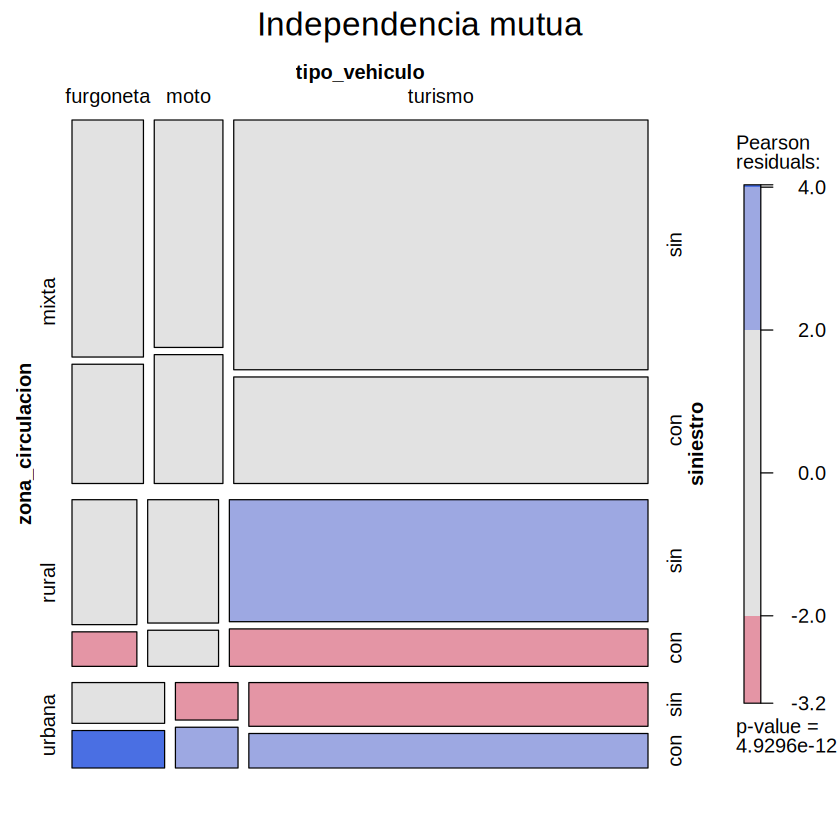

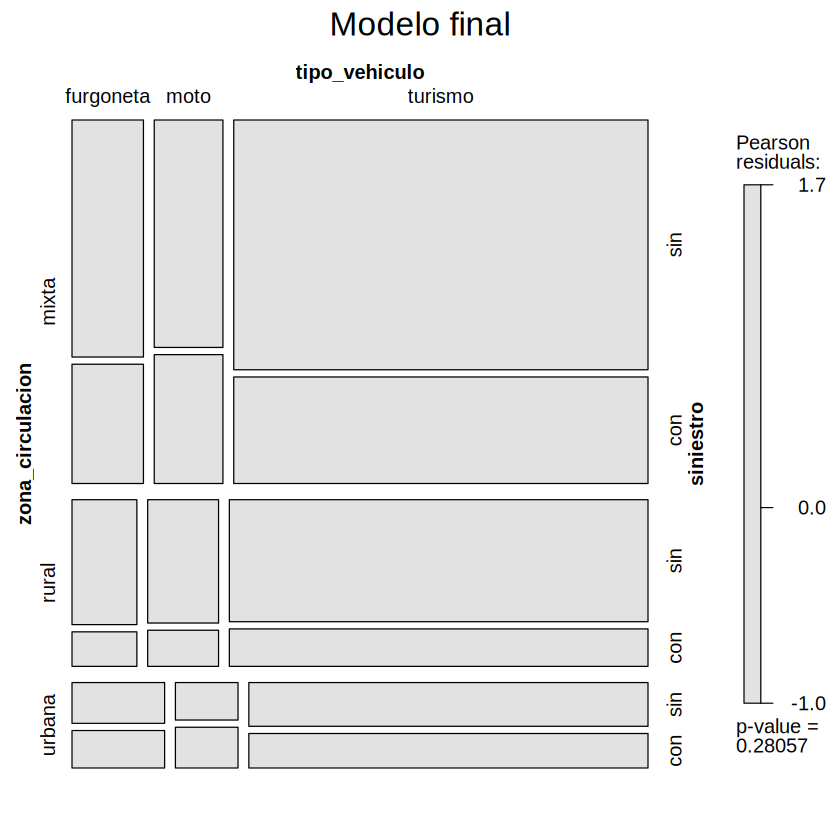

In [ ]:
cargar_paquetes(c("vcd"))

mosaic(tab3, shade = TRUE, legend = TRUE, main = "Independencia mutua")
mosaic(tab3, shade = TRUE, legend = TRUE,
       expected = ~ zona_circulacion * siniestro + tipo_vehiculo,
       main = "Modelo final")

**Resultado:** respecto a la independencia mutua, 8 de las 18 celdas tienen un residuo mayor que 2; con el modelo final no queda ninguna.

**Qué hacemos**: resumimos el modelo final en una gráfica. Para cada zona y tipo de vehículo dibujamos el porcentaje de pólizas con siniestro que se observa (con su intervalo al 95 %) y, en negro, el que predice el modelo final.

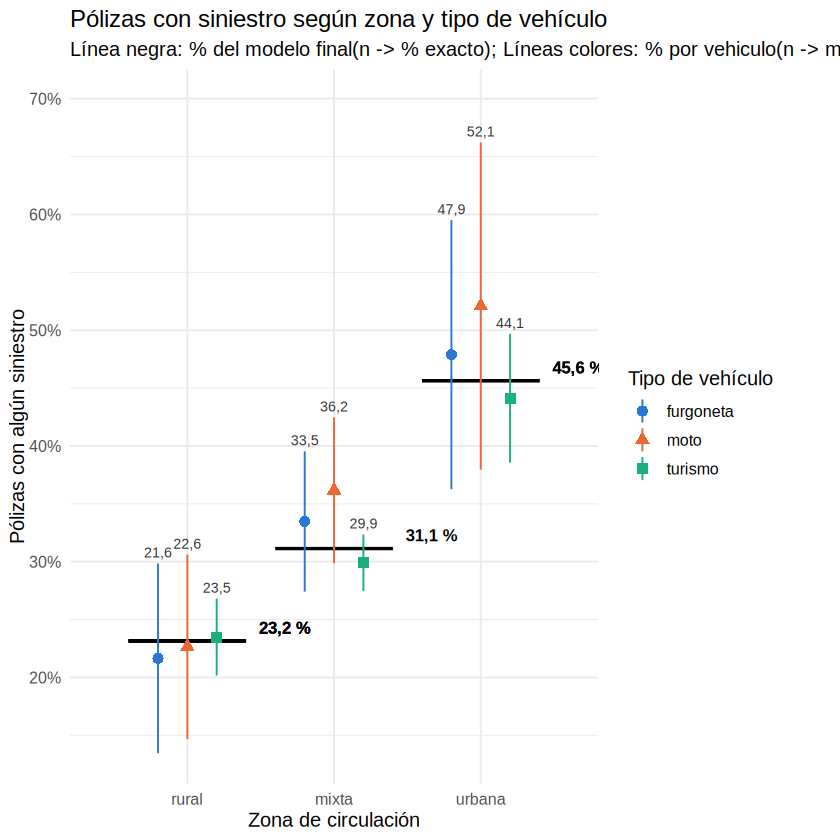

In [ ]:
graf <- d3 |>
  tidyr::pivot_wider(id_cols = c(zona_circulacion, tipo_vehiculo),
                     names_from = siniestro, values_from = c(Freq, esperado)) |>
  dplyr::mutate(n    = Freq_sin + Freq_con,
                obs  = Freq_con / n,
                ee   = sqrt(obs * (1 - obs) / n),
                modelo = esperado_con / (esperado_sin + esperado_con),
                zona_circulacion = factor(zona_circulacion, levels = c("rural", "mixta", "urbana")))
graf_modelo <- dplyr::distinct(graf, zona_circulacion, modelo)
pct   <- scales::label_percent(accuracy = 0.1, decimal.mark = ",", suffix = " %")
pct_n <- scales::label_number(accuracy = 0.1, decimal.mark = ",", scale = 100)   # sin el símbolo %

ggplot(graf, aes(zona_circulacion, obs, colour = tipo_vehiculo, shape = tipo_vehiculo)) +
  geom_errorbar(aes(x = zona_circulacion, ymin = modelo, ymax = modelo), colour = "black",
                width = 0.8, linewidth = 0.9, inherit.aes = FALSE, data = graf_modelo) +
  geom_text(aes(x = zona_circulacion, y = modelo, label = pct(modelo)), colour = "black",
            fontface = "bold", size = 3.5, hjust = -0.25, vjust = -0.6,
            nudge_x = 0.4, inherit.aes = FALSE, data = graf_modelo) +
  geom_pointrange(aes(ymin = obs - 1.96 * ee, ymax = obs + 1.96 * ee),
                  position = position_dodge(width = 0.6), size = 0.6) +
  geom_text(aes(y = obs + 1.96 * ee, label = pct_n(obs)), colour = "grey20", size = 3,
            vjust = -0.6, position = position_dodge(width = 0.6)) +
  scale_colour_manual(values = c(furgoneta = "#2a78d6", moto = "#eb6834", turismo = "#1baf7a")) +
  scale_x_discrete(expand = expansion(add = 0.8)) +
  scale_y_continuous(labels = scales::percent_format(accuracy = 1),
                     expand = expansion(mult = c(0.05, 0.12))) +
  labs(title    = "Pólizas con siniestro según zona y tipo de vehículo",
       subtitle = "Línea negra: % del modelo final(n -> % exacto); Líneas colores: % por vehiculo(n -> media)",
       x = "Zona de circulación", y = "Pólizas con algún siniestro",
       colour = "Tipo de vehículo", shape = "Tipo de vehículo")

**Resultado:** el modelo predice un 23,3 % de pólizas con siniestro en rural, un 31,1 % en mixta y un 45,6 % en urbana, igual para los tres tipos. Los nueve intervalos observados contienen la línea de su zona; los más anchos son los de moto y los de urbana, porque tienen pocas pólizas.

Por tanto, la gráfica muestra lo mismo que los números: la zona separa los tres grupos con claridad y, dentro de cada zona, los tres tipos de vehículo se parecen entre sí.

**Qué hacemos:** estudiamos los odds ratio para medir cuánto pesa la zona, siendo la zona de referencia mixta.

In [ ]:
exp(cbind(coef(m_final), confint.default(m_final)))
exp(cbind(coef(m_condicional), confint.default(m_condicional)))

,,2.5 %,97.5 %
(Intercept),163.0453952,146.5267528,181.4262610
zona_circulacionrural,0.5116466,0.4650552,0.5629057
zona_circulacionurbana,0.1855422,0.1612364,0.2135120
siniestrocon,0.4522088,0.4093627,0.4995394
tipo_vehiculomoto,0.9426434,0.8190792,1.0848481
tipo_vehiculoturismo,5.6932668,5.1200289,6.3306845
zona_circulacionrural:siniestrocon,0.6665347,0.5514194,0.8056817
zona_circulacionurbana:siniestrocon,1.8571659,1.4974819,2.3032433


,,2.5 %,97.5 %
(Intercept),157.9081874,139.3667032,178.9164490
zona_circulacionrural,0.5116466,0.4650552,0.5629057
zona_circulacionurbana,0.1855422,0.1612364,0.2135120
siniestrocon,0.4996768,0.4020468,0.6210146
tipo_vehiculomoto,0.9253731,0.7786036,1.0998092
tipo_vehiculoturismo,5.9589552,5.2357757,6.7820222
zona_circulacionrural:siniestrocon,0.6665347,0.5514194,0.8056817
zona_circulacionurbana:siniestrocon,1.8571659,1.4974819,2.3032433
siniestrocon:tipo_vehiculomoto,1.0562697,0.7847923,1.4216573
siniestrocon:tipo_vehiculoturismo,0.8655703,0.6902580,1.0854086


**Resultado:** respecto a la zona mixta, en rural los odds de tener siniestro son 0,67 veces los de mixta, y en urbana son 1,86 veces. En la condicional, los OR obtenemos que moto 1,06 y turismo 0,87, pero con intervalos que contienen el 1.

**Por tanto**, la zona sí pesa y el tipo no lo ha demostrado. Falta comprobar si podemos resumir la zona con una tabla de dos vías, sin la de tres.

**Qué hacemos:** comparamos el OR de zona calculado con la tabla de zona y siniestro sola (marginal) con el que da el modelo de tres vías (condicional).

In [ ]:
tab_zona <- xtabs(~ zona_circulacion + siniestro, data = cart_tab)
tab_tipo <- xtabs(~ tipo_vehiculo + siniestro, data = cart_tab)
round(100 * prop.table(tab_zona, margin = 1), 1)
round(100 * prop.table(tab_tipo, margin = 1), 1)

m_sat_zona <- glm(Freq ~ zona_circulacion * siniestro, family = poisson, data = as.data.frame(tab_zona))
exp(coef(m_sat_zona)) # marginal (dos vías)
exp(coef(m_final)) # condicional (tres vías)

                siniestro
zona_circulacion  sin  con
          mixta  68.9 31.1
          rural  76.8 23.2
          urbana 54.4 45.6

             siniestro
tipo_vehiculo  sin  con
    furgoneta 66.8 33.2
    moto      65.6 34.4
    turismo   70.0 30.0

(Intercept)               zona_circulacionrural 
                       1245.0000000                           0.5116466 
             zona_circulacionurbana                        siniestrocon 
                          0.1855422                           0.4522088 
 zona_circulacionrural:siniestrocon zona_circulacionurbana:siniestrocon 
                          0.6665347                           1.8571659

(Intercept)               zona_circulacionrural 
                        163.0453952                           0.5116466 
             zona_circulacionurbana                        siniestrocon 
                          0.1855422                           0.4522088 
                  tipo_vehiculomoto                tipo_vehiculoturismo 
                          0.9426434                           5.6932668 
 zona_circulacionrural:siniestrocon zona_circulacionurbana:siniestrocon 
                          0.6665347                           1.8571659

**Resultado:** el porcentaje de pólizas con siniestro es 23,2 % en rural, 31,1 % en mixta y 45,6 % en urbana; por tipo, 33,2 % en furgoneta, 34,4 % en moto y 30,0 % en turismo. Los OR de zona coinciden exactamente en los dos modelos (0,667 en rural y 1,857 en urbana).

**Por tanto**, como no hay interacción triple (p = 0,73) ni relación entre zona y vehículo (p = 0,21), al agrupar los vehículos no se pierde información ni se distorsionan los resultados.

**Qué hacemos:** ajustamos un modelo logit (tuvo_siniestro ~ zona_circulacion), que permite estimar y visualizar directamente la probabilidad de siniestro en cada zona.

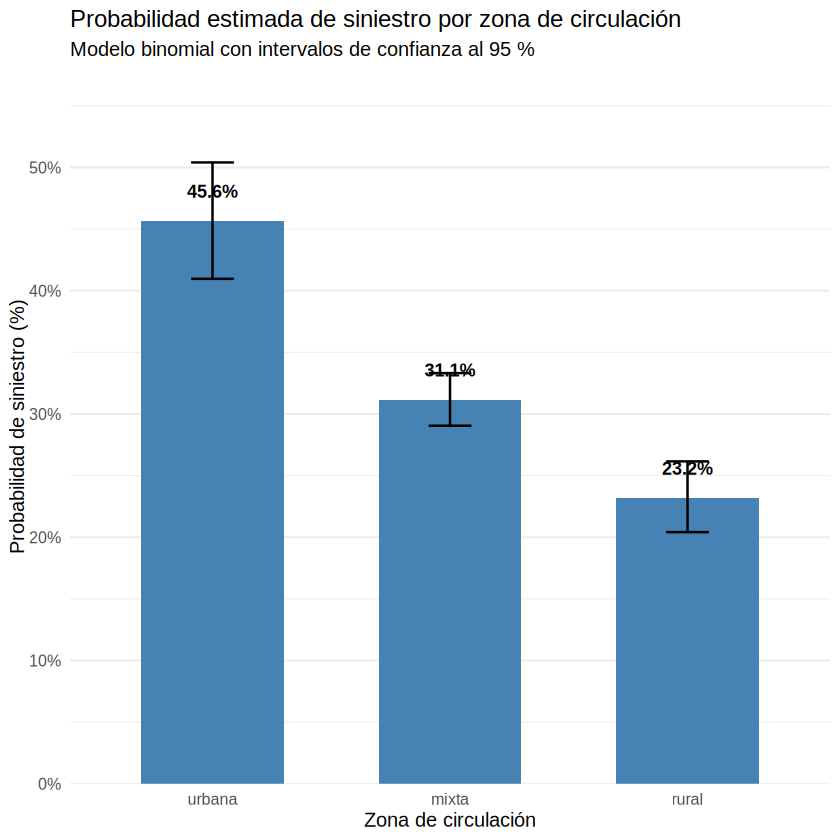

In [ ]:
m_zonas <- glm(tuvo_siniestro ~ zona_circulacion, family = binomial, data = cart_tab)

pred_zonas <- data.frame(
  zona_circulacion = sort(unique(cart_tab$zona_circulacion))
)

enlace <- predict(m_zonas, newdata = pred_zonas, type = "link", se.fit = TRUE)
pred_zonas$prob <- plogis(enlace$fit)
pred_zonas$ic_low  <- plogis(enlace$fit - 1.96 * enlace$se.fit)
pred_zonas$ic_high <- plogis(enlace$fit + 1.96 * enlace$se.fit)

ggplot(pred_zonas, aes(x = reorder(zona_circulacion, -prob), y = prob)) +
  geom_col(fill = "steelblue", width = 0.6) +
  geom_errorbar(aes(ymin = ic_low, ymax = ic_high), width = 0.18, linewidth = 0.7) +
  geom_text(aes(label = scales::percent(prob, accuracy = 0.1)),
            vjust = -1.8, size = 3.8, fontface = "bold") +
  scale_y_continuous(labels = scales::percent_format(accuracy = 1),
                     expand = expansion(mult = c(0, 0.15))) +
  labs(
    title    = "Probabilidad estimada de siniestro por zona de circulación",
    subtitle = "Modelo binomial con intervalos de confianza al 95 %",
    x        = "Zona de circulación",
    y        = "Probabilidad de siniestro (%)"
  ) +
  theme_minimal(base_size = 12) +
  theme(panel.grid.major.x = element_blank())

**Resultado:** las probabilidades estimadas son 23 % en rural, 31 % en mixta y 46 % en urbana, con sus intervalos de confianza.

#### Conclusiones:

1.  La zona sí influye. La asociación zona–siniestro es muy clara (p ≈ 7·10⁻¹⁵). La proporción de pólizas con algún parte es del 46 % en zona urbana, del 31 % en mixta y del 23 % en rural.
2.  El tipo de vehículo no se ha podido demostrar. Turismo, moto y furgoneta tienen un 30 %, 34 % y 33 %, y la asociación tipo–siniestro no es significativa (p = 0,15), por lo que el modelo final la poda. Aunque no se prueba que no influya: el efecto existe pero es pequeño, no merece la pena. Zona y tipo no se relacionan entre sí (p = 0,21).
3.  Las motos no se concentran en ciudad, así que la diferencia entre zonas no es un efecto disfrazado del efecto del vehículo.
4.  El efecto de la zona es el mismo para todos los tipos (interacción de tres vías, p = 0,73).

#### Validación contra el DGP

Comprobamos nuestras conclusiones contra los parametros originales.

In [ ]:
cargar_paquetes(c("broom"))

verdad <- attr(cartera_rds, "verdad")

# Predictor lineal verdadero, construido como en R/dgp_auto.R:
# continuas estandarizadas (km y densidad en logaritmo); sin referencias, son indicadores
X <- with(cartera, cbind(
  edad_2535   = edad_tramo == "25-35", edad_3565 = edad_tramo == "35-65", edad_65 = edad_tramo == "65+",
  z_carnet    = as.numeric(scale(antiguedad_carnet)), z_pot = as.numeric(scale(potencia_cv)),
  z_antv      = as.numeric(scale(antiguedad_vehiculo)),
  z_km        = as.numeric(scale(log(km_anuales))), z_dens = as.numeric(scale(log(densidad))),
  uso_com     = uso == "comercial", tipo_moto = tipo_vehiculo == "moto", tipo_furgo = tipo_vehiculo == "furgoneta",
  comb_diesel = combustible == "diesel", sexo_h = sexo == "H"))
eta <- drop(X[, names(verdad$betas$claim)] %*% verdad$betas$claim)

# P(al menos un parte): Poisson de media exp(eta) * lambda0 * t^k con fragilidad Gamma(theta, theta)
Lam_c <- exp(eta) * verdad$lambda0 * cartera$antiguedad^verdad$weib_shape
p_con <- 1 - (1 + Lam_c / verdad$theta_frail)^(-verdad$theta_frail)

# Calibración: pólizas con parte esperadas según el DGP frente a observadas
c(esperadas_DGP = sum(p_con), observadas = sum(cart_tab$tuvo_siniestro))

# Tabla esperada según el DGP (frecuencias no enteras) y el mismo modelo ajustado sobre ella
d3_dgp <- dplyr::bind_rows(dplyr::mutate(cart_tab, siniestro = "con", Freq = p_con),
                           dplyr::mutate(cart_tab, siniestro = "sin", Freq = 1 - p_con)) |>
  dplyr::mutate(siniestro = factor(siniestro, levels = c("sin", "con"))) |>
  dplyr::count(zona_circulacion, tipo_vehiculo, siniestro, wt = Freq, name = "Freq")
m_dgp <- glm(formula(m_condicional), family = quasipoisson, data = d3_dgp)

# Odds ratios verdaderos frente a los estimados (modelo condicional, que es la estructura del DGP)
broom::tidy(m_condicional, exponentiate = TRUE, conf.int = TRUE) |>
  dplyr::filter(grepl(":", term)) |>
  dplyr::transmute(term, OR_DGP = exp(coef(m_dgp))[term], OR_estimado = estimate, conf.low, conf.high,
                   dentro_IC = OR_DGP >= conf.low & OR_DGP <= conf.high) |>
  dplyr::mutate(dplyr::across(where(is.numeric), ~ round(.x, 3)))

esperadas_DGP    observadas 
     930.5351      949.0000

term,OR_DGP,OR_estimado,conf.low,conf.high,dentro_IC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
zona_circulacionrural:siniestrocon,0.622,0.667,0.551,0.805,TRUE
zona_circulacionurbana:siniestrocon,1.628,1.857,1.497,2.303,TRUE
siniestrocon:tipo_vehiculomoto,0.978,1.056,0.785,1.422,TRUE
siniestrocon:tipo_vehiculoturismo,0.815,0.866,0.692,1.088,TRUE


**Resultado:** el modelo calibra bien (se esperan 930,5 pólizas con parte según el DGP y se observan 949), y los cuatro odds ratio verdaderos caen dentro del intervalo de lo estimado.

**Por tanto**, la zona está bien recogida. El DGP sí incluye un efecto del tipo de vehículo, pero pequeño: por eso no lo detectamos con 3.062 pólizas. Por eso lo más estadñisticamente correcto es decir que no es demostrable con estos datos, no que no influye.

### P4 · Transiciones de bonus-malus

[Fuente del equipo · P4.qmd](https://github.com/GLM-2026/proy2-07-Cox/blob/92f8dd5847e03b0de7ca027ef63b269f4b4387a3/Analisis/P4.qmd)

In [ ]:
set.seed(SEMILLA_CURSO)
cartera <- cartera_original

#### Pregunta 4:

#### Si nuestros clientes se mueven entre niveles como lo hicieron el año pasado, ¿cómo quedarán repartidos el año que viene? ¿La cartera está **mejorando o empeorando**? Contamos además con **crecer un 10 %**, y los clientes nuevos entran en el **nivel 3**. Necesitamos cuántos clientes habrá en cada nivel, y con qué margen podemos contar para presupuestar.

#### La tabla de cambio

**Qué hacemos:** cruzamos el nivel de bonus-malus del año anterior 'prev' con el del año actual 'act', y le añadimos columnas auxiliares para los modelos que vendrán: el nivel como número 'i,j', la pareja de niveles sin orden 'par', si la póliza se queda en su nivel 'diagonal' y si sube o baja exactamente un nivel 'sube1','baja1'. Es decir, vamos preparando las posibles variables a usar (hecho retrospectivamente).

In [ ]:
cuad <- as.data.frame(xtabs(~ bonus_malus_prev + bonus_malus_act, data = cartera)) |>
  dplyr::rename(prev = bonus_malus_prev, act = bonus_malus_act) |>
  dplyr::mutate(i = as.integer(prev), j = as.integer(act),
                par      = factor(paste(pmin(i, j), pmax(i, j), sep = "-")),
                diagonal = factor(ifelse(i == j, "queda", "mueve")),
                sube1    = as.integer(j == i + 1),
                baja1    = as.integer(j == i - 1))
xtabs(Freq ~ prev + act, data = cuad) |> addmargins()

,1,2,3,4,5,Sum
1,1203,51,3,1,0,1258
2,281,390,40,1,0,712
3,0,173,286,34,2,495
4,0,0,136,189,29,354
5,0,0,0,84,159,243
Sum,1484,614,465,309,190,3062


**Resultado:** una tabla de 5 × 5 con 3.062 pólizas, con la mayor parte de los clientes en la diagonal (los que se quedan en su nivel) y sin apenas saltos de dos o más niveles.

**Qué hacemos:** miramos adónde van los clientes de cada nivel (porcentaje de cada fila) y el flujo neto entre cada pareja de niveles: cuántos suben menos cuántos bajan (positivo, hacia el malus; negativo, hacia el bonus).

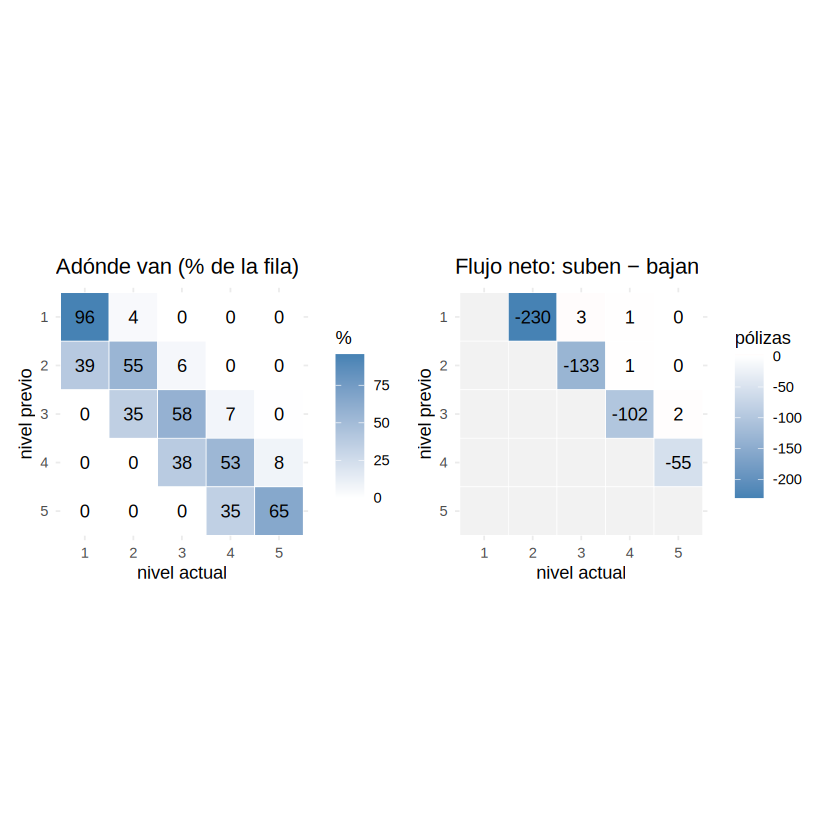

In [ ]:
cargar_paquetes(c("patchwork"))

N <- xtabs(Freq ~ prev + act, data = cuad)
pct_fila <- as.data.frame(as.table(100 * prop.table(N, 1)))
neto <- as.data.frame(as.table(N - t(N))) |>
  dplyr::mutate(Freq = ifelse(as.integer(prev) < as.integer(act), Freq, NA))
mapa <- function(d, relleno, titulo, etiqueta) {
  ggplot(d, aes(act, prev, fill = Freq)) +
    geom_tile(colour = "white") +
    geom_text(aes(label = round(Freq)), na.rm = TRUE) +
    relleno +
    scale_y_discrete(limits = rev) +
    coord_equal() +
    labs(title = titulo, x = "nivel actual", y = "nivel previo", fill = etiqueta) +
    theme_minimal()
}
patchwork::wrap_plots(
  mapa(pct_fila, scale_fill_gradient(low = "white", high = "steelblue"),
       "Adónde van (% de la fila)", "%"),
  mapa(neto, scale_fill_gradient2(low = "steelblue", mid = "white", high = "firebrick",
                                   na.value = "grey95"),
       "Flujo neto: suben − bajan", "pólizas"))

**Resultado:** el 96 % de los del nivel 1 se queda donde está, y de los niveles 2 a 5 entre el 35 % y el 40 % baja un nivel; subir un nivel es mucho menos frecuente. El flujo neto entre niveles vecinos va (casi) siempre hacia el bonus, ya que no hay apenas valores positivos (solo los hay de saltos de mas de un nivel).

**Por tanto**, el movimiento es practicamente de un nivel cada vez y con sentido: hacia mejor tarifa. Veamos si eso cambia el reparto de clientes entre niveles.

**Qué hacemos:** comparamos el reparto de clientes por nivel el año anterior y este año.

In [ ]:
pct_prev <- 100 * prop.table(table(cartera$bonus_malus_prev))
pct_act  <- 100 * prop.table(table(cartera$bonus_malus_act))
rbind(previo = pct_prev, actual = pct_act, cambio = pct_act - pct_prev) |>
  round(1) |>
  as.data.frame.matrix() |>
  tibble::rownames_to_column("año")

año,1,2,3,4,5
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
previo,41.1,23.3,16.2,11.6,7.9
actual,48.5,20.1,15.2,10.1,6.2
cambio,7.4,-3.2,-1.0,-1.5,-1.7


**Resultado:** el nivel 1 pasa del 41,1 % al 48,5 %, y los otros cuatro pierden peso (−3,2, −1,0, −1,5 y −1,7 puntos).

**Por tanto**, parece que la cartera se desplaza hacia el nivel 1. Lo contrastamos con modelos.

#### ¿Está equilibrado el trasiego? ¿Ha cambiado el reparto?

Contrastamos el trasiego y el reparto usando tres modelos:

- simetría: entre dos niveles cualesquiera pasan los mismos clientes en un sentido como en el otro
- cuasi-simetría: el reparto de niveles puede cambiar, pero el intercambio entre pares sigue siendo igual.
- homogeneidad marginal: el reparto de niveles es el mismo los dos años

**Qué hacemos:** ajustamos la simetría y la cuasi-simetría y comparamos las dos con un LRT; esa comparación es el contraste de homogeneidad marginal (no es un modelo en sí).

> **Nota de integración de Julio.** Primero se ajusta el modelo de Luis. Si el cálculo no converge o se detiene por un problema numérico, la celda avisa y vuelve a intentarlo con las frecuencias estimadas por el modelo de simetría como punto de partida. Ambos ajustes usan los mismos datos y la misma fórmula. Al comprobarlos con la cartera de Cox07, los dos dieron la misma devianza (42,67) y el mismo AIC (177,87). Esto arregla un problema de compativilidad entre kernels de R de los sistemas operativos, que surgió al comprobar los análisis.

In [ ]:
ajuste <- function(m) c(deviance = round(deviance(m), 2), gl = df.residual(m),
                        p_ajuste = signif(pchisq(deviance(m), df.residual(m), lower.tail = FALSE), 3),
                        AIC = round(AIC(m), 1),
                        min_esperada = round(min(fitted(m)), 2), esperadas_menor_5 = sum(fitted(m) < 5))

m_sim <- glm(Freq ~ par, family = poisson, data = cuad)
#-- Nota de integración de Julio: el reintento se define en Preparación.
intento_qs <- try({
    m_qs  <- glm(Freq ~ prev + act + par, family = poisson, data = cuad)
    }, silent = TRUE)
m_qs <- completar_cuasisimetria(intento_qs, m_sim, cuad)
rbind(simetria = ajuste(m_sim), cuasi_simetria = ajuste(m_qs))
anova(m_sim, m_qs, test = "LRT")   # H0: homogeneidad marginal (dada la cuasi-simetría)


,deviance,gl,p_ajuste,AIC,min_esperada,esperadas_menor_5
simetria,368.14,10,5.60e-73,495.3,0,12
cuasi_simetria,42.67,6,1.35e-07,177.9,0,12


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,10,368.14041,NA,NA,NA
2,6,42.67307,4,325.4673,3.465809e-69


**Resultado:** la simetría no ajusta (deviance 368 con 10 gl, p ≈ 10⁻⁷³) y la cuasi-simetría tampoco (deviance 42,7 con 6 gl, p ≈ 10⁻⁷). La homogeneidad marginal se rechaza por útlimo.

**Por tanto**, el reparto de niveles ha cambiado de un año a otro, y además queda un flujo con sentido propio que ni siquiera la cuasi-simetría explica. Falta medir cuánto cambia y en qué sentido.

**Qué hacemos:** calculamos el nivel medio de la cartera y el porcentaje de clientes que mejora y empeora, sobre los clientes y no sobre la tabla.

In [ ]:
niv <- as.integer(cartera$bonus_malus_prev); nva <- as.integer(cartera$bonus_malus_act)
c(nivel_medio_previo = round(mean(niv), 3),
  nivel_medio_actual = round(mean(nva), 3),
  deriva             = round(mean(nva - niv), 3),
  pct_empeora        = round(100 * mean(nva > niv), 1),
  pct_mejora         = round(100 * mean(nva < niv), 1))

nivel_medio_previo nivel_medio_actual             deriva        pct_empeora 
             2.220              2.055             -0.165              5.300 
        pct_mejora 
            22.000

**Resultado:** el nivel medio baja de 2,220 a 2,055. Mejora el 22,0 % de los clientes y empeora el 5,3 %.

**Por tanto**, la cartera está mejorando, se desplaza hacia el bonus.

#### Un modelo para proyectar

Para proyectar el año que viene necesitamos un modelo que ajuste y aproveche el orden de los niveles.

**Qué hacemos:** volvemos a mirar la ocupación de las celdas, porque en la tabla había muchas casi vacías.

In [ ]:
N <- xtabs(Freq ~ prev + act, data = cuad)
c(celdas = length(N), minimo = min(N), menores_de_5 = sum(N < 5), vacias = sum(N == 0))
N

celdas       minimo menores_de_5       vacias 
          25            0           12            8

    act
prev    1    2    3    4    5
   1 1203   51    3    1    0
   2  281  390   40    1    0
   3    0  173  286   34    2
   4    0    0  136  189   29
   5    0    0    0   84  159

**Resultado:** de las 25 celdas, 12 tienen menos de 5 clientes y 8 están vacías. Las seis de bajar dos o más niveles tienen cero clientes. Bajar un nivel es el movimiento más frecuente.

**Por tanto**, esos seis ceros podrían no ser azar sino combinaciones que no pueden ocurrir (ceros estructurales). Las excluimos del ajuste de los modelos que siguen; ajustamos con las 19 celdas restantes.

In [ ]:
cuad$imposible <- cuad$j <= cuad$i - 2
cuad_ok <- dplyr::filter(cuad, !imposible)
sum(cuad$Freq[cuad$imposible])
nrow(cuad_ok)

[1] 0

[1] 19

**Resultado:** las celdas excluidas suman 0 clientes (porque eran celdad de 0 basciamente) y quedan 19 celdas.

Modelos de asociación ordinal:

- independencia: el nivel actual no depende del previo.
- asociación uniforme: a la independencia le añade un único término, el producto de los niveles.

**Qué hacemos:** ajustamos la independencia y la asociación uniforme, las comparamos con un LRT y comprobamos si la uniforme ajusta.

In [ ]:
m_indep_c <- glm(Freq ~ prev + act,            family = poisson, data = cuad_ok)
m_unif    <- glm(Freq ~ prev + act + I(i * j), family = poisson, data = cuad_ok)
anova(m_indep_c, m_unif, test = "LRT")
c(beta_asociacion = round(coef(m_unif)["I(i * j)"], 4),
  OR_local        = round(exp(coef(m_unif)["I(i * j)"]), 3))
c(ajuste(m_unif), chi2_q95 = round(qchisq(0.95, df.residual(m_unif)), 1))

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,10,1541.39477,NA,NA,NA
2,9,51.17223,1,1490.223,0


beta_asociacion.I(i * j)        OR_local.I(i * j) 
                  2.8174                  16.7330

deviance                gl          p_ajuste               AIC 
        5.117e+01         9.000e+00         6.480e-08         1.684e+02 
     min_esperada esperadas_menor_5          chi2_q95 
        0.000e+00         6.000e+00         1.690e+01

**Resultado:** el término de asociación mejora muchísimo la independencia, con un odds ratio local de 16,7. Pero no ajusta: deviance 51,2 con y p = 6,5·10⁻⁸.

**Por tanto**, explicar con independencia no basta: el modelo sigue sin ajustar. La asociación uniforme no recoge que la mayoría de los clientes se queda en su nivel. Añadimos la inercia, que es común a las celdas de la diagonal.

**Qué hacemos:** añadimos el indicador 'diagonal' y comparamos con la asociación uniforme.

In [ ]:
m_mov <- glm(Freq ~ prev + act + I(i * j) + diagonal, family = poisson, data = cuad_ok)
anova(m_unif, m_mov, test = "LRT")
c(ajuste(m_mov),
  chi2_q95      = round(qchisq(0.95, df.residual(m_mov)), 1),
  pct_eliminada = round(100 * (1 - deviance(m_mov) / deviance(m_indep_c)), 1),
  pct_se_quedan = round(100 * sum(cuad$Freq[cuad$i == cuad$j]) / sum(cuad$Freq), 1))
broom::tidy(m_mov, exponentiate = TRUE, conf.int = TRUE) |>
  dplyr::filter(term %in% c("I(i * j)", "diagonalqueda")) |>
  dplyr::select(term, estimate, conf.low, conf.high, p.value) |>
  dplyr::mutate(dplyr::across(c(estimate, conf.low, conf.high), ~ round(.x, 3))) |>
  as.data.frame()

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,9,51.17223,NA,NA,NA
2,8,24.93614,1,26.23609,3.021232e-07


deviance                gl          p_ajuste               AIC 
         24.94000           8.00000           0.00159         144.10000 
     min_esperada esperadas_menor_5          chi2_q95     pct_eliminada 
          0.00000           6.00000          15.50000          98.40000 
    pct_se_quedan 
         72.70000

term,estimate,conf.low,conf.high,p.value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
I(i * j),3.421,2.257,5.715,1.573231e-07
diagonalqueda,2.423,1.810,3.137,1.961711e-10


**Resultado:** el LRT con la uniforme es significativo (p = 3·10⁻⁷). El 72,7 % de los clientes se queda en su nivel, y quedarse multiplica por 2,4 la frecuencia de la diagonal. Pero sigue sin ajustar del todo: deviance 24,9 con 8 gl, p = 0,0016.

**Por tanto**, la inercia es necesaria, pero falta algo.

**Qué hacemos:** estudiamos los residuos del modelo de inercia y, por filas, qué porcentaje de cada nivel sube un nivel, baja un nivel o salta más lejos.

In [ ]:
xtabs(round(rstandard(m_mov, type = "pearson"), 2) ~ prev + act, data = cuad_ok)
pct <- 100 * prop.table(xtabs(Freq ~ prev + act, data = cuad_ok), 1)[cbind(cuad_ok$i, cuad_ok$j)]   # % de su fila
c(media_subir_un_nivel = round(mean(pct[cuad_ok$sube1 == 1]), 1),
  media_bajar_un_nivel = round(mean(pct[cuad_ok$baja1 == 1]), 1),
  media_saltos_mayores = round(mean(pct[abs(cuad_ok$i - cuad_ok$j) >= 2]), 1))

    act
prev     1     2     3     4     5
   1  4.21 -4.15 -1.06  3.44 -0.02
   2 -4.21  3.53  1.49 -0.75 -0.21
   3  0.00  1.11 -2.90  2.45  0.12
   4  0.00  0.00  2.39 -3.56  1.94
   5  0.00  0.00  0.00  1.92 -1.92

media_subir_un_nivel media_bajar_un_nivel media_saltos_mayores 
                 6.2                 36.9                  0.1

**Resultado:** los residuos grandes están en la diagonal y alrededor de ella. Por filas, subir un nivel recoge de media el 6,2 %, bajar un nivel el 36,9 % y los saltos mayores el 0,1 %.

**Por tanto**, los cambios de un nivel concentran el movimiento. Probamos un modelo con inercia y subir un nivel, y comprobamos si hace falta añadirle el gradiente o bajar un nivel.

**Qué hacemos:** ajustamos inercia más 'sube1' y, con un LRT, comprobamos si le falta el gradiente o bajar un nivel. Miramos también sus residuos.

In [ ]:
m_sube <- glm(Freq ~ prev + act + diagonal + sube1, family = poisson, data = cuad_ok)
rbind(inercia_gradiente = ajuste(m_mov), inercia_sube1 = ajuste(m_sube))
anova(m_sube, update(m_sube, . ~ . + I(i * j)), test = "LRT")           # ¿falta el gradiente?
anova(m_sube, update(m_sube, . ~ . + I(j == i - 1)), test = "LRT")      # ¿falta «bajar un nivel»?
xtabs(round(rstandard(m_sube, type = "pearson"), 2) ~ prev + act, data = cuad_ok)

,deviance,gl,p_ajuste,AIC,min_esperada,esperadas_menor_5
inercia_gradiente,24.94,8,0.00159,144.1,0.00,6
inercia_sube1,21.97,8,0.00497,141.2,0.13,6


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,8,21.96906,NA,NA,NA
2,7,21.93183,1,0.03722895,0.8469997


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,8,21.96906,NA,NA,NA
2,7,21.94762,1,0.02144382,0.8835763


    act
prev     1     2     3     4     5
   1  4.22 -4.29 -0.19  0.61 -0.37
   2 -4.22  3.59  1.37 -0.34 -0.58
   3  0.00  1.21 -3.02  2.37  0.66
   4  0.00  0.00  2.38 -3.50  1.88
   5  0.00  0.00  0.00  1.91 -1.91

**Resultado:** ni el gradiente (p = 0,85) ni bajar un nivel (p = 0,88) aportan. El modelo no ajusta (deviance 22,0 con 8 gl, p = 0,005) y los residuos dejan un patrón en la diagonal: sobra inercia en los niveles 1 y 2 (residuos +4,2 y +3,6) y falta en los niveles 3 y 4 (−3,0 y −3,5).

**Por tanto**, la inercia no es la misma en todos los niveles. Sustituimos el indicador común por uno distinto para cada celda de la diagonal.

**Qué hacemos:** ajustamos ese modelo 'm_niv', lo comparamos con el anterior y repetimos las comprobaciones: gradiente, bajar un nivel y qué términos sobran.

In [ ]:
cuad_ok$diag_niv <- factor(ifelse(cuad_ok$i == cuad_ok$j, paste0("queda", cuad_ok$i), "mueve"))
m_niv <- glm(Freq ~ prev + act + diag_niv + sube1, family = poisson, data = cuad_ok)
rbind(inercia_sube1 = ajuste(m_sube), inercia_por_nivel_sube1 = ajuste(m_niv))
anova(m_sube, m_niv, test = "LRT")
anova(m_niv, update(m_niv, . ~ . + I(i * j)), test = "LRT")
anova(m_niv, update(m_niv, . ~ . + I(j == i - 1)), test = "LRT")
drop1(m_niv, test = "LRT")
broom::tidy(m_niv, exponentiate = TRUE, conf.int = TRUE) |>
  dplyr::filter(!grepl("^prev|^act|Intercept", term)) |>
  dplyr::select(term, estimate, conf.low, conf.high, p.value) |>
  dplyr::mutate(dplyr::across(c(estimate, conf.low, conf.high), ~ round(.x, 3))) |>
  as.data.frame()

,deviance,gl,p_ajuste,AIC,min_esperada,esperadas_menor_5
inercia_sube1,21.97,8,0.00497,141.2,0.13,6
inercia_por_nivel_sube1,1.55,4,0.81800,128.7,0.12,6


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,8,21.969062,NA,NA,NA
2,4,1.546194,4,20.42287,0.0004119946


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,4,1.546194,NA,NA,NA
2,3,1.543107,1,0.003087032,0.9556915


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,4,1.546194,NA,NA,NA
2,3,1.546187,1,6.156032e-06,0.9980203


,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,1.546194,128.7449,NA,NA
prev,4,457.561454,576.7602,456.01526,2.174675e-97
act,4,1025.767305,1144.9660,1024.22111,2.011048e-220
diag_niv,5,1360.915673,1478.1144,1359.36948,8.758934e-292
sube1,1,62.164448,187.3632,60.61825,6.928849e-15


term,estimate,conf.low,conf.high,p.value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
diag_nivqueda1,11.566,4.427,28.527,9.408456e-08
diag_nivqueda2,13.930,4.996,62.327,1.584554e-05
diag_nivqueda3,5.836,2.299,13.998,6.751217e-05
diag_nivqueda4,9.787,3.490,43.896,1.947988e-04
diag_nivqueda5,6.379,2.328,16.642,1.434580e-04
sube1,4.971,2.962,10.475,1.697872e-07


**Resultado:** 'm_niv' ajusta (deviance 1,55 con 4 gl, p = 0,82) y mejora el modelo anterior (LRT 20,4 con 4 gl, p = 0,0004). Ni el gradiente (p = 0,96) ni bajar un nivel (p = 0,998) aportan, y ningún término parece sobra del modelo.

**Por tanto**, 'm_niv' es un modelo válido, pero usa un parámetro de inercia por nivel. Los residuos de antes apuntaban sobre todo al nivel 1, que es el que no puede mejorar. Y tambien es [1,1] donde pareciera haber mas retención. Probamos una versión más sencilla.

**Qué hacemos:** separamos solo la celda [1,1] del resto de la diagonal 'm_11', y probamos además un modelo con inercia únicamente en [1,1] 'm_solo_11'. Los comparamos con 'm_sube' y 'm_niv'.

In [ ]:
# Indicadora para la celda [1,1]
cuad_ok$celda11 <- as.integer(cuad_ok$i == 1 & cuad_ok$j == 1)

# Modelo con inercia común (diagonal) + efecto diferencial en [1,1]
m_11 <- glm(Freq ~ prev + act + diagonal + celda11 + sube1,
            family = poisson, data = cuad_ok)

# Modelo alternativo: inercia ÚNICAMENTE en [1,1] (sin diagonal común)
m_solo11 <- glm(Freq ~ prev + act + celda11 + sube1,
                family = poisson, data = cuad_ok)

# Comparación de bondad de ajuste frente a m_sube y m_niv
rbind(
  m_sube   = ajuste(m_sube),
  m_solo11 = ajuste(m_solo11),
  m_11     = ajuste(m_11),
  m_niv    = ajuste(m_niv)
)

# Contrastes anidados (LRT):
anova(m_sube, m_11, test = "LRT")  # ¿Aporta separar [1,1] del resto de la diagonal?
anova(m_11, m_niv, test = "LRT")   # ¿Hace falta una inercia distinta en cada nivel?

,deviance,gl,p_ajuste,AIC,min_esperada,esperadas_menor_5
m_sube,21.97,8,4.97e-03,141.2,0.13,6
m_solo11,707.22,8,2.00e-147,826.4,4.37,1
m_11,3.89,7,7.92e-01,125.1,0.11,6
m_niv,1.55,4,8.18e-01,128.7,0.12,6


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,8,21.969062,NA,NA,NA
2,7,3.894129,1,18.07493,2.123791e-05


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,7,3.894129,NA,NA,NA
2,4,1.546194,3,2.347936,0.5033999


**Resultado:** 'm_11' ajusta (deviance 3,89 con 7 gl, p = 0,79) y tiene menor AIC que 'm_niv' (125,1 frente a 128,7). Separar [1,1] mejora el modelo, y una inercia distinta en cada nivel no aporta más (p = 0,50). 'm_solo_11' no ajusta (p ≈ 10⁻¹⁴⁷): hace falta seguramente la inercia en toda la diagonal.

**Por tanto**, nos quedamos con 'm_11', el modelo más sencillo que ajusta. Comprobamos que tampoco le falta nada ni le sobra nada.

Nos quedamos con el modelo que tiene en cuenta:

- prev: nivel anterior
- act: nivel actual
- diagonal: efecto de quedarse en el mismo nivel (común a todos los niveles)
- celda11: efecto particular de quedarse en el nivel 1
- sube1: efecto de subir exactamente un nivel

In [ ]:
anova(m_11, update(m_11, . ~ . + I(i * j)), test = "LRT")        # ¿falta el gradiente?
anova(m_11, update(m_11, . ~ . + I(j == i - 1)), test = "LRT")   # ¿falta «bajar un nivel»?
drop1(m_11, test = "LRT")                                        # ¿sobra algún término?
broom::tidy(m_11, exponentiate = TRUE, conf.int = TRUE) |>
  dplyr::filter(!grepl("^prev|^act|Intercept", term)) |>
  dplyr::select(term, estimate, conf.low, conf.high, p.value) |>
  dplyr::mutate(dplyr::across(c(estimate, conf.low, conf.high), ~ round(.x, 3))) |>
  as.data.frame()

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,7,3.894129,NA,NA,NA
2,6,3.865079,1,0.02905093,0.8646615


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,7,3.894129,NA,NA,NA
2,6,3.877356,1,0.01677334,0.8969526


,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,3.894129,125.0929,NA,NA
prev,4,558.786538,671.9853,554.89241,8.940993e-119
act,4,1086.204066,1199.4028,1082.30994,5.170194e-233
diagonal,1,707.216262,826.4150,703.32213,5.666137e-155
celda11,1,21.969062,141.1678,18.07493,2.123791e-05
sube1,1,66.446662,185.6454,62.55253,2.594315e-15


term,estimate,conf.low,conf.high,p.value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
diagonalqueda,7.847,6.208,10.430,3.716748e-56
celda11,2.283,1.556,3.378,2.937716e-05
sube1,4.449,2.839,7.752,3.304879e-09


**Resultado:** ni el gradiente (p = 0,86) ni bajar un nivel (p = 0,90) aportan. Quedarse en el nivel multiplica por 7,8 la frecuencia, el nivel 1 se queda aún más con factor de 2,3, y subir un nivel pesa un factor de 4,4 .

#### Residuos y comprobación visual

**Qué hacemos:** miramos los residuos ajustados de 'm_11': ninguno debería pasar de 2 en valor absoluto.

In [ ]:
r_11 <- xtabs(round(rstandard(m_11, type = "pearson"), 2) ~ prev + act, data = cuad_ok)
r_11
c(celdas_mas_de_2 = sum(abs(r_11) > 2), max_abs = max(abs(r_11)))

    act
prev     1     2     3     4     5
   1       -0.84  0.48  0.88 -0.34
   2        1.41 -1.11 -0.73 -0.72
   3  0.00 -1.14  0.17  0.96  0.28
   4  0.00  0.00  0.81 -1.22  0.48
   5  0.00  0.00  0.00  0.40 -0.40

celdas_mas_de_2         max_abs 
             NA             NaN

**Resultado:** el mayor es 1,41 y ninguna celda pasa de 2.

**Por tanto**, 'm_11' no deja ninguna celda mal explicada.

#### Proyección del año próximo

**Qué hacemos:** con 'm_11' calculamos la probabilidad de pasar de cada nivel a cada otro (matriz de transición) y la aplicamos a los clientes de este año, suponiendo que se mueven igual que el año pasado y sin altas ni bajas.

In [ ]:
mu_cambio <- xtabs(fitted(m_11) ~ prev + act, data = cuad_ok)   # 0 en las celdas excluidas
P      <- mu_cambio / rowSums(mu_cambio)                         # P(j | i): filas, nivel de partida
n_act  <- colSums(xtabs(Freq ~ prev + act, data = cuad))         # clientes en cada nivel este año
n_prox <- drop(n_act %*% P)                                      # esperados el año próximo (sin clientes nuevos)
round(P, 3)
rbind(actual = n_act, proximo = round(n_prox))

    act
prev     1     2     3     4     5
   1 0.956 0.041 0.002 0.000 0.000
   2 0.395 0.540 0.063 0.003 0.001
   3 0.000 0.359 0.576 0.061 0.003
   4 0.000 0.000 0.375 0.548 0.077
   5 0.000 0.000 0.000 0.340 0.660

,1,2,3,4,5
actual,1484,614,465,309,190
proximo,1661,560,425,264,151


**Resultado:** el 95,6 % de los clientes del nivel 1 se queda, y de los niveles 2 a 5 baja un nivel entre el 34 % y el 40 %. Sin clientes nuevos, el nivel 1 pasaría de 1.484 a 1.661 clientes, y los demás bajarían (el 2 a 560, el 3 a 425, el 4 a 264 y el 5 a 151).

**Qué hacemos:** comparamos gráficamente las probabilidades observadas con las que estima 'm_11'.

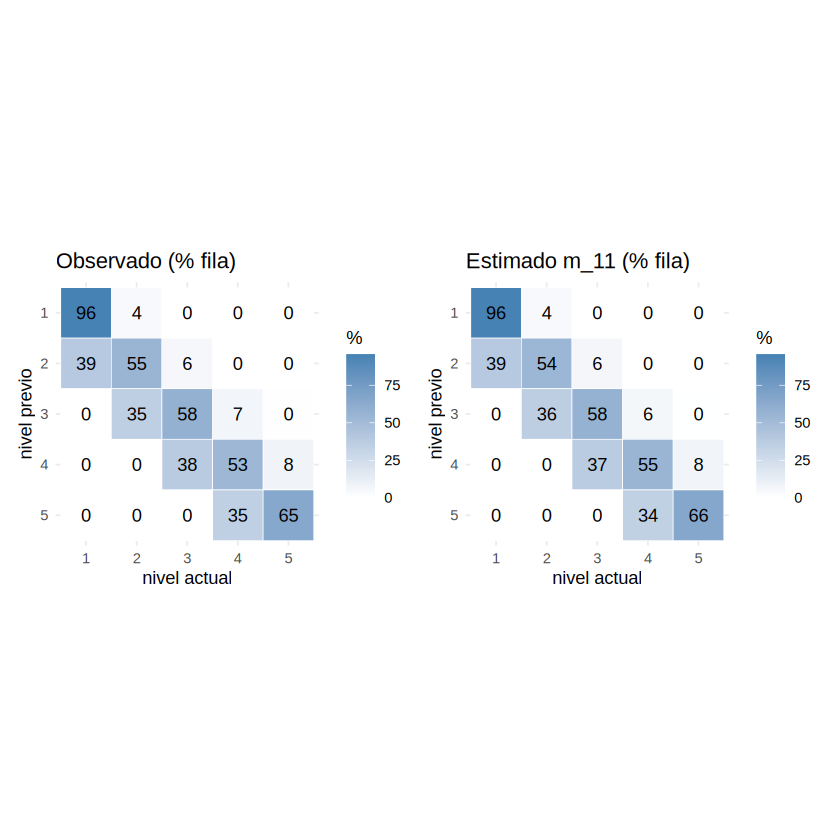

In [ ]:
pct_m11 <- as.data.frame(as.table(100 * P))

neto_m11 <- as.data.frame(as.table(mu_cambio - t(mu_cambio))) |>
  dplyr::mutate(Freq = ifelse(as.integer(prev) < as.integer(act), Freq, NA))

patchwork::wrap_plots(
  mapa(pct_fila, scale_fill_gradient(low = "white", high = "steelblue"),
       "Observado (% fila)", "%"),
  mapa(pct_m11, scale_fill_gradient(low = "white", high = "steelblue"),
       "Estimado m_11 (% fila)", "%")
)

**Resultado:** los dos mapas son prácticamente iguales.

**Qué hacemos:** lo vemos también en un mosaico con los residuos del modelo (los seis ceros estructurales no se dibujan).

Warning message in strucplot(x, condvars = if (is.null(condvars)) NULL else length(condvars), :
“Using calculated degrees of freedom.”


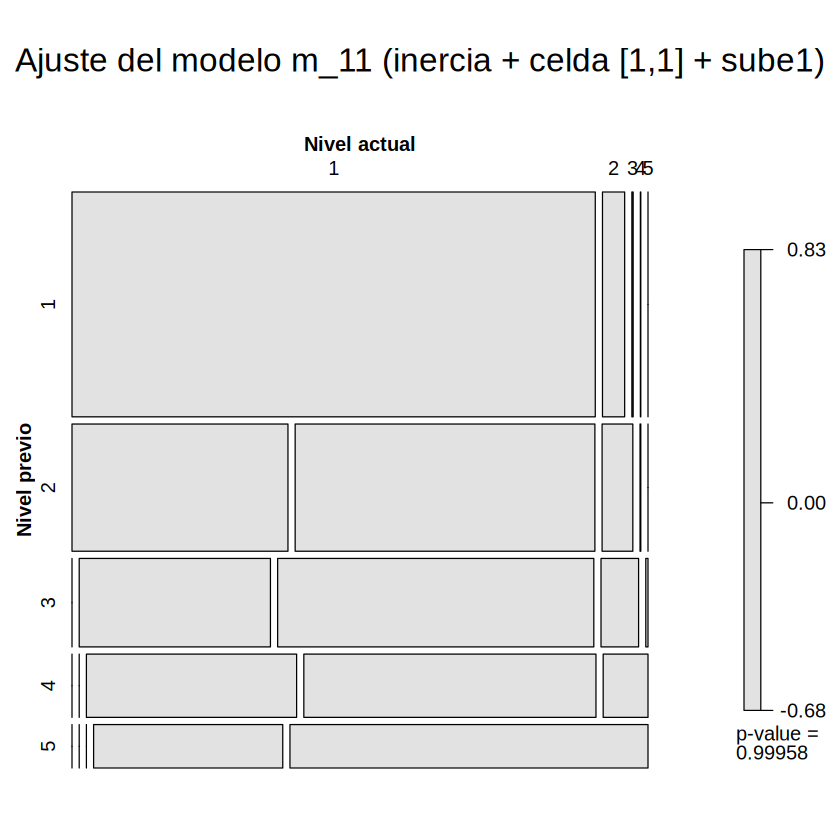

In [ ]:
obs_11 <- xtabs(Freq ~ prev + act, data = cuad_ok)
res_11 <- xtabs(residuals(m_11, type = "pearson") ~ prev + act, data = cuad_ok)

# 2. Gráfico mosaico en 2D con el ajuste de m_11
vcd::mosaic(
  obs_11,
  residuals    = res_11,
  df           = df.residual(m_11),   # conserva los gl reales de m_11 para el p-valor
  shade        = TRUE,
  zero_size    = 0,                   # oculta los círculos en las 6 celdas imposibles
  set_varnames = c(prev = "Nivel previo", act = "Nivel actual"),
  main         = "Ajuste del modelo m_11 (inercia + celda [1,1] + sube1)"
)

**Resultado:** ninguna celda sale marcada (ninguna pasa de 2).

**Por tanto**, 'm_11' reproduce bien la tabla y sus probabilidades de transición son fiables. Falta añadir los clientes nuevos y dar el margen.

#### Clientes nuevos y márgenes

**Qué hacemos:** simulamos 5.000 veces. En cada una, tomamos unos coeficientes razonables (incertidumbre del modelo) y, para el intervalo de predicción, repartimos al azar los clientes de cada nivel entre los cinco niveles. Después sumamos los 306 clientes nuevos (el 10 % de la cartera actual) al nivel 3.

In [ ]:
nuevos <- round(0.10 * sum(n_act))
set.seed(SEMILLA_CURSO)
Xc <- model.matrix(m_11)
sims <- t(replicate(5000, {
  b  <- MASS::mvrnorm(1, coef(m_11), vcov(m_11))                              # coeficientes
  M  <- matrix(0, 5, 5); M[cbind(cuad_ok$i, cuad_ok$j)] <- exp(Xc %*% b)      # mu_ij
  Pb <- M / rowSums(M)                                                        # P(j | i)
  esperado  <- drop(n_act %*% Pb)
  realizado <- rowSums(sapply(1:5, \(i) rmultinom(1, n_act[i], Pb[i, ])))
  c(esperado, realizado)
}))
sims[, c(3, 8)] <- sims[, c(3, 8)] + nuevos                                   # nuevos al nivel 3
data.frame(nivel = 1:5, actual = as.vector(n_act), proximo = round(n_prox + c(0, 0, nuevos, 0, 0)),
           ic_low  = round(apply(sims[, 1:5],  2, quantile, 0.025)),
           ic_high = round(apply(sims[, 1:5],  2, quantile, 0.975)),
           ip_low  = round(apply(sims[, 6:10], 2, quantile, 0.025)),
           ip_high = round(apply(sims[, 6:10], 2, quantile, 0.975)))
nuevos

,nivel,actual,proximo,ic_low,ic_high,ip_low,ip_high
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,1484,1661,1632,1688,1620,1701
2,2,614,560,525,595,511,607
3,3,465,731,703,760,692,771
4,4,309,264,242,287,233,298
5,5,190,151,138,166,130,173


[1] 306

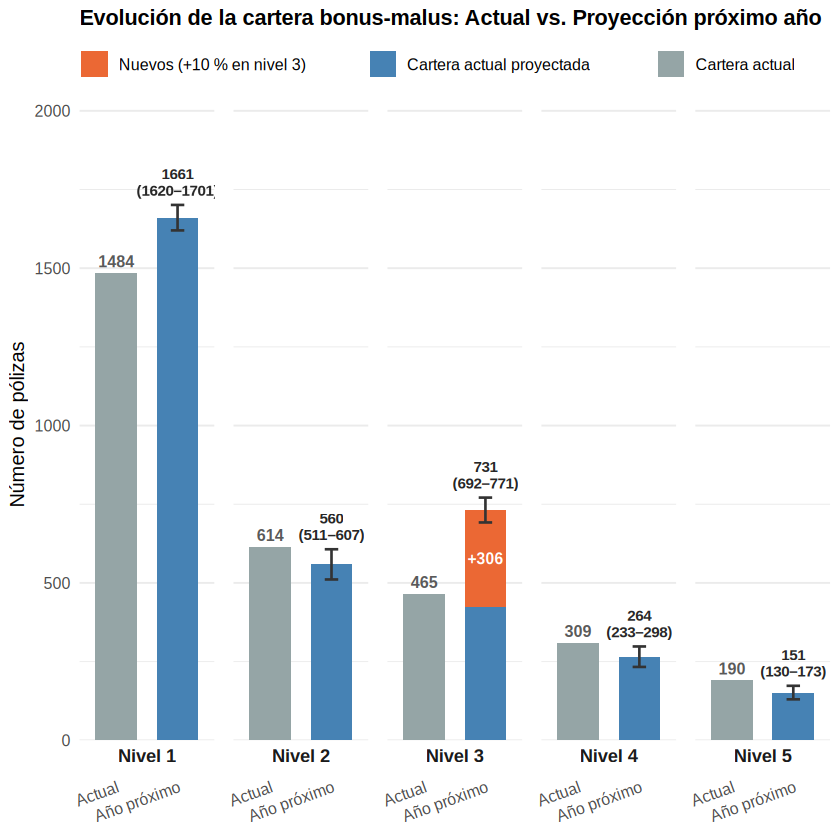

In [ ]:
#@title Proyección del bonus-malus por nivel · Luis
# 1. Preparamos los datos con los 3 bloques: Actual, Esperado (sin nuevos) y Nuevos (+10%)
df_res <- data.frame(
  nivel = factor(paste("Nivel", 1:5)),
  actual = as.vector(n_act),
  retenidos_proy = round(n_prox),
  nuevos = c(0, 0, nuevos, 0, 0),
  total_proy = round(n_prox + c(0, 0, nuevos, 0, 0)),
  ip_low  = round(apply(sims[, 6:10], 2, quantile, 0.025)),
  ip_high = round(apply(sims[, 6:10], 2, quantile, 0.975))
)

# Reestructuramos para tener 2 barras por nivel ("Actual" vs "Próximo año")
# y dentro de "Próximo año" apilar "Cartera actual proyectada" + "Nuevos (+10%)"
df_plot <- dplyr::bind_rows(
  df_res |>
    dplyr::transmute(nivel, escenario = "Actual", bloque = "Cartera actual", clientes = actual),
  df_res |>
    dplyr::transmute(nivel, escenario = "Año próximo", bloque = "Cartera actual proyectada", clientes = retenidos_proy),
  df_res |>
    dplyr::transmute(nivel, escenario = "Año próximo", bloque = "Nuevos (+10 % en nivel 3)", clientes = nuevos)
) |>
  dplyr::mutate(
    escenario = factor(escenario, levels = c("Actual", "Año próximo")),
    bloque = factor(bloque, levels = c("Nuevos (+10 % en nivel 3)",
                                       "Cartera actual proyectada",
                                       "Cartera actual"))
  )

# 2. Gráfico único de respuesta completa
ggplot() +
  # Barras: lado a lado por escenario, y apiladas dentro de "Año próximo"
  geom_col(
    data = df_plot,
    aes(x = escenario, y = clientes, fill = bloque),
    width = 0.68
  ) +
  # Bigotes del margen para presupuestar (solo en "Año próximo")
  geom_errorbar(
    data = df_res,
    aes(x = "Año próximo", ymin = ip_low, ymax = ip_high),
    width = 0.22, linewidth = 0.75, color = "grey20"
  ) +
  # Etiqueta numérica sobre la barra "Actual"
  geom_text(
    data = df_res,
    aes(x = "Actual", y = actual, label = actual),
    vjust = -0.5, size = 3.4, color = "grey35", fontface = "bold"
  ) +
  # Etiqueta numérica + margen sobre la barra "Año próximo"
  geom_text(
    data = df_res,
    aes(x = "Año próximo", y = ip_high, label = paste0(total_proy, "\n(", ip_low, "–", ip_high, ")")),
    vjust = -0.35, size = 3.2, color = "grey15", fontface = "bold", lineheight = 0.9
  ) +
  # Etiqueta interior para los +306 nuevos en el Nivel 3
  geom_text(
    data = dplyr::filter(df_res, nuevos > 0),
    aes(x = "Año próximo", y = retenidos_proy + nuevos / 2, label = paste0("+", nuevos)),
    color = "white", fontface = "bold", size = 3.3
  ) +
  # Agrupamos por Nivel (1 a 5) en una sola fila
  facet_wrap(~ nivel, nrow = 1, strip.position = "bottom") +
  scale_fill_manual(
    values = c(
      "Cartera actual" = "#95a5a6",
      "Cartera actual proyectada" = "steelblue",
      "Nuevos (+10 % en nivel 3)" = "#eb6834"
    )
  ) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.18))) +
  labs(
    title = "Evolución de la cartera bonus-malus: Actual vs. Proyección próximo año",
    x = NULL,
    y = "Número de pólizas",
    fill = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    legend.position = "top",
    plot.title = element_text(face = "bold", size = 13),
    panel.grid.major.x = element_blank(),
    axis.text.x = element_text(size = 9.5, angle = 20, hjust = 1),
    strip.text = element_text(face = "bold", size = 11),
    panel.spacing = unit(0.8, "lines")
  )

**Resultado:** con los clientes nuevos, el año que viene habrá unos 1.661 clientes en el nivel 1 (predicción 1.622–1.700), 560 en el 2 (513–608), 731 en el 3 (691–772), 264 en el 4 (232–298) y 151 en el 5 (131–174).

**Por tanto**, para presupuestar el intervalo de predicción es la cifra que conviene usar. Sin los clientes nuevos, el nivel 3 bajaría de 465 a 425, y con ellos sube a 731.

#### Conclusiones:

1.  La cartera **mejora**: el nivel medio baja de 2,22 a 2,06 y mejoran el 22 % de los clientes frente al 5,3 % que empeora. El reparto de niveles ha cambiado de un año a otro (p < 2·10⁻¹⁶).
2.  El movimiento es (en su gran mayoria) de un nivel cada vez: el 73 % se queda en su nivel, y de los que cambian, la mayoría baja un nivel.
3.  El modelo 'm_11' (inercia, el nivel 1 aparte y subir un nivel) ajusta bien (p = 0,79) y permite proyectar. Con 306 clientes nuevos en el nivel 3, el año que viene habrá unos 1.661, 560, 731, 264 y 151 clientes en los niveles 1 a 5.
4.  Supuestos: las probabilidades de pasar de un nivel a otro se mantienen igual que el año pasado, los nuevos entran todos en el nivel 3 y su número (306) no tiene incertidumbre. Los intervalos recogen solo el error del modelo y el azar de quién se mueve.

#### Validación contra el DGP

Comprobamos m_11 contra el proceso que generó los datos.

In [ ]:
verdad <- attr(cartera_rds, "verdad")
sinis  <- split(attr(cartera_rds, "siniestros")$anio, attr(cartera_rds, "siniestros")$id_poliza)
p_queda <- verdad$persistencia

# Matriz de un año: con partes sube tantos niveles como partes; sin partes se queda o baja uno
paso <- function(k) {
  Tm <- matrix(0, 5, 5)
  if (k > 0) {
    Tm[cbind(1:5, pmin(5, 1:5 + k))] <- 1
  } else {
    Tm[cbind(1:5, 1:5)] <- p_queda
    Tm[cbind(2:5, 1:4)] <- 1 - p_queda
    Tm[1, 1] <- 1
  }
  Tm
}

# Tabla de cambio esperada según el DGP: suma sobre pólizas de P(nivel previo = s y nivel actual = s')
E <- matrix(0, 5, 5)
for (i in seq_len(nrow(cartera))) {
  Y   <- max(1L, as.integer(ceiling(cartera$antiguedad[i])))
  tab <- tabulate(as.integer(sinis[[as.character(cartera$id_poliza[i])]]), nbins = Y)
  d   <- c(.15, .25, .30, .20, .10)            # reparto inicial de niveles en el DGP
  for (y in 1:Y) { previo <- d; d <- drop(d %*% paso(tab[y])) }
  E <- E + if (Y >= 2) previo * paso(tab[Y]) else diag(d)
}
dimnames(E) <- dimnames(mu_cambio)

# Calibración: esperadas según el DGP frente a observadas
c(se_quedan_DGP = round(100 * sum(diag(E)) / sum(E), 1),
  se_quedan_observado = round(100 * sum(cuad$Freq[cuad$i == cuad$j]) / sum(cuad$Freq), 1),
  pólizas_celdas_excluidas_DGP = sum(E[cuad$imposible]))

# Probabilidades de transición verdaderas frente a las de m_11
P_dgp <- E / rowSums(E)
round(P_dgp, 3)
round(P - P_dgp, 3)
c(max_diferencia = round(max(abs(P - P_dgp)), 3))

# Proyección con las transiciones verdaderas frente al modelo y su intervalo de confianza
n_prox_dgp <- drop(n_act %*% P_dgp) + c(0, 0, nuevos, 0, 0)
ic <- apply(sims[, 1:5], 2, quantile, c(0.025, 0.975))
data.frame(nivel = 1:5, proximo_DGP = round(n_prox_dgp),
           proximo_m11 = round(n_prox + c(0, 0, nuevos, 0, 0)),
           ic_low = round(ic[1, ]), ic_high = round(ic[2, ]),
           dentro_IC = n_prox_dgp >= ic[1, ] & n_prox_dgp <= ic[2, ])

se_quedan_DGP          se_quedan_observado 
                        71.8                         72.7 
pólizas_celdas_excluidas_DGP 
                         0.0

,1,2,3,4,5
1,0.957,0.041,0.002,0.001,0.000
2,0.394,0.549,0.053,0.004,0.001
3,0.000,0.386,0.548,0.060,0.007
4,0.000,0.000,0.376,0.532,0.092
5,0.000,0.000,0.000,0.355,0.645


    act
prev      1      2      3      4      5
   1 -0.001  0.001  0.000  0.000  0.000
   2  0.001 -0.009  0.010 -0.001  0.000
   3  0.000 -0.027  0.029  0.001 -0.004
   4  0.000  0.000 -0.001  0.016 -0.015
   5  0.000  0.000  0.000 -0.016  0.016

max_diferencia 
         0.029

,nivel,proximo_DGP,proximo_m11,ic_low,ic_high,dentro_IC
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
1,1,1662,1661,1632,1688,TRUE
2,2,577,560,525,595,TRUE
3,3,712,731,703,760,TRUE
4,4,263,264,242,287,TRUE
5,5,155,151,138,166,TRUE


**Resultado:** el DGP deja en su nivel al 71,8 % de las pólizas (observado: 72,7 %) y da probabilidad cero a las seis celdas que excluimos, así que eran ceros estructurales de verdad. Sus probabilidades de transición se parecen mucho a las de m_11: la mayor diferencia es 0,029 (de 3 a 2, el DGP da 0,386 y m_11 0,359) y las demás no pasan de 0,016. En la proyección, las cifras verdaderas caen dentro del intervalo de confianza de m_11 en los cinco niveles.

**Por tanto**, m_11 recoge bien cómo se mueven los clientes y los intervalos de la proyección son correctos.

## Jorge Cheng Huang
La tarifa y la comparación territorial proceden del mismo cuaderno. El archivo adicional documenta una exploración previa que Jorge incorporó al repositorio.

### P2 · Tarifa y validación fuera de muestra
*Nota de integración.* Se conserva la distinción entre el ajuste con bonus previo y la tarifa aplicable a clientes nuevos. Se eliminó una expresión suelta `p` y se consolidó la simulación duplicada de intervalos en la celda que ya define `n_sim`. El ajuste exploratorio con ceros adicionales y muchas variables da avisos de singularidad. Conviene revisar su incertidumbre. Los comentarios de interpretación son los del borrador de Jorge. Un contraste sin significación deja abierta la posibilidad de efectos pequeños.

*Actualización de integración.* Esta sección usa la partición del QMD de Jorge, con la semilla del curso 20252026 y los mismos identificadores de ajuste y reserva que el análisis actuarial. Se actualizaron las cifras de la tarifa comercial y se conserva el método de selección por BIC.

[Fuente del equipo · Pregunta_2_3_final.qmd](https://github.com/GLM-2026/proy2-07-Cox/blob/f4b52f368eb5958e665c17c5e432ea18a0ac4390/Analisis/Pregunta_2_3_final.qmd)

In [ ]:
set.seed(SEMILLA_CURSO)
cartera <- cartera_original

In [ ]:
# ==============================================================================
# FASE 1: EXPLORACIÓN DE FRECUENCIA, LIMPIEZA Y PARTICIÓN TRAIN / TEST
# ==============================================================================
library(tidyverse)

# 1. Comprobación de la relación entre antiguedad y exposicion
cat("--- RELACIÓN ANTIGÜEDAD vs EXPOSICIÓN ---\n")
cartera %>%
  transmute(
    antiguedad,
    exposicion,
    ratio = exposicion / antiguedad
  ) %>%
  summary() %>%
  print()

--- RELACIÓN ANTIGÜEDAD vs EXPOSICIÓN ---
   antiguedad      exposicion         ratio    
 Min.   :0.100   Min.   :0.0100   Min.   :0.1  
 1st Qu.:2.194   1st Qu.:0.2194   1st Qu.:0.1  
 Median :3.768   Median :0.3768   Median :0.1  
 Mean   :4.207   Mean   :0.4207   Mean   :0.1  
 3rd Qu.:5.934   3rd Qu.:0.5934   3rd Qu.:0.1  
 Max.   :9.996   Max.   :0.9996   Max.   :0.1  


Vemos si como esta distribuido los datos, su minimo, primer cuartil, mediana, media, tercer cuartil y su maximo, tambien vemos si la relación de antigüedad y exposicion es 0.1 como dice el enunciado.

In [ ]:
# 2. Diagnóstico descriptivo de la variable respuesta (n_siniestros)
cat("\n--- ESTADÍSTICOS DE CONTEO Y DISPERSIÓN ---\n")
media_sin <- mean(cartera$n_siniestros)
var_sin   <- var(cartera$n_siniestros)
prop_ceros <- mean(cartera$n_siniestros == 0)
tasa_expo <- sum(cartera$n_siniestros) / sum(cartera$exposicion)
tasa_anti <- sum(cartera$n_siniestros) / sum(cartera$antiguedad)

cat(sprintf("Total pólizas: %d | Total siniestros: %d\n", nrow(cartera), sum(cartera$n_siniestros)))
cat(sprintf("Media n_siniestros: %.4f | Varianza: %.4f | Ratio Var/Media (phi): %.4f\n",
            media_sin, var_sin, var_sin / media_sin))
cat(sprintf("Proporción de ceros observados: %.2f%%\n", prop_ceros * 100))
cat(sprintf("Tasa global (por unidad de 'exposicion'): %.4f\n", tasa_expo))
cat(sprintf("Tasa global (por año de 'antiguedad'):   %.4f\n", tasa_anti))

# Distribución de frecuencias observadas (0, 1, 2, 3...)
cat("\n--- TABLA DE FRECUENCIAS DE N_SINIESTROS ---\n")
print(table(cartera$n_siniestros))


--- ESTADÍSTICOS DE CONTEO Y DISPERSIÓN ---
Total pólizas: 3062 | Total siniestros: 1770
Media n_siniestros: 0.5781 | Varianza: 1.4371 | Ratio Var/Media (phi): 2.4860
Proporción de ceros observados: 69.01%
Tasa global (por unidad de 'exposicion'): 1.3740
Tasa global (por año de 'antiguedad'):   0.1374

--- TABLA DE FRECUENCIAS DE N_SINIESTROS ---

   0    1    2    3    4    5    6    7    8    9   10   11   12   13   14 
2113  545  218   90   42   23   14    7    2    3    1    1    1    1    1 


Acontinuacion hacemos el estadistico de conteo y dispersion y la tabla de frecuencia, es tambien para ver como estan los datos.

In [ ]:
# 3. Revisión de niveles de las variables categóricas de la Tabla 24
cat("\n--- NIVELES DE VARIABLES CATEGÓRICAS EN CARTERA ---\n")
vars_cat <- c("edad_tramo", "zona_circulacion", "uso", "tipo_vehiculo", "combustible")
lapply(cartera[vars_cat], unique) %>% print()


--- NIVELES DE VARIABLES CATEGÓRICAS EN CARTERA ---
$edad_tramo
[1] "25-35" "35-65" "18-25" "65+"  

$zona_circulacion
[1] "mixta"  "urbana" "rural" 

$uso
[1] "particular" "comercial" 

$tipo_vehiculo
[1] "turismo"   "furgoneta" "moto"     

$combustible
[1] "diesel"   "gasolina"



vemos las variables categoricas de la tabla 24.

In [ ]:
# 4. Selección de variables A PRIORI (eliminando fuga de datos y variables de red)
# Excluimos id_poliza, id_agencia, id_region (se ven en el apartado 3) y variables posteriores al contrato
vars_apriori <- c(
  "n_siniestros", "exposicion", "antiguedad",
  "edad_conductor", "edad_tramo", "antiguedad_carnet",
  "potencia_cv", "cilindrada", "antiguedad_vehiculo", "valor_vehiculo",
  "densidad", "zona_circulacion", "km_anuales",
  "uso", "tipo_vehiculo", "combustible",
  "sexo", "color_vehiculo", "estado_civil", "forma_pago",
  "financiado", "n_conductores", "nivel_estudios", "medio_contacto",
  "bonus_malus_prev"
)

cartera_limpia <- cartera %>%
  dplyr::select(all_of(vars_apriori)) %>%
  mutate(across(where(is.character), as.factor))

In [ ]:
# Partición de P2 por los identificadores fijados en la preparación común.
idx_train <- match(ids_ajuste_p2, cartera_original$id_poliza)
idx_test <- which(cartera_original$id_poliza %in% ids_reserva_p2)

stopifnot(
  nrow(cartera_limpia) == nrow(cartera_original),
  !anyNA(idx_train),
  !anyDuplicated(c(idx_train, idx_test)),
  length(idx_train) + length(idx_test) == nrow(cartera_limpia),
  identical(cartera_original$id_poliza[idx_test], ids_reserva_p2)
  )

train <- cartera_limpia[idx_train, ]
test <- cartera_limpia[idx_test, ]

cat(sprintf(
  "\nPartición de P2 (semilla %d) -> Ajuste: %d pólizas | Reserva: %d pólizas\n",
  SEMILLA_CURSO, nrow(train), nrow(test)
  ))
cat(sprintf(
  "Media de partes por póliza en ajuste: %.4f | En reserva: %.4f\n",
  mean(train$n_siniestros), mean(test$n_siniestros)
  ))


Partición de P2 (semilla 20252026) -> Ajuste: 2296 pólizas | Reserva: 766 pólizas
Media de partes por póliza en ajuste: 0.5749 | En reserva: 0.5875


In [ ]:
# 6. Construcción de la Tabla 24 (5 clientes tipo)
tabla24 <- tibble(
  perfil = c("A · Joven urbano", "B · Familiar rural", "C · Moto en ciudad",
             "D · Furgoneta comercial", "E · Conductor mayor"),
  edad_conductor      = c(23, 45, 30, 40, 70),
  edad_tramo          = factor(c("18-25", "35-65", "25-35", "35-65", "65+"),
                               levels = levels(cartera_limpia$edad_tramo)),
  antiguedad_carnet   = c(4, 25, 10, 20, 45),
  potencia_cv         = c(110, 120, 70, 130, 90),
  cilindrada          = c(1600, 1900, 900, 2200, 1400),
  antiguedad_vehiculo = c(8, 6, 4, 10, 15),
  valor_vehiculo      = c(24000, 25000, 12000, 26000, 15000),
  densidad            = c(2500, 60, 4000, 500, 300),
  zona_circulacion    = factor(c("urbana", "rural", "urbana", "mixta", "mixta"),
                               levels = levels(cartera_limpia$zona_circulacion)),
  km_anuales          = c(15000, 12000, 8000, 35000, 6000),
  uso                 = factor(c("particular", "particular", "particular", "comercial", "particular"),
                               levels = levels(cartera_limpia$uso)),
  tipo_vehiculo       = factor(c("turismo", "turismo", "moto", "furgoneta", "turismo"),
                               levels = levels(cartera_limpia$tipo_vehiculo)),
  combustible         = factor(c("gasolina", "diesel", "gasolina", "diesel", "gasolina"),
                               levels = levels(cartera_limpia$combustible)),
  antiguedad          = c(1, 1, 1, 1, 1)
)

Creamos la tabla 24 en R.

################################################################################

**Dirección técnica**. «Necesitamos la tarifa de frecuencia del año próximo. Los compañeros de siniestros nos cuentan que unos pocos clientes dan muchísimos partes y la mayoría ninguno, y hay quien sostiene que muchos de esos coches, en la práctica, apenas circulan.»

¿Cuántos partes cabe esperar de cada cliente, de qué características depende y cuánto pesa cada una? La ficha tiene muchísimos campos: decidnos con cuáles nos quedamos. Queremos una tarifa sencilla, que un agente pueda explicar a su cliente, y antes de llevarla al consejo necesitamos pruebas de que acierta con clientes que no habéis usado para construirla. Para estrenarla, os pasamos las fichas de cinco clientes tipo: ¿cuántos partes esperamos de cada uno en su primer año, y entre qué valores puede moverse?

In [ ]:
# ==============================================================================
# FASE 2: ELECCIÓN DE DISTRIBUCIÓN (POISSON vs NB2 vs ZINB/HURDLE) Y SELECCIÓN
# ==============================================================================

# Fórmula con todas las variables a priori (evitando duplicados exactos en este primer paso)
form_base <- n_siniestros ~ edad_tramo + antiguedad_carnet + potencia_cv +
  antiguedad_vehiculo + valor_vehiculo + zona_circulacion + km_anuales +
  uso + tipo_vehiculo + combustible + sexo + color_vehiculo +
  estado_civil + forma_pago + financiado + n_conductores +
  nivel_estudios + medio_contacto + bonus_malus_prev +
  offset(log(antiguedad))

Hemos propuesto una formula con todas las variables a priori para empezar, no significa que es la formula final.

--- 1A. CONTRASTE DE SOBREDISPERSIÓN (performance) ---
# Overdispersion test

       dispersion ratio =    0.943
  Pearson's Chi-Squared = 2135.984
                p-value =    0.975



No overdispersion detected.




--- 1B. CONTRASTE DE EXCESO DE CEROS (DHARMa) ---

	DHARMa zero-inflation test via comparison to expected zeros with
	simulation under H0 = fitted model

data:  simulationOutput
ratioObsSim = 1.0229, p-value = 0.056
alternative hypothesis: two.sided



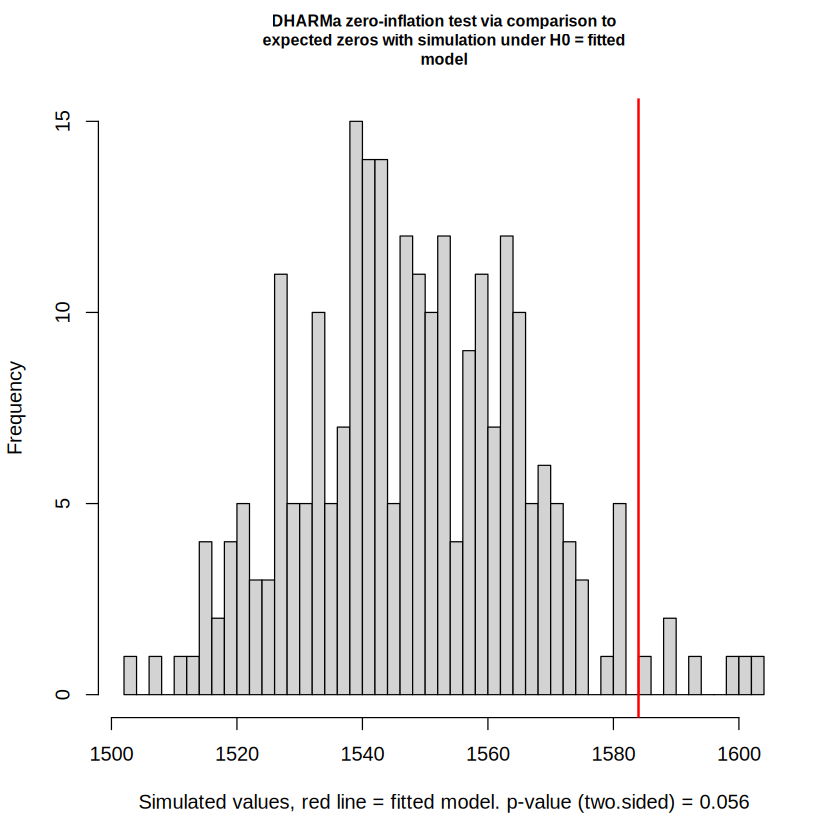

In [ ]:
cargar_paquetes(c("performance", "DHARMa"))

# 1. Modelo base de Poisson (Unidad 2.1)
mod_pois <- glm(form_base, family = poisson(link = "log"), data = train)

cat("--- 1A. CONTRASTE DE SOBREDISPERSIÓN (performance) ---\n")
print(check_overdispersion(mod_pois))

cat("\n--- 1B. CONTRASTE DE EXCESO DE CEROS (DHARMa) ---\n")
sim_pois <- simulateResiduals(mod_pois, plot = FALSE)
print(testZeroInflation(sim_pois))

**Exploración con historial.** En la tabla de ajuste, el contraste de Poisson con la fórmula amplia da un valor p de 0,975 para la sobredispersión y de 0,056 para el exceso de ceros en la reproducibilidad local. Estos diagnósticos corresponden a un ajuste exploratorio que incluye información del historial. La tarifa de altas se evalúa con sus propios predictores.

In [ ]:
# 2. Modelo Binomial Negativa NB2 (Unidad 2.3)
mod_nb <- glm.nb(form_base, data = train)
mod_nb


Call:  glm.nb(formula = form_base, data = train, init.theta = 34.14906139, 
    link = log)

Coefficients:
             (Intercept)           edad_tramo25-35           edad_tramo35-65  
              -3.455e+00                -2.713e-01                -5.197e-01  
           edad_tramo65+         antiguedad_carnet               potencia_cv  
              -3.198e-01                -4.923e-03                 2.718e-03  
     antiguedad_vehiculo            valor_vehiculo     zona_circulacionrural  
              -2.659e-03                -5.714e-06                -3.590e-01  
  zona_circulacionurbana                km_anuales             usoparticular  
               2.962e-01                 2.994e-05                -1.577e-01  
       tipo_vehiculomoto      tipo_vehiculoturismo       combustiblegasolina  
               5.026e-02                -7.738e-02                -1.093e-01  
                   sexoM        color_vehiculogris       color_vehiculonegro  
               2.230e-0

Suponemos usar el Modelo Binomial Negativa

In [ ]:
cargar_paquetes(c("pscl"))

# 3. Modelos de Exceso de Ceros: ZINB y Hurdle (Unidad 2.4)
# En la parte derecha (|) modelamos la probabilidad de ser un coche que "apenas circula"
form_zi <- n_siniestros ~ edad_tramo + antiguedad_carnet + potencia_cv +
  antiguedad_vehiculo + valor_vehiculo + zona_circulacion + km_anuales +
  uso + tipo_vehiculo + combustible + sexo + color_vehiculo +
  estado_civil + forma_pago + financiado + n_conductores +
  nivel_estudios + medio_contacto + bonus_malus_prev +
  offset(log(antiguedad)) | km_anuales + uso + tipo_vehiculo + zona_circulacion + edad_tramo

mod_zinb   <- zeroinfl(form_zi, dist = "negbin", data = train)
mod_hurdle <- hurdle(form_zi, dist = "negbin", data = train)

Warning message in value[[3L]](cond):
“system is computationally singular: reciprocal condition number = 4.98562e-25FALSE”
Warning message in value[[3L]](cond):
“system is computationally singular: reciprocal condition number = 6.60764e-17FALSE”


In [ ]:
# 4. Tabla comparativa de ajuste (Log-Verosimilitud, AIC y BIC)
cat("\n--- 2. COMPARATIVA DE MODELOS (TRAIN) ---\n")
comparativa <- tibble(
  Modelo = c("Poisson", "Binomial Negativa (NB2)", "ZINB (Inflado de ceros)", "Hurdle (Barrera)"),
  Parametros = c(length(coef(mod_pois)), length(coef(mod_nb)) + 1,
                 length(coef(mod_zinb)) + 1, length(coef(mod_hurdle)) + 1),
  LogLik = c(as.numeric(logLik(mod_pois)), as.numeric(logLik(mod_nb)),
             as.numeric(logLik(mod_zinb)), as.numeric(logLik(mod_hurdle))),
  AIC = c(AIC(mod_pois), AIC(mod_nb), AIC(mod_zinb), AIC(mod_hurdle)),
  BIC = c(BIC(mod_pois), BIC(mod_nb), BIC(mod_zinb), BIC(mod_hurdle))
)
print(comparativa)


--- 2. COMPARATIVA DE MODELOS (TRAIN) ---
# A tibble: 4 × 5
  Modelo                  Parametros LogLik   AIC   BIC
  <chr>                        <dbl>  <dbl> <dbl> <dbl>
1 Poisson                         30 -1773. 3606. 3778.
2 Binomial Negativa (NB2)         31 -1773. 3607. 3785.
3 ZINB (Inflado de ceros)         41 -1766. 3614. 3850.
4 Hurdle (Barrera)                41 -2055. 4192. 4427.


La tabla compara las familias con la fórmula exploratoria, que incluye el historial de partes. Para elegir la distribución de la tarifa de altas, repetimos la comparación con características disponibles al contratar.

In [ ]:
# 5. Selección automática de variables (criterio BIC) para lograr una tarifa sencilla

cat("\n--- 3. SELECCIÓN DE VARIABLES (STEPWISE BIC SOBRE NB2) ---\n")
mod_nb_bic <- stepAIC(mod_nb, k = log(nrow(train)), trace = FALSE)
print(summary(mod_nb_bic))


--- 3. SELECCIÓN DE VARIABLES (STEPWISE BIC SOBRE NB2) ---

Call:
glm.nb(formula = n_siniestros ~ edad_tramo + potencia_cv + zona_circulacion + 
    km_anuales + bonus_malus_prev + offset(log(antiguedad)), 
    data = train, init.theta = 17.44242167, link = log)

Coefficients:
                         Estimate Std. Error z value Pr(>|z|)    
(Intercept)            -3.851e+00  1.435e-01 -26.839  < 2e-16 ***
edad_tramo25-35        -3.181e-01  9.509e-02  -3.345 0.000823 ***
edad_tramo35-65        -6.057e-01  8.047e-02  -7.527 5.20e-14 ***
edad_tramo65+          -5.033e-01  1.182e-01  -4.258 2.06e-05 ***
potencia_cv             2.492e-03  7.954e-04   3.133 0.001728 ** 
zona_circulacionrural  -3.730e-01  7.999e-02  -4.663 3.12e-06 ***
zona_circulacionurbana  2.681e-01  7.201e-02   3.723 0.000197 ***
km_anuales              2.978e-05  3.653e-06   8.150 3.63e-16 ***
bonus_malus_prev        5.955e-01  2.064e-02  28.853  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 

El ajuste anterior usa el bonus-malus previo. Para construir la tarifa de altas, repetimos el ajuste de Poisson y binomial negativa con las variables disponibles al contratar.

In [ ]:
# 5. Selección automática de variables sobre POISSON (solo datos disponibles al cotizar / Tabla 24)
cat("\n--- 3. SELECCIÓN DE VARIABLES (STEPWISE BIC SOBRE POISSON) ---\n")

form_comercial <- n_siniestros ~ edad_tramo + antiguedad_carnet + potencia_cv +
  antiguedad_vehiculo + valor_vehiculo + zona_circulacion + km_anuales +
  uso + tipo_vehiculo + combustible + offset(log(antiguedad))

mod_pois_com <- glm(form_comercial, family = poisson(link = "log"), data = train)
mod_tarifa   <- stepAIC(mod_pois_com, k = log(nrow(train)), trace = FALSE)


print(summary(mod_tarifa))


--- 3. SELECCIÓN DE VARIABLES (STEPWISE BIC SOBRE POISSON) ---

Call:
glm(formula = n_siniestros ~ edad_tramo + potencia_cv + zona_circulacion + 
    km_anuales + uso + offset(log(antiguedad)), family = poisson(link = "log"), 
    data = train)

Coefficients:
                         Estimate Std. Error z value Pr(>|z|)    
(Intercept)            -1.753e+00  1.321e-01 -13.269  < 2e-16 ***
edad_tramo25-35        -6.712e-01  8.823e-02  -7.608 2.79e-14 ***
edad_tramo35-65        -1.142e+00  7.349e-02 -15.537  < 2e-16 ***
edad_tramo65+          -9.722e-01  1.112e-01  -8.741  < 2e-16 ***
potencia_cv             2.885e-03  7.451e-04   3.871 0.000108 ***
zona_circulacionrural  -5.267e-01  7.727e-02  -6.817 9.32e-12 ***
zona_circulacionurbana  4.405e-01  6.769e-02   6.507 7.67e-11 ***
km_anuales              3.816e-05  3.069e-06  12.434  < 2e-16 ***
usoparticular          -2.310e-01  7.616e-02  -3.033 0.002422 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion

In [ ]:
# 1. Miramos si SIN bonus_malus_prev hay sobredispersión
check_overdispersion(mod_pois_com)

# 2. Comparamos Poisson vs Binomial Negativa para clientes nuevos (Tabla 24)
mod_nb_com <- glm.nb(form_comercial, data = train)
BIC(mod_pois_com, mod_nb_com)

Overdispersion detected.



# Overdispersion test

       dispersion ratio =    1.541
  Pearson's Chi-Squared = 3514.315
                p-value =  < 0.001


,df,BIC
,<dbl>,<dbl>
mod_pois_com,15,4601.062
mod_nb_com,16,4320.971


Al ajustar la fórmula comercial sin historial de partes reaparece la sobredispersión. La comparación de Poisson y binomial negativa usa los mismos predictores candidatos en la muestra de ajuste. A continuación se seleccionan los factores de la tarifa NB2 por BIC.

In [ ]:
# Selección final de variables por BIC sobre Binomial Negativa (Tarifa clientes nuevos)
mod_tarifa_nb <- stepAIC(mod_nb_com, k = log(nrow(train)), trace = FALSE)
stopifnot(
  "La tarifa P2 debe conservar edad, zona y kilómetros" =
    setequal(
      attr(terms(mod_tarifa_nb), "term.labels"),
      c("edad_tramo", "zona_circulacion", "km_anuales")
      )
  )
summary(mod_tarifa_nb)


Call:
glm.nb(formula = n_siniestros ~ edad_tramo + zona_circulacion + 
    km_anuales + offset(log(antiguedad)), data = train, init.theta = 0.9478140315, 
    link = log)

Coefficients:
                         Estimate Std. Error z value Pr(>|z|)    
(Intercept)            -1.762e+00  1.214e-01 -14.514  < 2e-16 ***
edad_tramo25-35        -6.950e-01  1.328e-01  -5.232 1.67e-07 ***
edad_tramo35-65        -1.133e+00  1.116e-01 -10.154  < 2e-16 ***
edad_tramo65+          -9.028e-01  1.567e-01  -5.763 8.26e-09 ***
zona_circulacionrural  -4.980e-01  9.707e-02  -5.130 2.90e-07 ***
zona_circulacionurbana  4.890e-01  9.854e-02   4.963 6.95e-07 ***
km_anuales              4.552e-05  4.695e-06   9.696  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for Negative Binomial(0.9478) family taken to be 1)

    Null deviance: 1998.3  on 2295  degrees of freedom
Residual deviance: 1741.5  on 2289  degrees of freedom
AIC: 4234.4

Number of Fisher Sc

**Tarifa de frecuencia para altas.** La selección por BIC conserva tramo de edad, zona y kilómetros anuales. La binomial negativa NB2 usa un enlace logarítmico y un offset con el logaritmo de los años de cobertura. La dispersión estimada es θ = 0,948.

- En comparación con el tramo 18–25, la frecuencia esperada disminuye un **50,1 %** entre 25 y 35, un **67,8 %** entre 35 y 65 y un **59,5 %** para mayores de 65, a igualdad de zona y kilómetros.
- Frente a la zona mixta, se esperan **39,2 % menos** partes por año en rural y **63,1 % más** en urbana, a igualdad de edad y kilómetros.
- Cada 10.000 km anuales adicionales aumenta en **57,7 %** la frecuencia prevista, manteniendo los demás factores fijos.

In [ ]:
# ==============================================================================
# FASE 3.1: VALIDACIÓN FUERA DE MUESTRA EN EL CONJUNTO TEST
# ==============================================================================

# 1. Ajustamos la versión Poisson con los mismos predictores seleccionados para comparar en test
mod_tarifa_pois <- glm(formula(mod_tarifa_nb), family = poisson(link = "log"), data = train)

# 2. Predecimos los siniestros esperados en TEST (R aplica el offset de antigüedad solo)
test <- test %>%
  mutate(
    pred_nb   = predict(mod_tarifa_nb, newdata = test, type = "response"),
    pred_pois = predict(mod_tarifa_pois, newdata = test, type = "response")
  )

# 3. Tabla de calibración global y error fuera de muestra
cat("--- 1. CALIBRACIÓN Y AJUSTE EN TEST ---\n")
resumen_test <- tibble(
  Metrica = c(
    "Siniestros REALES totales en test",
    "Siniestros PREDICHOS (Binomial Negativa)",
    "Siniestros PREDICHOS (Poisson)",
    "RMSE (Error cuadrático medio) - BN",
    "RMSE (Error cuadrático medio) - Poisson",
    "Log-Verosimilitud en test - BN (mayor es mejor)",
    "Log-Verosimilitud en test - Poisson (mayor es mejor)"
  ),
  Valor = c(
    sum(test$n_siniestros),
    sum(test$pred_nb),
    sum(test$pred_pois),
    sqrt(mean((test$n_siniestros - test$pred_nb)^2)),
    sqrt(mean((test$n_siniestros - test$pred_pois)^2)),
    sum(dnbinom(test$n_siniestros, mu = test$pred_nb, size = mod_tarifa_nb$theta, log = TRUE)),
    sum(dpois(test$n_siniestros, lambda = test$pred_pois, log = TRUE))
  )
)
print(resumen_test)

# 4. Comprobación por quintiles de partes previstos durante toda la vigencia
cat("\n--- 2. CALIBRACIÓN POR QUINTILES DE PARTES PREVISTOS EN RESERVA ---\n")
tabla_lift <- test %>%
  mutate(grupo_riesgo = ntile(pred_nb, 5)) %>%
  group_by(grupo_riesgo) %>%
  summarise(
    n_polizas        = n(),
    exposicion_anios = round(sum(antiguedad), 1),
    siniestros_real  = sum(n_siniestros),
    siniestros_pred  = round(sum(pred_nb), 1),
    tasa_anual_real  = round(sum(n_siniestros) / sum(antiguedad), 3),
    tasa_anual_pred  = round(sum(pred_nb) / sum(antiguedad), 3)
  )
print(tabla_lift)

--- 1. CALIBRACIÓN Y AJUSTE EN TEST ---
# A tibble: 7 × 2
  Metrica                                                Valor
  <chr>                                                  <dbl>
1 Siniestros REALES totales en test                     450   
2 Siniestros PREDICHOS (Binomial Negativa)              444.  
3 Siniestros PREDICHOS (Poisson)                        442.  
4 RMSE (Error cuadrático medio) - BN                      1.13
5 RMSE (Error cuadrático medio) - Poisson                 1.12
6 Log-Verosimilitud en test - BN (mayor es mejor)      -710.  
7 Log-Verosimilitud en test - Poisson (mayor es mejor) -770.  

--- 2. CALIBRACIÓN POR QUINTILES DE PARTES PREVISTOS EN RESERVA ---
# A tibble: 5 × 7
  grupo_riesgo n_polizas exposicion_anios siniestros_real siniestros_pred
         <int>     <int>            <dbl>           <dbl>           <dbl>
1            1       154             236.              13            17.8
2            2       153             470.              47         

- La NB2 obtiene mayor log-verosimilitud en reserva que Poisson, **−710,38 frente a −770,43**. Poisson da un error cuadrático medio en raíz ligeramente menor (**1,119 frente a 1,131**).
- Durante toda la vigencia se prevén **443,81 partes frente a 450 observados**. Por quintil de recuento previsto se observaron 13, 47, 70, 104 y 216 partes. Cada grupo acumula una exposición distinta, por lo que las tasas por año cubierto ayudan a interpretar el contraste.

In [ ]:
# ==============================================================================
# FASE 3.2: TARIFICACIÓN E INTERVALOS DE CONFIANZA PARA LA TABLA 24
# ==============================================================================

# 1. Predicción en escala lineal (log) para obtener errores estándar exactos
pred_link <- predict(mod_tarifa_nb, newdata = tabla24, type = "link", se.fit = TRUE)

# 2. Construcción de la tabla final de tarificación para los 5 perfiles
resultados_tabla24 <- tabla24 %>%
  dplyr::select(perfil, edad_tramo, zona_circulacion, km_anuales, uso) %>%
  mutate(
    freq_esperada = exp(pred_link$fit),
    ic_95_inf     = exp(pred_link$fit - 1.96 * pred_link$se.fit),
    ic_95_sup     = exp(pred_link$fit + 1.96 * pred_link$se.fit),
    prob_0_sin    = dnbinom(0, mu = freq_esperada, size = mod_tarifa_nb$theta),
    prob_1_o_mas  = 1 - prob_0_sin,
    indice_riesgo = round(freq_esperada / min(freq_esperada), 1)
  ) %>%
  mutate(
    across(c(freq_esperada, ic_95_inf, ic_95_sup), ~ round(.x, 3)),
    across(c(prob_0_sin, prob_1_o_mas), ~ paste0(round(.x * 100, 1), "%"))
  )

In [ ]:
#Para calcular la
n_sim <- 10000

ip_mat <- withr::with_seed(SEMILLA_CURSO, sapply(seq_len(nrow(tabla24)), function(i) {
  # 1. Incertidumbre en el parámetro estimado (IC)
  eta_sim <- rnorm(n_sim, mean = pred_link$fit[i], sd = pred_link$se.fit[i])
  # 2. Variabilidad aleatoria individual del cliente (Binomial Negativa)
  y_sim <- rnbinom(n_sim, size = mod_tarifa_nb$theta, mu = exp(eta_sim))
  quantile(y_sim, probs = c(0.025, 0.975))
}))

resultados_tabla24$ip_inf_95 <- ip_mat[1, ]
resultados_tabla24$ip_sup_95 <- ip_mat[2, ]

print(resultados_tabla24, width = Inf)

# A tibble: 5 × 13
  perfil                  edad_tramo zona_circulacion km_anuales uso       
  <chr>                   <fct>      <fct>                 <dbl> <fct>     
1 A · Joven urbano        18-25      urbana                15000 particular
2 B · Familiar rural      35-65      rural                 12000 particular
3 C · Moto en ciudad      25-35      urbana                 8000 particular
4 D · Furgoneta comercial 35-65      mixta                 35000 comercial 
5 E · Conductor mayor     65+        mixta                  6000 particular
  freq_esperada ic_95_inf ic_95_sup prob_0_sin prob_1_o_mas indice_riesgo
          <dbl>     <dbl>     <dbl> <chr>      <chr>                <dbl>
1         0.554     0.432     0.712 64.6%      35.4%                  9.5
2         0.058     0.048     0.07  94.5%      5.5%                   1  
3         0.201     0.158     0.256 83.3%      16.7%                  3.5
4         0.272     0.219     0.338 78.7%      21.3%                  4.7
5    

**Cinco fichas durante un año de cobertura al ritmo medio de la tarifa.** El IC del 95 % se refiere a la media estimada. El intervalo predictivo del 95 % incorpora la variabilidad de los recuentos de una póliza individual.

| Ficha | Partes esperados | IC 95 % de la media | Intervalo predictivo 95 % |
|---|---:|---:|---:|
| A · Joven urbano | 0,554 | 0,432–0,712 | 0–3 |
| B · Familiar rural | 0,058 | 0,048–0,070 | 0–1 |
| C · Moto en ciudad | 0,201 | 0,158–0,256 | 0–2 |
| D · Furgoneta comercial | 0,272 | 0,219–0,338 | 0–2 |
| E · Conductor mayor | 0,091 | 0,070–0,119 | 0–1 |

In [ ]:
form_com <- formula(mod_tarifa_nb)

m_pois <- glm(form_com, family = poisson, data = train)
m_nb   <- glm.nb(form_com, data = train)
m_zinb <- zeroinfl(n_siniestros ~ edad_tramo + zona_circulacion + km_anuales |
                     km_anuales, offset = log(antiguedad),
                   data = train, dist = "negbin")
m_hurd <- hurdle(n_siniestros ~ edad_tramo + zona_circulacion + km_anuales |
                   km_anuales, offset = log(antiguedad),
                 data = train, dist = "negbin")

tibble(
  Modelo = c("Poisson", "NB2", "ZINB", "Hurdle-NB"),
  LogLik = c(logLik(m_pois), logLik(m_nb), logLik(m_zinb), logLik(m_hurd)),
  AIC    = AIC(m_pois, m_nb, m_zinb, m_hurd)$AIC,
  BIC    = BIC(m_pois, m_nb, m_zinb, m_hurd)$BIC
)

Modelo,LogLik,AIC,BIC
<chr>,<dbl>,<dbl>,<dbl>
Poisson,-2265.457,4544.915,4585.087
NB2,-2109.191,4234.382,4280.293
ZINB,-2103.754,4227.507,4284.897
Hurdle-NB,-2234.421,4488.842,4546.232


Las cuatro familias se comparan con los mismos tres predictores para el conteo y el mismo offset de exposición. Para el componente de ceros o barrera se mantiene el kilometraje anual. La NB2 reduce el BIC de Poisson de **4.585,09** a **4.280,29**. La ZINB mejora el AIC de la NB2, mientras que la NB2 conserva el menor BIC. La comparación de predicciones en reserva también favorece a la NB2 por log-verosimilitud.

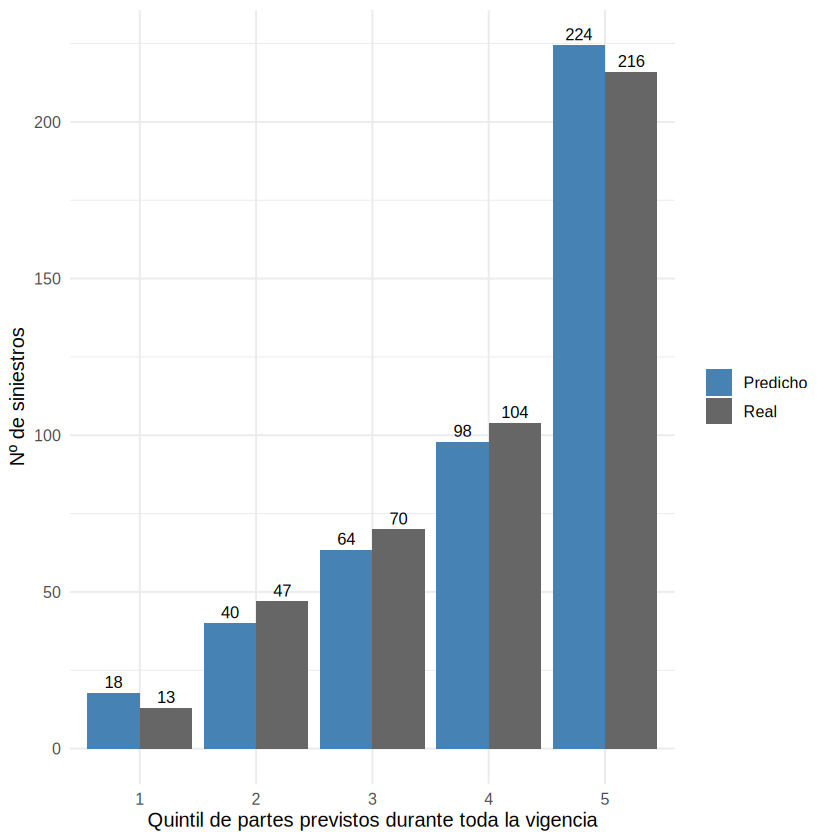

In [ ]:
tabla_lift %>%
  dplyr::select(grupo_riesgo, Real = siniestros_real, Predicho = siniestros_pred) %>%
  pivot_longer(c(Real, Predicho), names_to = "tipo", values_to = "siniestros") %>%
  ggplot(aes(x = factor(grupo_riesgo), y = siniestros, fill = tipo)) +
  geom_col(position = "dodge") +
  geom_text(aes(label = round(siniestros)), position = position_dodge(width = 0.9),
            vjust = -0.4, size = 3.5) +
  scale_fill_manual(values = c(Real = "grey40", Predicho = "steelblue")) +
  labs(x = "Quintil de partes previstos durante toda la vigencia",
       y = "Nº de siniestros", fill = NULL)

El quinto grupo reúne el mayor recuento observado durante toda la vigencia. En él se prevén **224,55 partes frente a 216 observados**. Los quintiles agrupan pólizas por recuento previsto y acumulan tiempos de cobertura diferentes.

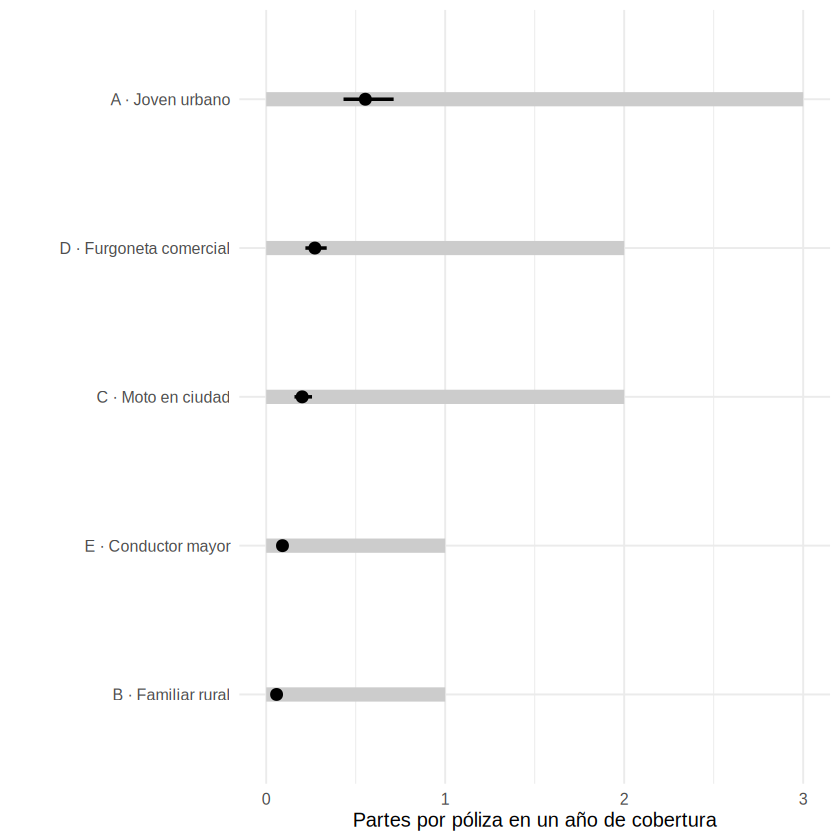

In [ ]:
resultados_tabla24 %>%
  mutate(perfil = fct_reorder(perfil, freq_esperada)) %>%
  ggplot(aes(y = perfil)) +
  geom_linerange(aes(xmin = ip_inf_95, xmax = ip_sup_95),
                 linewidth = 4, colour = "grey80") +
  geom_pointrange(aes(x = freq_esperada, xmin = ic_95_inf, xmax = ic_95_sup),
                  linewidth = 1) +
  labs(x = "Partes por póliza en un año de cobertura", y = NULL)

La barra negra es el intervalo de confianza de la media (base de la prima). La barra gris es el intervalo de predicción de un cliente concreto, mucho más ancho porque incluye la variabilidad individual.

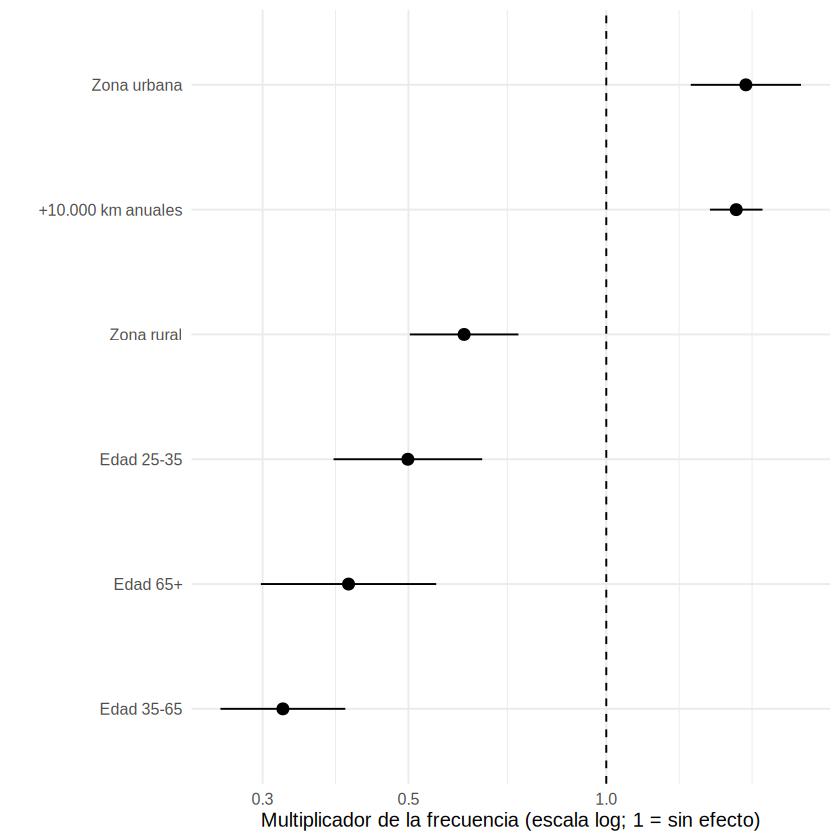

In [ ]:
ef <- as.data.frame(summary(mod_tarifa_nb)$coefficients) %>%
  rownames_to_column("term") %>%
  filter(term != "(Intercept)") %>%
  mutate(
    escala = if_else(term == "km_anuales", 10000, 1),   # km: efecto por cada 10.000 km
    est = Estimate * escala,
    se  = `Std. Error` * escala,
    RR  = exp(est),
    lo  = exp(est - 1.96 * se),
    hi  = exp(est + 1.96 * se),
    etiqueta = case_when(
      term == "km_anuales" ~ "+10.000 km anuales",
      TRUE ~ term %>%
        str_replace("edad_tramo", "Edad ") %>%
        str_replace("zona_circulacion", "Zona ") %>%
        str_replace("uso", "Uso ")
    )
  )

ggplot(ef, aes(x = RR, y = fct_reorder(etiqueta, RR))) +
  geom_vline(xintercept = 1, linetype = "dashed") +
  geom_pointrange(aes(xmin = lo, xmax = hi)) +
  scale_x_log10() +
  labs(x = "Multiplicador de la frecuencia (escala log; 1 = sin efecto)", y = NULL)

**A · Partes esperados.** Para una póliza con \(T_i\) años de cobertura, el modelo NB2 de altas estima:

$$
\widehat{\mu}_{[i]} = T_{[i]}\exp\!\left(
  \widehat{\beta}_0 + \widehat{\beta}_{\mathrm{edad}[i]} +
  \widehat{\beta}_{\mathrm{zona}[i]} +
  \widehat{\beta}_{\mathrm{km}}\,\mathrm{km}_{[i]}
  \right).
$$

En el ajuste, el intercepto es −1,762 y el coeficiente por kilómetro anual es 0,00004552.

**B · Datos de contratación.** La tarifa utiliza edad por tramos, zona y kilómetros anuales. La referencia es 18–25 años y zona mixta. Urbana supone una frecuencia **63,1 % mayor** frente a mixta, y 10.000 km anuales más suponen **57,7 % más** partes esperados, a igualdad de los demás factores.

**C · Evaluación en reserva.** En las 766 pólizas no usadas para ajustar se esperan **443,81 partes frente a 450 observados** durante toda su vigencia. En su primer tramo de cobertura, el contraste actuarial da **105,90 frente a 100**. Se mantiene la escala de primas mientras se verifica la calibración en altas posteriores.

**D · Cinco fichas.** Para un año de cobertura al ritmo medio de la tarifa se estiman **0,554** partes para A, **0,058** para B, **0,201** para C, **0,272** para D y **0,091** para E. La tabla precedente muestra los intervalos de la media y del recuento individual.

Dirección de red territorial. «Algunas agencias parecen tener clientes mucho peores que otras.»

¿Es cosa de la agencia, de la región o de los clientes que les han tocado? ¿Hay alguna agencia en la que debamos intervenir? Y vamos a abrir una agencia, ¿qué siniestralidad debemos prever para sus clientes?

### P3 · Las agencias y sus regiones

> **Nota de integración.** Se utiliza el modelo territorial de Jorge con edad continua, zona, logaritmo del kilometraje y uso. La auditoría de costes aplica este ajuste a las mismas pólizas y valora los partes con el coste medio de la red.

[Fuente de Jorge · P2 y P3](https://github.com/GLM-2026/proy2-07-Cox/blob/f4b52f368eb5958e665c17c5e432ea18a0ac4390/Analisis/Pregunta_2_3_final.qmd#L560)

In [ ]:
# 1. ¿Cuántas pólizas, agencias y regiones hay?
cartera %>%
  summarise(n_polizas  = n(),
            n_agencias = n_distinct(id_agencia),
            n_regiones = n_distinct(id_region))

n_polizas,n_agencias,n_regiones
<int>,<int>,<int>
3062,30,6


Estructura (3.062 pólizas, 30 agencias, 6 regiones). Cada agencia pertenece a una sola región, así que están anidadas. Con 30 agencias hay datos suficientes para estimar cuánto varían entre sí. Con 6 regiones, la variabilidad entre regiones se estimará con mucha menos precisión.

In [ ]:
# 2. ¿Cada agencia pertenece a una sola región? (anidamiento)
cartera %>%
  distinct(id_agencia, id_region) %>%
  count(id_agencia, name = "n_regiones_de_la_agencia") %>%
  count(n_regiones_de_la_agencia)

n_regiones_de_la_agencia,n
<int>,<int>
1,30


In [ ]:
# 3. Tamaño de las agencias (pólizas por agencia)
cartera %>% count(id_agencia, name = "polizas") %>% summary()

   id_agencia       polizas      
 Min.   : 1.00   Min.   : 83.00  
 1st Qu.: 8.25   1st Qu.: 93.25  
 Median :15.50   Median :100.50  
 Mean   :15.50   Mean   :102.07  
 3rd Qu.:22.75   3rd Qu.:109.00  
 Max.   :30.00   Max.   :123.00  

Tamaño de las agencias. En las tablas que has pegado, todas tienen entre 83 y 123 pólizas. No hay agencias diminutas, así que el problema del ruido por falta de datos será menor de lo que temía.

In [ ]:
# 4. Tasa cruda de siniestros por agencia
tasa_agencia <- cartera %>%
  group_by(id_region, id_agencia) %>%
  summarise(polizas = n(),
            expo    = sum(antiguedad),
            sin     = sum(n_siniestros),
            tasa    = sin / expo,
            .groups = "drop")

summary(tasa_agencia$tasa)
head(arrange(tasa_agencia, desc(tasa)), 5)
head(arrange(tasa_agencia, tasa), 5)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.07534 0.12424 0.14054 0.13843 0.14900 0.19935 

id_region,id_agencia,polizas,expo,sin,tasa
<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
6,28,88,351.149,70,0.1993456
5,25,83,389.681,75,0.1924651
1,4,87,336.867,58,0.1721748
1,5,100,382.936,65,0.1697412
6,26,89,340.983,56,0.1642311


id_region,id_agencia,polizas,expo,sin,tasa
<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
2,8,105,451.285,34,0.07534042
1,3,101,431.749,43,0.09959490
5,23,97,405.350,42,0.10361416
6,27,99,440.877,46,0.10433749
1,1,92,404.317,44,0.10882550


Tasas crudas. Van desde 0,075 (agencia 8) hasta 0,199 (agencia 28) siniestros por año de antigüedad, casi 2,6 veces más. Eso es lo que ve la dirección y lo que le hace pensar que hay agencias malas.

Algo interesante: la región 1 aparece entre las peores (agencias 4 y 5) y también entre las mejores (agencias 1 y 3). Lo mismo pasa con las regiones 5 y 6. Esto sugiere que las diferencias no se explican solo por la región, sino que hay mucha variación dentro de cada región. Es una pista, no una conclusión, porque son tasas crudas sin ajustar por clientes.

In [ ]:
# 1. Tasa cruda por región
cartera %>%
  group_by(id_region) %>%
  summarise(polizas = n(), expo = sum(antiguedad),
            sin = sum(n_siniestros), tasa = sin / expo)

# 2. Modelo territorial de Jorge con características del cliente.
mod_cli <- MASS::glm.nb(
    formula_cliente_p3,
    data = cartera
    )

# 3. Siniestros esperados según el cliente vs. reales, por agencia
comparacion <- cartera %>%
  mutate(esperado = fitted(mod_cli)) %>%
  group_by(id_region, id_agencia) %>%
  summarise(real = sum(n_siniestros), esperado = sum(esperado),
            ratio = real / esperado, .groups = "drop")

arrange(comparacion, desc(ratio)) %>% head(5)
arrange(comparacion, ratio) %>% head(5)
summary(comparacion$ratio)

id_region,polizas,expo,sin,tasa
<dbl>,<int>,<dbl>,<dbl>,<dbl>
1,475,1946.014,263,0.1351481
2,531,2231.602,278,0.1245742
3,516,2217.877,333,0.1501436
4,528,2149.165,278,0.1293526
5,510,2244.205,317,0.1412527
6,502,2093.491,301,0.1437790


id_region,id_agencia,real,esperado,ratio
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
5,25,75,51.81500,1.447457
6,28,70,54.91344,1.274733
6,26,56,44.89161,1.247449
1,5,65,53.38251,1.217627
1,4,58,48.02950,1.207591


id_region,id_agencia,real,esperado,ratio
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2,8,34,61.05283,0.5568947
1,3,43,62.19139,0.6914140
6,27,46,59.89324,0.7680333
5,23,42,54.66471,0.7683201
4,19,60,71.73162,0.8364512


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.5569  0.8820  0.9986  1.0094  1.1397  1.4475 

Después de ajustar por las características de los clientes, la razón de partes observados frente a los esperados va de **0,56 a 1,45**. Los mayores valores corresponden a las agencias **25, 28, 26, 5 y 4**. Los menores, a **8, 3, 27, 23 y 19**.

Las agencias **8 y 25** quedan fuera de las bandas puntuales aproximadas del 95 % del gráfico del QMD. Con 30 oficinas, estos cruces son compatibles con la variabilidad del recuento. El contraste global y la auditoría de costes permiten decidir qué seguimiento conviene.

In [ ]:
cargar_paquetes(c("glmmTMB"))

mod_mixto <- glmmTMB(
  update(formula_cliente_p3, . ~ . + (1 | id_region / id_agencia)),
  family = nbinom2, data = cartera, REML = TRUE
)

summary(mod_mixto)

# Desviaciones típicas de los efectos aleatorios
VarCorr(mod_mixto)

 Family: nbinom2  ( log )
Formula:          
n_siniestros ~ edad_conductor + zona_circulacion + log(km_anuales) +  
    uso + (1 | id_region/id_agencia) + offset(log(antiguedad))
Data: cartera

      AIC       BIC    logLik -2*log(L)  df.resid 
   5711.5    5765.8   -2846.8    5693.5      3053 

Random effects:

Conditional model:
 Groups               Name        Variance  Std.Dev. 
 id_agencia:id_region (Intercept) 4.010e-09 6.333e-05
 id_region            (Intercept) 3.337e-04 1.827e-02
Number of obs: 3062, groups:  id_agencia:id_region, 30; id_region, 6

Dispersion parameter for nbinom2 family (): 0.887 

Conditional model:
                       Estimate Std. Error z value Pr(>|z|)    
(Intercept)            -7.86698    0.65060 -12.092  < 2e-16 ***
edad_conductor         -0.01723    0.00221  -7.794 6.51e-15 ***
zona_circulacionrural  -0.47290    0.08445  -5.600 2.15e-08 ***
zona_circulacionurbana  0.63097    0.08554   7.376 1.63e-13 ***
log(km_anuales)         0.71913    0.06776  


Conditional model:
 Groups               Name        Std.Dev.  
 id_agencia:id_region (Intercept) 6.3325e-05
 id_region            (Intercept) 1.8266e-02

In [ ]:
# Misma parte fija en los tres; solo cambia la parte aleatoria
f_fija <- formula_cliente_p3

m0  <- glmmTMB(f_fija, family = nbinom2, data = cartera, REML = TRUE)
mA  <- update(m0, . ~ . + (1 | id_agencia))
mAR <- update(m0, . ~ . + (1 | id_region/id_agencia))

VarCorr(mA)
AIC(m0, mA, mAR)
anova(m0, mA)

# Segunda opinión: agencia como efecto fijo (contraste clásico de razón de verosimilitudes)
f_glm <- formula_cliente_p3
g_sin <- mod_cli
g_fijo <- glm.nb(update(f_glm, . ~ . + factor(id_agencia)), data = cartera)
anova(g_sin, g_fijo)


Conditional model:
 Groups     Name        Std.Dev.  
 id_agencia (Intercept) 6.3061e-05

,df,AIC
,<dbl>,<dbl>
m0,7,5707.554
mA,8,5709.554
mAR,9,5711.547


,Df,AIC,BIC,logLik,deviance,Chisq,Chi Df,Pr(>Chisq)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
m0,7,5707.554,5749.741,-2846.777,5693.554,NA,NA,NA
mA,8,5709.554,5757.768,-2846.777,5693.554,0,1,1


Model,theta,Resid. df,2 x log-lik.,Test,df,LR stat.,Pr(Chi)
<chr>,<dbl>,<int>,<dbl>,<chr>,<int>,<dbl>,<dbl>
edad_conductor + zona_circulacion + log(km_anuales) + uso + offset(log(antiguedad)),0.894546,3056,-5665.366,,NA,NA,NA
edad_conductor + zona_circulacion + log(km_anuales) + uso + factor(id_agencia) + offset(log(antiguedad)),0.938226,3027,-5640.659,1 vs 2,29,24.70657,0.6933806


In [ ]:
# Cartera tipo: la de las 30 agencias actuales, un año de cobertura.
cart_nueva <- cartera %>%
  mutate(antiguedad = 1)

# Frecuencia media por póliza y total esperado para una agencia de tamaño medio
n_medio <- round(nrow(cartera) / n_distinct(cartera$id_agencia))   # ~102 pólizas
pred <- predict(g_sin, newdata = cart_nueva, type = "response")
freq_media <- mean(pred)

c(freq_por_poliza = freq_media,
  partes_esperados_agencia = freq_media * n_medio)

# Intervalo para el total de una agencia nueva: simulación que incluye
# (a) ruido de Poisson-gamma de cada póliza y (b) un posible efecto agencia
# de sd = 0.15 (hipótesis prudente, no estimada: los datos dan ~0)
n_sim <- 10000
sim <- withr::with_seed(
    SEMILLA_CURSO,
    replicate(n_sim, {
        u <- rnorm(1, 0, 0.15)
        mu <- sample(pred, n_medio, replace = TRUE) * exp(u)
        sum(rnbinom(n_medio, size = g_sin$theta, mu = mu))
        })
    )
quantile(sim, c(0.025, 0.5, 0.975))

freq_por_poliza partes_esperados_agencia 
               0.1402552               14.3060257

2.5%   50% 97.5% 
    6    14    25

**¿Es cosa de la agencia, de la región o de los clientes?** Tras ajustar por el perfil de la cartera, el contraste global de frecuencia da **p = 0,69** para agencia. La variación estimada entre oficinas es muy pequeña y la de región es imprecisa con seis regiones.

**¿Qué oficinas conviene vigilar?** Los mayores cocientes de partes observados frente a los esperados son los de **25, 28 y 26**. Esto orienta el seguimiento de la frecuencia. Para decidir qué expedientes revisar primero, el [contraste actuarial](#scrollTo=7L4KGnr5VWas) compara los costes con el mismo ajuste de frecuencia.

**¿Cuántos partes cabe prever en una apertura?** Para **102 pólizas con un año de cobertura**, la previsión central es de unos **14 partes**. La simulación prudente da un intervalo predictivo del 95 % de **6 a 25 partes**. Incluye una desviación típica de oficina de 0,15 en escala logarítmica como supuesto de planificación.

### Exploración preliminar · Tabla de cuatro vías
Este archivo, incorporado por Jorge, sigue un enunciado anterior. Se incluyen sus bloques analíticos de preparación y cruce.

[Fuente del equipo · resolucion_ec2.qmd](https://github.com/GLM-2026/proy2-07-Cox/blob/cdef3b955446119c48c1e976365019c6e915dfa4/Analisis/resolucion_ec2.qmd)

In [ ]:
set.seed(SEMILLA_CURSO)
cartera <- cartera_original

In [ ]:
# Factores con referencia explícita
cartera <- cartera |>
  mutate(
    edad_tramo       = factor(edad_tramo, levels = c("18-25","25-35","35-65","65+")),
    zona_circulacion = relevel(factor(zona_circulacion), ref = "urbana"),
    uso              = relevel(factor(uso),              ref = "particular"),
    tipo_vehiculo    = relevel(factor(tipo_vehiculo),    ref = "turismo"),
    combustible      = relevel(factor(combustible),      ref = "gasolina"),
    sexo             = factor(sexo),
    id_agencia       = factor(id_agencia),
    id_region        = factor(id_region),
    bonus_malus_prev = factor(bonus_malus_prev, levels = 1:5),
    bonus_malus_act  = factor(bonus_malus_act,  levels = 1:5)
  )

# Estandarización de continuos (guardamos media y DE para predecir perfiles nuevos)
vars_z <- c(carnet = "antiguedad_carnet", pot = "potencia_cv",
            antv = "antiguedad_vehiculo", km = "km_anuales", dens = "densidad")
centros <- sapply(vars_z, function(v) mean(cartera[[v]]))
escalas <- sapply(vars_z, function(v) sd(cartera[[v]]))
for (nm in names(vars_z))
  cartera[[paste0("z_", nm)]] <- (cartera[[vars_z[nm]]] - centros[nm]) / escalas[nm]

# Helper para construir el perfil de una póliza nueva en la misma escala z
z_de <- function(nm, valor_bruto) (valor_bruto - centros[nm]) / escalas[nm]

Cruce exploratorio de parte, combustible, tipo de vehículo y zona.

In [ ]:
tabla = xtabs(~tuvo_siniestro + combustible + tipo_vehiculo + zona_circulacion, data = cartera)
tabla_df = as.data.frame(tabla)
fit_ind = glm(Freq ~ (tuvo_siniestro + tipo_vehiculo + zona_circulacion)^2, family = poisson, data = tabla_df)
fit_dobles = glm(Freq ~ (tuvo_siniestro + tipo_vehiculo + zona_circulacion)^3, family = poisson, data = tabla_df)


# Función auxiliar apuntando al data frame correcto (tabla_df)
f <- function(fml) glm(fml, family = poisson, data = tabla_df)

# Lista de modelos log-lineales jerárquicos
mods <- list(
  mutua    = f(Freq ~ tuvo_siniestro + combustible + tipo_vehiculo + zona_circulacion),
  dobles   = f(Freq ~ (tuvo_siniestro + combustible + tipo_vehiculo + zona_circulacion)^2),
  triples  = f(Freq ~ (tuvo_siniestro + combustible + tipo_vehiculo + zona_circulacion)^3),
  saturado = f(Freq ~ tuvo_siniestro * combustible * tipo_vehiculo * zona_circulacion)
)

purrr::map_dfr(names(mods), ~ {
  m <- mods[[.x]]; gl <- df.residual(m)
  tibble::tibble(
    modelo   = .x,
    gl       = gl,
    deviance = round(deviance(m), 2),
    # el saturado no tiene gl residuales: no hay contraste de ajuste que hacerle
    p_ajuste = if (gl > 0) round(pchisq(deviance(m), gl, lower.tail = FALSE), 4) else NA_real_,
    AIC      = round(AIC(m), 1))})

drop1(mods$dobles, test = "LRT")
fit = update(mods$dobles,.~.-tuvo_siniestro:combustible)
drop1(fit, test = "LRT")#quitando los no significativos
fit = update(fit,.~.-combustible:zona_circulacion)
drop1(fit, test = "LRT")
fit = update(fit,.~.-tuvo_siniestro:tipo_vehiculo)
drop1(fit, test = "LRT")
#seguimos quitando datos no signicativos hasta que tengamos los necesarios

summary(fit)

modelo,gl,deviance,p_ajuste,AIC
<chr>,<int>,<dbl>,<dbl>,<dbl>
mutua,29,101.02,0.0000,318.5
dobles,16,10.88,0.8169,254.4
triples,4,0.65,0.9573,268.2
saturado,0,0.00,NA,275.5


,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,10.87861,254.4091,NA,NA
tuvo_siniestro:combustible,1,11.07581,252.6063,0.1971964,6.569934e-01
tuvo_siniestro:tipo_vehiculo,2,14.39359,253.9241,3.5149785,1.724774e-01
tuvo_siniestro:zona_circulacion,2,75.81068,315.3412,64.9320648,7.946599e-15
combustible:tipo_vehiculo,2,11.75814,251.2886,0.8795331,6.441868e-01
combustible:zona_circulacion,2,24.97259,264.5031,14.0939788,8.700243e-04
tipo_vehiculo:zona_circulacion,4,16.45277,251.9833,5.5741564,2.332876e-01


,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,11.07581,252.6063,NA,NA
tuvo_siniestro:tipo_vehiculo,2,14.59216,252.1226,3.5163488,1.723592e-01
tuvo_siniestro:zona_circulacion,2,75.81937,313.3499,64.7435605,8.732015e-15
combustible:tipo_vehiculo,2,11.95671,249.4872,0.8809035,6.437456e-01
combustible:zona_circulacion,2,24.98128,262.5118,13.9054745,9.560147e-04
tipo_vehiculo:zona_circulacion,4,16.65663,250.1871,5.5808192,2.327162e-01


,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,24.98128,262.5118,NA,NA
tuvo_siniestro:tipo_vehiculo,2,28.49763,262.0281,3.516349,1.723592e-01
tuvo_siniestro:zona_circulacion,2,89.72484,323.2553,64.743561,8.732015e-15
combustible:tipo_vehiculo,2,26.20138,259.7319,1.220098,5.433242e-01
tipo_vehiculo:zona_circulacion,4,30.89476,260.4253,5.913481,2.057034e-01


,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,28.49763,262.0281,NA,NA
tuvo_siniestro:zona_circulacion,2,93.56168,323.0922,65.064047,7.439122e-15
combustible:tipo_vehiculo,2,29.71773,259.2482,1.220098,5.433242e-01
tipo_vehiculo:zona_circulacion,4,34.73160,260.2621,6.233967,1.823435e-01



Call:
glm(formula = Freq ~ tuvo_siniestro + combustible + tipo_vehiculo + 
    zona_circulacion + tuvo_siniestro:zona_circulacion + combustible:tipo_vehiculo + 
    tipo_vehiculo:zona_circulacion, family = poisson, data = tabla_df)

Coefficients:
                                             Estimate Std. Error z value
(Intercept)                                   4.32186    0.07598  56.881
tuvo_siniestro1                              -0.17456    0.09738  -1.792
combustiblediesel                             0.18891    0.04204   4.493
tipo_vehiculofurgoneta                       -1.40532    0.14351  -9.792
tipo_vehiculomoto                            -1.87723    0.16725 -11.224
zona_circulacionmixta                         1.72160    0.07896  21.804
zona_circulacionrural                         1.06199    0.08488  12.511
tuvo_siniestro1:zona_circulacionmixta        -0.61905    0.10983  -5.636
tuvo_siniestro1:zona_circulacionrural        -1.02471    0.12752  -8.036
combustiblediesel:tipo

## Salvador Cabanes
El historial registra su aportación «P5 completa» en el commit [ce34ac3](https://github.com/GLM-2026/proy2-07-Cox/commit/ce34ac3).

### P5 · Antigüedad, fragilidad e historial
*Nota de integración.* Se conserva el ajuste de Salvador con intercepto aleatorio por póliza y sus tres perfiles ilustrativos. Para la entrega final, el enunciado solicita las cinco fichas oficiales. En el gráfico de cliente nuevo, la banda amplia representa variación de la **tasa latente** entre pólizas. Un intervalo para el **conteo** individual requiere simular además los partes.

[Fuente del equipo · P5_riesgos_a_trozos.qmd](https://github.com/GLM-2026/proy2-07-Cox/blob/97340b678ce6f541d30f2a464ed4e1fe4ba3396e/Analisis/P5_riesgos_a_trozos.qmd)

«Queremos decidir qué ofrecer a cada cliente según el tiempo que lleva con nosotros.»

Preguntas: (1) ¿Un cliente da más, menos o los mismos partes a medida que acumula antigüedad? (2) ¿Debe reflejarse en el precio de la renovación? (3) ¿Cuántos partes esperamos de cada cliente tipo en cada etapa? (4) De un cliente ya conocido, ¿esperamos lo mismo que de uno nuevo con su misma ficha, o debe pesar su historial?

Variable respuesta: n_partes_anual (panel), con offset de log(expo_anual). Las características del cliente se unen desde cartera.csv por id_poliza.

Idea del análisis: el offset de P2 supone que el cliente da partes al mismo ritmo toda su vida con la aseguradora. Aquí se pone a prueba esa hipótesis con un modelo de riesgos a trozos (tasa constante dentro de cada tramo de antigüedad) y un efecto aleatorio por póliza.

Nota sobre las cifras: los comentarios citan resultados obtenidos replicando el modelo por máxima verosimilitud; pueden diferir en el último decimal de lo que muestre glmmTMB al ejecutarlo.

#### 1. Datos

In [ ]:
cargar_paquetes(c("broom", "patchwork"))

set.seed(SEMILLA_CURSO)
cartera <- cartera_original

In [ ]:
# Columnas repetidas entre panel y cartera (aparte de id_poliza)
cols_repetidas <- setdiff(intersect(names(panel), names(cartera)), "id_poliza")

panel_completo <- panel %>%
  left_join(cartera %>% dplyr::select(-all_of(cols_repetidas)), by = "id_poliza")

stopifnot(nrow(panel_completo) == nrow(panel))

# antigüedad total del cliente siempre numérica
panel_completo$antiguedad <- as.numeric(as.character(panel_completo$antiguedad))

glimpse(panel_completo)

Rows: 14,444
Columns: 48
$ id_poliza           <dbl> 1, 1, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 4, 4,…
$ anio                <dbl> 1, 2, 1, 2, 3, 4, 5, 6, 7, 1, 2, 3, 4, 5, 6, 1, 2,…
$ tstart              <dbl> 0, 1, 0, 1, 2, 3, 4, 5, 6, 0, 1, 2, 3, 4, 5, 0, 1,…
$ tstop               <dbl> 1.000, 1.082, 1.000, 2.000, 3.000, 4.000, 5.000, 6…
$ expo_anual          <dbl> 1.000, 0.082, 1.000, 1.000, 1.000, 1.000, 1.000, 1…
$ n_partes_anual      <dbl> 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 2, 0, 0, 0, 0, 0,…
$ edad_t              <dbl> 33, 34, 44, 45, 46, 47, 48, 49, 50, 62, 63, 64, 65…
$ antig_veh_t         <dbl> 6, 7, 12, 13, 14, 15, 16, 17, 18, 6, 7, 8, 9, 10, …
$ en_riesgo           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ id_agencia          <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ id_region           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ antiguedad          <dbl> 1.082, 1.082, 6.687, 6.687, 6.687, 6.687, 6.687, 6…
$ exposicion   

Resultado. El panel tiene una fila por póliza y año de antigüedad, y la unión con la cartera no pierde ni duplica filas.

Por tanto, se puede trabajar con el panel completo.

#### 2. Análisis exploratorio: tasa empírica por año

In [ ]:
dplyr::count(panel_completo, n_partes_anual)

n_partes_anual,n
<dbl>,<int>
0,12932
1,1297
2,179
3,30
4,5
5,1


#### Exposición y cortes de antigüedad

In [ ]:
tasa_anio <- panel_completo |>
  dplyr::group_by(anio) |>
  dplyr::summarise(filas      = dplyr::n(),
                   exposicion = round(sum(expo_anual), 1),
                   partes     = sum(n_partes_anual),
                   tasa       = round(partes / exposicion, 3),
                   media_fila = round(mean(n_partes_anual), 3))
tasa_anio

anio,filas,exposicion,partes,tasa,media_fila
<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,3062,3009.5,345,0.115,0.113
2,2942,2672.4,394,0.147,0.134
3,2404,2132.4,291,0.136,0.121
4,1861,1639.3,242,0.148,0.130
5,1443,1244.3,173,0.139,0.120
6,1061,895.7,144,0.161,0.136
7,744,624.4,93,0.149,0.125
8,502,388.4,52,0.134,0.104
9,292,208.8,26,0.125,0.089


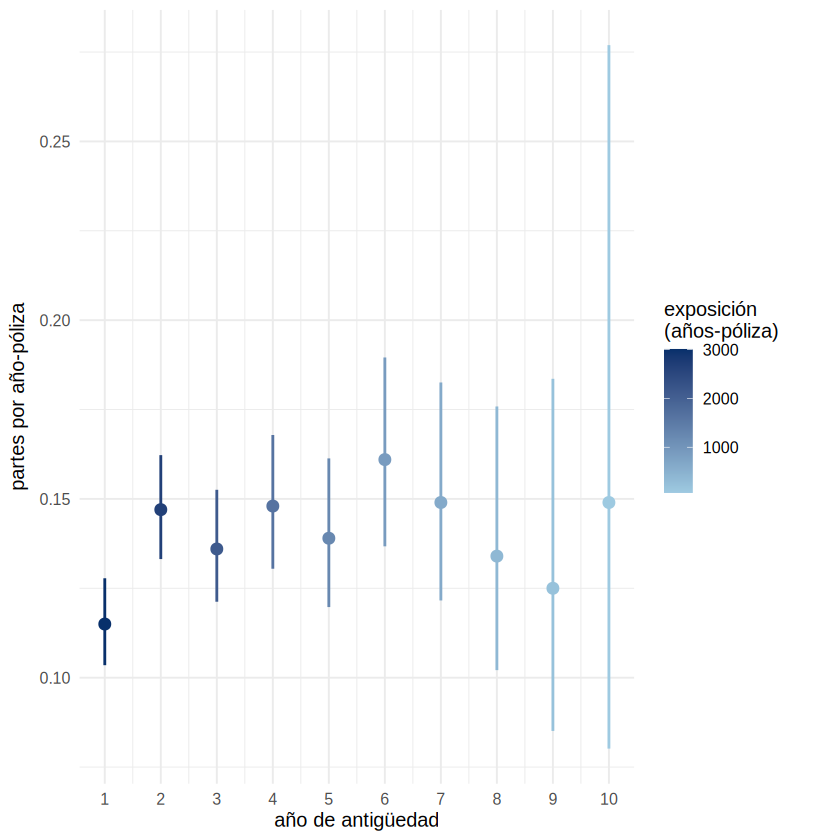

In [ ]:
tasa_anio |>
  dplyr::mutate(inf = tasa * exp(-1.96 / sqrt(partes)),
                sup = tasa * exp( 1.96 / sqrt(partes))) |>
  ggplot(aes(anio, tasa, colour = exposicion)) +
  geom_pointrange(aes(ymin = inf, ymax = sup), linewidth = 0.8) +
  scale_colour_gradient(low = "#9ecae1", high = "#08306b") +
  scale_x_continuous(breaks = 1:10) +
  labs(x = "año de antigüedad", y = "partes por año-póliza",
       colour = "exposición\n(años-póliza)")

Resultado. El primer año tiene la tasa más baja (0,115 partes por año-póliza) y después se mueve en torno a 0,14 sin una tendencia clara. En los últimos años hay poca exposición y los intervalos son muy anchos.

Por tanto, la diferencia entre etapas parece moderada y comparable al ruido de cada año. Se contrasta formalmente más adelante.

#### 3. Definición de los trozos

Criterio (fijado antes de ajustar): cada trozo debe tener al menos 200 partes (error relativo de la tasa: 1 dividido por la raíz de 200, es decir, un 7 % aproximadamente). Los años 1 a 4 lo cumplen por separado y los años 5 a 10, con poca exposición, se agrupan en un único trozo.

In [ ]:
cortes    <- c(0:4, 10)                          # bordes de los trozos, en años
etiquetas <- c(as.character(1:4), "5-10")
limites   <- cortes                              # lo usan los chunks posteriores

panel_completo <- panel_completo |>
  dplyr::mutate(trozo = cut(anio, breaks = cortes, labels = etiquetas))
panel_completo$trozo <- factor(panel_completo$trozo, levels = etiquetas)

tasa_trozo <- panel_completo |>
  dplyr::group_by(trozo) |>
  dplyr::summarise(partes = sum(n_partes_anual),
                   tasa   = round(partes / sum(expo_anual), 3)) |>
  dplyr::mutate(cumple_200 = partes >= 200)
tasa_trozo

trozo,partes,tasa,cumple_200
<fct>,<dbl>,<dbl>,<lgl>
1,345,0.115,TRUE
2,394,0.147,TRUE
3,291,0.136,TRUE
4,242,0.148,TRUE
5-10,498,0.145,TRUE


Resultado. Los cinco trozos superan los 200 partes (el mínimo es 242).

Por tanto, los trozos son lo bastante precisos y se mantienen.

In [ ]:
tercil <- function(x) factor(dplyr::ntile(x, 3), labels = c("bajo", "medio", "alto"))

clientes_t <- panel_completo |>
  dplyr::distinct(id_poliza, edad_conductor, antiguedad_carnet, potencia_cv) |>
  dplyr::transmute(id_poliza, edad = tercil(edad_conductor),
                   carnet = tercil(antiguedad_carnet), potencia = tercil(potencia_cv))
panel_t <- dplyr::left_join(panel_completo, clientes_t, by = "id_poliza")

predictores <- c(edad = "edad", carnet = "carnet", potencia = "potencia",
                 zona = "zona_circulacion", uso = "uso", vehiculo = "tipo_vehiculo",
                 sexo = "sexo")

tasa_xt <- purrr::imap_dfr(predictores, \(v, nombre) panel_t |>
  dplyr::group_by(trozo, nivel = as.character(.data[[v]])) |>
  dplyr::summarise(partes = sum(n_partes_anual), tasa = partes / sum(expo_anual),
                   .groups = "drop") |>
  dplyr::mutate(predictor = nombre)) |>
  dplyr::mutate(nivel = forcats::fct_relevel(nivel,
                  intersect(c("bajo", "medio", "alto"), unique(nivel))))

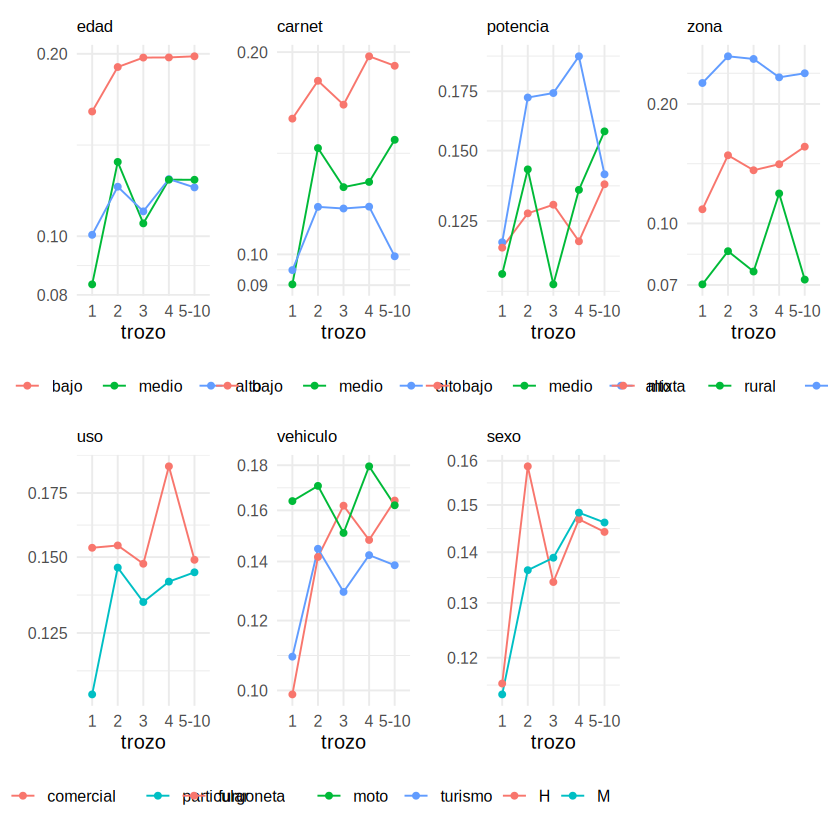

In [ ]:
patchwork::wrap_plots(purrr::map(names(predictores), \(p)
  ggplot(dplyr::filter(tasa_xt, predictor == p),
         aes(trozo, tasa, colour = nivel, group = nivel)) +
    geom_line() +
    geom_point(size = 1.5) +
    scale_y_log10() +
    labs(title = p, x = "trozo", y = NULL, colour = NULL) +
    theme(legend.position = "bottom", plot.title = element_text(size = 10))),
  ncol = 4)

Resultado. Las líneas de cada variable sirven de pista visual sobre si su efecto cambia con la antigüedad. El contraste formal de la sección 8 no encuentra cambios.

Por tanto, se supone de momento que cada característica actúa igual en todas las etapas.

#### 4. Modelo de riesgos a trozos (Poisson, sin efecto aleatorio)

In [ ]:
panel_completo <- panel_completo |>
  dplyr::mutate(edad_10     = edad_conductor / 10,
                carnet_10   = antiguedad_carnet / 10,
                potencia_10 = potencia_cv / 10)

m_pw <- glm(
  n_partes_anual ~ trozo + edad_10 + carnet_10 + potencia_10 + zona_circulacion +
    uso + tipo_vehiculo + sexo + offset(log(expo_anual)),
  family = poisson, data = panel_completo)

summary(m_pw)


Call:
glm(formula = n_partes_anual ~ trozo + edad_10 + carnet_10 + 
    potencia_10 + zona_circulacion + uso + tipo_vehiculo + sexo + 
    offset(log(expo_anual)), family = poisson, data = panel_completo)

Coefficients:
                        Estimate Std. Error z value Pr(>|z|)    
(Intercept)            -1.668852   0.154396 -10.809  < 2e-16 ***
trozo2                  0.256150   0.073736   3.474 0.000513 ***
trozo3                  0.189202   0.079608   2.377 0.017469 *  
trozo4                  0.272886   0.083891   3.253 0.001143 ** 
trozo5-10               0.249341   0.070090   3.557 0.000374 ***
edad_10                -0.144024   0.034909  -4.126 3.70e-05 ***
carnet_10              -0.056056   0.046071  -1.217 0.223711    
potencia_10             0.033536   0.006502   5.157 2.50e-07 ***
zona_circulacionrural  -0.524818   0.066844  -7.851 4.11e-15 ***
zona_circulacionurbana  0.591742   0.056943  10.392  < 2e-16 ***
usoparticular          -0.185308   0.064704  -2.864 0.004184 ** 

In [ ]:
tab_pw <- broom::tidy(m_pw, exponentiate = TRUE, conf.int = TRUE) |>
  dplyr::transmute(termino = term, razon = round(estimate, 3),
                   inf = round(conf.low, 3), sup = round(conf.high, 3),
                   p = signif(p.value, 2))
tab_pw

termino,razon,inf,sup,p
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),0.188,0.139,0.255,3.1e-27
trozo2,1.292,1.118,1.493,5.1e-04
trozo3,1.208,1.033,1.412,1.7e-02
trozo4,1.314,1.114,1.547,1.1e-03
trozo5-10,1.283,1.119,1.473,3.7e-04
edad_10,0.866,0.808,0.927,3.7e-05
carnet_10,0.945,0.864,1.035,2.2e-01
potencia_10,1.034,1.021,1.047,2.5e-07
zona_circulacionrural,0.592,0.518,0.673,4.1e-15


Resultado. Frente al primer año, el resto de trozos tiene entre un 20 % y un 30 % más de frecuencia. Zona, edad, potencia y uso también influyen.

Por tanto, la antigüedad influye, pero este modelo trata como independientes las filas de una misma póliza y sus errores no son fiables. Se añade un efecto aleatorio por póliza.

#### 5. Efecto aleatorio por póliza

In [ ]:
cargar_paquetes(c("glmmTMB"))

m_pw_mix <- glmmTMB::glmmTMB(
  n_partes_anual ~ trozo + edad_10 + carnet_10 + potencia_10 + zona_circulacion +
    uso + tipo_vehiculo + sexo + offset(log(expo_anual)) + (1 | id_poliza),
  family = poisson, data = panel_completo)

sigma_pol <- sqrt(glmmTMB::VarCorr(m_pw_mix)$cond$id_poliza[1])
lrt_pol   <- 2 * (as.numeric(logLik(m_pw_mix)) - as.numeric(logLik(m_pw)))

In [ ]:
tab_mix <- tibble::tibble(
  termino   = names(coef(m_pw))[-1],
  razon     = round(exp(coef(m_pw))[-1], 3),
  ee        = round(sqrt(diag(vcov(m_pw)))[-1], 3),
  razon_mix = round(exp(glmmTMB::fixef(m_pw_mix)$cond)[names(coef(m_pw))[-1]], 3),
  ee_mix    = round(sqrt(diag(vcov(m_pw_mix)$cond))[names(coef(m_pw))[-1]], 3))
tab_mix

termino,razon,ee,razon_mix,ee_mix
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
trozo2,1.292,0.074,1.296,0.074
trozo3,1.208,0.080,1.211,0.081
trozo4,1.314,0.084,1.340,0.086
trozo5-10,1.283,0.070,1.345,0.075
edad_10,0.866,0.035,0.890,0.049
carnet_10,0.945,0.046,0.942,0.065
potencia_10,1.034,0.007,1.034,0.010
zona_circulacionrural,0.592,0.067,0.610,0.090
zona_circulacionurbana,1.807,0.057,1.862,0.094


Resultado. Hay mucha heterogeneidad entre pólizas (contraste significativo) y los coeficientes apenas cambian.

Por tanto, se conserva el modelo con efecto aleatorio.

#### 6. Selección de variables

In [ ]:
seleccion <- dplyr::full_join(
  tibble::as_tibble(drop1(m_pw, test = "Chisq"), rownames = "variable") |>
    dplyr::select(variable, gl = Df, p_glm = `Pr(>Chi)`),
  tibble::as_tibble(drop1(m_pw_mix, test = "Chisq"), rownames = "variable") |>
    dplyr::select(variable, chi2_mixto = LRT, p_mixto = `Pr(>Chi)`),
  by = "variable") |>
  dplyr::filter(variable != "<none>") |>
  dplyr::mutate(chi2_mixto = round(chi2_mixto, 2),
                dplyr::across(c(p_glm, p_mixto), \(x) signif(x, 2)))
seleccion

variable,gl,p_glm,chi2_mixto,p_mixto
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
trozo,4,1.1e-03,20.78,3.5e-04
edad_10,1,2.7e-05,5.65,1.7e-02
carnet_10,1,2.2e-01,0.86,3.5e-01
potencia_10,1,2.9e-07,11.33,7.6e-04
zona_circulacion,2,9.9e-49,96.72,1.0e-21
uso,1,5.0e-03,5.08,2.4e-02
tipo_vehiculo,2,6.2e-03,4.15,1.3e-01
sexo,1,5.6e-01,0.58,4.5e-01


Se eliminan las variables con p_mixto mayor que 0,05 (el trozo se conserva siempre, porque es el objeto del estudio). El efecto aleatorio se mantiene.

In [ ]:
fuera <- setdiff(seleccion$variable[seleccion$p_mixto > 0.05], "trozo")
fuera

m_pw_fin <- if (length(fuera) > 0) {
  update(m_pw_mix, as.formula(paste(". ~ . -", paste(fuera, collapse = " - "))))
} else m_pw_mix

summary(m_pw_fin)

[1] "carnet_10"     "tipo_vehiculo" "sexo"

 Family: poisson  ( log )
Formula:          
n_partes_anual ~ trozo + edad_10 + potencia_10 + zona_circulacion +  
    uso + (1 | id_poliza) + offset(log(expo_anual))
Data: panel_completo

      AIC       BIC    logLik -2*log(L)  df.resid 
  10294.8   10378.2   -5136.4   10272.8     14433 

Random effects:

Conditional model:
 Groups    Name        Variance Std.Dev.
 id_poliza (Intercept) 1.184    1.088   
Number of obs: 14444, groups:  id_poliza, 3062

Conditional model:
                        Estimate Std. Error z value Pr(>|z|)    
(Intercept)            -2.254483   0.190183 -11.854  < 2e-16 ***
trozo2                  0.258706   0.074086   3.492 0.000479 ***
trozo3                  0.190478   0.080728   2.360 0.018299 *  
trozo4                  0.292012   0.085876   3.400 0.000673 ***
trozo5-10               0.295070   0.074975   3.936 8.30e-05 ***
edad_10                -0.157521   0.024394  -6.457 1.07e-10 ***
potencia_10             0.033851   0.009884   3.425 0.000615 ***
zon

Resultado. Salen del modelo la antigüedad del carnet, el tipo de vehículo y el sexo. Se mantienen trozo, edad, potencia, zona y uso.

Por tanto, el modelo final es este, con efecto aleatorio por póliza.

#### 7. Predicción por perfiles y estructura temporal

In [ ]:
medianas <- panel_completo |>
  dplyr::distinct(id_poliza, edad_conductor, antiguedad_carnet, potencia_cv) |>
  dplyr::summarise(dplyr::across(-id_poliza, median))

perfiles <- tibble::tibble(
  perfil           = c("joven_urbano", "mediano", "veterano_rural"),
  edad_10          = c(2.5, medianas$edad_conductor / 10, 6),
  carnet_10        = c(0.5, medianas$antiguedad_carnet / 10, 3.5),
  potencia_10      = c(16, medianas$potencia_cv / 10, 9),
  zona_circulacion = c("urbana", "urbana", "rural"),
  uso              = "particular",
  tipo_vehiculo    = "turismo",
  sexo             = "H",
  expo_anual       = 1)

pred <- tidyr::crossing(
  perfiles,
  trozo = factor(levels(panel_completo$trozo), levels = levels(panel_completo$trozo)))

pred$tasa <- predict(m_pw, newdata = pred, type = "response")

pred_tabla <- pred |>
  dplyr::select(trozo, perfil, tasa) |>
  tidyr::pivot_wider(names_from = perfil, values_from = tasa) |>
  dplyr::mutate(dplyr::across(where(is.numeric), \(x) round(x, 3)))
pred_tabla

trozo,joven_urbano,mediano,veterano_rural
<fct>,<dbl>,<dbl>,<dbl>
1,0.322,0.191,0.043
2,0.416,0.246,0.055
3,0.389,0.230,0.051
4,0.423,0.251,0.056
5-10,0.413,0.245,0.055


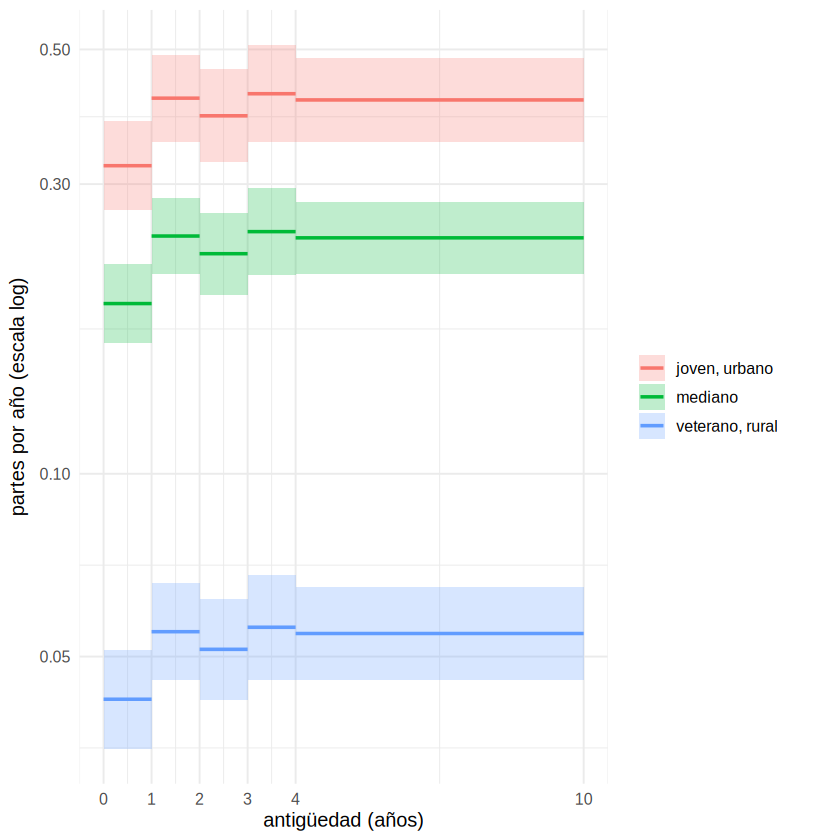

In [ ]:
ic <- predict(m_pw, newdata = pred, type = "link", se.fit = TRUE)

pred |>
  dplyr::mutate(inf = exp(ic$fit - 1.96 * ic$se.fit),
                sup = exp(ic$fit + 1.96 * ic$se.fit),
                desde = limites[as.integer(trozo)],
                hasta = limites[as.integer(trozo) + 1]) |>
  ggplot() +
  geom_rect(aes(xmin = desde, xmax = hasta, ymin = inf, ymax = sup, fill = perfil),
            alpha = 0.25) +
  geom_segment(aes(x = desde, xend = hasta, y = tasa, yend = tasa, colour = perfil),
               linewidth = 1) +
  scale_y_log10() +
  scale_x_continuous(breaks = limites) +
  scale_colour_discrete(labels = c("joven, urbano", "mediano", "veterano, rural"),
                        aesthetics = c("colour", "fill")) +
  labs(x = "antigüedad (años)", y = "partes por año (escala log)",
       colour = NULL, fill = NULL)

Resultado. Las curvas de los tres perfiles son paralelas en escala logarítmica, porque el modelo es multiplicativo.

Por tanto, es solo una primera aproximación; la predicción definitiva, con efecto aleatorio, está en la sección 11.

##### Tendencia lineal frente a trozos

In [ ]:
t_medio <- function(trozo) ((head(limites, -1) + tail(limites, -1)) / 2)[as.integer(trozo)]
panel_completo$t_mid <- t_medio(panel_completo$trozo)

m_lin     <- update(m_pw_fin, . ~ . - trozo + t_mid)
gamma_lin <- glmmTMB::fixef(m_lin)$cond["t_mid"]
ee_gamma  <- sqrt(vcov(m_lin)$cond["t_mid", "t_mid"])
cmp_lin   <- anova(m_lin, m_pw_fin)

In [ ]:
tab_lin <- tibble::tibble(
  modelo     = c("tendencia lineal", "trozos"),
  parametros = cmp_lin$Df,
  AIC        = round(cmp_lin$AIC, 1),
  logLik     = round(cmp_lin$logLik, 1),
  chi2       = c(NA, round(cmp_lin$Chisq[2], 2)),
  gl         = c(NA, cmp_lin$`Chi Df`[2]),
  p          = c(NA, round(cmp_lin$`Pr(>Chisq)`[2], 3)))
tab_lin

modelo,parametros,AIC,logLik,chi2,gl,p
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
tendencia lineal,8,10300.1,-5142.0,NA,NA,NA
trozos,11,10294.8,-5136.4,11.24,3,0.01


Resultado. Con una tendencia lineal el riesgo aumenta algo más de un 3 % por año, un efecto pequeño pero detectable (p = 0,002). Los trozos ajustan algo mejor que la recta (p = 0,009).

Por tanto, la antigüedad tiene un efecto real pero modesto, y su forma no es exactamente una recta.

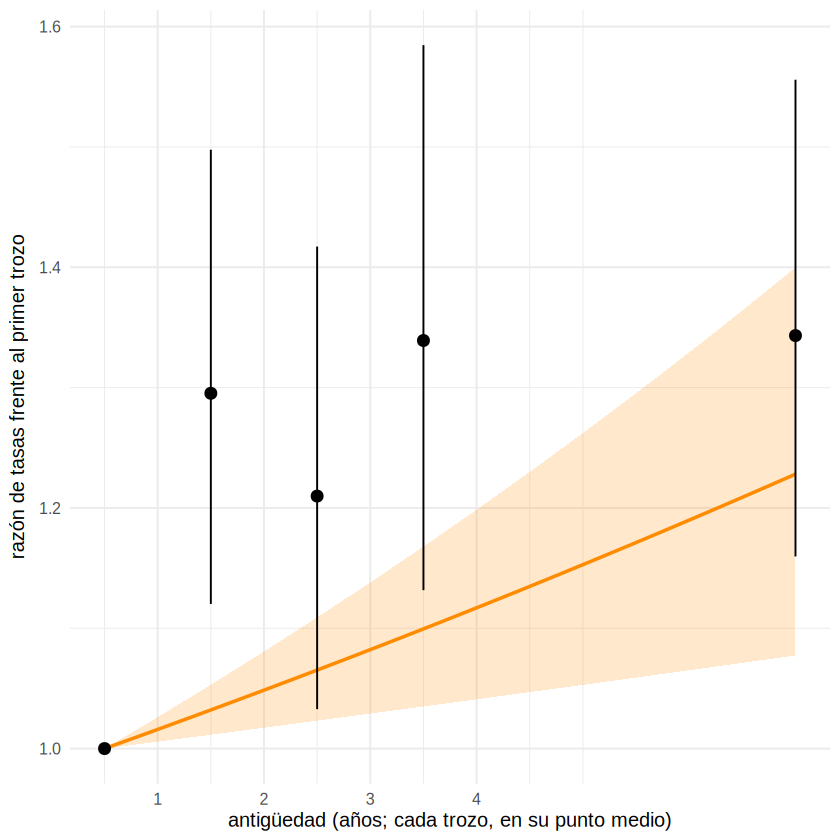

In [ ]:
b_tro  <- glmmTMB::fixef(m_pw_fin)$cond
ee_tro <- sqrt(diag(vcov(m_pw_fin)$cond))
nombres_tro <- paste0("trozo", levels(panel_completo$trozo)[-1])

rr_tro <- tibble::tibble(
  t_mid = t_medio(seq_along(levels(panel_completo$trozo))),
  rr  = exp(c(0, b_tro[nombres_tro])),
  inf = exp(c(0, b_tro[nombres_tro] - 1.96 * ee_tro[nombres_tro])),
  sup = exp(c(0, b_tro[nombres_tro] + 1.96 * ee_tro[nombres_tro])))

rr_lin <- tibble::tibble(
  t_mid = seq(min(rr_tro$t_mid), max(rr_tro$t_mid), length.out = 50),
  rr  = exp(gamma_lin * (t_mid - min(t_mid))),
  inf = exp((gamma_lin - 1.96 * ee_gamma) * (t_mid - min(t_mid))),
  sup = exp((gamma_lin + 1.96 * ee_gamma) * (t_mid - min(t_mid))))

ggplot() +
  geom_ribbon(data = rr_lin, aes(t_mid, ymin = inf, ymax = sup),
              fill = "darkorange", alpha = 0.2) +
  geom_line(data = rr_lin, aes(t_mid, rr), colour = "darkorange", linewidth = 1) +
  geom_pointrange(data = rr_tro, aes(t_mid, rr, ymin = inf, ymax = sup)) +
  scale_x_continuous(breaks = limites) +
  labs(x = "antigüedad (años; cada trozo, en su punto medio)",
       y = "razón de tasas frente al primer trozo")

In [ ]:
# Razones de tasas de cada trozo (modelo final)
exp(b_tro[nombres_tro])

trozo2    trozo3    trozo4 trozo5-10 
 1.295252  1.209828  1.339119  1.343220

Resultado. Frente al primer año, el riesgo es entre un 20 % y un 35 % mayor en el resto de trozos, con intervalos que se solapan bastante entre sí. La subida se concentra al principio y después se aplana.

Por tanto, el cambio con la antigüedad es gradual y de tamaño moderado.

#### 8. ¿Actúa cada característica igual en todos los trozos?

In [ ]:
candidatos <- c("edad_10", "carnet_10", "potencia_10", "zona_circulacion",
                "uso", "tipo_vehiculo", "sexo")
# solo los que se han quedado en el modelo final (si no, la interacción
# sin efecto principal rompe la marginalidad)
predictores_prop <- intersect(candidatos, all.vars(formula(m_pw_fin)))

contraste_int <- function(m, tiempo, v) {
  a <- anova(m, update(m, as.formula(paste(". ~ . +", tiempo, ":", v))))
  c(gl = a$`Chi Df`[2], p = round(a$`Pr(>Chisq)`[2], 3))
}

prop <- purrr::map_dfr(predictores_prop, \(v) {
  tro <- contraste_int(m_pw_fin, "trozo", v)
  lin <- contraste_int(m_lin, "t_mid", v)
  tibble::tibble(predictor = v, gl_trozos = tro[["gl"]], p_trozos = tro[["p"]],
                 gl_lineal = lin[["gl"]], p_lineal = lin[["p"]])
})
prop

predictor,gl_trozos,p_trozos,gl_lineal,p_lineal
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
edad_10,4,0.979,1,0.809
potencia_10,4,0.128,1,0.115
zona_circulacion,8,0.190,2,0.238
uso,4,0.562,1,0.583


Resultado. Ninguna interacción con la antigüedad es significativa.

Por tanto, cada característica actúa igual en todas las etapas.

#### 9. Validación con Nelson-Aalen

In [ ]:
# Instante exacto de cada parte: en este panel es siniestros$t_k
partes   <- siniestros |> dplyr::rename(t = t_k)
clientes <- dplyr::distinct(panel_completo, id_poliza, antiguedad)

na <- partes |>
  dplyr::count(t, name = "d") |>
  dplyr::mutate(
    en_obs = vapply(t, \(s) sum(clientes$antiguedad >= s, na.rm = TRUE), numeric(1)),
    nelson = cumsum(d / en_obs))

na_en <- function(s) max(c(0, na$nelson[na$t <= s]))

In [ ]:
# nd: una fila por cliente y trozo (exposición 1)
nd <- tidyr::crossing(
  dplyr::distinct(panel_completo, id_poliza, .keep_all = TRUE) |>
    dplyr::select(-trozo, -t_mid, -expo_anual, -anio, -n_partes_anual),
  trozo = factor(levels(panel_completo$trozo), levels = levels(panel_completo$trozo))) |>
  dplyr::mutate(t_mid = t_medio(trozo), expo_anual = 1)

# tasa media de la cartera en cada trozo: e^(eta + sigma^2/2) de cada cliente, promediada
tasa_cartera <- function(m) {
  s2  <- glmmTMB::VarCorr(m)$cond$id_poliza[1]
  eta <- predict(m, newdata = nd, type = "link", re.form = NA)
  tapply(exp(eta + s2 / 2), nd$trozo, mean)
}
tasas <- list(trozos = tasa_cartera(m_pw_fin), lineal = tasa_cartera(m_lin))

# tasa acumulada en la antigüedad s: tasa de cada trozo por el tiempo pasado en él
acum_modelo <- function(tasa, s)
  sum(tasa * pmax(0, pmin(s, limites[-1]) - limites[-length(limites)]))

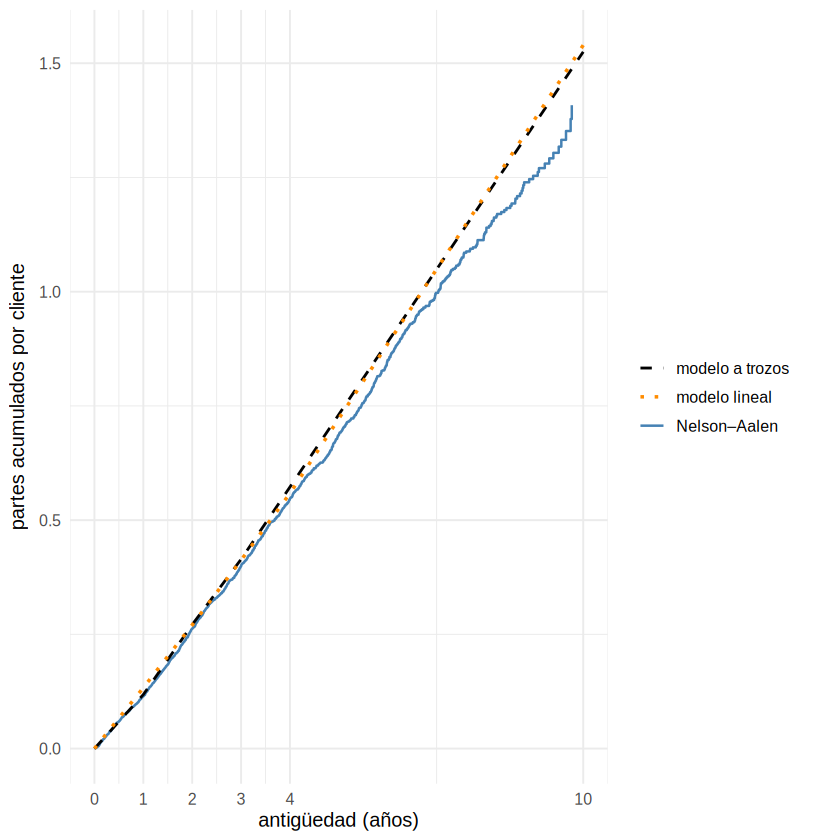

In [ ]:
rejilla <- tibble::tibble(t = seq(0, 10, by = 0.05)) |>
  dplyr::mutate(trozos = vapply(t, \(s) acum_modelo(tasas$trozos, s), numeric(1)),
                lineal = vapply(t, \(s) acum_modelo(tasas$lineal, s), numeric(1)))

ggplot() +
  geom_step(data = na, aes(t, nelson, colour = "Nelson–Aalen"), linewidth = 0.7) +
  geom_line(data = rejilla, aes(t, trozos, colour = "modelo a trozos"),
            linetype = 2, linewidth = 0.8) +
  geom_line(data = rejilla, aes(t, lineal, colour = "modelo lineal"),
            linetype = 3, linewidth = 1) +
  scale_x_continuous(breaks = limites) +
  scale_colour_manual(values = c("Nelson–Aalen" = "steelblue",
                                 "modelo a trozos" = "black",
                                 "modelo lineal" = "darkorange")) +
  labs(x = "antigüedad (años)", y = "partes acumulados por cliente", colour = NULL)

Resultado. El modelo a trozos queda muy cerca de la curva de Nelson-Aalen, que no depende de ningún modelo.

Por tanto, tasas constantes dentro de cada trozo son una buena aproximación.

#### 10. Diagnósticos

In [ ]:
cargar_paquetes(c("DHARMa"))

residuos_dharma <- function(modelo, semilla = 1) {
  set.seed(semilla)
  sim <- as.matrix(simulate(modelo, nsim = 250))
  DHARMa::createDHARMa(simulatedResponse = sim,
                       observedResponse = panel_completo$n_partes_anual,
                       fittedPredictedResponse = rowMeans(sim),
                       integerResponse = TRUE)
}

res_trozos <- residuos_dharma(m_pw_fin)
res_lineal <- residuos_dharma(m_lin)

Resultado. Las gráficas se leen buscando uniformidad de los residuos y ausencia de patrones; la valoración numérica está en la tabla siguiente.

Por tanto, la conclusión se da tras esa tabla.

plotResiduals() for datasets larger than 10,000 displays a spline instead of quantile regression lines for the sake of speed. To switch back to quantile regression lines, use the argument quantreg = T and have in mind that the function may take a while to compute and display the lines.



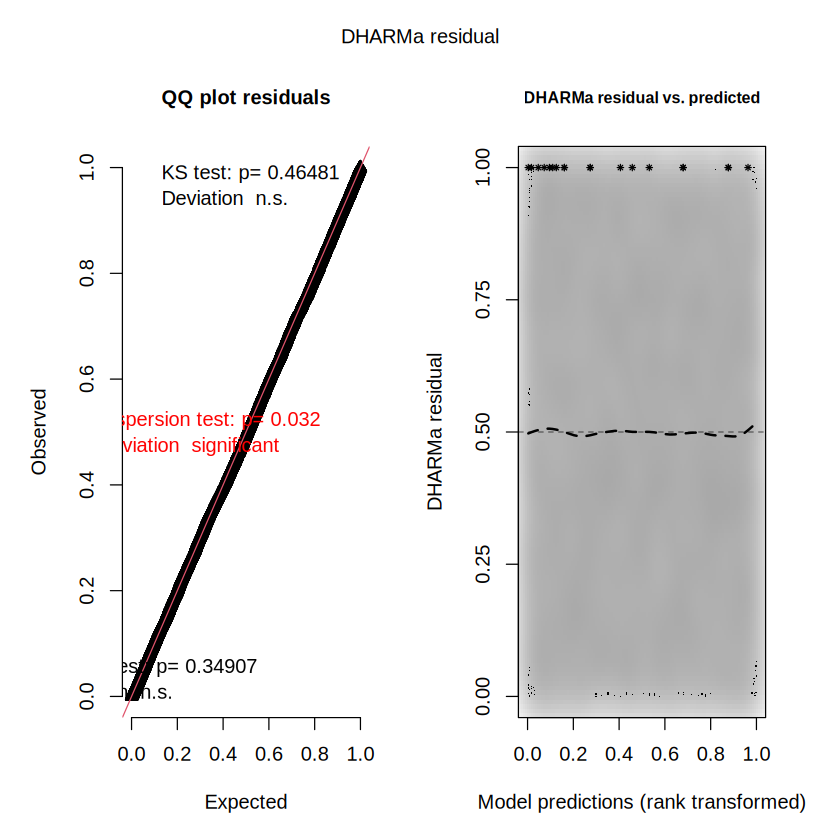

In [ ]:
plot(res_trozos)

plotResiduals() for datasets larger than 10,000 displays a spline instead of quantile regression lines for the sake of speed. To switch back to quantile regression lines, use the argument quantreg = T and have in mind that the function may take a while to compute and display the lines.



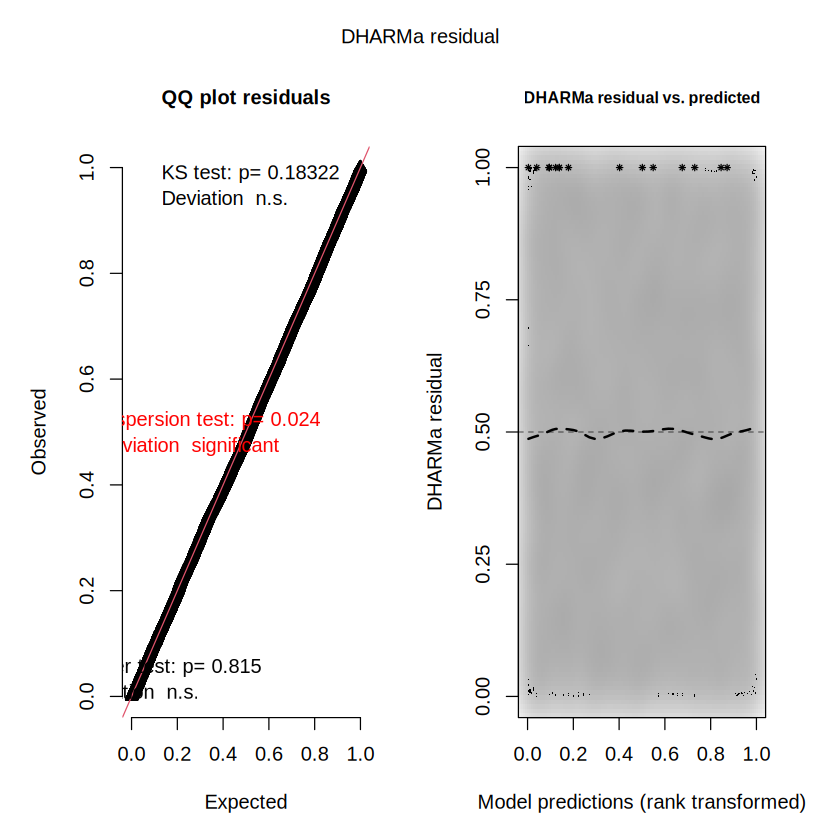

In [ ]:
plot(res_lineal)

In [ ]:
contrastes <- function(res, modelo, nivel, grupo = NULL) {
  if (!is.null(grupo)) res <- DHARMa::recalculateResiduals(res, group = grupo)
  disp <- DHARMa::testDispersion(res, plot = FALSE)
  tibble::tibble(
    modelo = modelo, nivel = nivel,
    uniformidad  = round(DHARMa::testUniformity(res, plot = FALSE)$p.value, 3),
    dispersion   = round(unname(disp$statistic), 3),
    p_dispersion = round(disp$p.value, 3),
    p_ceros      = round(DHARMa::testZeroInflation(res, plot = FALSE)$p.value, 3))
}

dplyr::bind_rows(
  contrastes(res_trozos, "trozos", "por fila"),
  contrastes(res_trozos, "trozos", "por póliza", panel_completo$id_poliza),
  contrastes(res_lineal, "lineal", "por fila"),
  contrastes(res_lineal, "lineal", "por póliza", panel_completo$id_poliza))

modelo,nivel,uniformidad,dispersion,p_dispersion,p_ceros
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
trozos,por fila,0.465,0.830,0.032,0.992
trozos,por póliza,0.609,0.634,0.000,0.960
lineal,por fila,0.183,0.829,0.024,0.968
lineal,por póliza,0.705,0.628,0.000,0.968


Resultado. Una comprobación por simulación a partir del modelo final no detecta exceso de ceros ni sobredispersión.

Por tanto, el modelo describe adecuadamente los datos.

#### 11. Predicción del cliente nuevo (en media y con intervalo)

In [ ]:
s2 <- glmmTMB::VarCorr(m_pw_fin)$cond$id_poliza[1]

# glmmTMB necesita la columna de agrupación en newdata; con re.form = NA se ignora
pred_mix <- pred
pred_mix$id_poliza <- panel_completo$id_poliza[1]

p_tip <- predict(m_pw_fin, newdata = pred_mix, type = "link",
                 se.fit = TRUE, re.form = NA)

pred_nuevo <- pred_mix |>
  dplyr::mutate(
    tipico   = exp(p_tip$fit),                                         # u = 0 (mediana)
    media    = exp(p_tip$fit + s2 / 2),                                # cliente nuevo, en media
    ic_inf   = exp(p_tip$fit + s2 / 2 - 1.96 * p_tip$se.fit),          # IC 95 % de la media
    ic_sup   = exp(p_tip$fit + s2 / 2 + 1.96 * p_tip$se.fit),
    pred_inf = exp(p_tip$fit - 1.96 * sqrt(p_tip$se.fit^2 + s2)),      # intervalo de predicción
    pred_sup = exp(p_tip$fit + 1.96 * sqrt(p_tip$se.fit^2 + s2)))

pred_nuevo |>
  dplyr::select(perfil, trozo, tipico, media, ic_inf, ic_sup, pred_inf, pred_sup) |>
  dplyr::mutate(dplyr::across(where(is.numeric), \(x) round(x, 3)))

perfil,trozo,tipico,media,ic_inf,ic_sup,pred_inf,pred_sup
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
joven_urbano,1,0.182,0.328,0.260,0.415,0.021,1.552
joven_urbano,2,0.235,0.425,0.337,0.536,0.028,2.010
joven_urbano,3,0.220,0.397,0.312,0.505,0.026,1.879
joven_urbano,4,0.243,0.440,0.343,0.563,0.028,2.081
joven_urbano,5-10,0.244,0.441,0.350,0.556,0.029,2.084
mediano,1,0.112,0.202,0.166,0.246,0.013,0.953
mediano,2,0.145,0.262,0.216,0.318,0.017,1.234
mediano,3,0.135,0.245,0.200,0.300,0.016,1.153
mediano,4,0.150,0.271,0.220,0.334,0.018,1.277


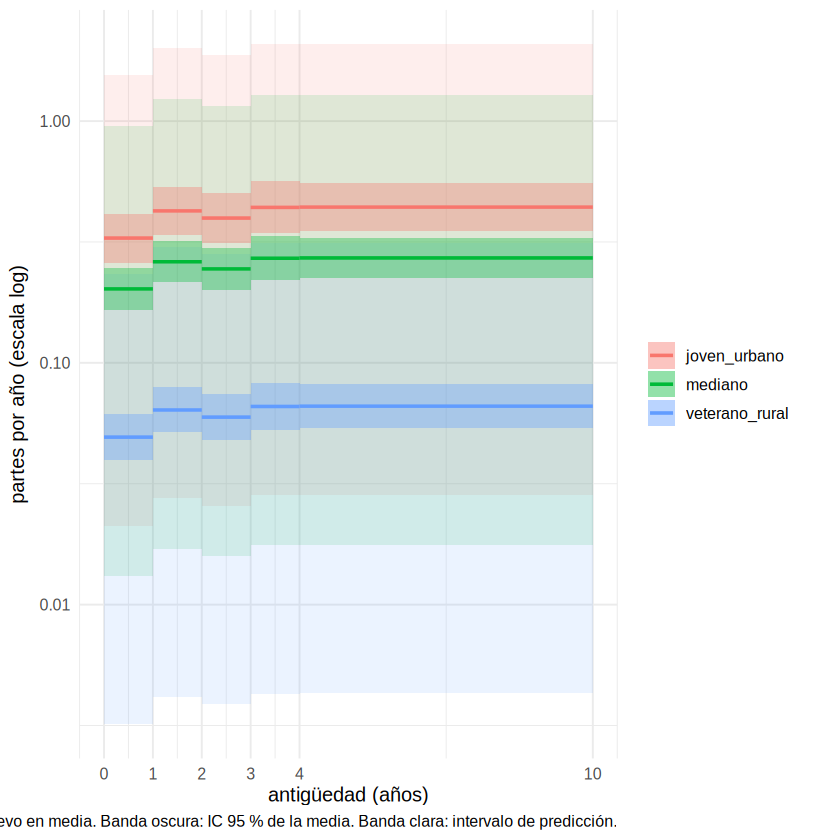

In [ ]:
pred_nuevo |>
  dplyr::mutate(desde = limites[as.integer(trozo)],
                hasta = limites[as.integer(trozo) + 1]) |>
  ggplot() +
  geom_rect(aes(xmin = desde, xmax = hasta, ymin = pred_inf, ymax = pred_sup, fill = perfil),
            alpha = 0.12) +
  geom_rect(aes(xmin = desde, xmax = hasta, ymin = ic_inf, ymax = ic_sup, fill = perfil),
            alpha = 0.35) +
  geom_segment(aes(x = desde, xend = hasta, y = media, yend = media, colour = perfil),
               linewidth = 1) +
  scale_y_log10() +
  scale_x_continuous(breaks = limites) +
  labs(x = "antigüedad (años)", y = "partes por año (escala log)",
       colour = NULL, fill = NULL,
       caption = "Línea: cliente nuevo en media. Banda oscura: IC 95 % de la media. Banda clara: intervalo de predicción.")

Resultado. Para un cliente nuevo, el perfil mediano espera unos 0,2 partes por año en el primer año y unos 0,27 a partir del quinto. El joven urbano espera bastante más y el veterano rural mucho menos. El intervalo de predicción es muy ancho. Los perfiles son: joven urbano (25 años, 160 CV), mediano (45 años, 110 CV, zona urbana) y veterano rural (60 años, 90 CV).

Por tanto, la diferencia entre perfiles es mucho mayor que la que produce la antigüedad en un mismo perfil. Para tarificar a un cliente nuevo se usa la frecuencia en media de su perfil y etapa; el intervalo de predicción solo indica cuánto pueden diferir clientes con la misma ficha.

##### Trozos o tendencia lineal en la predicción

In [ ]:
# cliente nuevo, en media, del perfil mediano: modelo a trozos frente a tendencia lineal
nd_med <- pred_mix |> dplyr::filter(perfil == "mediano")
nd_med$t_mid <- t_medio(nd_med$trozo)
s2_lin <- glmmTMB::VarCorr(m_lin)$cond$id_poliza[1]

p_trozos <- exp(predict(m_pw_fin, newdata = nd_med, type = "link", re.form = NA) + s2 / 2)
p_lineal <- exp(predict(m_lin, newdata = nd_med, type = "link", re.form = NA) + s2_lin / 2)

tibble::tibble(trozo = nd_med$trozo,
               trozos = round(p_trozos, 3),
               lineal = round(p_lineal, 3),
               diferencia_pct = round(100 * (p_lineal / p_trozos - 1), 1))

trozo,trozos,lineal,diferencia_pct
<fct>,<dbl>,<dbl>,<dbl>
1,0.202,0.228,12.7
2,0.262,0.235,-10.2
3,0.245,0.243,-0.8
4,0.271,0.250,-7.5
5-10,0.272,0.280,3.0


Resultado. Para el perfil mediano, las predicciones de los dos modelos difieren como mucho en torno a un 13 % (la recta queda algo por encima en el primer año y por debajo en el segundo) y mucho menos en el resto de etapas.

Por tanto, a efectos prácticos los dos modelos predicen parecido, y la recta es una forma sencilla de resumir la evolución.

#### 12. Cliente ya conocido frente a cliente nuevo

In [ ]:
# Póliza con antigüedad máxima y más partes
id_ej <- panel_completo |>
  dplyr::group_by(id_poliza) |>
  dplyr::summarise(partes = sum(n_partes_anual), anios = max(anio), .groups = "drop") |>
  dplyr::filter(anios == max(anios)) |>
  dplyr::slice_max(partes, n = 1, with_ties = FALSE) |>
  dplyr::pull(id_poliza)

nd_ej <- dplyr::filter(nd, id_poliza == id_ej)

p_obs <- predict(m_pw_fin, newdata = nd_ej, type = "link", se.fit = TRUE)               # con su u_i
p_typ <- predict(m_pw_fin, newdata = nd_ej, type = "link", re.form = NA)                 # u = 0

observado <- panel_completo |>
  dplyr::filter(id_poliza == id_ej) |>
  dplyr::group_by(trozo) |>
  dplyr::summarise(partes = sum(n_partes_anual), exposicion = sum(expo_anual),
                   .groups = "drop")

tibble::tibble(trozo = nd_ej$trozo,
               tasa_cliente = exp(p_obs$fit),
               inf = exp(p_obs$fit - 1.96 * p_obs$se.fit),
               sup = exp(p_obs$fit + 1.96 * p_obs$se.fit),
               tasa_tipico = exp(p_typ)) |>
  dplyr::left_join(observado, by = "trozo") |>
  dplyr::mutate(dplyr::across(where(is.double), \(x) round(x, 3)))

# Efecto estimado de esta póliza y cuántas veces supera al cliente típico
u_i <- glmmTMB::ranef(m_pw_fin)$cond$id_poliza[as.character(id_ej), 1]
c(id_poliza = id_ej, u_i = round(u_i, 2), veces_el_tipico = round(exp(u_i), 2))

trozo,tasa_cliente,inf,sup,tasa_tipico,partes,exposicion
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.875,0.488,1.568,0.075,0,1.000
2,1.134,0.634,2.028,0.098,1,1.000
3,1.059,0.590,1.899,0.091,2,1.000
4,1.172,0.653,2.105,0.101,2,1.000
5-10,1.176,0.662,2.086,0.101,8,5.692


id_poliza             u_i veces_el_tipico 
        2573.00            2.45           11.60

Resultado. La póliza del ejemplo (2573, diez años y 13 partes) tiene un riesgo unas diez veces superior al del cliente típico con su misma ficha, en todas las etapas.

Por tanto, de un cliente conocido no se espera lo mismo que de uno nuevo: su historial desplaza su riesgo y debe pesar en la tarifa.

> *Nota de integración.* La póliza 2573 se muestra con todo su historial observado. La predicción de una renovación concreta usaría los partes registrados hasta ese momento.

#### 13. Comparación con la verdad simulada

In [ ]:
verdad <- attr(cartera_rds, "verdad")
str(verdad)

List of 24
 $ dominio      : chr "auto"
 $ betas        :List of 6
  ..$ claim : Named num [1:13] -0.562 -0.878 -0.658 -0.055 0.132 ...
  .. ..- attr(*, "names")= chr [1:13] "edad_2535" "edad_3565" "edad_65" "z_carnet" ...
  ..$ sev   : Named num [1:7] 0.286 0.11 0.242 0.154 0.33 0.055 0.11
  .. ..- attr(*, "names")= chr [1:7] "val_z" "z_pot" "edad_joven" "edad_mayor" ...
  ..$ lapse : Named num [1:7] -0.11 -0.055 0.11 0.22 0.165 -0.165 -0.11
  .. ..- attr(*, "names")= chr [1:7] "z_km" "z_pot" "edad_2535" "edad_3565" ...
  ..$ asist : Named num [1:5] -0.22 -0.385 -0.11 0.275 0.22
  .. ..- attr(*, "names")= chr [1:5] "edad_2535" "edad_3565" "edad_65" "z_km" ...
  ..$ fraude: Named num [1:3] 0.165 0.165 0.11
  .. ..- attr(*, "names")= chr [1:3] "z_pot" "uso_com" "tipo_moto"
  ..$ gest  : Named num [1:3] -0.11 0.11 0.165
  .. ..- attr(*, "names")= chr [1:3] "edad_3565" "z_pot" "uso_com"
 $ theta_frail  : num 1
 $ weib_shape   : num 1.1
 $ lambda0      : num 0.165
 $ coste_base   : num 189

In [ ]:
# Desviación típica de la fragilidad
if (!is.null(verdad$sigma_frag)) {
  c(verdad = verdad$sigma_frag, estimado = sigma_pol)
}

# Riesgo base: razón de tasas de cada trozo frente al primero
if (!is.null(verdad$h0)) {
  h0        <- verdad$h0[seq_len(10)]
  expo_anio <- tapply(panel_completo$expo_anual, panel_completo$anio, sum)
  trozo_de  <- cut(1:10, breaks = cortes, labels = etiquetas)
  h0_trozo  <- tapply(h0 * expo_anio, trozo_de, sum) / tapply(expo_anio, trozo_de, sum)

  tibble::tibble(trozo = etiquetas[-1],
                 verdad = round(unname(h0_trozo[-1] / h0_trozo[1]), 3),
                 estimado = round(exp(b_tro[nombres_tro]), 3),
                 inf = round(exp(b_tro[nombres_tro] - 1.96 * ee_tro[nombres_tro]), 3),
                 sup = round(exp(b_tro[nombres_tro] + 1.96 * ee_tro[nombres_tro]), 3))
}

Resultado. Aquí se comparan la heterogeneidad y las razones de tasas por trozo con sus valores reales. El resultado concreto está en las salidas de esta sección.

Por tanto, si los valores reales caen dentro de los intervalos estimados, queda validado el modelo.

> *Nota de integración.* La comparación con el generador comprueba si se recuperan sus parámetros en estos datos simulados.

#### 14. Conclusiones

1. ¿Más, menos o igual número de partes con la antigüedad? Algo más, de forma suave: la frecuencia aumenta alrededor de un 3 % por año, sobre todo en los primeros años, y después se aplana. Es un efecto pequeño. El supuesto de tasa constante de P2 es una simplificación aceptable, aunque no exacta.

2. ¿Debe tenerse en cuenta en el precio de la renovación? La antigüedad por sí sola no justifica una diferenciación fuerte, porque pesa mucho menos que las características del cliente y que su propio historial. Si se incorpora, debería ser como un ajuste leve y fácil de revisar. Es una conclusión sobre frecuencia; antes de decidir el precio hay que mirar también la severidad y el riesgo de que el cliente se vaya.

3. ¿Cuántos partes esperamos de cada cliente tipo en cada etapa? Los perfiles se diferencian sobre todo por zona, edad y potencia, y esa diferencia es la misma en todas las etapas y mucho mayor que la que aporta la antigüedad. Por año, el perfil mediano pasa de unos 0,2 partes en el primer año a unos 0,27 a partir del quinto; el joven urbano espera bastante más y el veterano rural mucho menos. Los valores completos con sus intervalos están en la sección 11.

4. Cliente conocido frente a cliente nuevo: el historial debe pesar mucho. Dos clientes con la misma ficha pueden tener un riesgo muy distinto, así que de un cliente nuevo se espera la media de su perfil, pero de uno conocido hay que usar su propio historial, por ejemplo con un esquema de credibilidad o bonus-malus.

Recomendaciones, por orden de prioridad: (a) tarificar primero por las características del cliente; (b) cobrar al cliente nuevo la frecuencia en media de su perfil, no la del cliente típico; (c) incorporar el historial de cada cliente en las renovaciones; (d) si se quiere reflejar la antigüedad, hacerlo con un ajuste leve y revisarlo cada año.

Limitaciones. En una cartera real, los clientes que dan más partes tienden a darse de baja antes, y eso puede distorsionar la evolución con la antigüedad; el efecto por póliza no separa ambas cosas. Además, el análisis cubre solo la frecuencia, no el coste de los partes.

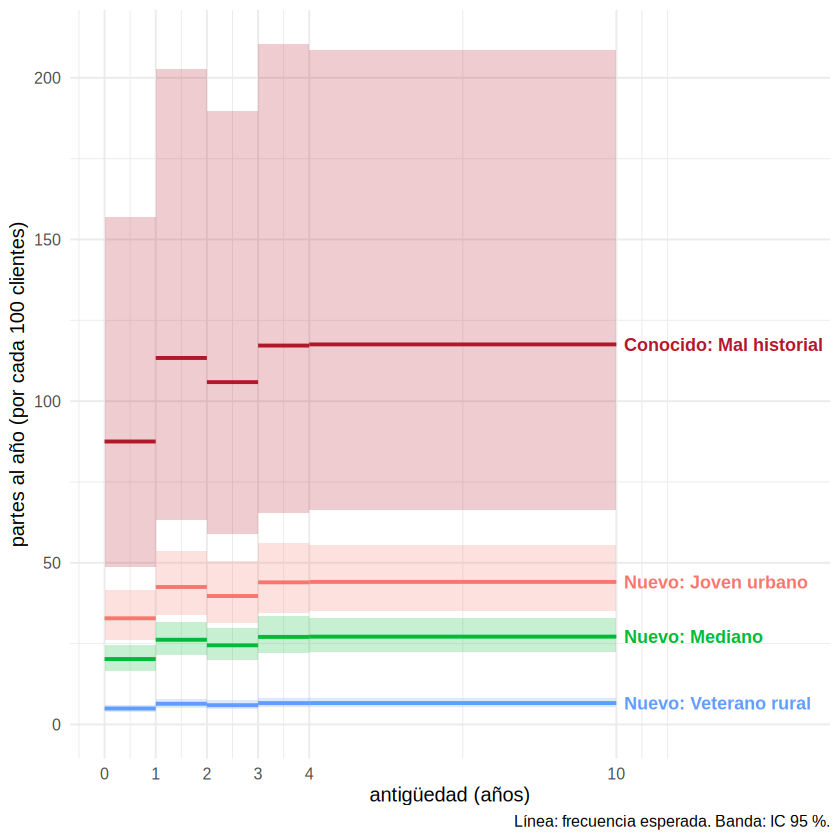

In [ ]:
# 1. Datos de los 3 perfiles (reutilizando pred_nuevo de la sección 11)
df_perf <- pred_nuevo |>
  dplyr::mutate(
    desde = limites[as.integer(trozo)],
    hasta = limites[as.integer(trozo) + 1],
    y     = media * 100,
    ymin  = ic_inf * 100,
    ymax  = ic_sup * 100,
    grupo = dplyr::case_when(
      perfil == "joven_urbano"   ~ "Nuevo: Joven urbano",
      perfil == "mediano"        ~ "Nuevo: Mediano",
      perfil == "veterano_rural" ~ "Nuevo: Veterano rural"
    )
  )

# 2. Datos del cliente conocido (reutilizando nd_ej y m_pw_fin de la sección 12)
p_con <- predict(m_pw_fin, newdata = nd_ej, type = "link", se.fit = TRUE)
df_con <- tibble::tibble(
  desde = limites[-length(limites)],
  hasta = limites[-1],
  y     = exp(p_con$fit) * 100,
  ymin  = exp(p_con$fit - 1.96 * p_con$se.fit) * 100,
  ymax  = exp(p_con$fit + 1.96 * p_con$se.fit) * 100,
  grupo = "Conocido: Mal historial"
)

df_total <- dplyr::bind_rows(df_perf, df_con)

# Etiquetas directas al final de cada línea (en x = 10)
etiquetas_fin <- df_total |> dplyr::filter(hasta == 10)

# 3. Gráfico limpio (misma estética que tu sección 11, en escala natural)
ggplot(df_total) +
  geom_rect(aes(xmin = desde, xmax = hasta, ymin = ymin, ymax = ymax, fill = grupo),
            alpha = 0.22) +
  geom_segment(aes(x = desde, xend = hasta, y = y, yend = y, colour = grupo),
               linewidth = 1.1) +
  geom_text(data = etiquetas_fin,
            aes(x = 10.15, y = y, label = grupo, colour = grupo),
            hjust = 0, size = 3.8, fontface = "bold") +
  scale_x_continuous(breaks = limites, limits = c(0, 13.5)) +
  scale_y_continuous(limits = c(0, NA)) +
  scale_colour_manual(values = c(
    "Conocido: Mal historial" = "#b2182b",
    "Nuevo: Joven urbano"     = "#f8766d",
    "Nuevo: Mediano"          = "#00ba38",
    "Nuevo: Veterano rural"   = "#619cff"
  ), aesthetics = c("colour", "fill")) +
  labs(
    x = "antigüedad (años)",
    y = "partes al año (por cada 100 clientes)",
    caption = "Línea: frecuencia esperada. Banda: IC 95 %."
  ) +
  theme(legend.position = "none")

### Entorno de ejecución

In [ ]:
sessionInfo()

R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] knitr_1.52         lme4_2.1-0         Matrix_1.7-6       glmmTMB_1.1.15.2  
 [5] pscl_1.5.9         DHARMa_0.5.1       performance_0.20.0 vcd_1.4-14        
 [9

## Julio Toboso: Interpretación Actuarial

Para la toma de decisiones ejecutivas es necesario no solo conocer la tasa de incidencia de partes, si no también el coste esperado.
Incurrimos aquí en el papel de Actuario de seguros para establecer las primas que contrarresten el riesgo de la cartera.

Basadas en el análisis de tasas de los compañeros, proporcionaremos conclusiones ejecutables en la toma de decisiones. Es decir, que equilibramos el riesgo por la aseguradora para no incurrir en perdidas.

### Prima común de la cartera observada

Suponemos **0 € de gastos de agencia**. Un ajuste contable simple puede incorporar los factores fijos de la empresa. En nuestro análisis nos centraremos en contrarestar los costes incurridos por los siniestros de la cartera.

En la notación, $Y_i$ cuenta los partes de la póliza $i$, $t_i$ es su tiempo cubierto en años y $\lambda_i$ es la tasa anual. Los partes esperados durante ese tiempo son $\mu_i=t_i\lambda_i$. Para pasar a euros llamamos $c_i$ a la indemnización acumulada de esa póliza, y $C$ a la indemnización acumulada por todos los clientes.

$$
P
= \frac{C}{\sum t_i}
= \frac{\sum Y_i}{\sum t_i}·
\frac{\sum_i c_i}{\sum_i Y_i}.
$$

Esta es la cuota anual uniforme que habría cubierto las indemnizaciones de **toda la vigencia observada**. Cada año parcial aporta su fracción cubierta, también en las pólizas sin partes. Sumamos `expo_anual` para obtener los años.

Llamamos **prima relativa** $p_i$ al importe anual de cada perfil. Se expresa en €/póliza-año. Su **relatividad** $l_i=p_i/P$ indica por cuánto se multiplica la **prima común** $P$.

$$
p_i = l_i ·P
$$
Por ejemplo, $(l_i=1.20)$ significa que la póliza aporta al fondo común un 20 % más que la referencia por cada año de cobertura.



[Unidad 2.1 · Tasa, exposición y enlace del GLM](https://github.com/asunmayoral/GLM/blob/b05aeaecde9dca0049ea0ca55fbe162a9b964cbc/caso2/_unidad_2_1.qmd#L91-L112)

In [ ]:
#@title Cálculo en R · prima común, frecuencia y coste por parte { display-mode: "form" }
# coste_k está en euros. expo_anual incluye la fracción cubierta de cada año.
total_indemnizaciones <- sum(siniestros$coste_k)
total_exposicion <- sum(panel$expo_anual)
total_siniestros <- nrow(siniestros)

stopifnot(
    total_exposicion > 0,
    total_siniestros == sum(panel$n_partes_anual),
    isTRUE(all.equal(total_indemnizaciones, sum(cartera_original$coste_total)))
    )

prima_pura_global <- total_indemnizaciones / total_exposicion
recibo_mensual_estimado <- prima_pura_global / 12
tasa_siniestralidad <- total_siniestros / total_exposicion
coste_medio_parte <- NA_real_
inverso_tasa <- NA_real_
if (total_siniestros > 0) {
    coste_medio_parte <- total_indemnizaciones / total_siniestros
    inverso_tasa <- total_exposicion / total_siniestros
    }

numero_cartera <- function(x, decimales) {
    formatC(x, format = "f", digits = decimales, big.mark = ".", decimal.mark = ",")
    }

local({
    detalle <- if (total_siniestros > 0) {
        sprintf(
            "%s partes · %s partes/póliza-año · %s €/parte · un parte por cada %s pólizas-año.",
            numero_cartera(total_siniestros, 0), numero_cartera(tasa_siniestralidad, 5),
            numero_cartera(coste_medio_parte, 2), numero_cartera(inverso_tasa, 2)
            )
        } else {
        "0 partes en el periodo observado."
        }
    tarjeta <- paste0(
        "<div style='padding:10px 14px;background:#f1f5f7;color:#17344d;border-left:3px solid #256d71'>",
        "<b>Prima común</b><br>", numero_cartera(total_indemnizaciones, 2), " € ÷ ",
        numero_cartera(total_exposicion, 3), " pólizas-año ≈ <b>", numero_cartera(prima_pura_global, 2),
        " €/póliza-año</b><br>",
        "Recibo mensual estimado · prima común (P/12) ≈ <b>",
        numero_cartera(recibo_mensual_estimado, 2), " €/mes por póliza</b><br>",
        detalle, "</div>"
        )
    IRdisplay::display_html(tarjeta)
    })

Prima común 4.263.423,85 € ÷ 12.882,356 pólizas-año ≈ 330,95 €/póliza-año Recibo mensual estimado · prima común (P/12) ≈ 27,58 €/mes por póliza 1.770 partes · 0,13740 partes/póliza-año · 2.408,71 €/parte · un parte por cada 7,28 pólizas-año.

### P1 · ¿En qué zona priorizar la prevención?
> ¿Qué clientes dan más siniestros: depende del vehículo, de la zona o de las dos cosas?

El modelo log-lineal de Luis identifica la zona de circulación como el factor que distingue a las pólizas con algún parte durante su vigencia. La zona urbana concentra la mayor **proporción** y la mixta reúne el mayor **número** de pólizas afectadas.

$$
\log(\mu_{zvs})=\beta_0+Z_z+V_v+S_s+I_{zs}.
$$
- $z$: Zona de circulación.
- $v$: tipo de vehículo
- $s$: Siniestro, si hubo algún parte. (1:= Sí)


[Análisis de P1](#scrollTo=ba90bf2056a3)

In [ ]:
#@title P1 · De las pólizas esperadas a la probabilidad y la odds ratio
local({
    # Reutilizamos los recuentos ajustados por Luis en las 18 celdas.
    celdas <- model.frame(m_final)
    celdas$esperadas <- fitted(m_final)

    conteos <- xtabs(
        esperadas ~ zona_circulacion + tipo_vehiculo + siniestro,
        data = celdas
        )

    probabilidad_cartera <- sum(conteos[, , "con"]) / sum(conteos)

    resumir_zonas <- function(conteos_zona) {
        zona <- rownames(conteos_zona)
        con <- as.numeric(conteos_zona[, "con"])
        sin <- as.numeric(conteos_zona[, "sin"])

        probabilidad <- con / (con + sin)
        variacion <- 100 * (probabilidad / probabilidad_cartera - 1)
        odds <- con / sin
        odds_ratio <- odds / odds[zona == "mixta"]

        data.frame(
            Zona = zona,
            "Con parte" = numero_cartera(con, 2),
            "Sin parte" = numero_cartera(sin, 2),
            "Probabilidad" = paste0(numero_cartera(100 * probabilidad, 1), " %"),
            "Variación vs. cartera" = paste0(
                ifelse(variacion > 0, "+", ""),
                numero_cartera(variacion, 1),
                " %"
                ),
            "Odds (con/sin)" = numero_cartera(odds, 3),
            "OR frente a mixta" = numero_cartera(odds_ratio, 2),
            check.names = FALSE
            )
        }

    # Sumamos primero los recuentos de los tres vehículos en cada zona.
    por_zona <- margin.table(conteos, c(1, 3))
    resumen <- resumir_zonas(por_zona)

    # Para cada vehículo, la referencia es ese mismo vehículo en zona mixta.
    vehiculos <- dimnames(conteos)$tipo_vehiculo
    filas <- lapply(vehiculos, function(tipo) {
        data.frame(
            Vehículo = tipo,
            resumir_zonas(conteos[, tipo, ]),
            check.names = FALSE
            )
        })
    detalle <- do.call(rbind, filas)

    # Cada póliza aporta una vez su coste total y todos sus años cubiertos.
    cartera <- cartera_original
    tiempo_por_poliza <- tapply(panel$expo_anual, panel$id_poliza, sum)
    cartera$tiempo <- as.numeric(
        tiempo_por_poliza[as.character(cartera$id_poliza)]
        )

    stopifnot(
        !anyDuplicated(cartera$id_poliza),
        all(is.finite(cartera$tiempo)),
        all(cartera$tiempo > 0),
        all(is.finite(cartera$coste_total))
        )

    costes <- xtabs(coste_total ~ zona_circulacion + tipo_vehiculo, data = cartera)
    tiempos <- xtabs(tiempo ~ zona_circulacion + tipo_vehiculo, data = cartera)

    # Para el total de zona sumamos primero euros y exposición.
    prima_zona <- rowSums(costes) / rowSums(tiempos)
    prima_zona_vehiculo <- costes / tiempos

    columna <- "Prima relativa"
    resumen[[columna]] <- numero_cartera(
        prima_zona[as.character(resumen$Zona)], 2
        )

    grupo <- cbind(as.character(detalle$Zona), as.character(detalle$Vehículo))
    detalle[[columna]] <- numero_cartera(prima_zona_vehiculo[grupo], 2)

    # La cartera completa es la referencia: factor 1.
    prima_comun <- sum(costes) / sum(tiempos)

    factor_zona <- prima_zona / prima_comun
    factor_zona_vehiculo <- prima_zona_vehiculo / prima_comun

    columna_factor <- "Relatividad (l_i)"
    resumen[[columna_factor]] <- numero_cartera(
        factor_zona[as.character(resumen$Zona)], 3
        )
    detalle[[columna_factor]] <- numero_cartera(
        factor_zona_vehiculo[grupo], 3
        )

    estilo_tablas <- "<style>
        table.p1-tabla {
            width: 100%;
            border-collapse: collapse;
            margin: 10px 0;
            color: #17344d;
            font-variant-numeric: tabular-nums;
        }
        .p1-tabla th, .p1-tabla td {
            border: 1px solid #b7c8d5;
            padding: 6px 8px;
            vertical-align: middle;
        }
        .p1-tabla thead th {
            background: #19394f;
            color: white;
            line-height: 1.25;
        }
        .p1-tabla tbody tr:nth-child(odd) td { background: white; }
        .p1-tabla tbody tr:nth-child(even) td { background: #e5eef4; }
        .p1-tabla tbody td { white-space: nowrap; }
        .p1-marco { overflow-x: auto; }
        </style>"

    tabla_html <- function(datos) {
        columnas_texto <- names(datos) %in% c("Zona", "Vehículo")
        tabla <- knitr::kable(
            datos,
            format = "html",
            row.names = FALSE,
            align = ifelse(columnas_texto, "l", "r"),
            table.attr = "class='p1-tabla'"
            )
        paste0("<div class='p1-marco'>", tabla, "</div>")
        }

    tarjeta <- paste0(
        estilo_tablas,
        "<div style='padding:12px 16px;background:#f1f5f7;",
        "color:#17344d;border-left:3px solid #256d71'>",
        "<b>P1 · Pólizas esperadas con y sin parte por zona</b><br>",
        "<small>Al menos un parte durante la vigencia observada. ",
        "La variación compara cada probabilidad con la de toda la cartera (",
        numero_cartera(100 * probabilidad_cartera, 1), " %).</small>",
        tabla_html(resumen),
        "<details><summary><b>Ver desglose por tipo de vehículo</b></summary>",
        tabla_html(detalle),
        "</details></div>"
        )

    IRdisplay::display_html(tarjeta)
    })

P1 · Pólizas esperadas con y sin parte por zona Al menos un parte durante la vigencia observada. La variación compara cada probabilidad con la de toda la cartera (31,0 %). 
 
 
 Zona 
 Con parte 
 Sin parte 
 Probabilidad 
 Variación vs. cartera 
 Odds (con/sin) 
 OR frente a mixta 
 Prima relativa 
 Relatividad (l_i) 
 
 
 
 
 mixta 
 563,00 
 1.245,00 
 31,1 % 
 +0,5 % 
 0,452 
 1,00 
 327,22 
 0,989 
 
 
 rural 
 192,00 
 637,00 
 23,2 % 
 -25,3 % 
 0,301 
 0,67 
 166,75 
 0,504 
 
 
 urbana 
 194,00 
 231,00 
 45,6 % 
 +47,3 % 
 0,840 
 1,86 
 666,39 
 2,014 
 
 
 Ver desglose por tipo de vehículo 
 
 
 Vehículo 
 Zona 
 Con parte 
 Sin parte 
 Probabilidad 
 Variación vs. cartera 
 Odds (con/sin) 
 OR frente a mixta 
 Prima relativa 
 Relatividad (l_i) 
 
 
 
 
 furgoneta 
 mixta 
 73,73 
 163,05 
 31,1 % 
 +0,5 % 
 0,452 
 1,00 
 335,08 
 1,012 
 
 
 furgoneta 
 rural 
 25,14 
 83,42 
 23,2 % 
 -25,3 % 
 0,301 
 0,67 
 151,31 
 0,457 
 
 
 furgoneta 
 urbana 
 25,41 
 30,25 
 45,6 % 
 +47,3 % 
 0,840 
 1,86 
 637,89 
 1,927 
 
 
 moto 
 mixta 
 69,50 
 153,69 
 31,1 % 
 +0,5 % 
 0,452 
 1,00 
 560,80 
 1,695 
 
 
 moto 
 rural 
 23,70 
 78,64 
 23,2 % 
 -25,3 % 
 0,301 
 0,67 
 277,97 
 0,840 
 
 
 moto 
 urbana 
 23,95 
 28,52 
 45,6 % 
 +47,3 % 
 0,840 
 1,86 
 1.401,22 
 4,234 
 
 
 turismo 
 mixta 
 419,77 
 928,26 
 31,1 % 
 +0,5 % 
 0,452 
 1,00 
 287,29 
 0,868 
 
 
 turismo 
 rural 
 143,15 
 474,94 
 23,2 % 
 -25,3 % 
 0,301 
 0,67 
 150,35 
 0,454 
 
 
 turismo 
 urbana 
 144,64 
 172,23 
 45,6 % 
 +47,3 % 
 0,840 
 1,86 
 566,95 
 1,713

### P2 · ¿Cuántos partes esperamos de un cliente nuevo?

> Cuando llega un cliente nuevo, ¿cuántos partes cabe esperar durante su primer año y qué datos de su ficha ayudan a estimarlo?

P2 cuenta todos los partes y tiene en cuenta el tiempo de cobertura. Una póliza con tres partes en un año y otra con tres en seis años tienen el mismo recuento acumulado, pero frecuencias anuales muy distintas. Por eso la unidad de P2 es partes por póliza-año.

Para un cliente que contrata un año, su tasa $(\lambda_i)$ da los partes esperados con ese tiempo de cobertura al ritmo medio de la tarifa. Más abajo se contrasta por separado con lo observado durante el primer año.



$$
\log(\lambda_i)=\beta_0+\beta_{\mathrm{edad}[i]}+\beta_{\mathrm{zona}[i]}+\beta_{\mathrm{km}}\,\mathrm{km}_i.
$$


Con la semilla del curso 20252026, la selección conserva el tramo de edad, la zona y los kilómetros anuales. Las referencias son el tramo de 18–25 años y la zona mixta. [Análisis y validación de P2](#scrollTo=1775cdb846e8)

Podemos obtener la relatividad desde la tasa de riesgo mediante esta fórmula:
$$
\lambda·l_i=\hat\lambda_i
$$
donde $(\lambda)$ es la frecuencia modelada media de la cartera.

Si se valora la tasa del perfil y la tasa de referencia con el mismo coste medio por parte, la relatividad de sus primas coincide con la de sus tasas.

In [ ]:
#@title P2 · Cómo cambia la prima relativa con cada factor
local({
    ajuste <- cartera_original[idx_train, ]
    reserva <- cartera_original[-idx_train, ]
    exposicion <- tapply(panel$expo_anual, panel$id_poliza, sum)
    reserva$tiempo <- unname(exposicion[as.character(reserva$id_poliza)])
    reserva$previstos <- test$pred_nb

    stopifnot(
        "Ejecuta primero la validación de P2" =
            length(reserva$previstos) == nrow(reserva),
        "La tabla de validación debe conservar el orden original" =
            nrow(test) == nrow(reserva) &&
            all(test$n_siniestros == reserva$n_siniestros) &&
            all(test$km_anuales == reserva$km_anuales) &&
            all(test$antiguedad == reserva$antiguedad),
        all(is.finite(reserva$tiempo)), all(reserva$tiempo > 0),
        all(is.finite(reserva$previstos))
        )

    coste_por_parte <- sum(ajuste$coste_total) / sum(ajuste$n_siniestros)
    tasa_validacion <- sum(reserva$previstos) / sum(reserva$tiempo)
    prima_comun <- sum(cartera_original$coste_total) / sum(exposicion)
    coeficientes <- coef(summary(mod_tarifa_nb))
    numero <- numero_cartera

    # La matriz de diseño debe usar la misma codificación que el ajuste de P2.
    cov_beta <- vcov(mod_tarifa_nb)
    diseno <- model.matrix(
        delete.response(terms(mod_tarifa_nb)),
        data = test,
        contrasts.arg = mod_tarifa_nb$contrasts,
        xlev = mod_tarifa_nb$xlevels
        )[, colnames(cov_beta), drop = FALSE]
    stopifnot(nrow(diseno) == nrow(reserva))

    ic_prima_modelada <- function(filas, prima_modelada) {
        # Gradiente de log(sum(mu_i)): media de los predictores ponderada por mu_i.
        previstos <- reserva$previstos[filas]
        pesos <- previstos / sum(previstos)
        gradiente <- drop(crossprod(pesos, diseno[filas, , drop = FALSE]))
        varianza <- drop(crossprod(gradiente, cov_beta %*% gradiente))
        margen <- qnorm(0.975) * sqrt(varianza)
        prima_modelada * exp(c(-margen, margen))
        }

    formato_intervalo <- function(limites, decimales) {
        paste(numero(limites[1], decimales), numero(limites[2], decimales), sep = " – ")
        }

    # El IC de Wald se calcula en escala logarítmica y luego se transforma.
    efecto <- function(termino, paso = 1) {
        if (is.null(termino)) {
            return(c(razon = 1, inferior = 1, superior = 1))
            }
        beta <- coeficientes[termino, "Estimate"] * paso
        margen <- qnorm(0.975) * coeficientes[termino, "Std. Error"] * paso
        exp(c(razon = beta, inferior = beta - margen, superior = beta + margen))
        }

    columnas_efecto <- function(e, referencia = FALSE) {
        cambio <- 100 * (e[["razon"]] - 1)
        intervalo <- if (referencia) "Referencia" else
            paste(numero(e[["inferior"]], 3), numero(e[["superior"]], 3), sep = " – ")
        data.frame(
            "Razón de tasas" = numero(e[["razon"]], 3),
            "Incremento" = paste0(if (cambio > 0) "+" else "", numero(cambio, 1), " %"),
            "IC 95 % de la razón" = intervalo,
            check.names = FALSE
            )
        }

    filas_factor <- function(campo) {
        niveles <- mod_tarifa_nb$xlevels[[campo]]
        filas <- lapply(niveles, function(nivel) {
            filas_grupo <- which(reserva[[campo]] == nivel)
            grupo <- reserva[filas_grupo, ]
            tiempo <- sum(grupo$tiempo)
            stopifnot("Grupo sin exposición en la reserva" = tiempo > 0)
            tasa <- sum(grupo$previstos) / tiempo
            prima_modelada <- tasa * coste_por_parte
            ic_prima <- ic_prima_modelada(filas_grupo, prima_modelada)
            prima_observada <- sum(grupo$coste_total) / tiempo
            es_base <- nivel == niveles[1]
            termino <- if (es_base) NULL else paste0(campo, nivel)

            data.frame(
                Nivel = nivel,
                columnas_efecto(efecto(termino), es_base),
                "Partes previstos por póliza-año" = numero(tasa, 3),
                "Tasa relativa mod." = numero(tasa / tasa_validacion, 3),
                "Relatividad modelada (×)" = numero(prima_modelada / prima_comun, 3),
                "IC 95 % relatividad modelada" = formato_intervalo(ic_prima / prima_comun, 3),
                "Relatividad observada (×)" = numero(prima_observada / prima_comun, 3),
                "Prima relativa modelada (€)" = numero(prima_modelada, 2),
                "IC 95 % prima modelada (€)" = formato_intervalo(ic_prima, 2),
                "Prima relativa observada (€)" = numero(prima_observada, 2),
                check.names = FALSE
                )
            })
        do.call(rbind, filas)
        }

    tabla <- function(titulo, nota, datos, agrupar = TRUE) {
        etiquetas <- names(datos)
        if (agrupar) {
            iniciales <- ncol(datos) - 6L
            medidas <- c("Modelada", "IC 95 %", "Observada")
            etiquetas <- c(etiquetas[seq_len(iniciales)], medidas, medidas)
            cabecera <- paste0(
                "<colgroup span='", iniciales, "'></colgroup>",
                "<colgroup span='3'></colgroup><colgroup span='3'></colgroup>",
                "<thead><tr>",
                "<th scope='colgroup' colspan='", iniciales, "'>Frecuencia de partes</th>",
                "<th scope='colgroup' colspan='3'>Relatividad (×)</th>",
                "<th scope='colgroup' colspan='3'>Prima relativa (€/póliza-año)</th>",
                "</tr>"
                )
            }
        cuerpo <- knitr::kable(
            datos, format = "html", row.names = FALSE, col.names = etiquetas,
            align = c("l", rep("r", ncol(datos) - 1))
            )
        if (agrupar) {
            cuerpo <- sub("<thead>", cabecera, cuerpo, fixed = TRUE)
            }
        paste0("<h4>", titulo, "</h4><p>", nota, "</p><div>", cuerpo, "</div>")
        }

    cambio_por_km <- function(km_adicionales, decimales) {
        incremento <- 100 * (efecto("km_anuales", paso = km_adicionales) - 1)
        data.frame(
            "Distancia anual adicional" = paste(numero(km_adicionales, 0), "km"),
            "Cambio estimado de la prima anual" = paste0(
                if (incremento[["razon"]] > 0) "+" else "",
                numero(incremento[["razon"]], decimales), " %"
                ),
            "IC 95 % del cambio" = paste0(
                numero(incremento[["inferior"]], decimales), " % – ",
                numero(incremento[["superior"]], decimales), " %"
                ),
            check.names = FALSE
            )
        }
    km <- rbind(cambio_por_km(1, 4), cambio_por_km(10000, 1))

    ficha_a <- tabla24[startsWith(as.character(tabla24$perfil), "A ·"), ]
    stopifnot(nrow(ficha_a) == 1, ficha_a$antiguedad == 1)
    escenarios <- ficha_a[c(1, 1), ]
    escenarios$km_anuales <- ficha_a$km_anuales + c(0, 10000)
    partes <- predict(mod_tarifa_nb, newdata = escenarios, type = "response")
    primas <- partes * coste_por_parte
    ejemplo_km <- data.frame(
        Escenario = c("Ficha original", "Misma ficha con 10.000 km más"),
        "Km/año" = numero(escenarios$km_anuales, 0),
        "Partes esperados en un año" = numero(partes, 3),
        "Relatividad modelada (×)" = numero(primas / prima_comun, 3),
        "Prima relativa modelada (€/año)" = numero(primas, 2),
        check.names = FALSE
        )

    estilo <- "<style>
        .p2-factores {color:#17344d;background:#f3f7f9;padding:12px 16px}
        .p2-factores h4,.p2-factores > b {
            color:#102a43 !important;font-weight:700;
        }
        .p2-factores h4 {font-size:1.1rem;margin:16px 0 4px}
        .p2-factores p {margin:4px 0 8px}
        .p2-factores div {overflow-x:auto}
        .p2-factores table {width:100%;border-collapse:collapse;font-variant-numeric:tabular-nums}
        .p2-factores td,.p2-factores th {padding:6px 8px;border:1px solid #b7c8d5}
        .p2-factores th {background:#19394f;color:white;line-height:1.2}
        .p2-factores th[scope='colgroup'] {background:#102a43;text-align:center}
        .p2-factores td {background:white;white-space:nowrap}
        .p2-factores tr:nth-child(even) td {background:#e5eef4}
        </style>"

    html <- paste0(
        estilo, "<section class='p2-factores'>",
        "<b>P2 · Frecuencia de partes y prima relativa por factor</b>",
        "<p>La razón de tasas compara dos niveles manteniendo fijos los demás factores. ",
        "El incremento se aplica también a la prima si el coste medio por parte es común (",
        numero(coste_por_parte, 2), " € en la muestra de ajuste).</p>",
        "<p>Las columnas de grupo utilizan las pólizas reservadas con ese nivel. ",
        "La tasa relativa se compara con la tasa prevista de toda la reserva (",
        numero(tasa_validacion, 3), " partes por póliza-año). Cada relatividad se calcula ",
        "dividiendo la prima correspondiente entre la prima común (",
        numero(prima_comun, 2), " €/póliza-año).</p>",
        "<p>En ambos bloques, el IC del 95 % corresponde al valor modelado. ",
        "Refleja la incertidumbre de los coeficientes del modelo ",
        "de frecuencia para la media de cada grupo. Mantienen fijos los perfiles, ",
        "la exposición, el coste medio por parte y la prima común. La última columna ",
        "muestra las indemnizaciones reales del grupo por año cubierto.</p>",
        tabla("Tramo de edad", "Referencia del modelo: 18–25 años.", filas_factor("edad_tramo")),
        tabla("Zona de circulación", "Referencia del modelo: mixta.", filas_factor("zona_circulacion")),
        tabla("¿Cuánto cambia la prima al recorrer más kilómetros al año?",
              "Para el mismo perfil, cada kilómetro adicional aplica el mismo porcentaje sobre la prima ya ajustada. El efecto se acumula de forma compuesta.",
              km, agrupar = FALSE),
        tabla("Escenario modelado · Ficha A, joven urbano",
              paste0("Solo cambia el kilometraje. La prima estimada aumenta en ",
                     numero(diff(primas), 2), " € por año de cobertura."),
              ejemplo_km, agrupar = FALSE),
        if ("uso" %in% names(mod_tarifa_nb$xlevels)) {
            tabla("Uso del vehículo", "Referencia del modelo: comercial.", filas_factor("uso"))
            },
        "</section>"
        )
    if (requireNamespace("IRdisplay", quietly = TRUE)) {
        IRdisplay::display_html(html)
        } else {
        cat(html)
        }
    })

P2 · Frecuencia de partes y prima relativa por factor La razón de tasas compara dos niveles manteniendo fijos los demás factores. El incremento se aplica también a la prima si el coste medio por parte es común (2.406,61 € en la muestra de ajuste). Las columnas de grupo utilizan las pólizas reservadas con ese nivel. La tasa relativa se compara con la tasa prevista de toda la reserva (0,139 partes por póliza-año). Cada relatividad se calcula dividiendo la prima correspondiente entre la prima común (330,95 €/póliza-año). En ambos bloques, el IC del 95 % corresponde al valor modelado. Refleja la incertidumbre de los coeficientes del modelo de frecuencia para la media de cada grupo. Mantienen fijos los perfiles, la exposición, el coste medio por parte y la prima común. La última columna muestra las indemnizaciones reales del grupo por año cubierto. Tramo de edad Referencia del modelo: 18–25 años. 
 Frecuencia de partes Relatividad (×) Prima relativa (€/póliza-año) 
 
 Nivel 
 Razón de tasas 
 Incremento 
 IC 95 % de la razón 
 Partes previstos por póliza-año 
 Tasa relativa mod. 
 Modelada 
 IC 95 % 
 Observada 
 Modelada 
 IC 95 % 
 Observada 
 
 
 
 
 18-25 
 1,000 
 0,0 % 
 Referencia 
 0,339 
 2,444 
 2,462 
 2,021 – 3,001 
 2,369 
 814,92 
 668,71 – 993,10 
 784,18 
 
 
 25-35 
 0,499 
 -50,1 % 
 0,385 – 0,647 
 0,160 
 1,156 
 1,164 
 0,980 – 1,383 
 0,990 
 385,36 
 324,43 – 457,74 
 327,74 
 
 
 35-65 
 0,322 
 -67,8 % 
 0,259 – 0,401 
 0,100 
 0,725 
 0,730 
 0,663 – 0,805 
 0,838 
 241,74 
 219,32 – 266,46 
 277,25 
 
 
 65+ 
 0,405 
 -59,5 % 
 0,298 – 0,551 
 0,141 
 1,018 
 1,026 
 0,808 – 1,302 
 0,870 
 339,49 
 267,38 – 431,06 
 288,06 
 
 
 Zona de circulación Referencia del modelo: mixta. 
 Frecuencia de partes Relatividad (×) Prima relativa (€/póliza-año) 
 
 Nivel 
 Razón de tasas 
 Incremento 
 IC 95 % de la razón 
 Partes previstos por póliza-año 
 Tasa relativa mod. 
 Modelada 
 IC 95 % 
 Observada 
 Modelada 
 IC 95 % 
 Observada 
 
 
 
 
 mixta 
 1,000 
 0,0 % 
 Referencia 
 0,146 
 1,054 
 1,062 
 0,961 – 1,174 
 0,988 
 351,51 
 318,05 – 388,50 
 327,04 
 
 
 rural 
 0,608 
 -39,2 % 
 0,502 – 0,735 
 0,082 
 0,590 
 0,594 
 0,504 – 0,701 
 0,483 
 196,66 
 166,72 – 231,98 
 159,93 
 
 
 urbana 
 1,631 
 +63,1 % 
 1,344 – 1,978 
 0,231 
 1,666 
 1,679 
 1,411 – 1,998 
 2,364 
 555,56 
 466,83 – 661,17 
 782,44 
 
 
 ¿Cuánto cambia la prima al recorrer más kilómetros al año? Para el mismo perfil, cada kilómetro adicional aplica el mismo porcentaje sobre la prima ya ajustada. El efecto se acumula de forma compuesta. 
 
 
 Distancia anual adicional 
 Cambio estimado de la prima anual 
 IC 95 % del cambio 
 
 
 
 
 1 km 
 +0,0046 % 
 0,0036 % – 0,0055 % 
 
 
 10.000 km 
 +57,7 % 
 43,8 % – 72,8 % 
 
 
 Escenario modelado · Ficha A, joven urbano Solo cambia el kilometraje. La prima estimada aumenta en 769,24 € por año de cobertura. 
 
 
 Escenario 
 Km/año 
 Partes esperados en un año 
 Relatividad modelada (×) 
 Prima relativa modelada (€/año) 
 
 
 
 
 Ficha original 
 15.000 
 0,554 
 4,032 
 1.334,27 
 
 
 Misma ficha con 10.000 km más 
 25.000 
 0,874 
 6,356 
 2.103,50

In [ ]:
#@title P2 · Factores, primas del primer año y contraste en cartera
local({
    desarrollo <- cartera_original[
        match(ids_ajuste_p2, cartera_original$id_poliza), ]
    reserva <- cartera_original[
        match(ids_reserva_p2, cartera_original$id_poliza), ]
    stopifnot(
        "P2 y su contraste deben compartir el ajuste y la reserva" =
            identical(desarrollo$id_poliza, ids_ajuste_p2) &&
            identical(reserva$id_poliza, ids_reserva_p2) &&
            identical(cartera_original$id_poliza[idx_test], ids_reserva_p2) &&
            nrow(reserva) == nrow(test) &&
            all(reserva$antiguedad == test$antiguedad) &&
            all(reserva$km_anuales == test$km_anuales) &&
            all(reserva$n_siniestros == test$n_siniestros),
        "Ejecuta la validación de P2 antes de esta celda" =
            length(test$pred_nb) == nrow(reserva) && all(is.finite(test$pred_nb))
        )

    # Solo los datos de ajuste fijan el coste medio por parte.
    coste_parte_ajuste <- sum(desarrollo$coste_total) / sum(desarrollo$n_siniestros)
    exposicion_poliza <- tapply(panel$expo_anual, panel$id_poliza, sum)
    reserva$tiempo <- unname(exposicion_poliza[as.character(reserva$id_poliza)])
    reserva$partes_previstos <- test$pred_nb
    reserva$quintil <- dplyr::ntile(test$pred_nb, 5)
    stopifnot(all(is.finite(reserva$tiempo)), all(reserva$tiempo > 0))

    estimacion <- predict(mod_tarifa_nb, newdata = tabla24, type = "response")
    fichas <- resultados_tabla24
    stopifnot(
        all(tabla24$antiguedad == 1),
        identical(as.character(fichas$perfil), as.character(tabla24$perfil))
        )

    intervalo <- function(inf, sup, decimales) {
        paste(numero_cartera(inf, decimales), numero_cartera(sup, decimales), sep = " – ")
        }
    porcentaje <- function(cambio) {
        paste0(ifelse(cambio > 0, "+", ""), numero_cartera(100 * cambio, 1), " %")
        }

    prima_comun <- sum(cartera_original$coste_total) / sum(exposicion_poliza)
    prima_ficha <- estimacion * coste_parte_ajuste
    intervalos_ficha <- data.frame(
        Ficha = fichas$perfil,
        "Partes esperados" = numero_cartera(estimacion, 3),
        "IC 95 % de la media" = intervalo(fichas$ic_95_inf, fichas$ic_95_sup, 3),
        "IP 95 % individual" = intervalo(fichas$ip_inf_95, fichas$ip_sup_95, 0),
        "Relatividad del perfil (×)" = numero_cartera(prima_ficha / prima_comun, 3),
        "Prima modelada (€/año)" = numero_cartera(prima_ficha, 2),
        check.names = FALSE
        )

    # Restar los términos de B en escala log permite aislar cada factor.
    fila_b <- which(startsWith(as.character(tabla24$perfil), "B ·"))
    stopifnot(length(fila_b) == 1L)
    terminos <- predict(mod_tarifa_nb, newdata = tabla24, type = "terms")
    log_razones <- sweep(terminos, 2, terminos[fila_b, ], FUN = "-")
    razon_total <- prima_ficha / prima_ficha[fila_b]
    stopifnot(isTRUE(all.equal(
        unname(exp(rowSums(log_razones))), unname(razon_total)
        )))

    rasgo <- function(valor, termino) {
        paste(valor, porcentaje(expm1(log_razones[, termino])), sep = " · ")
        }
    detalle_ficha <- data.frame(
        Ficha = fichas$perfil,
        Edad = rasgo(tabla24$edad_tramo, "edad_tramo"),
        Zona = rasgo(tabla24$zona_circulacion, "zona_circulacion"),
        "Km/año" = rasgo(numero_cartera(tabla24$km_anuales, 0), "km_anuales"),
        "Prima frente a B" = paste0(numero_cartera(razon_total, 2), " ×"),
        check.names = FALSE
        )

    # Los quintiles reproducen el orden de P2 por partes previstos en toda la vigencia.
    grupos <- reserva |>
        dplyr::group_by(quintil) |>
        dplyr::summarise(
            tiempo = sum(tiempo),
            previstos = sum(partes_previstos),
            reales = sum(n_siniestros),
            coste = sum(coste_total),
            .groups = "drop"
            )
    grupos <- dplyr::bind_rows(
        dplyr::mutate(grupos, quintil = as.character(quintil)),
        dplyr::summarise(grupos, quintil = "Total", dplyr::across(tiempo:coste, sum))
        )
    modelada <- grupos$previstos * coste_parte_ajuste / grupos$tiempo
    observada <- grupos$coste / grupos$tiempo
    error <- modelada / observada - 1
    validacion <- data.frame(
        Grupo = grupos$quintil,
        "Póliza-años" = numero_cartera(grupos$tiempo, 1),
        "Partes previstos" = numero_cartera(grupos$previstos, 1),
        "Partes reales" = numero_cartera(grupos$reales, 0),
        "Prima relativa estimada (€)" = numero_cartera(modelada, 2),
        "Coste observado (€)" = numero_cartera(observada, 2),
        "Error relativo" = porcentaje(error),
        check.names = FALSE
        )

    # Cada tasa anual se aplica al tiempo que esa póliza cubrió en su primer año.
    primer_anio <- panel[panel$anio == 1, ]
    stopifnot(!anyDuplicated(primer_anio$id_poliza))
    primer_anio <- primer_anio[match(reserva$id_poliza, primer_anio$id_poliza), ]
    partes_anio <- siniestros[
        siniestros$anio == 1 & siniestros$id_poliza %in% reserva$id_poliza,
        ]
    stopifnot(
        all(primer_anio$id_poliza == reserva$id_poliza),
        all(primer_anio$expo_anual > 0 & primer_anio$expo_anual <= 1),
        nrow(partes_anio) == sum(primer_anio$n_partes_anual)
        )
    tasa_anual <- reserva$partes_previstos / reserva$antiguedad
    cov_beta <- vcov(mod_tarifa_nb)
    diseno <- model.matrix(
        delete.response(terms(mod_tarifa_nb)),
        data = test,
        contrasts.arg = mod_tarifa_nb$contrasts,
        xlev = mod_tarifa_nb$xlevels
        )[, colnames(cov_beta), drop = FALSE]
    partes_esperados <- tasa_anual * primer_anio$expo_anual
    tasa_reserva_anio <- sum(partes_esperados) / sum(primer_anio$expo_anual)

    # Para ordenar altas comparamos tasas anuales, sin introducir la duración en el orden.
    tasa_ficha_anual <- predict(
        mod_tarifa_nb,
        newdata = dplyr::mutate(test, antiguedad = 1),
        type = "response"
        )
    quintiles_alta <- data.frame(
        quintil = dplyr::ntile(tasa_ficha_anual, 5),
        tiempo = primer_anio$expo_anual,
        previstos = partes_esperados,
        observados = primer_anio$n_partes_anual
        ) |>
        dplyr::group_by(quintil) |>
        dplyr::summarise(
            tiempo = sum(tiempo),
            previstos = sum(previstos),
            observados = sum(observados),
            .groups = "drop"
            )
    validacion_tasas_alta <- data.frame(
        Quintil = quintiles_alta$quintil,
        "Póliza-años" = numero_cartera(quintiles_alta$tiempo, 2),
        "Tasa prevista" = numero_cartera(
            100 * quintiles_alta$previstos / quintiles_alta$tiempo, 2
            ),
        "Tasa observada" = numero_cartera(
            100 * quintiles_alta$observados / quintiles_alta$tiempo, 2
            ),
        check.names = FALSE
        )

    resumir_grupo <- function(i) {
        ficha <- tabla24[i, ]
        coincide <- reserva$edad_tramo == as.character(ficha$edad_tramo) &
            reserva$zona_circulacion == as.character(ficha$zona_circulacion)
        tiempo <- sum(primer_anio$expo_anual[coincide])
        siniestros_grupo <- partes_anio$id_poliza %in% reserva$id_poliza[coincide]
        coste <- sum(partes_anio$coste_k[siniestros_grupo])
        previstos <- partes_esperados[coincide]
        km <- reserva$km_anuales[coincide]
        stopifnot("El grupo necesita exposición en el primer año" = tiempo > 0)
        observados <- sum(primer_anio$n_partes_anual[coincide])
        stopifnot(observados == sum(siniestros_grupo))

        # La derivada de log(tasa del grupo) pondera por los partes esperados.
        gradiente <- drop(crossprod(
            previstos / sum(previstos),
            diseno[coincide, , drop = FALSE]
            ))
        datos <- data.frame(
            polizas = sum(coincide), exposicion = tiempo,
            previstos = sum(previstos), partes = observados, coste = coste,
            tasa = sum(previstos) / tiempo,
            tasa_obs = observados / tiempo,
            prima_obs = coste / tiempo,
            exactas = sum(km == ficha$km_anuales),
            km_min = min(km), km_max = max(km)
            )
        list(datos = datos, gradiente = gradiente)
        }
    resumenes <- lapply(seq_len(nrow(tabla24)), resumir_grupo)
    comparables <- do.call(rbind, lapply(resumenes, "[[", "datos"))
    gradientes <- do.call(rbind, lapply(resumenes, "[[", "gradiente"))

    margen_log <- function(gradiente) {
        varianza <- rowSums((gradiente %*% cov_beta) * gradiente)
        qnorm(0.975) * sqrt(pmax(varianza, 0))
        }
    ic_modelado <- function(valor, margen, decimales) {
        intervalo(valor * exp(-margen), valor * exp(margen), decimales)
        }
    razon <- comparables$tasa / comparables$tasa[fila_b]
    # Las tasas de los grupos y la de B comparten los coeficientes del mismo modelo.
    margen_razon <- margen_log(sweep(gradientes, 2, gradientes[fila_b, ], "-"))
    ic_razon <- ic_modelado(razon, margen_razon, 2)
    ic_razon[fila_b] <- "Referencia"
    margen <- margen_log(gradientes)
    prima_grupo <- comparables$tasa * coste_parte_ajuste
    relatividad <- prima_grupo / prima_comun
    relatividad_obs <- comparables$prima_obs / prima_comun
    error_prima <- prima_grupo - comparables$prima_obs
    error_relativo <- rep(NA_real_, length(error_prima))
    con_coste <- comparables$prima_obs > 0
    error_relativo[con_coste] <- error_prima[con_coste] / comparables$prima_obs[con_coste]
    clave <- sub(" .*", "", tabla24$perfil)
    nivel <- paste(clave, tabla24$edad_tramo, tabla24$zona_circulacion, sep = " · ")
    tabla_grupos <- data.frame(
        Grupo = nivel,
        "Razón de tasas" = numero_cartera(razon, 2),
        Incremento = porcentaje(razon - 1),
        "IC 95 % razón" = ic_razon,
        Prevista = numero_cartera(comparables$tasa, 4),
        Observada = numero_cartera(comparables$tasa_obs, 4),
        "Tasa relativa mod." = numero_cartera(comparables$tasa / tasa_reserva_anio, 3),
        Modelada = numero_cartera(relatividad, 3),
        "IC 95 %" = ic_modelado(relatividad, margen, 3),
        Observada = numero_cartera(relatividad_obs, 3),
        Modelada = numero_cartera(prima_grupo, 2),
        "IC 95 %" = ic_modelado(prima_grupo, margen, 2),
        Observada = numero_cartera(comparables$prima_obs, 2),
        check.names = FALSE
        )
    base_grupos <- data.frame(
        Grupo = nivel,
        Pólizas = comparables$polizas,
        "Póliza-años" = numero_cartera(comparables$exposicion, 2),
        Previstos = numero_cartera(comparables$previstos, 2),
        Observados = comparables$partes,
        "Coste (€)" = numero_cartera(comparables$coste, 2),
        Modelada = numero_cartera(prima_grupo, 2),
        Observada = numero_cartera(comparables$prima_obs, 2),
        Modelada = numero_cartera(relatividad, 3),
        Observada = numero_cartera(relatividad_obs, 3),
        "€/póliza-año" = paste0(
            ifelse(error_prima > 0, "+", ""), numero_cartera(error_prima, 2)
            ),
        "%" = ifelse(con_coste, porcentaje(error_relativo), "—"),
        check.names = FALSE
        )

    partes_vigencia <- siniestros[siniestros$id_poliza %in% reserva$id_poliza, ]

    coste_por_poliza <- function(partes) {
        stopifnot(
            "Todos los partes de la reserva necesitan importe" =
                all(is.finite(partes$coste_k))
            )
        as.numeric(
            tapply(
                partes$coste_k,
                factor(partes$id_poliza, levels = reserva$id_poliza),
                sum,
                default = 0
                )
            )
        }

    coste_anio <- coste_por_poliza(partes_anio)
    coste_vigencia <- coste_por_poliza(partes_vigencia)
    stopifnot(
        "El detalle de siniestros debe cuadrar con el coste por póliza" =
            isTRUE(all.equal(coste_vigencia, reserva$coste_total)),
        "El número de partes de toda la vigencia debe cuadrar con la reserva" =
            nrow(partes_vigencia) == sum(reserva$n_siniestros)
        )

    exposicion_periodos <- cbind(primer_anio$expo_anual, reserva$tiempo)
    partes_prev_periodos <- cbind(partes_esperados, reserva$partes_previstos)
    coste_obs_periodos <- cbind(coste_anio, coste_vigencia)
    coste_prev_periodos <- partes_prev_periodos * coste_parte_ajuste
    diferencia_coste <- coste_prev_periodos - coste_obs_periodos

    n_remuestreos <- 10000L
    diferencias_remuestreadas <- withr::with_seed(
        SEMILLA_CURSO,
        replicate(n_remuestreos, {
            filas <- sample.int(nrow(reserva), replace = TRUE)
            colSums(diferencia_coste[filas, , drop = FALSE]) /
                colSums(exposicion_periodos[filas, , drop = FALSE])
            })
        )
    ic_diferencia <- apply(
        diferencias_remuestreadas,
        1L,
        quantile,
        probs = c(0.025, 0.975)
        )

    previstos <- colSums(partes_prev_periodos)
    reales <- c(sum(primer_anio$n_partes_anual), sum(reserva$n_siniestros))
    tiempo <- colSums(exposicion_periodos)
    coste <- colSums(coste_obs_periodos)
    coste_previsto <- colSums(coste_prev_periodos)
    diferencia_primas <- colSums(diferencia_coste) / tiempo

    por_periodo <- data.frame(
        Periodo = c("Primer año", "Toda la vigencia"),
        "Póliza-años" = numero_cartera(tiempo, 2),
        "Partes previstos" = numero_cartera(previstos, 2),
        "Partes reales" = reales,
        "Error en partes" = porcentaje(previstos / reales - 1),
        "Prima modelada¹" = numero_cartera(coste_previsto / tiempo, 2),
        "Coste observado¹" = numero_cartera(coste / tiempo, 2),
        "Diferencia¹" = paste0(
            ifelse(diferencia_primas > 0, "+", ""),
            numero_cartera(diferencia_primas, 2)
            ),
        "Diferencia (%)" = porcentaje(diferencia_primas / (coste / tiempo)),
        "IC 95 % de la diferencia¹" = intervalo(
            ic_diferencia[1L, ],
            ic_diferencia[2L, ],
            2L
            ),
        check.names = FALSE
        )

    tabla_html <- function(datos) {
        tabla <- knitr::kable(
            datos, format = "html", row.names = FALSE,
            align = c("l", rep("r", ncol(datos) - 1)),
            table.attr = "class='p2-tabla'"
            )
        paste0("<div class='p2-marco'>", tabla, "</div>")
        }

    estilo_tablas <- "<style>
        table.p2-tabla {
            width: 100%;
            border-collapse: collapse;
            margin: 10px 0;
            color: #17344d;
            font-variant-numeric: tabular-nums;
        }
        .p2-tabla th, .p2-tabla td {
            border: 1px solid #b7c8d5;
            padding: 6px 8px;
            vertical-align: middle;
        }
        .p2-tabla thead th {
            background: #19394f;
            color: white;
            line-height: 1.25;
        }
        .p2-tabla tbody tr:nth-child(odd) td { background: white; }
        .p2-tabla tbody tr:nth-child(even) td { background: #e5eef4; }
        .p2-tabla tbody td { white-space: nowrap; }
        .p2-marco { overflow-x: auto; }
        :is(.p2-fichas, .p2-coste) .p2-tabla { font-size: 0.9em; line-height: 1.17; }
        :is(.p2-fichas, .p2-coste) .p2-tabla :is(td, th) {
            padding: 6px 3px; white-space: normal;
        }
        :is(.p2-fichas, .p2-coste) .p2-tabla td:first-child { min-width: 66px; }
        .p2-coste tr:not(.p2-cab-grupos) > :is(:nth-child(6), :nth-child(7), :nth-child(9), :nth-child(11)) {
            border-left: 2px solid #527a82;
        }
        .p2-tabla .p2-cab-grupos th { text-align: center; background: #17344d; }
        .p2-tabla .p2-cab-grupos th:last-child { background: #17565b; }
        .p2-fichas tr:not(.p2-cab-grupos) > :is(:nth-child(8), :nth-child(11)) {
            border-left: 2px solid #527a82;
        }
        .p2-tarjeta { padding: 12px 16px; background: #f1f5f7;
            color: #17344d; border-left: 3px solid #256d71; }
        .p2-tarjeta > b, .p2-tarjeta summary {
            color: #102D46 !important;
            font-weight: 700;
        }
        .p2-tarjeta summary { cursor: pointer; }
        .p2-tarjeta details, .p2-tarjeta p { margin: 8px 0; }
        </style>"

    cabecera_grupos <- paste0(
        "<thead><tr class='p2-cab-grupos'>",
        "<th scope='colgroup' colspan='7'>Frecuencia de partes</th>",
        "<th scope='colgroup' colspan='3'>Relatividad (×)</th>",
        "<th scope='colgroup' colspan='3'>Prima relativa (€/póliza-año)</th>",
        "</tr>"
        )
    html_grupos <- sub("<thead>", cabecera_grupos, tabla_html(tabla_grupos), fixed = TRUE)
    cabecera_coste <- paste0(
        "<thead><tr class='p2-cab-grupos'>",
        "<th scope='colgroup' colspan='3'>Grupo · primer año</th>",
        "<th scope='colgroup' colspan='2'>Partes del grupo</th>",
        "<th scope='col'>Total</th>",
        "<th scope='colgroup' colspan='2'>Prima relativa (€/póliza-año)</th>",
        "<th scope='colgroup' colspan='2'>Relatividad (×)</th>",
        "<th scope='colgroup' colspan='2'>Error de prima</th></tr>"
        )
    html_coste <- sub("<thead>", cabecera_coste, tabla_html(base_grupos), fixed = TRUE)
    fuera_rango <- which(
        tabla24$km_anuales < comparables$km_min |
            tabla24$km_anuales > comparables$km_max
        )
    nota_km <- vapply(fuera_rango, function(i) {
        paste0(
            " La ficha ", sub(" .*", "", tabla24$perfil[i]), " (",
            numero_cartera(tabla24$km_anuales[i], 0), " km/año) queda fuera del intervalo ",
            "observado en su grupo (", numero_cartera(comparables$km_min[i], 0), "–",
            numero_cartera(comparables$km_max[i], 0), " km/año)."
            )
        }, character(1))

    tarjeta <- paste0(
        estilo_tablas,
        "<div class='p2-tarjeta'><b>¿La prima modelada cubre el coste observado?</b>",
        "<p>Contrastamos la prima de riesgo de P2 con el coste observado en las mismas ",
        nrow(reserva), " pólizas de reserva, tanto en el primer año como en toda la vigencia. ",
        "<strong>Prima modelada</strong> = partes previstos × coste medio por parte del ajuste ",
        "÷ exposición. <strong>Coste observado</strong> = coste de los partes ÷ la misma exposición.</p>",
        tabla_html(por_periodo),
        "<p><strong>Sin base para un ajuste general.</strong> El desvío puntual cambia de ",
        "signo entre periodos. Ambos intervalos incluyen cero y esta reserva aporta evidencia ",
        "insuficiente para reajustar el nivel general de primas.</p>",
        "<p>¹ Importes en €/póliza-año. La diferencia es la prima modelada menos el coste observado ",
        "y su porcentaje se calcula sobre el coste observado. El IC usa ",
        numero_cartera(n_remuestreos, 0),
        " remuestreos de pólizas emparejando exposición, previsión y coste, ",
        "con el modelo y el coste medio por parte fijos.</p>",
        "<b>¿Cuánto cambia la prima por cada factor?</b>",
        "<p>A igual tramo de edad y kilometraje, pasar de zona mixta a urbana cambia ",
        "la frecuencia y la prima en ", porcentaje(expm1(coef(mod_tarifa_nb)["zona_circulacionurbana"])),
        ", suponiendo el mismo coste medio por parte.</p>",
        "<b>Primer año · modelo y datos por grupo</b>",
        "<p>Cada fila reúne pólizas de validación del mismo tramo de edad y zona, con sus kilómetros reales. ",
        "La <b>frecuencia prevista</b> suma los partes que el modelo espera para sus kilómetros y tiempo cubierto. ",
        "La <b>observada</b> cuenta los partes registrados. Ambas se dividen por los mismos póliza-años.</p>",
        "<p>La prima modelada multiplica la frecuencia prevista por el coste medio por parte del ajuste (",
        numero_cartera(coste_parte_ajuste, 2), " €). La prima observada divide el coste observado del grupo ",
        "por su exposición. Dividir cada prima entre la prima común (", numero_cartera(prima_comun, 2),
        " €/póliza-año) da su relatividad.</p>",
        "<div class='p2-fichas'>", html_grupos, "</div>",
        "<p>La razón y el incremento comparan la frecuencia prevista de cada grupo con la del grupo B, ",
        "incluido su kilometraje real. La tasa relativa usa como referencia toda la reserva en su primer año (",
        numero_cartera(tasa_reserva_anio, 3), " partes/póliza-año). Los IC del 95 % describen las medias o razones ",
        "modeladas, con exposición, coste por parte y prima común fijos.</p>",
        "<details open><summary>Coste y error de las primas por grupo</summary>",
        "<p><b>Coste</b> suma el coste de los partes del grupo en el primer año (<code>coste_k</code>). ",
        "El error en euros es la prima modelada menos la observada. El error relativo divide esa ",
        "diferencia por la prima observada. Un signo positivo indica sobreestimación. ",
        "Si el coste observado es cero, el error porcentual queda sin definir (—).</p>",
        "<div class='p2-coste'>", html_coste, "</div>",
        "<p>Se observaron entre ", min(comparables$partes), " y ", max(comparables$partes),
        " partes por grupo. Con tan pocos siniestros, un solo pago puede cambiar mucho la prima observada.</p></details>",
        "<details><summary>Predicción individual de las cinco fichas</summary>",
        "<p>Cada ficha fija un kilometraje y un año de cobertura para una sola póliza. ",
        if (all(comparables$exactas == 0)) "Ninguna tiene una coincidencia exacta en edad, zona y kilometraje en la reserva. ",
        "El IC describe la media de partes del perfil y el IP el recuento de una póliza individual.",
        paste(nota_km, collapse = ""), "</p>",
        tabla_html(intervalos_ficha), "</details>",
        "<details><summary>¿Qué explica la prima de cada ficha?</summary>",
        "<p>La ficha B (familiar rural) sirve de referencia. Cada columna muestra el cambio ",
        "de prima al modificar solo ese rasgo. Para combinar los porcentajes, se multiplican ",
        "las razones de tasas de los tres factores.</p>",
        tabla_html(detalle_ficha), "</details>",
        "<details><summary>Primer año por tasa anual prevista</summary>",
        "<p>Las pólizas se ordenan por tasa prevista de menor a mayor. ",
        "Ambas tasas se expresan por 100 póliza-años de exposición efectiva del primer año.</p>",
        tabla_html(validacion_tasas_alta), "</details>",
        "<p>En el quintil con más partes previstos durante toda la vigencia, el error en coste fue del ",
        porcentaje(error[grupos$quintil == "5"]), ".</p>",
        "<details><summary>Ver el contraste por quintil de partes previstos</summary>",
        "<p>Importes en €/póliza-año. Error relativo = (estimada / observada − 1) × 100.</p>",
        tabla_html(validacion), "</details></div>"
        )
    IRdisplay::display_html(tarjeta)
    })

¿La prima modelada cubre el coste observado? Contrastamos la prima de riesgo de P2 con el coste observado en las mismas 766 pólizas de reserva, tanto en el primer año como en toda la vigencia. Prima modelada = partes previstos × coste medio por parte del ajuste ÷ exposición. Coste observado = coste de los partes ÷ la misma exposición. 
 
 
 Periodo 
 Póliza-años 
 Partes previstos 
 Partes reales 
 Error en partes 
 Prima modelada¹ 
 Coste observado¹ 
 Diferencia¹ 
 Diferencia (%) 
 IC 95 % de la diferencia¹ 
 
 
 
 
 Primer año 
 749,12 
 105,90 
 100 
 +5,9 % 
 340,22 
 304,57 
 +35,65 
 +11,7 % 
 -51,60 – 116,72 
 
 
 Toda la vigencia 
 3.203,00 
 443,81 
 450 
 -1,4 % 
 333,46 
 339,28 
 -5,82 
 -1,7 % 
 -65,59 – 51,21 
 
 
 Sin base para un ajuste general. El desvío puntual cambia de signo entre periodos. Ambos intervalos incluyen cero y esta reserva aporta evidencia insuficiente para reajustar el nivel general de primas. ¹ Importes en €/póliza-año. La diferencia es la prima modelada menos el coste observado y su porcentaje se calcula sobre el coste observado. El IC usa 10.000 remuestreos de pólizas emparejando exposición, previsión y coste, con el modelo y el coste medio por parte fijos. ¿Cuánto cambia la prima por cada factor? A igual tramo de edad y kilometraje, pasar de zona mixta a urbana cambia la frecuencia y la prima en +63,1 %, suponiendo el mismo coste medio por parte. Primer año · modelo y datos por grupo Cada fila reúne pólizas de validación del mismo tramo de edad y zona, con sus kilómetros reales. La frecuencia prevista suma los partes que el modelo espera para sus kilómetros y tiempo cubierto. La observada cuenta los partes registrados. Ambas se dividen por los mismos póliza-años. La prima modelada multiplica la frecuencia prevista por el coste medio por parte del ajuste (2.406,61 €). La prima observada divide el coste observado del grupo por su exposición. Dividir cada prima entre la prima común (330,95 €/póliza-año) da su relatividad. 
 Frecuencia de partes Relatividad (×) Prima relativa (€/póliza-año) 
 
 Grupo 
 Razón de tasas 
 Incremento 
 IC 95 % razón 
 Prevista 
 Observada 
 Tasa relativa mod. 
 Modelada 
 IC 95 % 
 Observada 
 Modelada 
 IC 95 % 
 Observada 
 
 
 
 
 A · 18-25 · urbana 
 8,16 
 +716,4 % 
 5,91 – 11,29 
 0,5315 
 0,6658 
 3,759 
 3,865 
 3,009 – 4,964 
 2,786 
 1.279,01 
 995,67 – 1.642,98 
 922,10 
 
 
 B · 35-65 · rural 
 1,00 
 0,0 % 
 Referencia 
 0,0651 
 0,0732 
 0,460 
 0,473 
 0,396 – 0,566 
 0,531 
 156,66 
 131,07 – 187,24 
 175,73 
 
 
 C · 25-35 · urbana 
 3,90 
 +290,3 % 
 2,85 – 5,35 
 0,2541 
 0,3086 
 1,797 
 1,848 
 1,465 – 2,330 
 1,811 
 611,44 
 484,93 – 770,97 
 599,34 
 
 
 D · 35-65 · mixta 
 1,67 
 +67,3 % 
 1,38 – 2,02 
 0,1089 
 0,1072 
 0,770 
 0,792 
 0,706 – 0,889 
 0,664 
 262,04 
 233,49 – 294,07 
 219,59 
 
 
 E · 65+ · mixta 
 2,36 
 +136,4 % 
 1,71 – 3,27 
 0,1539 
 0,1123 
 1,089 
 1,119 
 0,870 – 1,440 
 1,150 
 370,40 
 287,85 – 476,64 
 380,74 
 
 
 La razón y el incremento comparan la frecuencia prevista de cada grupo con la del grupo B, incluido su kilometraje real. La tasa relativa usa como referencia toda la reserva en su primer año (0,141 partes/póliza-año). Los IC del 95 % describen las medias o razones modeladas, con exposición, coste por parte y prima común fijos. Coste y error de las primas por grupo Coste suma el coste de los partes del grupo en el primer año ( coste_k ). El error en euros es la prima modelada menos la observada. El error relativo divide esa diferencia por la prima observada. Un signo positivo indica sobreestimación. Si el coste observado es cero, el error porcentual queda sin definir (—). 
 Grupo · primer año Partes del grupo Total Prima relativa (€/póliza-año) Relatividad (×) Error de prima 
 
 Grupo 
 Pólizas 
 Póliza-años 
 Previstos 
 Observados 
 Coste (€) 
 Modelada 
 Observada 
 Modelada 
 Observada 
 €/póliza-año 
 % 
 
 
 
 
 A · 18-25 · urbana 
 11 
 10,51 
 5,59 
 7 
 9.694,92 
 1.279,01 
 922,10 
 3,865 


#### P2.1 · Sexo y frecuencia de partes

Comprobamos si las diferencias entre sexos justifican revisar P2. Para el mismo tramo de edad, zona y kilometraje, el modelo calcula la misma tasa de partes.


In [ ]:
#@title P2.1 · Sexo y frecuencia de partes
local({
    datos <- cartera_original
    stopifnot(
        "Ejecuta primero la preparación y el ajuste de P2" =
            exists("ids_ajuste_p2") && exists("ids_reserva_p2") &&
            exists("mod_tarifa_nb"),
        "La auditoría requiere las dos categorías H y M" =
            setequal(datos$sexo, c("H", "M"))
        )

    # Q17bis reproduce la comprobación docente en toda la cartera oficial.
    cartera_q17bis <- datos
    cartera_q17bis$sexo <- factor(datos$sexo, levels = c("M", "H"))

    motos_q17bis <- table(
        sexo = cartera_q17bis$sexo,
        moto = ifelse(datos$tipo_vehiculo == "moto", "moto", "no moto")
        )
    proporcion_moto_q17bis <- prop.table(motos_q17bis, margin = 1L)[, "moto"]
    odds_moto_q17bis <- motos_q17bis[, "moto"] / motos_q17bis[, "no moto"]
    or_moto_q17bis <- odds_moto_q17bis[["H"]] / odds_moto_q17bis[["M"]]

    celdas_q17bis <- as.data.frame(
        table(
            sexo = cartera_q17bis$sexo,
            tipo = datos$tipo_vehiculo,
            sin = ifelse(datos$n_siniestros > 0, "con", "sin")
            )
        )
    independencia_q17bis <- glm(
        Freq ~ sexo * sin + tipo * sin,
        family = poisson(),
        data = celdas_q17bis
        )
    asociacion_q17bis <- glm(
        Freq ~ sexo * sin + tipo * sin + sexo * tipo,
        family = poisson(),
        data = celdas_q17bis
        )
    lrt_q17bis <- anova(
        independencia_q17bis,
        asociacion_q17bis,
        test = "LRT"
        )

    controles_q17bis <- c(
        Zona = "zona_circulacion",
        Uso = "uso",
        Combustible = "combustible"
        )
    p_controles_q17bis <- vapply(
        controles_q17bis,
        function(variable) {
            chisq.test(table(datos$sexo, datos[[variable]]))$p.value
            },
        numeric(1)
        )

    frecuencia_marginal_q17bis <- glm(
        n_siniestros ~ sexo + offset(log(exposicion)),
        family = quasipoisson(),
        data = cartera_q17bis
        )
    frecuencia_ajustada_q17bis <- update(
        frecuencia_marginal_q17bis,
        . ~ . + tipo_vehiculo
        )
    irr_q17bis <- exp(
        c(
            marginal = coef(frecuencia_marginal_q17bis)[["sexoH"]],
            ajustada = coef(frecuencia_ajustada_q17bis)[["sexoH"]]
            )
        )

    datos$es_h <- datos$sexo == "H"
    ajuste <- datos[match(ids_ajuste_p2, datos$id_poliza), ]
    reserva <- datos[match(ids_reserva_p2, datos$id_poliza), ]

    stopifnot(
        "La auditoría debe usar los mismos IDs de P2" =
            identical(ajuste$id_poliza, ids_ajuste_p2) &&
            identical(reserva$id_poliza, ids_reserva_p2),
        "La exposición de P2 debe ser positiva" =
            all(is.finite(reserva$antiguedad) & reserva$antiguedad > 0)
        )

    formula_tarifa <- formula(mod_tarifa_nb)
    etiquetas <- c(
        edad_tramo = "Tramo de edad",
        zona_circulacion = "Zona",
        km_anuales = "Kilómetros anuales"
        )
    variables_p2 <- attr(terms(formula_tarifa), "term.labels")
    variables_p2 <- variables_p2[!startsWith(variables_p2, "offset(")]

    stopifnot(
        "Esta auditoría corresponde a los tres factores de P2" =
            setequal(variables_p2, names(etiquetas))
        )

    factores_p2 <- glm(
        reformulate(variables_p2, response = "es_h"),
        data = ajuste,
        family = binomial()
        )
    con_vehiculo <- update(factores_p2, . ~ . + tipo_vehiculo)

    auc_reserva <- function(modelo) {
        probabilidad <- predict(
            modelo,
            newdata = reserva,
            type = "response"
            )
        h <- probabilidad[reserva$es_h]
        m <- probabilidad[!reserva$es_h]

        # DeLong estima la incertidumbre de la AUC, con medio punto por empate.
        pares <- outer(h, m, ">") + 0.5 * outer(h, m, "==")
        auc <- mean(pares)
        varianza <- var(rowMeans(pares)) / length(h) +
            var(colMeans(pares)) / length(m)
        margen <- qnorm(0.975) * sqrt(varianza)

        c(
            auc = auc,
            inferior = max(0, auc - margen),
            superior = min(1, auc + margen)
            )
        }

    auc_factores <- auc_reserva(factores_p2)
    auc_vehiculo <- auc_reserva(con_vehiculo)
    resultados_auc <- rbind(auc_factores, auc_vehiculo)

    expo <- reserva$antiguedad
    observados <- reserva$n_siniestros
    previstos <- predict(mod_tarifa_nb, newdata = reserva, type = "response")
    filas_por_sexo <- split(seq_len(nrow(reserva)), reserva$sexo)

    tasa_100 <- function(partes, filas) {
        100 * sum(partes[filas]) / sum(expo[filas])
        }

    error_por_sexo <- function(prediccion, grupos) {
        vapply(
            grupos,
            function(filas) tasa_100(prediccion - observados, filas),
            numeric(1)
            )
        }

    brecha_firmada <- function(
            prediccion,
            grupos = filas_por_sexo
        ) {
        errores_grupo <- error_por_sexo(prediccion, grupos)
        errores_grupo[["H"]] - errores_grupo[["M"]]
        }

    brecha <- function(prediccion, grupos = filas_por_sexo) {
        abs(brecha_firmada(prediccion, grupos))
        }

    puntuacion <- function(prediccion, theta) {
        sum(dnbinom(observados, mu = prediccion, size = theta, log = TRUE))
        }

    calibracion <- do.call(
        rbind,
        lapply(filas_por_sexo, function(filas) {
            c(
                polizas = length(filas),
                exposicion = sum(expo[filas]),
                observados = sum(observados[filas]),
                previstos = sum(previstos[filas]),
                tasa_observada = tasa_100(observados, filas),
                tasa_prevista = tasa_100(previstos, filas)
                )
            })
        )
    errores <- error_por_sexo(previstos, filas_por_sexo)
    tasa_referencia <- tasa_100(observados, seq_len(nrow(reserva)))
    relatividad_prevista <- calibracion[, "tasa_prevista"] / tasa_referencia
    relatividad_observada <- calibracion[, "tasa_observada"] / tasa_referencia
    brecha_h_m <- brecha_firmada(previstos)
    brecha_completa <- abs(brecha_h_m)
    score_completo <- puntuacion(previstos, mod_tarifa_nb$theta)

    sensibilidad <- lapply(variables_p2, function(variable) {
        reducido <- MASS::glm.nb(
            update.formula(formula_tarifa, paste("~ . -", variable)),
            data = ajuste
            )
        prediccion <- predict(reducido, newdata = reserva, type = "response")

        list(
            prediccion = prediccion,
            brecha = brecha(prediccion),
            score = puntuacion(prediccion, reducido$theta)
            )
        })
    names(sensibilidad) <- variables_p2

    brechas_reducidas <- vapply(sensibilidad, function(fila) fila$brecha, numeric(1))
    scores_reducidos <- vapply(sensibilidad, function(fila) fila$score, numeric(1))
    sin_km <- sensibilidad[["km_anuales"]]

    # Cada réplica usa las mismas pólizas remuestreadas para las dos predicciones.
    n_remuestreos <- 10000L
    remuestreos <- withr::with_seed(
        SEMILLA_CURSO,
        replicate(n_remuestreos, {
            grupos <- lapply(filas_por_sexo, function(filas) {
                filas[sample.int(length(filas), replace = TRUE)]
                })
            brecha_p2 <- brecha_firmada(previstos, grupos)

            c(
                brecha_h_m = brecha_p2,
                cambio_sin_km = brecha(sin_km$prediccion, grupos) - abs(brecha_p2)
                )
            })
        )
    limites_ic <- c(0.025, 0.975)
    intervalo_brecha <- unname(
        quantile(remuestreos["brecha_h_m", ], limites_ic)
        )
    intervalo_sin_km <- unname(
        quantile(remuestreos["cambio_sin_km", ], limites_ic)
        )

    formato <- function(x, decimales = 2L) {
        formatC(
            x,
            format = "f",
            digits = decimales,
            decimal.mark = ","
            )
        }

    formato_signado <- function(x) {
        paste0(ifelse(x > 0, "+", ""), formato(x))
        }

    tabla_auc <- data.frame(
        "Variables de la auditoría" = c(
            paste(tolower(etiquetas[variables_p2]), collapse = ", "),
            "Las mismas más el tipo de vehículo"
            ),
        AUC = formato(resultados_auc[, "auc"], 3L),
        "IC 95 %" = paste(
            formato(resultados_auc[, "inferior"], 3L),
            formato(resultados_auc[, "superior"], 3L),
            sep = "–"
            ),
        check.names = FALSE
        )

    sexo_grupos <- names(filas_por_sexo)
    nombres_sexo <- c(H = "Hombres", M = "Mujeres")
    tabla_relatividades <- data.frame(
        "Sexo registrado" = nombres_sexo[sexo_grupos],
        "Relatividad modelada" = formato(relatividad_prevista, 3L),
        "Relatividad observada" = formato(relatividad_observada, 3L),
        "Error de tasa" = formato_signado(errores),
        check.names = FALSE
        )

    tabla_calibracion <- data.frame(
        "Sexo" = names(filas_por_sexo),
        "Pólizas" = calibracion[, "polizas"],
        "Póliza-años" = formato(calibracion[, "exposicion"], 1L),
        "Partes obs." = calibracion[, "observados"],
        "Partes prev." = formato(calibracion[, "previstos"], 1L),
        "Tasa obs." = formato(calibracion[, "tasa_observada"]),
        "Tasa prev." = formato(calibracion[, "tasa_prevista"]),
        "Prev. − obs." = formato_signado(errores),
        check.names = FALSE
        )

    tabla_sensibilidad <- data.frame(
        "Factor retirado" = c("Ninguno", unname(etiquetas[variables_p2])),
        "Brecha de error" = formato(c(brecha_completa, brechas_reducidas)),
        "Cambio en la brecha" = c("—", formato_signado(brechas_reducidas - brecha_completa)),
        "Cambio en puntuación" = c("—", formato_signado(scores_reducidos - score_completo)),
        check.names = FALSE
        )

    tabla_moto_q17bis <- data.frame(
        "Sexo registrado" = nombres_sexo[sexo_grupos],
        "Pólizas con moto / total" = paste(
            motos_q17bis[sexo_grupos, "moto"],
            rowSums(motos_q17bis)[sexo_grupos],
            sep = " / "
            ),
        "Con moto" = paste0(
            formato(100 * proporcion_moto_q17bis[sexo_grupos], 1L),
            " %"
            ),
        check.names = FALSE
        )

    tabla_controles_q17bis <- data.frame(
        "Variable" = names(controles_q17bis),
        "Valor p" = formato(p_controles_q17bis, 3L),
        check.names = FALSE
        )

    tabla_irr_q17bis <- data.frame(
        "Comparación de tasas H/M" = c("Marginal", "Ajustada por tipo de vehículo"),
        "Razón de tasas (IRR)" = formato(irr_q17bis, 3L),
        check.names = FALSE
        )

    html_tabla <- function(tabla) {
        knitr::kable(
            tabla,
            format = "html",
            row.names = FALSE,
            align = c("l", rep("r", ncol(tabla) - 1L)),
            table.attr = "class='p22-tabla'"
            )
        }

    marco_resultado <- paste0(
        "<section class='p2-auditoria' style='background:#f1f5f7;color:#17344d;",
        "padding:12px 16px;border-left:3px solid #256d71'>",
        "<style>",
        ".p2-auditoria h4 {color:#102D46 !important;font-weight:700;margin:14px 0 6px;}",
        ".p22-tabla {width:100%;border-collapse:collapse;font-variant-numeric:tabular-nums}",
        ".p22-tabla th,.p22-tabla td {border:1px solid #b7c8d5;padding:6px 8px}",
        ".p22-tabla th {background:#19394f;color:white}",
        ".p22-tabla tbody tr:nth-child(odd) {background:white}",
        ".p22-tabla tbody tr:nth-child(even) {background:#e5eef4}",
        ".p2-auditoria a,.p2-auditoria summary {color:#123F67;font-weight:700}",
        ".p2-auditoria details {margin-top:12px}",
        "</style>"
        )

    resultado_q17bis <- paste0(
        "<h4>¿Se asocia el tipo de vehículo con el sexo?</h4>",
        "<p>En toda la cartera, comparamos qué proporción de pólizas ",
        "corresponde a motos en cada grupo.</p>",
        html_tabla(tabla_moto_q17bis),
        "<p>La asociación sigue siendo detectable al tener en cuenta ",
        "si hubo algún parte. P2 excluye el tipo de vehículo.</p>"
        )

    resultado_reserva <- paste0(
        "<h4>P2 · ¿Cuánto se desvía el modelo en cada grupo?</h4>",
        "<p>En las ", nrow(reserva), " pólizas de reserva, sumamos por grupo ",
        "los partes previstos por el modelo ya ajustado y los observados. ",
        "Dividimos ambos totales por el tiempo cubierto de cada grupo ",
        "para poder comparar sus tasas.</p>",
        html_tabla(tabla_relatividades),
        "<p><strong>Cómo leer la tabla.</strong> Las relatividades comparan ",
        "cada tasa con la media observada de la reserva (1,000 = ",
        formato(tasa_referencia), " partes por 100 póliza-años). ",
        "El error es la tasa prevista menos la observada, en esas mismas unidades.</p>",
        "<p><strong>Decisión: mantener P2.</strong> La diferencia de errores ",
        "(H − M) es de ", formato_signado(brecha_h_m),
        " partes por 100 póliza-años (IC 95 % de ",
        formato_signado(intervalo_brecha[1L]), " a ",
        formato_signado(intervalo_brecha[2L]), "). El intervalo incluye cero ",
        "y admite diferencias en ambos sentidos. La reserva aporta evidencia ",
        "insuficiente para recalibrar P2 o asegurar que el modelo esté libre de sesgo.</p>"
        )

    detalle_auditoria <- paste0(
        "<details><summary>Ver cálculos y pruebas de sensibilidad</summary>",
        "<h4>Q17bis · Contraste loglineal</h4>",
        "<p>En las ", nrow(datos), " pólizas de la cartera, las odds de ",
        "tener moto en H son ", formato(or_moto_q17bis), " veces las de M.</p>",
        "<p>El contraste loglineal de Poisson compara dos modelos de recuento ",
        "de pólizas con y sin partes. Al añadir la asociación sexo × tipo de ",
        "vehículo, la devianza baja ", formato(lrt_q17bis$Deviance[2L]),
        " con ", lrt_q17bis$Df[2L], " grados de libertad (p = ",
        formatC(lrt_q17bis[["Pr(>Chi)"]][2L], format = "e", digits = 2L,
            decimal.mark = ","), "). Hay evidencia de asociación ",
        "entre el sexo y el tipo de vehículo al distinguir si hubo algún parte.</p>",
        "<h4>Controles y diagnóstico de frecuencia de Q17bis</h4>",
        "<p>Los controles comprueban la asociación de sexo con zona, uso y ",
        "combustible por separado. En esta cartera, los tres contrastes son ",
        "compatibles con la independencia al 5 %.</p>",
        html_tabla(tabla_controles_q17bis),
        "<p>El diagnóstico cuasipoisson compara tasas H/M por exposición, ",
        "primero solo con sexo y después añadiendo el tipo de vehículo. ",
        "Ambas son asociaciones estimadas en la cartera simulada.</p>",
        html_tabla(tabla_irr_q17bis),

        "<h4>¿Los factores de P2 permiten inferir el sexo registrado?</h4>",
        "<p>Comparamos dos modelos de clasificación en las ",
        nrow(reserva), " pólizas de reserva. Con los factores de P2, el AUC es ",
        "compatible con el azar (0,50). La segunda fila añade el tipo de vehículo ",
        "solo a esta prueba de clasificación.</p>",
        html_tabla(tabla_auc),
        "<h4>Recuentos y tiempo cubierto en la reserva</h4>",
        "<p>Los totales de partes y el tiempo cubierto dan las tasas ",
        "de cada grupo. Al dividirlas por la tasa de la reserva obtenemos ",
        "las relatividades.</p>",
        html_tabla(tabla_calibracion),
        "<p>El intervalo de la diferencia firmada usa ",
        format(
            n_remuestreos,
            big.mark = ".",
            decimal.mark = ",",
            scientific = FALSE
            ),
        " remuestreos de pólizas dentro de H y M con las predicciones de P2 ",
        "ya ajustadas.</p>",
        "<h4>¿Qué pasa al retirar cada factor?</h4>",
        "<p>Para cada fila quitamos un solo predictor y volvemos a ajustar los ",
        "coeficientes con las mismas pólizas de desarrollo. Evaluamos el modelo ",
        "resultante y P2 completo en las mismas pólizas reservadas. El sexo sirve ",
        "para medir los errores de grupo. Las alternativas son pruebas de sensibilidad. ",
        "P2 conserva su fórmula común, sin recargos ni descuentos por sexo. ",
        "Una puntuación logarítmica mayor indica mejor predicción.</p>",
        html_tabla(tabla_sensibilidad),
        "<p><strong>Conservar los tres factores.</strong> Quitar el kilometraje reduce ",
        "la brecha estimada de ", formato(brecha_completa), " a ", formato(sin_km$brecha),
        " y baja la puntuación en ",
        formato(score_completo - sin_km$score), " puntos. El intervalo del 95 % para el ",
        "cambio de brecha, de ", formato_signado(intervalo_sin_km[1]), " a ",
        formato_signado(intervalo_sin_km[2]), ", admite tanto una reducción como un aumento. ",
        "Se obtiene remuestreando pólizas dentro de cada grupo con ambos modelos ya ajustados.</p>",
        "</details>"
        )

    salida <- paste0(
        marco_resultado,
        resultado_q17bis,
        resultado_reserva,
        detalle_auditoria,
        "</section>"
        )

    IRdisplay::display_html(salida)
    })


¿Se asocia el tipo de vehículo con el sexo? En toda la cartera, comparamos qué proporción de pólizas corresponde a motos en cada grupo. 
 
 
 Sexo registrado 
 Pólizas con moto / total 
 Con moto 
 
 
 
 
 Hombres 
 286 / 1524 
 18,8 % 
 
 
 Mujeres 
 92 / 1538 
 6,0 % 
 
 
 La asociación sigue siendo detectable al tener en cuenta si hubo algún parte. P2 excluye el tipo de vehículo. P2 · ¿Cuánto se desvía el modelo en cada grupo? En las 766 pólizas de reserva, sumamos por grupo los partes previstos por el modelo ya ajustado y los observados. Dividimos ambos totales por el tiempo cubierto de cada grupo para poder comparar sus tasas. 
 
 
 Sexo registrado 
 Relatividad modelada 
 Relatividad observada 
 Error de tasa 
 
 
 
 
 Hombres 
 0,989 
 0,976 
 +0,18 
 
 
 Mujeres 
 0,983 
 1,021 
 -0,53 
 
 
 Cómo leer la tabla. Las relatividades comparan cada tasa con la media observada de la reserva (1,000 = 14,05 partes por 100 póliza-años). El error es la tasa prevista menos la observada, en esas mismas unidades. Decisión: mantener P2. La diferencia de errores (H − M) es de +0,71 partes por 100 póliza-años (IC 95 % de -3,03 a +4,59). El intervalo incluye cero y admite diferencias en ambos sentidos. La reserva aporta evidencia insuficiente para recalibrar P2 o asegurar que el modelo esté libre de sesgo. Ver cálculos y pruebas de sensibilidad Q17bis · Contraste loglineal En las 3062 pólizas de la cartera, las odds de tener moto en H son 3,63 veces las de M. El contraste loglineal de Poisson compara dos modelos de recuento de pólizas con y sin partes. Al añadir la asociación sexo × tipo de vehículo, la devianza baja 120,38 con 2 grados de libertad (p = 7,25e-27). Hay evidencia de asociación entre el sexo y el tipo de vehículo al distinguir si hubo algún parte. Controles y diagnóstico de frecuencia de Q17bis Los controles comprueban la asociación de sexo con zona, uso y combustible por separado. En esta cartera, los tres contrastes son compatibles con la independencia al 5 %. 
 
 
 Variable 
 Valor p 
 
 
 
 
 Zona 
 0,434 
 
 
 Uso 
 0,758 
 
 
 Combustible 
 0,172 
 
 
 El diagnóstico cuasipoisson compara tasas H/M por exposición, primero solo con sexo y después añadiendo el tipo de vehículo. Ambas son asociaciones estimadas en la cartera simulada. 
 
 
 Comparación de tasas H/M 
 Razón de tasas (IRR) 
 
 
 
 
 Marginal 
 1,025 
 
 
 Ajustada por tipo de vehículo 
 0,994 
 
 
 ¿Los factores de P2 permiten inferir el sexo registrado? Comparamos dos modelos de clasificación en las 766 pólizas de reserva. Con los factores de P2, el AUC es compatible con el azar (0,50). La segunda fila añade el tipo de vehículo solo a esta prueba de clasificación. 
 
 
 Variables de la auditoría 
 AUC 
 IC 95 % 
 
 
 
 
 tramo de edad, zona, kilómetros anuales 
 0,495 
 0,454–0,536 
 
 
 Las mismas más el tipo de vehículo 
 0,573 
 0,532–0,614 
 
 
 Recuentos y tiempo cubierto en la reserva Los totales de partes y el tiempo cubierto dan las tasas de cada grupo. Al dividirlas por la tasa de la reserva obtenemos las relatividades. 
 
 
 Sexo 
 Pólizas 
 Póliza-años 
 Partes obs. 
 Partes prev. 
 Tasa obs. 
 Tasa prev. 
 Prev. − obs. 
 
 
 
 
 H 
 371 
 1516,2 
 208 
 210,8 
 13,72 
 13,90 
 +0,18 
 
 
 M 
 395 
 1686,8 
 242 
 233,1 
 14,35 
 13,82 
 -0,53 
 
 
 El intervalo de la diferencia firmada usa 10.000 remuestreos de pólizas dentro de H y M con las predicciones de P2 ya ajustadas. ¿Qué pasa al retirar cada factor? Para cada fila quitamos un solo predictor y volvemos a ajustar los coeficientes con las mismas pólizas de desarrollo. Evaluamos el modelo resultante y P2 completo en las mismas pólizas reservadas. El sexo sirve para medir los errores de grupo. Las alternativas son pruebas de sensibilidad. P2 conserva su fórmula común, sin recargos ni descuentos por sexo. Una puntuación logarítmica mayor indica mejor predicción. 
 
 
 Factor retirado 
 Brecha de error 
 Cambio en la brecha 
 Cambio en puntuación 
 
 
 
 
 Ninguno 
 0,71 
 — 
 — 
 
 
 Tramo 

### P3 · Frecuencia y coste por agencia

El [análisis territorial](#scrollTo=baa29e7d1602) compara los partes observados con los esperados según los clientes de cada oficina. Las **agencias 25, 28 y 26** quedan primeras en el seguimiento por frecuencia. El contraste global aporta poca evidencia de un efecto propio de agencia.

La tabla valora los partes esperados con el coste medio histórico por parte de la red y divide por la exposición de cada oficina. El [contraste bilateral de las 30 oficinas](#scrollTo=7L4KGnr5VWas) establece la prioridad de revisión por importe.

In [ ]:
#@title P3 · Prima, relatividad y coste por agencia
local({
    agencias_p3 <- comparacion |>
        dplyr::arrange(dplyr::desc(ratio)) |>
        dplyr::slice_head(n = 3L) |>
        dplyr::pull(id_agencia) |>
        as.character()
    exposicion_poliza <- tapply(panel$expo_anual, panel$id_poliza, sum)
    costes_agencia <- cartera_original |>
        dplyr::mutate(
            agencia = as.character(id_agencia),
            tiempo = unname(exposicion_poliza[as.character(id_poliza)])
            ) |>
        dplyr::filter(agencia %in% agencias_p3) |>
        dplyr::group_by(agencia) |>
        dplyr::summarise(
            tiempo = sum(tiempo),
            coste = sum(coste_total),
            partes = sum(n_siniestros),
            .groups = "drop"
            )

    # Reutilizamos los partes esperados de P3 para estas mismas agencias.
    ajuste <- comparacion[match(agencias_p3, as.character(comparacion$id_agencia)), ]
    costes <- costes_agencia[match(agencias_p3, costes_agencia$agencia), ]
    stopifnot(
        identical(as.character(ajuste$id_agencia), agencias_p3),
        all(costes$partes == ajuste$real),
        all(is.finite(costes$tiempo)), all(costes$tiempo > 0)
        )
    prima_comun <- sum(cartera_original$coste_total) / sum(exposicion_poliza)
    modelada <- ajuste$esperado * coste_medio_parte / costes$tiempo
    observada <- costes$coste / costes$tiempo
    diferencia <- modelada - observada
    error <- diferencia / dplyr::na_if(observada, 0)
    num <- numero_cartera

    tabla <- data.frame(
        Agencia = agencias_p3,
        `Póliza-años` = num(costes$tiempo, 1),
        `Coste (€)` = num(costes$coste, 2),
        Modelada = num(modelada, 2),
        Observada = num(observada, 2),
        Modelada = num(modelada / prima_comun, 3),
        Observada = num(observada / prima_comun, 3),
        `€/póliza-año` = num(diferencia, 2),
        `%` = paste0(num(100 * error, 1), " %"),
        check.names = FALSE
        )

    cabecera <- paste0(
        "<thead><tr class='grupos'>",
        "<th colspan='3'>Cartera observada</th>",
        "<th colspan='2'>Prima (€/póliza-año)</th>",
        "<th colspan='2'>Relatividad (×)</th>",
        "<th colspan='2'>Error de prima</th></tr>"
        )
    cuadrante <- knitr::kable(
        tabla,
        format = "html",
        row.names = FALSE,
        align = c("l", rep("r", 8))
        )
    cuadrante <- sub("<thead>", cabecera, cuadrante, fixed = TRUE)

    # El escenario de apertura usa la frecuencia de agencia nueva que ya estimó P3.
    prima_nueva <- freq_media * coste_medio_parte
    presupuesto_nuevo <- n_medio * prima_nueva
    agencia_28 <- match("28", agencias_p3)
    IRdisplay::display_html(paste0(
        "<style>.p3-primas{color:#17344d;background:#f1f5f7;padding:12px 16px;",
        "border-left:3px solid #256d71}.p3-primas p{margin:7px 0}",
        ".p3-primas .tabla{overflow-x:auto}.p3-primas table{width:100%;",
        "border-collapse:collapse;font-size:0.86em;font-variant-numeric:tabular-nums}",
        ".p3-primas th,.p3-primas td{border:1px solid #b7c8d5;padding:6px 3px}",
        ".p3-primas th{color:white;background:#17344d}",
        ".p3-primas .grupos th{text-align:center}",
        ".p3-primas tbody tr:nth-child(odd){background:white}",
        ".p3-primas tbody tr:nth-child(even){background:#e5eef4}</style>",
        "<div class='p3-primas'><b>¿Dónde se desvía el coste del previsto?</b>",
        "<p>Comparamos toda la vigencia de las mismas pólizas. La prima modelada ",
        "valora los partes esperados por P3 a ", num(coste_medio_parte, 2),
        " € por parte y divide por la exposición de la agencia. La observada divide ",
        "el coste de los partes por esa misma exposición.</p>",
        "<div class='tabla'>", cuadrante, "</div>",
        "<p>Las relatividades comparan ambas primas con los ", num(prima_comun, 2),
        " €/póliza-año de la cartera. El error es la prima modelada menos la ",
        "observada, en euros y como porcentaje de la observada.</p>",
        "<p><b>Agencia 28.</b> Su coste supera la previsión en ",
        num(-diferencia[agencia_28], 2),
        " €/póliza-año. La brecha orienta la revisión de sus partes. ",
        "Este contraste usa la cartera del ajuste y por sí solo no atribuye ",
        "la diferencia a un efecto de la oficina.</p>",
        "<p><b>Agencia nueva.</b> Para ", num(n_medio, 0),
        " pólizas con un año completo, la frecuencia del escenario de apertura ",
        "equivale a ", num(prima_nueva, 2), " €/póliza-año (",
        num(prima_nueva / prima_comun, 3), " × la prima común) y a un presupuesto ",
        "central de ", num(presupuesto_nuevo, 2), " € de coste de siniestros.</p>",
        "</div>"
        ))
    })

¿Dónde se desvía el coste del previsto? Comparamos toda la vigencia de las mismas pólizas. La prima modelada valora los partes esperados por P3 a 2.408,71 € por parte y divide por la exposición de la agencia. La observada divide el coste de los partes por esa misma exposición. 
 Cartera observada Prima (€/póliza-año) Relatividad (×) Error de prima 
 
 Agencia 
 Póliza-años 
 Coste (€) 
 Modelada 
 Observada 
 Modelada 
 Observada 
 €/póliza-año 
 % 
 
 
 
 
 25 
 389,7 
 142.329,98 
 320,28 
 365,25 
 0,968 
 1,104 
 -44,97 
 -12,3 % 
 
 
 28 
 351,1 
 243.326,76 
 376,68 
 692,94 
 1,138 
 2,094 
 -316,26 
 -45,6 % 
 
 
 26 
 341,0 
 115.597,75 
 317,12 
 339,01 
 0,958 
 1,024 
 -21,90 
 -6,5 % 
 
 
 Las relatividades comparan ambas primas con los 330,95 €/póliza-año de la cartera. El error es la prima modelada menos la observada, en euros y como porcentaje de la observada. Agencia 28. Su coste supera la previsión en 316,26 €/póliza-año. La brecha orienta la revisión de sus partes. Este contraste usa la cartera del ajuste y por sí solo no atribuye la diferencia a un efecto de la oficina. Agencia nueva. Para 102 pólizas con un año completo, la frecuencia del escenario de apertura equivale a 337,83 €/póliza-año (1,021 × la prima común) y a un presupuesto central de 34.459,12 € de coste de siniestros.

## Complemento P3: Las demasiado buenas.

In [ ]:
#@title P3 · Auditoría de costes inusuales
local({
    datos <- cartera_original
    importes <- siniestros$coste_k
    coste_medio <- mean( importes )
    exposicion <- tapply(
        panel$expo_anual,
        panel$id_poliza,
        sum
        )
    datos$tiempo <- unname(exposicion[as.character(datos$id_poliza)])
    datos$previstos <- predict(
        mod_cli,
        newdata = datos,
        type = "response"
        )
    oficinas <- split(
        datos,
        factor(as.character(datos$id_agencia), levels = as.character(1:30))
        )
    stopifnot(
        all(is.finite(datos$previstos)),
        all(is.finite(datos$tiempo)), all(datos$tiempo > 0),
        all(is.finite(importes)), all(importes >= 0),
        length(importes) == sum(datos$n_siniestros),
        isTRUE(all.equal(sum(importes), sum(datos$coste_total))),
        all(vapply(oficinas, nrow, integer(1)) > 0)
        )

    acumulada_partes <- function( medias, dispersion ) {
        # Distribución de la suma de NB2 calculada con su función generadora.
        q <- medias / (medias + dispersion)
        media_total <- sum( medias )
        varianza_total <- sum(medias + medias^2 / dispersion)
        limite <- ceiling(media_total + 16 * sqrt(varianza_total) + 50)
        indices <- seq_len( limite )
        coeficientes <- dispersion * vapply(
            indices,
            function(j) sum(q^j),
            numeric(1)
            )
        prob <- numeric(limite + 1L)
        prob[1] <- exp(dispersion * sum(log1p(-q)))

        for (n in indices) {
            pasos <- seq_len( n )
            prob[n + 1L] <- sum(coeficientes[pasos] * rev(prob[pasos])) / n
            }
        stopifnot("La cola numérica del número de partes es apreciable" =
            abs(sum(prob) - 1) < 1e-11)
        acumulada <- pmin(1, cumsum(prob))
        acumulada[length(acumulada)] <- 1
        acumulada
        }

    simular_coste <- function( acumulada, repeticiones ) {
        totales <- findInterval(runif(repeticiones), acumulada)
        # Cada parte simulado toma un importe de la experiencia de toda la red.
        costes_simulados <- sample(
            importes,
            size = sum(totales),
            replace = TRUE
            )
        acumulado <- c(0, cumsum(costes_simulados))
        extremos <- 1 + cumsum(totales)
        diff(c(0, acumulado[extremos]))
        }

    lote <- 5000L
    lotes <- 30L
    evaluar_agencia <- function( oficina ) {
        tiempo <- sum( oficina$tiempo )
        coste <- sum( oficina$coste_total )
        cuenta <- sum( oficina$n_siniestros )
        previstos <- sum( oficina$previstos )
        coste_previsto <- previstos * coste_medio
        acumulada <- acumulada_partes(oficina$previstos, mod_cli$theta)
        simulados <- unlist(replicate(
            lotes,
            simular_coste(acumulada, lote),
            simplify = FALSE
            ))

        inferior <- (1 + sum(simulados <= coste)) / (1 + length(simulados))
        superior <- (1 + sum(simulados >= coste)) / (1 + length(simulados))
        data.frame(
            agencia = oficina$id_agencia[1],
            tiempo = tiempo,
            partes_obs = cuenta,
            partes_prev = previstos,
            prima_obs = coste / tiempo,
            prima_prev = coste_previsto / tiempo,
            coste_parte = if (cuenta > 0) coste / cuenta else NA_real_,
            brecha = (coste - coste_previsto) / tiempo,
            diferencia = coste / coste_previsto - 1,
            p = min(1, 2 * min(inferior, superior))
            )
        }

    resultado <- withr::with_seed(
        SEMILLA_CURSO,
        do.call(rbind, lapply(oficinas, evaluar_agencia))
        )
    resultado$holm <- p.adjust(resultado$p, method = "holm")
    resultado <- resultado[order(resultado$p), ]
    resultado$senal <- ifelse(
        resultado$diferencia < 0,
        "Coste bajo",
        "Coste alto"
        )

    num <- numero_cartera
    firmado <- function( valor, decimales ) {
        paste0(ifelse(valor > 0, "+", ""), num(valor, decimales))
        }
    tabla <- function( filas ) {
        datos <- data.frame(
            Agencia = filas$agencia,
            Señal = filas$senal,
            `Partes obs. / prev.` = paste(
                num(filas$partes_obs, 0),
                num(filas$partes_prev, 1),
                sep = " / "
                ),
            `Previsto` = num(filas$prima_prev, 2),
            `Observado` = num(filas$prima_obs, 2),
            `Diferencia` = paste0(firmado(100 * filas$diferencia, 1), " %"),
            `p ajustado` = num(filas$holm, 3),
            check.names = FALSE
            )
        html <- knitr::kable(
            datos,
            format = "html",
            row.names = FALSE,
            align = c("l", "l", rep("r", 5))
            )
        grupos <- paste0(
            "<thead><tr class='grupos'><th colspan='3'>Red de agencias</th>",
            "<th colspan='2'>Coste por póliza-año (€)</th><th>Brecha</th>",
            "<th>Contraste</th></tr>"
            )
        paste0("<div class='tabla'>", sub("<thead>", grupos, html, fixed = TRUE), "</div>")
        }

    foco <- resultado[resultado$holm <= 0.05 | resultado$agencia %in% c(8, 28), ]
    agencia_baja <- resultado[resultado$agencia == 8, ]
    agencia_alta <- resultado[resultado$agencia == 28, ]
    lectura_umbral <- function( fila ) {
        if (fila$holm <= 0.05) {
            return("La desviación supera el umbral de evidencia tras el ajuste.")
            }
        "La desviación queda por debajo del umbral de evidencia tras el ajuste."
        }
    resumen <- paste0(
        "<p><b>Agencia 8.</b> Registra ", num(abs(agencia_baja$brecha), 2),
        " € menos por póliza-año de lo esperado. Tiene menos partes ",
        "y su coste por parte es de ", num(agencia_baja$coste_parte, 2),
        " €, frente a ", num(coste_medio, 2), " € en la red. ",
        lectura_umbral(agencia_baja), "</p>",
        "<p><b>Agencia 28.</b> Registra ", num(agencia_alta$brecha, 2),
        " € más por póliza-año. Sigue siendo un caso de seguimiento por su brecha económica. ",
        lectura_umbral(agencia_alta), "</p>"
        )

    IRdisplay::display_html(paste0(
        "<style>.p3-auditoria{background:#f1f5f7;color:#17344d;",
        "padding:12px 16px;border-left:3px solid #256d71}",
        ".p3-auditoria p{margin:7px 0}.p3-auditoria .tabla{overflow-x:auto}",
        ".p3-auditoria table{width:100%;border-collapse:collapse;font-size:.91em;",
        "font-variant-numeric:tabular-nums}",
        ".p3-auditoria th,.p3-auditoria td{border:1px solid #b7c8d5;padding:6px 4px}",
        ".p3-auditoria th{background:#17344d;color:white}",
        ".p3-auditoria .grupos th{text-align:center}",
        ".p3-auditoria tbody tr:nth-child(odd){background:white}",
        ".p3-auditoria tbody tr:nth-child(even){background:#e5eef4}",
        ".p3-auditoria summary{cursor:pointer;font-weight:bold}</style>",
        "<section class='p3-auditoria'><b>¿Qué costes se salen de lo esperable?</b>",
        "<p>Aplicamos el modelo de partes de P3 a las 30 agencias. ",
        "Simulamos costes con la distribución común de importes de la red y comparamos ambas colas. ",
        "La diferencia toma como base el coste previsto. El valor p ajustado ",
        "por Holm corrige la búsqueda entre las 30 agencias. El umbral es 0,05.</p>",
        tabla(foco),
        resumen,
        "<p><b>Auditar ambos extremos con el mismo criterio.</b> Comparar expedientes ",
        "de coberturas y daños similares. Revisar valoraciones, importes iniciales y finales, ",
        "cierres y motivos de denegación. Un coste bajo puede reflejar menos siniestros, ",
        "mejor gestión o diferencias de registro, valoración o tramitación. Comprobar ",
        "si se aplican los mismos criterios de valoración y cobertura. Si la revisión ",
        "confirma una práctica eficaz y un servicio comparable, documentarla y comprobar ",
        "si se puede reproducir en otras oficinas.</p>",
        "<p>Los costes corresponden a partes registrados. Para comprobar denegaciones de ",
        "asistencia hacen falta las solicitudes y sus resoluciones. El contraste sirve ",
        "para priorizar la revisión de la cartera histórica.</p>",
        "<details><summary>Comparación de las 30 agencias</summary>",
        tabla(resultado), "</details></section>"
        ))
    })

¿Qué costes se salen de lo esperable? Aplicamos el modelo de partes de P3 a las 30 agencias. Simulamos costes con la distribución común de importes de la red y comparamos ambas colas. La diferencia toma como base el coste previsto. El valor p ajustado por Holm corrige la búsqueda entre las 30 agencias. El umbral es 0,05. 
 Red de agencias Coste por póliza-año (€) Brecha Contraste 
 
 Agencia 
 Señal 
 Partes obs. / prev. 
 Previsto 
 Observado 
 Diferencia 
 p ajustado 
 
 
 
 
 8 
 Coste bajo 
 34 / 61,1 
 325,87 
 135,65 
 -58,4 % 
 0,033 
 
 
 28 
 Coste alto 
 70 / 54,9 
 376,68 
 692,94 
 +84,0 % 
 0,088 
 
 
 Agencia 8. Registra 190,22 € menos por póliza-año de lo esperado. Tiene menos partes y su coste por parte es de 1.800,45 €, frente a 2.408,71 € en la red. La desviación supera el umbral de evidencia tras el ajuste. Agencia 28. Registra 316,26 € más por póliza-año. Sigue siendo un caso de seguimiento por su brecha económica. La desviación queda por debajo del umbral de evidencia tras el ajuste. Auditar ambos extremos con el mismo criterio. Comparar expedientes de coberturas y daños similares. Revisar valoraciones, importes iniciales y finales, cierres y motivos de denegación. Un coste bajo puede reflejar menos siniestros, mejor gestión o diferencias de registro, valoración o tramitación. Comprobar si se aplican los mismos criterios de valoración y cobertura. Si la revisión confirma una práctica eficaz y un servicio comparable, documentarla y comprobar si se puede reproducir en otras oficinas. Los costes corresponden a partes registrados. Para comprobar denegaciones de asistencia hacen falta las solicitudes y sus resoluciones. El contraste sirve para priorizar la revisión de la cartera histórica. Comparación de las 30 agencias 
 Red de agencias Coste por póliza-año (€) Brecha Contraste 
 
 Agencia 
 Señal 
 Partes obs. / prev. 
 Previsto 
 Observado 
 Diferencia 
 p ajustado 
 
 
 
 
 8 
 Coste bajo 
 34 / 61,1 
 325,87 
 135,65 
 -58,4 % 
 0,033 
 
 
 28 
 Coste alto 
 70 / 54,9 
 376,68 
 692,94 
 +84,0 % 
 0,088 
 
 
 3 
 Coste bajo 
 43 / 62,2 
 346,96 
 197,93 
 -43,0 % 
 0,846 
 
 
 5 
 Coste alto 
 65 / 53,4 
 335,78 
 473,58 
 +41,0 % 
 1,000 
 
 
 23 
 Coste bajo 
 42 / 54,7 
 324,83 
 209,07 
 -35,6 % 
 1,000 
 
 
 27 
 Coste bajo 
 46 / 59,9 
 327,22 
 219,50 
 -32,9 % 
 1,000 
 
 
 16 
 Coste bajo 
 54 / 60,6 
 326,00 
 239,30 
 -26,6 % 
 1,000 
 
 
 29 
 Coste alto 
 64 / 57,8 
 283,42 
 363,78 
 +28,4 % 
 1,000 
 
 
 30 
 Coste alto 
 65 / 63,0 
 323,07 
 409,05 
 +26,6 % 
 1,000 
 
 
 6 
 Coste alto 
 59 / 54,7 
 315,44 
 390,37 
 +23,8 % 
 1,000 
 
 
 1 
 Coste bajo 
 44 / 52,1 
 310,32 
 238,37 
 -23,2 % 
 1,000 
 
 
 9 
 Coste alto 
 55 / 48,5 
 316,46 
 368,50 
 +16,4 % 
 1,000 
 
 
 24 
 Coste bajo 
 68 / 71,8 
 355,39 
 300,20 
 -15,5 % 
 1,000 
 
 
 17 
 Coste bajo 
 70 / 66,7 
 331,06 
 279,09 
 -15,7 % 
 1,000 
 
 
 25 
 Coste alto 
 75 / 51,8 
 320,28 
 365,25 
 +14,0 % 
 1,000 
 
 
 13 
 Coste alto 
 55 / 52,4 
 334,51 
 379,56 
 +13,5 % 
 1,000 
 
 
 18 
 Coste bajo 
 40 / 45,5 
 338,92 
 285,17 
 -15,9 % 
 1,000 
 
 
 11 
 Coste alto 
 59 / 51,7 
 311,70 
 347,57 
 +11,5 % 
 1,000 
 
 
 22 
 Coste alto 
 63 / 65,8 
 316,95 
 347,09 
 +9,5 % 
 1,000 
 
 
 4 
 Coste alto 
 58 / 48,0 
 343,43 
 378,03 
 +10,1 % 
 1,000 
 
 
 21 
 Coste alto 
 69 / 58,5 
 304,12 
 331,10 
 +8,9 % 
 1,000 
 
 
 26 
 Coste alto 
 56 / 44,9 
 317,12 
 339,01 
 +6,9 % 
 1,000 
 
 
 12 
 Coste alto 
 83 / 71,8 
 322,83 
 339,69 
 +5,2 % 
 1,000 
 
 
 20 
 Coste bajo 
 54 / 55,1 
 317,32 
 291,45 
 -8,2 % 
 1,000 
 
 
 2 
 Coste bajo 
 53 / 52,7 
 325,22 
 296,45 
 -8,8 % 
 1,000 
 
 
 19 
 Coste alto 
 60 / 71,7 
 363,70 
 381,56 
 +4,9 % 
 1,000 
 
 
 14 
 Coste alto 
 61 / 61,6 
 353,34 
 369,74 
 +4,6 % 
 1,000 
 
 
 15 
 Coste alto 
 75 / 75,7 
 375,99 
 379,04 
 +0,8 % 
 1,000 
 
 
 10 
 Coste bajo 
 73 / 75,2 
 358,80 
 349,55 
 -2,6 % 
 1,000 
 
 
 7 
 Coste bajo 
 57 / 64,9 
 320,11 
 313,38 
 -2,1 % 
 1,000

### P4 · ¿Qué coste de siniestros presupuestar para el próximo año?

El modelo de Luis proyecta cuántas pólizas habrá en cada nivel de bonus-malus. Para estimar el coste por póliza-año de cada nivel, usamos la última anualidad con nivel inicial conocido. Sumamos el coste de los partes y lo dividimos por la exposición de todas las pólizas que empezaron en ese nivel, incluidas las que no dieron parte. La relatividad compara ese coste unitario con el coste común de la cartera. [Modelo de movilidad de P4](#scrollTo=0410d7d606d0)

El presupuesto de siniestros es $\sum_j n_j\,c_j$, donde $n_j$ es el número de pólizas y $c_j$ el coste estimado por póliza para un año en el nivel $j$. Aplicamos la misma escala a la composición actual y a la proyectada, con un año completo por póliza. El escenario previsto supone transiciones y costes unitarios estables, sin bajas y con un 10 % de altas en el nivel 3. El selector permite aplicar la experiencia de la red a la composición de cada agencia.

In [ ]:
#@title P4 · Presupuesto de siniestros por nivel de bonus-malus
agencia_p4 = "Todas" #@param ["Todas", "1", "2", "3", "4", "5", "6", "7", "8", "9", "10", "11", "12", "13", "14", "15", "16", "17", "18", "19", "20", "21", "22", "23", "24", "25", "26", "27", "28", "29", "30"]

local({
    # El nivel previo corresponde al inicio de la última anualidad desde el segundo año.
    ultima <- panel |>
        dplyr::group_by(id_poliza) |>
        dplyr::slice_max(anio, n = 1, with_ties = FALSE) |>
        dplyr::ungroup() |>
        dplyr::filter(anio >= 2)

    costes <- siniestros |>
        dplyr::group_by(id_poliza, anio) |>
        dplyr::summarise(coste = sum(coste_k), .groups = "drop")

    experiencia <- ultima |>
        dplyr::left_join(costes, by = c("id_poliza", "anio")) |>
        dplyr::left_join(
            dplyr::select(cartera_original, id_poliza, bonus_malus_prev),
            by = "id_poliza"
            ) |>
        dplyr::group_by(nivel = as.character(bonus_malus_prev)) |>
        dplyr::summarise(
            coste = sum(dplyr::coalesce(coste, 0)),
            tiempo = sum(expo_anual),
            .groups = "drop"
            )

    niveles <- as.character(1:5)
    experiencia <- experiencia[match(niveles, experiencia$nivel), ]
    stopifnot(all(is.finite(experiencia$tiempo)), all(experiencia$tiempo > 0))
    coste_unitario <- experiencia$coste / experiencia$tiempo
    prima_comun <- sum(cartera_original$coste_total) / sum(panel$expo_anual)
    relatividad <- coste_unitario / prima_comun
    stopifnot(all(is.finite(coste_unitario)), all(coste_unitario >= 0), prima_comun > 0)

    if (agencia_p4 == "Todas") {
        actuales <- as.numeric(n_act[niveles])
        renovadas <- as.numeric(n_prox[niveles])
        altas <- nuevos
        titulo <- "Cartera Cox07"
        } else {
        oficina <- subset(cartera_original, as.character(id_agencia) == agencia_p4)
        stopifnot("La agencia seleccionada no figura en la red" = nrow(oficina) > 0)
        actuales <- as.numeric(table(factor(oficina$bonus_malus_act, levels = niveles)))
        paso <- prop.table(mu_cambio[niveles, niveles], margin = 1)
        renovadas <- drop(actuales %*% paso)
        altas <- round(0.10 * sum(actuales))
        titulo <- paste("Agencia", agencia_p4)
        }

    previstas <- renovadas + altas * (niveles == "3")
    stopifnot(isTRUE(all.equal(sum(previstas), sum(actuales) + altas)))
    coste_base <- actuales * coste_unitario
    coste_previsto <- previstas * coste_unitario
    coste_medio_base <- sum(coste_base) / sum(actuales)
    coste_medio_previsto <- sum(coste_previsto) / sum(previstas)
    movilidad <- sum((renovadas - actuales) * coste_unitario)
    coste_altas <- altas * coste_unitario[3]
    cambio_total <- sum(coste_previsto) - sum(coste_base)
    num <- numero_cartera
    firmado <- function( valor, decimales ) {
        paste0(ifelse(valor > 0, "+", ""), num(valor, decimales))
        }

    tabla <- data.frame(
        Nivel = c(niveles, "Total"),
        `Prima anual (€)` = c(num(coste_unitario, 2), "—"),
        `Relatividad (×)` = c(num(relatividad, 3), "—"),
        `Vs. común` = c(paste0(firmado(100 * (relatividad - 1), 1), " %"), "—"),
        `Pólizas actuales` = num(c(actuales, sum(actuales)), 0),
        `Pólizas previstas` = num(c(previstas, sum(previstas)), 1),
        `Coste base (€)` = num(c(coste_base, sum(coste_base)), 2),
        `Coste previsto (€)` = num(c(coste_previsto, sum(coste_previsto)), 2),
        check.names = FALSE
        )

    evidencia <- data.frame(
        Nivel = niveles,
        `Póliza-años` = num(experiencia$tiempo, 2),
        `Coste (€)` = num(experiencia$coste, 2),
        check.names = FALSE
        )

    IRdisplay::display_html(paste0(
        "<style>.p4-primas{color:#17344d;background:#f1f5f7;padding:12px 16px;",
        "border-left:3px solid #256d71}.p4-primas p{margin:7px 0}",
        ".p4-primas .tabla{overflow-x:auto}.p4-primas table{width:100%;",
        "border-collapse:collapse;font-size:0.90em;font-variant-numeric:tabular-nums}",
        ".p4-primas th,.p4-primas td{border:1px solid #b7c8d5;padding:6px 5px}",
        ".p4-primas th{color:white;background:#17344d}",
        ".p4-primas tbody tr:nth-child(odd){background:white}",
        ".p4-primas tbody tr:nth-child(even){background:#e5eef4}",
        ".p4-primas summary{cursor:pointer;font-weight:bold}</style>",
        "<div class='p4-primas'><b>", titulo, "</b>",
        "<p>La prima anual de cada nivel se estima dividiendo el coste histórico de sus partes por su exposición. ",
        "La relatividad lo compara con el coste común de ", num(prima_comun, 2), " €/póliza-año. ",
        "El coste base aplica esa escala a la composición actual durante un año completo. ",
        "El previsto aplica la misma escala a la composición proyectada, incluidas las altas.</p>",
        "<div class='tabla'>",
        knitr::kable(tabla, format = "html", row.names = FALSE, align = "lrrrrrrr"),
        "</div>",
        "<p><b>Prima de referencia por nivel.</b> El nivel 3 tiene una prima anual de ",
        num(coste_unitario[3], 2), " € y el nivel 2 de ", num(coste_unitario[2], 2), " € (",
        firmado(coste_unitario[2] - coste_unitario[3], 2), " € y ",
        firmado(100 * (coste_unitario[2] / coste_unitario[3] - 1), 1), " %).</p>",
        "<p><b>Efecto para la cartera seleccionada.</b> La prima anual media de la cartera pasa de ",
        num(coste_medio_base, 2), " € a ", num(coste_medio_previsto, 2), " € (",
        firmado(100 * (coste_medio_previsto / coste_medio_base - 1), 1),
        " %). El cambio por movilidad es de ", firmado(movilidad, 2), " € y las ",
        num(altas, 0), " altas en nivel 3 añaden ", num(coste_altas, 2),
        " € de coste previsto. El cambio total del presupuesto es de ", firmado(cambio_total, 2), " € (",
        firmado(100 * cambio_total / sum(coste_base), 1), " %).</p>",
        "<details><summary>Coste y exposición usados para la escala de la red</summary>",
        knitr::kable(evidencia, format = "html", row.names = FALSE, align = "lrr"),
        "</details></div>"
        ))
    })


Cartera Cox07 La prima anual de cada nivel se estima dividiendo el coste histórico de sus partes por su exposición. La relatividad lo compara con el coste común de 330,95 €/póliza-año. El coste base aplica esa escala a la composición actual durante un año completo. El previsto aplica la misma escala a la composición proyectada, incluidas las altas. 
 
 
 Nivel 
 Prima anual (€) 
 Relatividad (×) 
 Vs. común 
 Pólizas actuales 
 Pólizas previstas 
 Coste base (€) 
 Coste previsto (€) 
 
 
 
 
 1 
 232,24 
 0,702 
 -29,8 % 
 1.484 
 1.661,4 
 344.640,21 
 385.848,93 
 
 
 2 
 317,32 
 0,959 
 -4,1 % 
 614 
 559,7 
 194.833,34 
 177.603,60 
 
 
 3 
 366,53 
 1,108 
 +10,8 % 
 465 
 731,1 
 170.436,84 
 267.983,60 
 
 
 4 
 839,04 
 2,535 
 +153,5 % 
 309 
 264,3 
 259.264,72 
 221.788,29 
 
 
 5 
 954,68 
 2,885 
 +188,5 % 
 190 
 151,4 
 181.390,14 
 144.526,07 
 
 
 Total 
 — 
 — 
 — 
 3.062 
 3.368,0 
 1.150.565,26 
 1.197.750,49 
 
 
 Prima de referencia por nivel. El nivel 3 tiene una prima anual de 366,53 € y el nivel 2 de 317,32 € (-49,21 € y -13,4 %). Efecto para la cartera seleccionada. La prima anual media de la cartera pasa de 375,76 € a 355,63 € (-5,4 %). El cambio por movilidad es de -64.973,21 € y las 306 altas en nivel 3 añaden 112.158,44 € de coste previsto. El cambio total del presupuesto es de +47.185,23 € (+4,1 %). Coste y exposición usados para la escala de la red 
 
 
 Nivel 
 Póliza-años 
 Coste (€) 
 
 
 
 
 1 
 594,04 
 137.958,50 
 
 
 2 
 325,02 
 103.134,11 
 
 
 3 
 231,28 
 84.769,42 
 
 
 4 
 167,04 
 140.151,46 
 
 
 5 
 115,53 
 110.291,89

### Conclusiones actuariales

- **P1 · Prevención.** La zona urbana reúne la mayor proporción de pólizas con partes y el mayor coste observado por año cubierto. En la mixta, una campaña puede alcanzar a más asegurados que ya han dado parte.
- **P2 · Altas.** Usar edad, zona y kilómetros anuales para ordenar la frecuencia esperada. En el primer año de la reserva se observan **100 partes frente a 105,90 previstos** (intervalo predictivo del 95 % de **84 a 129**). Valorar la previsión al coste medio del ajuste da **340,22 € frente a 304,57 € observados** por póliza-año. La diferencia orienta el contraste de coste de la muestra.
- **P3 · Seguimiento.** Auditar primero los expedientes de la agencia **8**, con **85.844 € por debajo** de lo esperado. Dar seguimiento a la **28** por **111.056 € de exceso**. La señal de la 8 supera el ajuste por comparar las 30 oficinas. Por frecuencia, vigilar el exceso de partes en las agencias **25, 28 y 26**. [Auditoría de costes](#scrollTo=7L4KGnr5VWas).
- **P4 · Presupuesto.** En toda la mutua, el coste anual de siniestros pasaría de **1.150.565 €** con la composición actual a **1.197.750 €** con la proyectada. La movilidad reduce el coste previsto en **64.973 €** y las 306 altas añaden **112.158 €**. El presupuesto aumenta en **47.185 € (+4,1 %)**.
- **P5 · Renovación.** El complemento actuarial por etapas estima para la ficha A en su segundo año **1.466,25 €** con historial desconocido, **979,28 €** tras cero partes y **3.062,74 €** tras dos partes en su primer año completo. [Cálculo de primas por antigüedad e historial](#scrollTo=t3LpPrVeR-MJ).

## Preguntas del comité

Usar el perfil de riesgo para ordenar las altas y el historial para priorizar el contacto de renovación. El escenario de crecimiento sitúa el **presupuesto inicial de siniestros en 1,198 M€**. Para la red territorial, conviene auditar primero la agencia 8 y dar seguimiento a la 28. La zona urbana es la primera opción para una campaña focalizada.

[Encargo del comité](https://asunmayoral.github.io/GLM/caso2/caso2_conteos.html#el-encargo)

In [ ]:
#@title Preparación de los datos y las figuras del comité
cierre_comite <- new.env(parent = globalenv())
evalq({
if (!exists("cargar_paquetes", mode = "function")) {
    stop("Ejecuta la primera celda de Preparación común y vuelve a esta celda.")
    }
cargar_paquetes(c("ggplot2", "MASS", "lme4", "knitr"))

semilla <- 20252026L
revision <- "b05aeaecde9dca0049ea0ca55fbe162a9b964cbc"
raiz <- paste0(
  "https://raw.githubusercontent.com/asunmayoral/GLM/",
  revision, "/caso2/datos_equipos_auto/equipo_07/"
)
leer_equipo <- function(nombre, huella) {
  archivo <- file.path("datos", nombre)
  if (!file.exists(archivo)) {
    archivo <- tempfile()
    download.file(paste0(raiz, nombre), archivo, mode = "wb", quiet = TRUE)
  }
  stopifnot("Fichero distinto al de Cox07" = unname(tools::md5sum(archivo)) == huella)
  read.csv(archivo, stringsAsFactors = TRUE)
}

cartera <- leer_equipo("cartera.csv", "6a8a1cd5a22ec0813be10b4d2173b28f")
panel <- leer_equipo("panel.csv", "813f20b73d15d78bb5777a21268d07c8")
partes <- leer_equipo("siniestros.csv", "9523e2bd2665c492d8dc1fbe5502d7de")
cartera$km10 <- cartera$km_anuales / 10000
cartera$agencia <- factor(cartera$id_agencia)
cartera$region <- factor(cartera$id_region)
indice <- match(panel$id_poliza, cartera$id_poliza)
conteos <- rowsum(panel$n_partes_anual, panel$id_poliza)
por_id <- match(cartera$id_poliza, rownames(conteos))
stopifnot(
  !anyDuplicated(cartera$id_poliza), !anyDuplicated(panel[c("id_poliza", "anio")]),
  !anyNA(indice), !anyNA(por_id), all(panel$expo_anual > 0),
  all(cartera$antiguedad > 0),
  all(conteos[por_id, 1] == cartera$n_siniestros),
  all(tabulate(match(partes$id_poliza, cartera$id_poliza), nrow(cartera)) == cartera$n_siniestros),
  all(cartera$tuvo_siniestro == (cartera$n_siniestros > 0)),
  max(abs(rowsum(panel$expo_anual, panel$id_poliza)[por_id, 1] - cartera$antiguedad)) < 0.0011,
  all(tapply(cartera$region, cartera$agencia, function(x) length(unique(x))) == 1)
)
perfiles <- data.frame(
  perfil = c("A · Joven urbano", "B · Familiar rural", "C · Moto urbana",
             "D · Furgoneta comercial", "E · Conductor mayor"),
  edad_tramo = c("18-25", "35-65", "25-35", "35-65", "65+"),
  zona_circulacion = c("urbana", "rural", "urbana", "mixta", "mixta"),
  km10 = c(1.5, 1.2, 0.8, 3.5, 0.6),
  uso = c("particular", "particular", "particular", "comercial", "particular"),
  antiguedad = 1
)
intervalo <- function(inf, sup, decimales = 0) {
  paste0(numero(inf, decimales), "–", numero(sup, decimales))
}
numero <- function(x, decimales = 0) {
  formatC(x, digits = decimales, format = "f", big.mark = " ", decimal.mark = ",")
}
porcentaje <- function(x, decimales = 1) paste0(numero(100 * x, decimales), " %")
marino <- "#102D46"
azul <- "#186487"
turquesa <- "#00766F"
gris <- "#576D7A"
tema <- theme_minimal(base_size = 12, base_family = "sans") +
  theme(
    panel.grid.minor = element_blank(),
    panel.grid.major = element_line(colour = "#DEE6E9", linewidth = .35),
    axis.title = element_text(colour = gris, size = 10),
    axis.text = element_text(colour = marino),
    legend.position = "bottom", legend.title = element_blank(),
    plot.margin = margin(8, 14, 8, 8)
  )
theme_set(tema)
}, envir = cierre_comite)

evalq({
    # Tipografía y geometría comunes de las figuras del comité.
    riesgo <- "#A54835"
    tema_comite <- theme_minimal(base_size = 12, base_family = "sans") +
        theme(
            plot.title.position = "plot",
            plot.title = element_text(colour = marino, face = "bold", size = 13),
            plot.subtitle = element_text(colour = gris, size = 10),
            plot.caption.position = "plot",
            plot.caption = element_text(hjust = 0, colour = gris, size = 9),
            axis.text = element_text(colour = marino),
            axis.title = element_text(colour = gris, size = 10),
            panel.grid.major.y = element_blank(),
            panel.grid.major.x = element_line(colour = "#DDE6EB", linewidth = 0.35),
            panel.grid.minor = element_blank(),
            plot.margin = margin(12, 13, 9, 13),
            legend.position = "bottom",
            legend.title = element_blank()
            )

    figura <- function(izquierda, derecha = NULL) {
        destino <- getOption("cox07.figura")
        archivo <- if (is.null(destino)) tempfile(fileext = ".png") else destino
        grDevices::png(archivo, width = 1100, height = 520, res = 115, bg = "white")
        abierto <- TRUE
        on.exit({
            if (abierto) grDevices::dev.off()
            if (is.null(destino)) unlink(archivo)
            })

        if (is.null(derecha)) {
            print(izquierda)
            } else {
            grid::grid.newpage()
            grid::pushViewport(grid::viewport(layout = grid::grid.layout(1L, 2L)))
            print(izquierda, newpage = FALSE, vp = grid::viewport(
                layout.pos.row = 1L,
                layout.pos.col = 1L
                ))
            print(derecha, newpage = FALSE, vp = grid::viewport(
                layout.pos.row = 1L,
                layout.pos.col = 2L
                ))
            grid::popViewport()
            }

        grDevices::dev.off()
        abierto <- FALSE
        if (is.null(destino)) IRdisplay::display_png(file = archivo)
        invisible(archivo)
        }
    }, envir = cierre_comite)

### P1 · La zona urbana es la primera opción para una campaña focalizada

Con el mismo número de contactos, empezaría en urbana. Allí registró algún parte el **45,6 %** de las pólizas durante la vigencia observada, con un intervalo del 95 % de 41,0 a 50,4 %. El coste histórico por año cubierto fue de **666 €**, frente a **327 €** en mixta. La zona mantiene su asociación con el parte al considerar el vehículo. Si la prioridad es el alcance, mixta reúne **563 pólizas con parte frente a 194** en urbana.

El coste histórico justifica probar dónde concentrar el esfuerzo. El ahorro dependerá de cuántos partes pueda evitar la campaña. Mediría partes y coste por 100 pólizas-año frente a un grupo comparable sin campaña antes de ampliarla.

[Modelo de campaña](#scrollTo=ba90bf2056a3) · [Coste observado por zona](#scrollTo=rnJ4Hq8vKgDe)

In [ ]:
#@title Cálculo de proporciones por zona { display-mode: "form" }
evalq({
celdas <- as.data.frame(with(cartera, table(
  zona = zona_circulacion, vehiculo = tipo_vehiculo, parte = tuvo_siniestro
)))
comercial <- glm(Freq ~ zona * parte + vehiculo, poisson, celdas)
con_vehiculo <- update(comercial, . ~ . + vehiculo:parte)
por_pares <- update(con_vehiculo, . ~ . + zona:vehiculo)
saturado <- update(por_pares, . ~ zona * parte * vehiculo)
p_lrt <- function(simple, amplio) {
  diferencia <- 2 * as.numeric(logLik(amplio) - logLik(simple))
  gl <- attr(logLik(amplio), "df") - attr(logLik(simple), "df")
  pchisq(diferencia, gl, lower.tail = FALSE)
}
zonas <- data.frame(zona = c("rural", "mixta", "urbana"))
zonas$n <- as.numeric(table(cartera$zona_circulacion)[zonas$zona])
zonas$casos <- as.numeric(tapply(cartera$tuvo_siniestro, cartera$zona_circulacion, sum)[zonas$zona])
zonas$prop <- zonas$casos / zonas$n
ic_zona <- mapply(function(x, n) prop.test(x, n, correct = FALSE)$conf.int,
                  zonas$casos, zonas$n)
zonas$inf <- ic_zona[1, ]
zonas$sup <- ic_zona[2, ]
}, envir = cierre_comite)

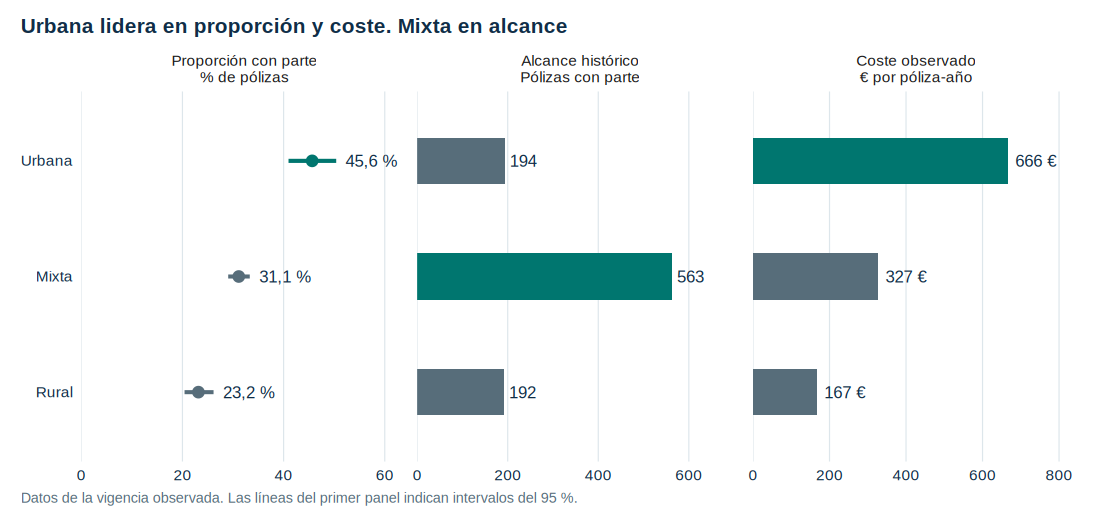

In [ ]:
#@title P1 · Dónde concentrar la prevención
evalq({
    exposicion_poliza <- rowsum(panel$expo_anual, panel$id_poliza)

    coste_zona <- aggregate(
        cbind(
            coste = cartera$coste_total,
            exposicion = exposicion_poliza[as.character(cartera$id_poliza), 1]
            ),
        by = list(zona = cartera$zona_circulacion),
        FUN = sum
        )

    campana <- zonas
    orden_zona <- match(campana$zona, coste_zona$zona)
    campana$coste <- coste_zona$coste[orden_zona] /
        coste_zona$exposicion[orden_zona]

    medidas_campana <- c(
        "Proporción con parte\n% de pólizas",
        "Alcance histórico\nPólizas con parte",
        "Coste observado\n€ por póliza-año"
        )
    grafico_campana <- data.frame(
        zona = factor(
            rep(campana$zona, 3),
            levels = c("rural", "mixta", "urbana"),
            labels = c("Rural", "Mixta", "Urbana")
            ),
        medida = factor(
            rep(medidas_campana, each = nrow(campana)),
            levels = medidas_campana
            ),
        valor = c(100 * campana$prop, campana$casos, campana$coste),
        posicion = c(100 * campana$sup, campana$casos, campana$coste),
        etiqueta = c(
            paste0(numero(100 * campana$prop, 1), " %"),
            numero(campana$casos),
            paste0(numero(campana$coste), " €")
            ),
        destaque = c(
            campana$zona == "urbana",
            campana$zona == "mixta",
            campana$zona == "urbana"
            ),
        inf = c(100 * campana$inf, rep(NA_real_, 2 * nrow(campana))),
        sup = c(100 * campana$sup, rep(NA_real_, 2 * nrow(campana)))
        )

    campana_proporcion <- grafico_campana[grafico_campana$medida == medidas_campana[1], ]
    campana_columnas <- grafico_campana[grafico_campana$medida != medidas_campana[1], ]

    p1_grafico <- ggplot(grafico_campana, aes(valor, zona)) +
        geom_col(
            data = campana_columnas,
            aes(fill = destaque),
            width = .40
            ) +
        geom_segment(
            data = campana_proporcion,
            aes(x = inf, xend = sup, yend = zona, colour = destaque),
            linewidth = 1.2
            ) +
        geom_point(
            data = campana_proporcion,
            aes(colour = destaque),
            size = 3
            ) +
        geom_text(
            aes(x = posicion, label = etiqueta),
            hjust = -.18,
            size = 3.7,
            colour = marino
            ) +
        facet_grid(cols = vars(medida), scales = "free_x") +
        expand_limits(x = 0) +
        scale_x_continuous(expand = expansion(mult = c(0, .28))) +
        scale_fill_manual(values = c("FALSE" = gris, "TRUE" = turquesa)) +
        scale_colour_manual(values = c("FALSE" = gris, "TRUE" = turquesa)) +
        labs(
            title = "Urbana lidera en proporción y coste. Mixta en alcance",
            caption = paste(
                "Datos de la vigencia observada.",
                "Las líneas del primer panel indican intervalos del 95 %."
                ),
            x = NULL,
            y = NULL
            ) +
        tema_comite +
        theme(
            legend.position = "none",
            panel.grid.major.y = element_blank()
            )

    figura(p1_grafico)
}, envir = cierre_comite)

### P2 · Usar edad, zona y kilometraje para estimar la frecuencia de las altas

En el primer año de las **766 pólizas reservadas**, el modelo prevé **105,90 partes** y se observan **100**, dentro del intervalo predictivo del 95 % de **84–129 partes**. Al agrupar por tasa anual prevista, la frecuencia observada pasa de **5,24 a 26,22 partes por 100 pólizas-año** entre los grupos extremos. Esto respalda el uso de los tres factores para ordenar el riesgo en la reserva.

En el mismo primer año se estiman **340,22 € frente a 304,57 € observados por póliza-año** (+11,7 %). El coste previsto usa la media de ajuste de **2.407 € por parte**, frente a **2.282 € por parte observado** en ese periodo. La cifra orienta el presupuesto de siniestros y deja abierta la decisión sobre la prima comercial.

En toda la vigencia, el modelo prevé **443,81 partes frente a 450 observados** con la semilla común `20252026`. Las cinco fichas representan un año al ritmo medio estimado durante toda la vigencia.

[Modelo de frecuencia](#scrollTo=1775cdb846e8) · [Validación y fichas](#scrollTo=88ca117d94fa) · [Contraste actuarial](#scrollTo=o6NP2zOujc0V) · [Auditoría por sexo](#scrollTo=7UB1spcyMKnp)

In [ ]:
#@title Ajuste y validación de las cinco fichas { display-mode: "form" }
evalq({
filas_ajuste <- match(ids_ajuste_p2, cartera$id_poliza)
filas_reserva <- match(ids_reserva_p2, cartera$id_poliza)
stopifnot(
  "P2 del comité debe usar la partición común" =
    !anyNA(filas_ajuste) && !anyNA(filas_reserva) &&
    length(intersect(filas_ajuste, filas_reserva)) == 0L
)
desarrollo <- cartera[filas_ajuste, ]
reserva <- cartera[filas_reserva, ]
candidata <- n_siniestros ~ edad_tramo + antiguedad_carnet + potencia_cv +
  antiguedad_vehiculo + valor_vehiculo + zona_circulacion + km10 +
  uso + tipo_vehiculo + combustible + offset(log(antiguedad))
# El offset se conserva en todas las fórmulas candidatas.
tarifa <- stepAIC(glm.nb(candidata, data = desarrollo),
                  k = log(nrow(desarrollo)), trace = FALSE)
formula_final <- formula(tarifa)
poisson_base <- glm(formula_final, poisson, desarrollo)
pred_nb <- predict(tarifa, reserva, type = "response")
pred_p <- predict(poisson_base, reserva, type = "response")
log_nb <- sum(dnbinom(reserva$n_siniestros, mu = pred_nb, size = tarifa$theta, log = TRUE))
log_p <- sum(dpois(reserva$n_siniestros, pred_p, log = TRUE))
quintil <- cut(rank(pred_nb, ties.method = "first"), breaks = 5, labels = FALSE)
calibracion <- aggregate(
  cbind(observado = reserva$n_siniestros, previsto = pred_nb,
        exposicion = reserva$antiguedad),
  list(quintil = quintil), sum
)
tasas <- predict(tarifa, perfiles, se.fit = TRUE)
perfiles$media <- exp(tasas$fit)
perfiles$inf <- exp(tasas$fit - 1.96 * tasas$se.fit)
perfiles$sup <- exp(tasas$fit + 1.96 * tasas$se.fit)
set.seed(semilla)
ip_perfil <- sapply(seq_len(nrow(perfiles)), function(i) {
  mu <- exp(rnorm(10000, tasas$fit[i], tasas$se.fit[i]))
  quantile(rnbinom(length(mu), mu = mu, size = tarifa$theta), c(.025, .975))
})
}, envir = cierre_comite)

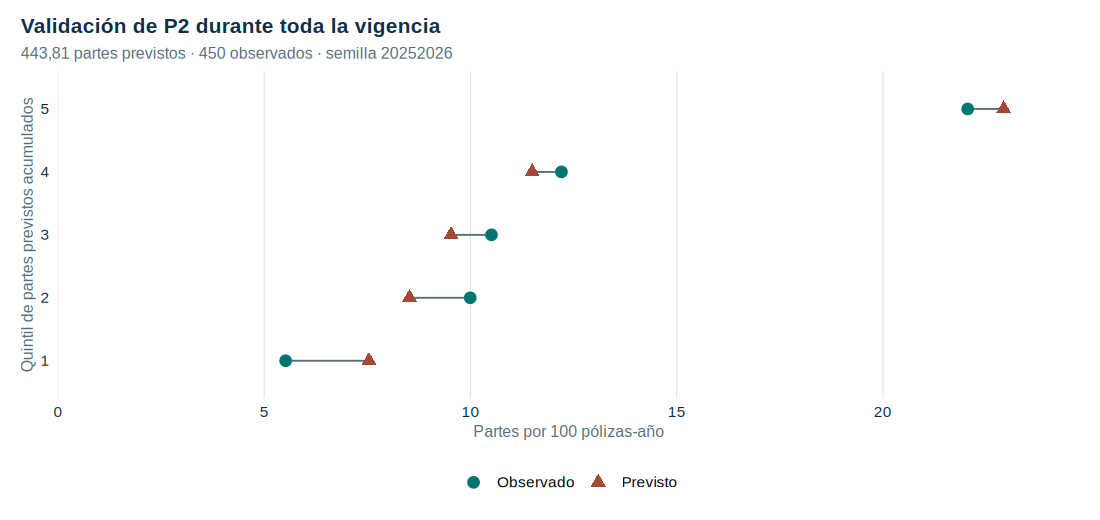

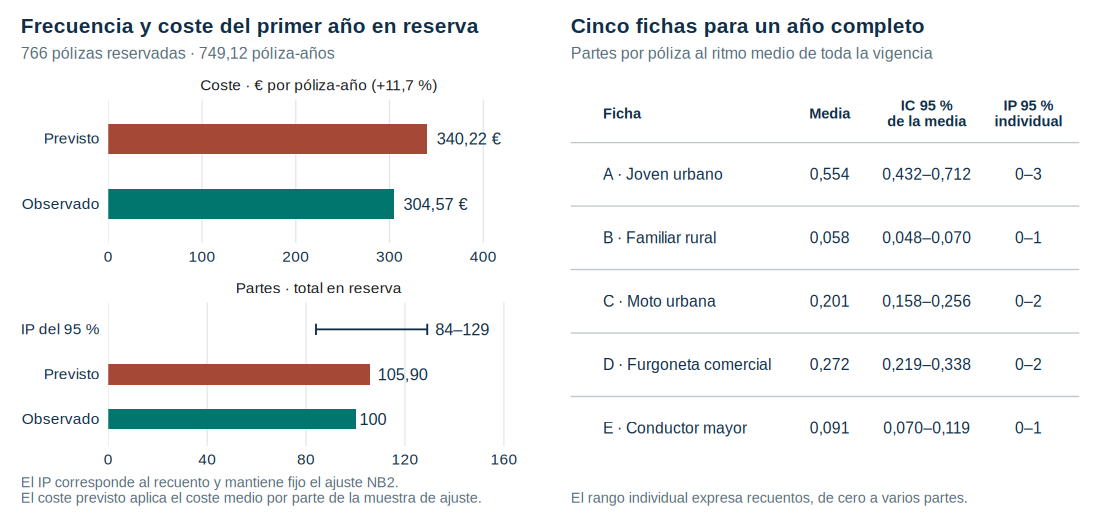

In [ ]:
#@title P2 · Calibración de altas y cinco fichas
evalq({
    tramo_alta <- panel[panel$anio == 1 & panel$id_poliza %in% ids_reserva_p2, ]
    tramo_alta <- tramo_alta[match(reserva$id_poliza, tramo_alta$id_poliza), ]
    stopifnot(
        "El contraste del primer año debe usar la misma reserva de P2" =
            identical(as.character(reserva$id_poliza), as.character(ids_reserva_p2)) &&
            identical(reserva$id_poliza, tramo_alta$id_poliza) &&
            all(tramo_alta$expo_anual > 0 & tramo_alta$expo_anual <= 1)
        )
    alta_reserva <- reserva
    alta_reserva$antiguedad <- tramo_alta$expo_anual
    exposicion_alta <- sum(tramo_alta$expo_anual)

    coste_medio_desarrollo <- mean(
        partes$coste_k[partes$id_poliza %in% desarrollo$id_poliza]
        )
    coste_observado_alta <- sum(
        partes$coste_k[partes$anio == 1 & partes$id_poliza %in% reserva$id_poliza]
        )
    media_poliza <- predict(tarifa, alta_reserva, type = "response")
    partes_previstos_alta <- sum(media_poliza)
    partes_observados_alta <- sum(tramo_alta$n_partes_anual)

    # Sumamos los recuentos NB2 independientes con los parámetros del ajuste fijos.
    # Truncar el soporte no altera las probabilidades de los totales incluidos.
    varianza_alta <- sum(media_poliza + media_poliza^2 / tarifa$theta)
    soporte <- 0:ceiling(partes_previstos_alta + 10 * sqrt(varianza_alta))
    prob_total <- c(1, numeric(length(soporte) - 1L))
    for (media in media_poliza) {
        prob_poliza <- dnbinom(soporte, size = tarifa$theta, mu = media)
        prob_total <- pmax(0, convolve(prob_total, rev(prob_poliza), type = "open")[
            seq_along(soporte)])
        }
    acumulada <- cumsum(prob_total)
    stopifnot("La suma NB2 debe cubrir el percentil 97,5 %" = tail(acumulada, 1) >= .975)
    ip_alta <- vapply(
        c(.025, .975),
        function(p) soporte[which(acumulada >= p)[1L]],
        numeric(1)
        )

    observado_alta <- c(
        coste_observado_alta / exposicion_alta,
        partes_observados_alta
        )
    previsto_alta <- c(
        partes_previstos_alta * coste_medio_desarrollo / exposicion_alta,
        partes_previstos_alta
        )

    exceso_coste <- 100 * (previsto_alta[1] / observado_alta[1] - 1)
    medidas_alta <- c(
        paste0(
            "Coste · € por póliza-año (", ifelse(exceso_coste > 0, "+", ""),
            numero(exceso_coste, 1), " %)"
            ),
        "Partes · total en reserva"
        )
    series_alta <- c("Observado", "Previsto", "IP del 95 %")
    validacion_alta <- data.frame(
        medida = factor(rep(medidas_alta, 2), levels = medidas_alta),
        serie = factor(
            rep(c("Observado", "Previsto"), each = 2),
            levels = series_alta
            ),
        resultado = c(observado_alta, previsto_alta),
        etiqueta = c(
            paste0(numero(observado_alta[1], 2), " €"),
            numero(observado_alta[2]),
            paste0(numero(previsto_alta[1], 2), " €"),
            numero(previsto_alta[2], 2)
            )
        )

    intervalo_alta <- data.frame(
        medida = factor(medidas_alta[2], levels = medidas_alta),
        serie = factor("IP del 95 %", levels = series_alta),
        inferior = ip_alta[1],
        superior = ip_alta[2],
        etiqueta = paste(numero(ip_alta, 0), collapse = "–")
        )

    p2_validacion <- ggplot(validacion_alta, aes(resultado, serie)) +
        geom_col(aes(fill = serie), width = .46) +
        geom_text(
            aes(label = etiqueta),
            hjust = -.15,
            size = 3.6,
            colour = marino
            ) +
        geom_errorbar(
            data = intervalo_alta,
            aes(xmin = inferior, xmax = superior, y = serie),
            inherit.aes = FALSE,
            orientation = "y",
            width = .25,
            colour = marino
            ) +
        geom_text(
            data = intervalo_alta,
            aes(x = superior, y = serie, label = etiqueta),
            inherit.aes = FALSE,
            hjust = -.15,
            size = 3.6,
            colour = marino
            ) +
        facet_wrap(vars(medida), ncol = 1, scales = "free") +
        scale_x_continuous(expand = expansion(mult = c(0, .32))) +
        scale_fill_manual(values = c("Observado" = turquesa, "Previsto" = riesgo)) +
        labs(
            title = "Frecuencia y coste del primer año en reserva",
            subtitle = paste0(
                numero(nrow(alta_reserva)), " pólizas reservadas · ",
                numero(exposicion_alta, 2), " póliza-años"
                ),
            caption = paste0(
                "El IP corresponde al recuento y mantiene fijo el ajuste NB2.
",
                "El coste previsto aplica el coste medio por parte de la muestra de ajuste."
                ),
            x = NULL,
            y = NULL
            ) +
        tema_comite +
        theme(
            legend.position = "none",
            panel.grid.major.y = element_blank()
            )

    fichas_alta <- data.frame(
        fila = rev(seq_len(nrow(perfiles))),
        ficha = perfiles$perfil,
        media = numero(perfiles$media, 3),
        confianza = paste0(numero(perfiles$inf, 3), "–", numero(perfiles$sup, 3)),
        prediccion = paste0(numero(ip_perfil[1, ]), "–", numero(ip_perfil[2, ]))
        )
    encabezados_fichas <- data.frame(
        columna = c(.02, .51, .72, .94),
        rotulo = c("Ficha", "Media", "IC 95 %\nde la media", "IP 95 %\nindividual"),
        alineacion = c(0, .5, .5, .5)
        )

    p2_fichas <- ggplot(fichas_alta, aes(y = fila)) +
        geom_hline(
            yintercept = fichas_alta$fila + .49,
            colour = gris,
            alpha = .38,
            linewidth = .4
            ) +
        geom_text(aes(x = .02, label = ficha), hjust = 0, size = 3.45, colour = marino) +
        geom_text(aes(x = .51, label = media), size = 3.45, colour = marino) +
        geom_text(aes(x = .72, label = confianza), size = 3.45, colour = marino) +
        geom_text(aes(x = .94, label = prediccion), size = 3.45, colour = marino) +
        geom_text(
            data = encabezados_fichas,
            aes(columna, nrow(fichas_alta) + .95, label = rotulo, hjust = alineacion),
            inherit.aes = FALSE,
            fontface = "bold",
            lineheight = .9,
            size = 3.2,
            colour = marino
            ) +
        coord_cartesian(xlim = c(0, 1), ylim = c(.42, nrow(fichas_alta) + 1.32)) +
        labs(
            title = "Cinco fichas para un año completo",
            subtitle = "Partes por póliza al ritmo medio de toda la vigencia",
            caption = "El rango individual expresa recuentos, de cero a varios partes."
            ) +
        tema_comite +
        theme(
            axis.text = element_blank(),
            axis.title = element_blank(),
            axis.ticks = element_blank(),
            panel.grid.major.x = element_blank()
            )

    vigencia <- transform(
        calibracion,
        grupo = factor(quintil),
        observado = 100 * observado / exposicion,
        previsto = 100 * previsto / exposicion
        )
    p2_vigencia <- ggplot(vigencia, aes(y = grupo)) +
        geom_segment(aes(x = observado, xend = previsto, yend = grupo), colour = gris) +
        geom_point(aes(x = observado, colour = "Observado"), size = 3) +
        geom_point(aes(x = previsto, colour = "Previsto"), shape = 17, size = 3) +
        scale_colour_manual(values = c("Observado" = turquesa, "Previsto" = riesgo)) +
        scale_x_continuous(expand = expansion(mult = c(0, .08)), limits = c(0, NA)) +
        labs(
            title = "Validación de P2 durante toda la vigencia",
            subtitle = paste0(
                numero(sum(pred_nb), 2), " partes previstos · ",
                numero(sum(reserva$n_siniestros)), " observados · semilla 20252026"
                ),
            y = "Quintil de partes previstos acumulados",
            x = "Partes por 100 pólizas-año"
            ) +
        tema_comite

    figura(p2_vigencia)
    figura(p2_validacion, p2_fichas)
}, envir = cierre_comite)

### P3 · Presupuestar la apertura y priorizar la auditoría de costes

Para una apertura con **102 pólizas durante un año**, dotaría **34.500 € de coste esperado**, a partir de **14,3 partes** y del coste medio por parte de la red. Prepararía capacidad para **25 partes**. Es el extremo superior del intervalo predictivo **6–25 partes** bajo el supuesto prudente de una pequeña variación entre oficinas. La primera anualidad histórica, al mismo volumen, arroja **29.400 €**.

Auditaría primero la **agencia 8**. Su coste quedó **85.844 € por debajo** de lo esperado durante la vigencia observada y el desvío mantiene evidencia tras comparar las 30 oficinas. Daría seguimiento a la **28** por sus **111.056 € de exceso**, con evidencia estadística más débil. El seguimiento de frecuencia señala a **25, 28 y 26**. El contraste global de frecuencia aporta poca evidencia de un efecto propio de agencia (**p = 0,69**). Revisaría expedientes de coberturas y daños equivalentes para interpretar las brechas.

[Modelo territorial](#scrollTo=baa29e7d1602) · [Previsión por agencia, región y apertura](#scrollTo=50cc9dda4748) · [Auditoría de las 30 agencias](#scrollTo=7L4KGnr5VWas)

In [ ]:
#@title Previsión de Jorge para la red territorial
evalq({
    # Jorge, Pregunta_2_3_final.qmd (f4b52f3).
    # Se conserva un ajuste local para poder ejecutar el comité por separado.
    cargar_paquetes(c("MASS", "glmmTMB"))
    formula_red <- formula_cliente_p3

    red_cliente <- MASS::glm.nb(formula_red, data = cartera)
    red_agencia <- MASS::glm.nb(
        update(formula_red, . ~ . + factor(id_agencia)),
        data = cartera
        )
    p_agencia <- pchisq(
        2 * as.numeric(logLik(red_agencia) - logLik(red_cliente)),
        df = attr(logLik(red_agencia), "df") - attr(logLik(red_cliente), "df"),
        lower.tail = FALSE
        )

    red_anidada <- glmmTMB::glmmTMB(
        update(formula_red, . ~ . + (1 | id_region / id_agencia)),
        family = glmmTMB::nbinom2,
        data = cartera,
        REML = TRUE
        )
    stopifnot(red_anidada$fit$convergence == 0L, red_anidada$sdr$pdHess)
    componentes <- glmmTMB::VarCorr(red_anidada)$cond
    desviaciones_red <- vapply(componentes, function(x) attr(x, "stddev")[1], numeric(1))

    red_anual <- transform(cartera, antiguedad = 1)
    red_anual$media <- predict(red_cliente, red_anual, type = "response")
    nueva_n <- round(nrow(red_anual) / length(unique(red_anual$id_agencia)))

    prever_red <- function(medias, n, mezcla_nueva = FALSE, sd_agencia = 0) {
        simulados <- replicate(10000, {
            # El mismo desplazamiento afecta a las n pólizas del escenario.
            desplazamiento <- if (sd_agencia > 0) rnorm(1, 0, sd_agencia) else 0
            mu <- if (mezcla_nueva) sample(medias, n, replace = TRUE) else medias
            sum(rnbinom(n, mu = mu * exp(desplazamiento), size = red_cliente$theta))
            })
        intervalo <- unname(quantile(simulados, c(.025, .975)))
        data.frame(
            polizas = n,
            media = n * mean(medias) * exp(sd_agencia^2 / 2),
            inferior = intervalo[1], superior = intervalo[2]
            )
        }

    oficina <- red_anual$media[red_anual$id_agencia == 28]
    region <- red_anual$media[red_anual$id_region == 6]
    ejemplo_cartera <- withr::with_seed(SEMILLA_CURSO, {
        list(
            oficina = prever_red(oficina, length(oficina)),
            region = prever_red(region, length(region))
            )
        })
    ejemplo_oficina <- ejemplo_cartera$oficina
    ejemplo_region <- ejemplo_cartera$region
    apertura <- withr::with_seed(
        SEMILLA_CURSO,
        prever_red(red_anual$media, nueva_n, mezcla_nueva = TRUE)
        )
    sensibilidad <- withr::with_seed(
        SEMILLA_CURSO,
        prever_red(
            red_anual$media,
            nueva_n,
            mezcla_nueva = TRUE,
            sd_agencia = .15
            )
        )

    prevision_red <- rbind(ejemplo_oficina, ejemplo_region, apertura, sensibilidad)
    prevision_red$escenario <- c(
        "Agencia 28", "Región 6", "Agencia nueva", "Agencia nueva · estrés"
        )
    print(transform(prevision_red, media = round(media, 2)), row.names = FALSE)
    print(round(c(p_agencia = p_agencia, desviaciones_red), 5))
    }, envir = cierre_comite)

 polizas media inferior superior              escenario
      88 13.97        7       23             Agencia 28
     502 69.05       52       88               Región 6
     102 14.31        7       23          Agencia nueva
     102 14.47        6       25 Agencia nueva · estrés
           p_agencia id_agencia:id_region            id_region 
             0.69338              0.00006              0.01827 


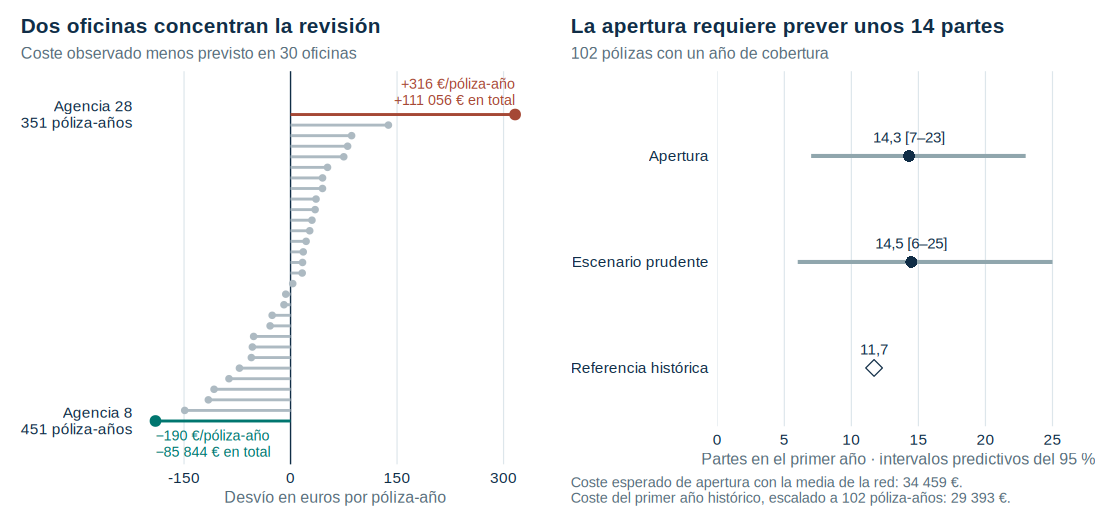

In [ ]:
#@title P3 · Auditoría de oficinas y apertura
# P3 · Desvíos de coste por oficina y presupuesto de apertura
evalq({
    # El mismo ajuste territorial alimenta la auditoría y la apertura.
    partes_esperados <- predict(
            red_cliente,
            newdata = cartera,
            type = "response"
            )
    stopifnot(length(partes_esperados) == nrow(cartera))
    coste_por_parte <- mean( partes$coste_k )
    exposicion_por_poliza <- rowsum(
            panel$expo_anual,
            panel$id_poliza
            )
    polizas_red <- transform(
            cartera,
            anios = exposicion_por_poliza[ as.character(id_poliza), 1 ],
            coste_esperado = partes_esperados * coste_por_parte
            )
    auditoria_p3 <- aggregate(
            cbind(anios, coste_total, coste_esperado) ~ id_agencia,
            data = polizas_red,
            FUN = sum
            )
    auditoria_p3$brecha <- with(
            auditoria_p3,
            (coste_total - coste_esperado) / anios
            )
    auditoria_p3 <- auditoria_p3[ order(auditoria_p3$brecha), ]
    auditoria_p3$posicion <- seq_len(nrow(auditoria_p3))
    auditoria_p3$senal <- "Otras oficinas"
    auditoria_p3$senal[ auditoria_p3$id_agencia == 8 ] <- "Agencia 8"
    auditoria_p3$senal[ auditoria_p3$id_agencia == 28 ] <- "Agencia 28"

    extremos <- subset(
            auditoria_p3,
            id_agencia %in% c(8, 28)
            )
    stopifnot(
            nrow(auditoria_p3) == 30L,
            identical(as.integer(extremos$id_agencia), c(8L, 28L)),
            all(auditoria_p3$anios > 0),
            extremos$brecha[1] < 0, extremos$brecha[2] > 0
            )
    firmado <- function(valor) {
        paste0(
                ifelse(valor < 0, "−", "+"),
                numero(abs(valor), 0)
                )
        }
    extremos$etiqueta <- paste0(
            firmado(extremos$brecha),
            " €/póliza-año\n",
            firmado(extremos$coste_total - extremos$coste_esperado),
            " € en total"
            )
    extremos$oficina <- paste0(
            extremos$senal,
            "\n",
            numero(extremos$anios, 0),
            " póliza-años"
            )
    extremos$posicion_etiqueta <- extremos$posicion + c(-0.9, 0.9)

    grafico_auditoria <- ggplot(
            auditoria_p3,
            aes(y = posicion, colour = senal)
            ) +
        geom_vline(xintercept = 0, colour = marino, linewidth = 0.4) +
        geom_segment(
                aes(x = 0, xend = brecha, yend = posicion),
                linewidth = 0.85
                ) +
        geom_point(aes(x = brecha), size = 1.5) +
        geom_point(aes(x = brecha), data = extremos, size = 2.7) +
        geom_text(
                aes(x = brecha, y = posicion_etiqueta, label = etiqueta),
                data = extremos,
                vjust = c(1, 0),
                hjust = c(0, 1),
                size = 3.15,
                lineheight = 0.95
                ) +
        scale_colour_manual(
                values = c(
                        "Otras oficinas" = "#ADBAC2",
                        "Agencia 8" = turquesa,
                        "Agencia 28" = riesgo
                        ),
                guide = "none"
                ) +
        scale_x_continuous(
                breaks = c(-150, 0, 150, 300),
                labels = function(x) numero(x, 0),
                expand = expansion(add = c(20, 20))
                ) +
        scale_y_continuous(
                breaks = extremos$posicion,
                labels = extremos$oficina,
                expand = expansion(add = c(3.2, 3.2))
                ) +
        labs(
                title = "Dos oficinas concentran la revisión",
                subtitle = "Coste observado menos previsto en 30 oficinas",
                x = "Desvío en euros por póliza-año",
                y = NULL
                ) +
        tema_comite +
        theme(
                panel.grid.major.y = element_blank(),
                panel.grid.minor.y = element_blank(),
                axis.ticks.y = element_blank()
                )

    apertura_p3 <- subset(
            prevision_red,
            startsWith(escenario, "Agencia nueva")
            )
    cubierta_primer_anio <- sum(panel$expo_anual[ panel$anio == 1L ])
    partes_primer_anio <- sum(panel$n_partes_anual[ panel$anio == 1L ])
    coste_primer_anio <- sum(partes$coste_k[ partes$anio == 1L ])
    exposicion_apertura <- apertura_p3$polizas[ 1 ]
    stopifnot(nrow(apertura_p3) == 2L, exposicion_apertura == 102L)

    escenario_apertura <- data.frame(
            escenario = factor(
                    c("Apertura", "Escenario prudente", "Referencia histórica"),
                    levels = c("Referencia histórica", "Escenario prudente", "Apertura")
                    ),
            media = c(
                    apertura_p3$media,
                    partes_primer_anio / cubierta_primer_anio * exposicion_apertura
                    ),
            inferior = c(apertura_p3$inferior, NA),
            superior = c(apertura_p3$superior, NA)
            )
    rotulo_media <- numero(escenario_apertura$media, 1)
    rotulo_media[ 1:2 ] <- paste0(
            rotulo_media[ 1:2 ],
            " [",
            escenario_apertura$inferior[ 1:2 ],
            "–",
            escenario_apertura$superior[ 1:2 ],
            "]"
            )
    escenario_apertura$rotulo <- rotulo_media
    coste_apertura <- apertura_p3$media[ 1 ] * coste_por_parte
    coste_referencia <- coste_primer_anio / cubierta_primer_anio * exposicion_apertura

    grafico_apertura <- ggplot(
            escenario_apertura,
            aes(x = media, y = escenario)
            ) +
        geom_segment(
                aes(x = inferior, xend = superior, yend = escenario),
                data = subset(escenario_apertura, is.finite(inferior)),
                colour = "#90A6AD",
                linewidth = 1.2
                ) +
        geom_point(
                aes(shape = escenario == "Referencia histórica"),
                colour = marino,
                size = 3.1
                ) +
        geom_text(
                aes(label = rotulo),
                vjust = -1.35,
                colour = marino,
                size = 3.3
                ) +
        scale_shape_manual(values = c(16, 5), guide = "none") +
        scale_x_continuous(
                breaks = scales::breaks_width(5),
                limits = c(0, NA),
                expand = expansion(add = c(0, 2))
                ) +
        scale_y_discrete(
                limits = levels(escenario_apertura$escenario),
                expand = expansion(add = c(0.55, 0.8))
                ) +
        labs(
                title = "La apertura requiere prever unos 14 partes",
                subtitle = "102 pólizas con un año de cobertura",
                x = "Partes en el primer año · intervalos predictivos del 95 %",
                y = NULL,
                caption = paste0(
                        "Coste esperado de apertura con la media de la red: ",
                        numero(coste_apertura, 0),
                        " €.\nCoste del primer año histórico, escalado a 102 póliza-años: ",
                        numero(coste_referencia, 0),
                        " €."
                        )
                ) +
        tema_comite +
        theme(panel.grid.major.y = element_blank())

    figura(grafico_auditoria, grafico_apertura)
    }, envir = cierre_comite)

### P4 · Las altas absorben el ahorro de la cartera actual

El presupuesto central pasa de **1,151 M€ a 1,198 M€ (+4,1 %)**. El movimiento de la cartera actual reduce el coste esperado en **65.000 €**. Las 306 altas en nivel 3 añaden **112.000 €** y más que compensan esa reducción. El coste medio baja de **376 a 356 €/póliza**. Si se mantienen la movilidad y la prima de riesgo del escenario central, el coste total empieza a crecer a partir de **178 altas**.

Con el crecimiento previsto, la cartera pasa de 3.062 a **3.368 pólizas**. Prepararía el nivel 3 para **unas 731**, de las cuales 425 proceden de la cartera actual, con un margen de **690 a 770**. Los márgenes del gráfico cuantifican recuentos por nivel. El presupuesto supone renovación de toda la cartera, transiciones estables y un año completo por póliza. Actualizaría los euros con las altas, las bajas y el coste observado por nivel.

[Transiciones del bonus-malus](#scrollTo=0410d7d606d0) · [Prima y presupuesto por nivel](#scrollTo=8Ply1uspNrvo)

In [ ]:
#@title Cálculo de las transiciones entre niveles { display-mode: "form" }
evalq({
tabla <- with(cartera, table(prev = bonus_malus_prev, act = bonus_malus_act))
cambios <- as.data.frame(tabla)
cambios$i <- as.integer(cambios$prev)
cambios$j <- as.integer(cambios$act)
soporte <- subset(cambios, j >= i - 1)
stopifnot(sum(soporte$Freq) == sum(tabla))
transicion <- glm(
  Freq ~ prev + act + I(i == j) + I(i == 1 & j == 1) + I(j == i + 1),
  poisson, soporte
)
# Con apalancamiento uno, la varianza residual de la celda es cero.
comprobables <- hatvalues(transicion) < 1 - sqrt(.Machine$double.eps)
res_transicion <- residuals(transicion, type = "pearson")[comprobables] /
  sqrt(1 - hatvalues(transicion)[comprobables])

matriz_p <- function(b) {
  M <- matrix(0, 5, 5)
  M[cbind(soporte$i, soporte$j)] <- exp(model.matrix(transicion) %*% b)
  M / rowSums(M)
}
actual <- colSums(tabla)
altas <- c(0, 0, round(.10 * sum(actual)), 0, 0)
P <- matriz_p(coef(transicion))
proyeccion <- drop(actual %*% P) + altas
set.seed(semilla)
betas <- mvrnorm(5000, coef(transicion), vcov(transicion))
simular_niveles <- function(b) {
  probs <- matriz_p(b)
  movimientos <- sapply(1:5, function(i) rmultinom(1, actual[i], probs[i, ]))
  rowSums(movimientos) + altas
}
proyectados <- apply(betas, 1, simular_niveles)
stopifnot(all(colSums(proyectados) == sum(actual + altas)))
ip_nivel <- t(apply(proyectados, 1, quantile, c(.025, .975)))
# Bowker (parejas con movimientos) y Stuart-Maxwell para datos apareados.
ady <- upper.tri(tabla) & (tabla + t(tabla) > 0)
bowker <- sum(((tabla - t(tabla))^2)[ady] / (tabla + t(tabla))[ady])
diferencia <- (rowSums(tabla) - colSums(tabla))[-5]
V <- diag(rowSums(tabla) + colSums(tabla)) - tabla - t(tabla)
stuart <- drop(crossprod(diferencia, solve(V[-5, -5], diferencia)))
}, envir = cierre_comite)

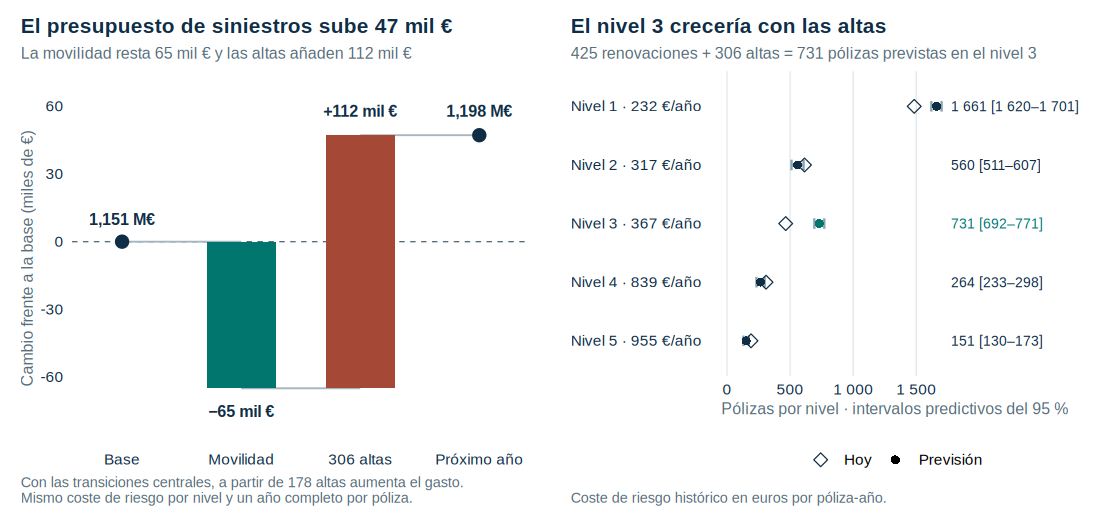

In [ ]:
#@title P4 · Presupuesto y composición del bonus-malus
# P4 · Coste de siniestros con el reparto actual y el proyectado
evalq({
    ultimo_anio <- with(panel, ave(anio, id_poliza, FUN = max))
    ultima_etapa <- subset(
            panel,
            anio >= 2L & anio == ultimo_anio
            )
    stopifnot(!anyDuplicated(ultima_etapa$id_poliza))
    costes_por_etapa <- aggregate(
            coste_k ~ id_poliza + anio,
            data = partes,
            FUN = sum
            )
    ultima_etapa <- merge(
            ultima_etapa,
            costes_por_etapa,
            by = c("id_poliza", "anio"),
            all.x = TRUE,
            sort = FALSE
            )
    ultima_etapa$coste_k[ is.na(ultima_etapa$coste_k) ] <- 0

    # La clase del comienzo de la etapa está disponible antes de observar su coste.
    nivel_por_poliza <- match(ultima_etapa$id_poliza, cartera$id_poliza)
    ultima_etapa$nivel <- factor(
            cartera$bonus_malus_prev[ nivel_por_poliza ],
            levels = 1:5
            )
    experiencia_p4 <- aggregate(
            cbind(coste_k, expo_anual, n_partes_anual) ~ nivel,
            data = ultima_etapa,
            FUN = sum
            )
    stopifnot(
            all(experiencia_p4$expo_anual > 0),
            identical(as.integer(experiencia_p4$nivel), 1:5),
            length(actual) == 5L,
            sum(altas) == 306L
            )
    prima_riesgo <- with(
            experiencia_p4,
            coste_k / expo_anual
            )
    renovadas <- as.numeric(proyeccion - altas)
    cuenta_hoy <- as.numeric( actual )

    # Mismo orden de sorteos que Luis en la celda 236.
    set.seed( semilla )
    centros <- coef( transicion )
    covarianza <- vcov( transicion )
    simulaciones_p4 <- replicate(5000L, {
        parametros <- MASS::mvrnorm(1L, centros, covarianza)
        simular_niveles( parametros )
        })
    stopifnot(all(colSums(simulaciones_p4) == sum(actual + altas)))
    bandas_p4 <- t(apply(simulaciones_p4, 1, quantile, c(0.025, 0.975)))
    tabla_p4 <- data.frame(
            nivel = 1:5,
            hoy = cuenta_hoy,
            renovadas = renovadas,
            altas = as.numeric( altas ),
            previstas = as.numeric( proyeccion ),
            inferior = bandas_p4[ , 1 ],
            superior = bandas_p4[ , 2 ],
            euros_anuales = prima_riesgo,
            exposicion_historica = experiencia_p4$expo_anual,
            partes_historicos = experiencia_p4$n_partes_anual
            )
    presupuesto_base <- sum(cuenta_hoy * prima_riesgo)
    cambio_movilidad <- sum((renovadas - cuenta_hoy) * prima_riesgo)
    coste_altas <- sum(altas * prima_riesgo)
    cambio_total <- cambio_movilidad + coste_altas
    presupuesto_proximo <- sum(proyeccion * prima_riesgo)
    altas_equilibrio <- ceiling(-cambio_movilidad / prima_riesgo[ 3 ])
    stopifnot(
            isTRUE(all.equal(
                    presupuesto_proximo,
                    presupuesto_base + cambio_total
                    )),
            all(round(c(presupuesto_base, presupuesto_proximo)) ==
                c(1150565, 1197750)),
            altas_equilibrio == 178L
            )

    puente_p4 <- data.frame(
            paso = 1:4,
            inicio = c(0, 0, cambio_movilidad, cambio_total) / 1000,
            fin = c(0, cambio_movilidad, cambio_total, cambio_total) / 1000
            )
    puente_p4$etiqueta <- c(
            paste0(numero(presupuesto_base / 1e6, 3), " M€"),
            paste0("−", numero(abs(cambio_movilidad) / 1000, 0), " mil €"),
            paste0("+", numero(coste_altas / 1000, 0), " mil €"),
            paste0(numero(presupuesto_proximo / 1e6, 3), " M€")
            )
    puente_p4$altura_etiqueta <- c(10, -75, 58, 58)
    cambios_p4 <- subset(puente_p4, paso %in% c(2, 3))
    cambios_p4$sentido <- c("Movilidad", "Altas")
    hitos_p4 <- subset(puente_p4, paso %in% c(1, 4))

    grafico_presupuesto <- ggplot(puente_p4, aes(x = paso)) +
        geom_hline(
                yintercept = 0,
                colour = gris,
                linewidth = 0.4,
                linetype = "dashed"
                ) +
        geom_segment(
                aes(xend = paso + 1, y = fin, yend = fin),
                data = puente_p4[ 1:3, ],
                colour = "#A5B6BE",
                linewidth = 0.55
                ) +
        geom_rect(
                aes(
                        xmin = paso - 0.29,
                        xmax = paso + 0.29,
                        ymin = pmin(inicio, fin),
                        ymax = pmax(inicio, fin),
                        fill = sentido
                        ),
                data = cambios_p4,
                inherit.aes = FALSE
                ) +
        geom_point(aes(y = fin), data = hitos_p4, size = 3.5, colour = marino) +
        geom_text(
                aes(y = altura_etiqueta, label = etiqueta),
                size = 3.55,
                fontface = "bold",
                colour = marino
                ) +
        scale_fill_manual(
                values = c("Movilidad" = turquesa, "Altas" = riesgo),
                guide = "none"
                ) +
        scale_x_continuous(
                breaks = 1:4,
                labels = c("Base", "Movilidad", "306 altas", "Próximo año"),
                expand = expansion(add = 0.42)
                ) +
        scale_y_continuous(
                breaks = c(-60, -30, 0, 30, 60),
                limits = c(-83, 68),
                labels = function(x) numero(x, 0)
                ) +
        labs(
                title = "El presupuesto de siniestros sube 47 mil €",
                subtitle = "La movilidad resta 65 mil € y las altas añaden 112 mil €",
                x = NULL,
                y = "Cambio frente a la base (miles de €)",
                caption = paste0(
                        "Con las transiciones centrales, a partir de ",
                        altas_equilibrio,
                        " altas aumenta el gasto.\n",
                        "Mismo coste de riesgo por nivel y un año completo por póliza."
                        )
                ) +
        tema_comite +
        theme(panel.grid.major.x = element_blank())

    niveles_p4 <- tabla_p4
    niveles_p4$destacado <- niveles_p4$nivel == 3L
    niveles_p4$posicion <- factor(niveles_p4$nivel, levels = 5:1)
    niveles_p4$etiqueta <- paste0(
            numero(niveles_p4$previstas, 0),
            " [",
            numero(niveles_p4$inferior, 0),
            "–",
            numero(niveles_p4$superior, 0),
            "]"
            )
    entrada_p4 <- paste0(
            numero(renovadas[ 3 ], 0),
            " renovaciones + ",
            numero(altas[ 3 ], 0),
            " altas = ",
            numero(proyeccion[ 3 ], 0),
            " pólizas previstas en el nivel 3"
            )
    grafico_niveles <- ggplot(niveles_p4, aes(y = posicion)) +
        geom_errorbar(
                aes(xmin = inferior, xmax = superior),
                orientation = "y",
                width = 0.18,
                colour = "#87A5AE",
                linewidth = 0.7
                ) +
        geom_point(aes(x = hoy, shape = "Hoy"), colour = marino, size = 2.5) +
        geom_point(
                aes(x = previstas, shape = "Previsión", colour = destacado),
                size = 2.25
                ) +
        geom_text(
                aes(label = etiqueta, colour = destacado),
                x = 1775,
                hjust = 0,
                size = 3.05
                ) +
        scale_colour_manual(values = c(marino, turquesa), guide = "none") +
        scale_shape_manual(values = c("Hoy" = 5, "Previsión" = 16), name = NULL) +
        scale_x_continuous(
                breaks = c(0, 500, 1000, 1500),
                labels = function(x) numero(x, 0),
                limits = c(0, 2660)
                ) +
        scale_y_discrete(
                labels = function(x) paste0(
                        "Nivel ",
                        x,
                        " · ",
                        numero(prima_riesgo[ as.integer(x) ], 0),
                        " €/año"
                        )
                ) +
        labs(
                title = "El nivel 3 crecería con las altas",
                subtitle = entrada_p4,
                x = "Pólizas por nivel · intervalos predictivos del 95 %",
                y = NULL,
                caption = "Coste de riesgo histórico en euros por póliza-año."
                ) +
        tema_comite +
        theme(
                panel.grid.major.y = element_blank(),
                legend.position = "bottom"
                )
    figura(grafico_presupuesto, grafico_niveles)
    }, envir = cierre_comite)

### P5 · Probar el valor del historial al renovar

En el modelo por etapas de Salvador, una póliza comparable tiene **un 29,5 % más de frecuencia prevista** en el segundo año que en el primero, con un intervalo del 95 % de +12,0 % a +49,8 %. Para la ficha A, el complemento actuarial por etapas incluye el uso del vehículo y valora los partes al coste medio del ajuste común. Conocer el historial mueve la referencia anual de **1.466 €** a **979 €** tras cero partes o a **3.063 €** tras dos.

Entre pólizas que completaron el primer año y siguieron expuestas, el coste anual de segundo año fue de **296 €** tras cero partes y **1.208 €** tras dos. El segundo grupo reúne solo **34 pólizas** de perfiles diversos. Priorizaría el contacto de renovación tras dos o más partes en el primer año completo. La estimación del coste del perfil orienta ese seguimiento. La comparación de la ficha A supone un coste medio por parte fijo.

[Modelo por etapas](#scrollTo=403e87403cb2) · [Cinco fichas y efecto en la prima](#scrollTo=t3LpPrVeR-MJ)

In [ ]:
#@title Complemento de P5 · estimación por etapa para las cinco fichas
evalq({
rasgos <- c("edad_tramo", "zona_circulacion", "km10", "uso")
panel[rasgos] <- cartera[indice, rasgos]
panel$etapa <- cut(panel$anio, c(0, 1, 2, 3, 4, 10),
                   labels = c("1", "2", "3", "4", "5–10"))
por_anio <- aggregate(cbind(n_partes_anual, expo_anual) ~ anio, panel, sum)
por_etapa <- aggregate(cbind(n_partes_anual, expo_anual) ~ etapa, panel, sum)

# Un único multiplicador gamma por póliza enlaza sus años observados.
# La integración de este efecto es exacta, sin cuadratura numérica.
ajustar_panel <- function(formula, inicio = NULL) {
  X <- model.matrix(formula, panel)
  k <- ncol(X)
  eventos <- panel$n_partes_anual
  grupo <- panel$id_poliza
  por_poliza <- drop(rowsum(eventos, grupo))
  log_expo <- log(panel$expo_anual)
  perdida <- function(par) {
    theta <- exp(par[k + 1])
    eta <- drop(X %*% par[seq_len(k)]) + log_expo
    acumulada <- drop(rowsum(exp(eta), grupo))
    ajuste <- lgamma(theta + por_poliza) - lgamma(theta) -
      por_poliza * log(theta) -
      (theta + por_poliza) * log1p(acumulada / theta)
    -sum(ajuste) - sum(eventos * eta - lgamma(eventos + 1))
  }
  # El gradiente agrupa la exposición acumulada antes de actualizar cada tasa.
  gradiente <- function(par) {
    theta <- exp(par[k + 1])
    intensidad <- exp(drop(X %*% par[seq_len(k)]) + log_expo)
    acumulada <- rowsum(intensidad, grupo)
    esperado <- (theta + por_poliza) / (theta + drop(acumulada))
    posicion <- match(grupo, rownames(acumulada))
    g_beta <- crossprod(X, intensidad * esperado[posicion] - eventos)
    g_theta <- digamma(theta + por_poliza) - digamma(theta) +
      1 - log1p(drop(acumulada) / theta) - esperado
    c(g_beta, -theta * sum(g_theta))
  }
  if (is.null(inicio)) {
    base <- glm.fit(X, eventos, offset = log_expo, family = poisson())
    inicio <- c(base$coefficients, 0)
  }
  sol <- optim(inicio, perdida, gradiente, method = "BFGS", hessian = TRUE,
               control = list(reltol = 1e-10, maxit = 300))
  stopifnot(sol$convergence == 0, min(eigen(sol$hessian, symmetric = TRUE)$values) > 0)
  list(beta = setNames(sol$par[seq_len(k)], colnames(X)), theta = exp(sol$par[k + 1]),
       cov = solve(sol$hessian), nll = sol$value, k = k + 1, formula = formula)
}
base_panel <- ~ edad_tramo + zona_circulacion + km10 + uso
constante <- ajustar_panel(base_panel)
por_tramos <- update(base_panel, ~ . + etapa)
renovacion <- ajustar_panel(por_tramos)
interacciones <- ajustar_panel(~ etapa * (edad_tramo + zona_circulacion + km10 + uso))
comparar_panel <- function(simple, amplio) {
  pchisq(2 * (simple$nll - amplio$nll), amplio$k - simple$k, lower.tail = FALSE)
}
rejilla <- merge(perfiles[c("perfil", rasgos)], data.frame(etapa = levels(panel$etapa)))
rejilla$etapa <- factor(rejilla$etapa, levels = levels(panel$etapa))
Xp <- model.matrix(por_tramos, rejilla)
Xp <- Xp[, names(renovacion$beta), drop = FALSE]
eta <- drop(Xp %*% renovacion$beta)
Vb <- renovacion$cov[names(renovacion$beta), names(renovacion$beta), drop = FALSE]
ee <- sqrt(rowSums((Xp %*% Vb) * Xp))
rejilla$media <- exp(eta)
rejilla$inf <- exp(eta - 1.96 * ee)
rejilla$sup <- exp(eta + 1.96 * ee)
rejilla$ip_inf <- qnbinom(.025, mu = rejilla$media, size = renovacion$theta)
rejilla$ip_sup <- qnbinom(.975, mu = rejilla$media, size = renovacion$theta)
intensidad <- exp(drop(model.matrix(por_tramos, panel) %*% renovacion$beta)) * panel$expo_anual
# La equivalencia con la NB2 agregada exige los predictores elegidos para el panel.
# Los CSV redondean por separado las exposiciones anual y total.
formula_agregada <- update(base_panel, n_siniestros ~ . + offset(log(antiguedad)))
nb2_agregada <- MASS::glm.nb(formula_agregada, data = cartera)
coeficientes_agregados <- coef(nb2_agregada)[names(constante$beta)]
stopifnot(max(abs(constante$beta - coeficientes_agregados)) < .001)
# Ejemplo de renovación: solo se usa el historial anterior al segundo año.
idx_A <- which(rejilla$perfil == perfiles$perfil[1])
primer_A <- rejilla$media[idx_A[rejilla$etapa[idx_A] == "1"]]
segundo_A <- rejilla$media[idx_A[rejilla$etapa[idx_A] == "2"]]
renovar_A <- function(partes_previos) {
  segundo_A * (renovacion$theta + partes_previos) / (renovacion$theta + primer_A)
}
}, envir = cierre_comite)

In [ ]:
#@title P5 · Efecto de la antigüedad y el historial sobre la prima
local({
    modelo <- cierre_comite
    ajuste <- modelo$desarrollo
    coste_por_parte <- sum(ajuste$coste_total) / sum(ajuste$n_siniestros)
    prima_comun <- sum(modelo$cartera$coste_total) / sum(modelo$panel$expo_anual)
    rejilla <- modelo$rejilla

    etapa <- as.character(rejilla$etapa)
    ficha_a <- as.character(modelo$perfiles$perfil[1])
    edades <- which(as.character(rejilla$perfil) == ficha_a)
    edades <- edades[order(rejilla$etapa[edades])]
    stopifnot(
        identical(etapa[edades], c("1", "2", "3", "4", "5–10")),
        coste_por_parte > 0, prima_comun > 0
        )

    tasas <- c(rejilla$media[edades], modelo$renovar_A(c(0, 2)))
    primas <- tasas * coste_por_parte
    num <- numero_cartera
    escenarios <- data.frame(
        "Año de cobertura" = c(etapa[edades], "2", "2"),
        "Historial al cotizar" = c(rep("Desconocido", length(edades)),
            "Primer año completo: 0 partes", "Primer año completo: 2 partes"),
        "Partes previstos por año" = num(tasas, 3),
        "Relatividad (×)" = num(primas / prima_comun, 3),
        "Prima modelada (€/póliza-año)" = num(primas, 2),
        check.names = FALSE
        )

    por_etapa <- reshape(
        data.frame(Ficha = rejilla$perfil, etapa = etapa,
            prima = num(rejilla$media * coste_por_parte, 2)),
        idvar = "Ficha", timevar = "etapa", direction = "wide"
        )
    names(por_etapa) <- sub("^prima[.]", "Año ", names(por_etapa))
    tabla <- function(datos) {
        knitr::kable(datos, format = "html", row.names = FALSE)
        }
    html <- paste0(
        "<style>.p5-primas{color:#17344d;background:#f1f5f7;padding:12px 16px;",
        "border-left:3px solid #256d71}.p5-primas p{margin:6px 0}.p5-primas table{",
        "width:100%;border-collapse:collapse;font-variant-numeric:tabular-nums}",
        ".p5-primas th,.p5-primas td{border:1px solid #bdcdd8;padding:5px 7px}",
        ".p5-primas th{color:white;background:#17344d}.p5-primas tr:nth-child(even){",
        "background:#e2edf3}.p5-primas summary{cursor:pointer;font-weight:bold;margin:8px 0}</style>",
        "<div class='p5-primas'><b>Ficha A · Joven urbano</b>",
        "<p>El complemento actuarial de P5 estima la frecuencia por etapa, ",
        "incluye el uso del vehículo e incorpora el historial conocido al renovar. ",
        "Aplicamos el mismo coste medio por parte que en P2 (", num(coste_por_parte, 2),
        " €). La prima anual es frecuencia × coste por parte. Su relatividad la compara ",
        "con la prima común de ", num(prima_comun, 2), " €/póliza-año.</p>",
        tabla(escenarios),
        "<p>Cada fila supone un año completo de cobertura. El historial desconocido ",
        "usa la frecuencia media del perfil. Al renovar con historial, el modelo ",
        "actualiza esa frecuencia según los partes del primer año. ",
        "El tramo 5–10 expresa la prima de cada año de ese tramo.</p>",
        "<p><b>Lectura de renovación.</b> Sin historial conocido, el salto del primer ",
        "al segundo año de la ficha A añade ", num(primas[2] - primas[1], 2),
        " € al año (", num(100 * (primas[2] / primas[1] - 1), 1), " %). ",
        "Para ese segundo año, conocer cero partes resta ",
        num(primas[2] - primas[6], 2), " € a la estimación sin historial. ",
        "Conocer dos añade ", num(primas[7] - primas[2], 2), " €.</p>",
        "<p>Son primas de riesgo estimadas con el ajuste del panel completo. ",
        "Las diferencias muestran el efecto previsto del historial y la antigüedad.</p>",
        "<details><summary>Las cinco fichas sin historial · primas por etapa</summary>",
        "<p>Importes en €/póliza-año.</p>", tabla(por_etapa), "</details></div>"
        )
    IRdisplay::display_html(html)
    })

Ficha A · Joven urbano El complemento actuarial de P5 estima la frecuencia por etapa, incluye el uso del vehículo e incorpora el historial conocido al renovar. Aplicamos el mismo coste medio por parte que en P2 (2.406,61 €). La prima anual es frecuencia × coste por parte. Su relatividad la compara con la prima común de 330,95 €/póliza-año. 
 
 
 Año de cobertura 
 Historial al cotizar 
 Partes previstos por año 
 Relatividad (×) 
 Prima modelada (€/póliza-año) 
 
 
 
 
 1 
 Desconocido 
 0,467 
 3,399 
 1.125,00 
 
 
 2 
 Desconocido 
 0,609 
 4,430 
 1.466,25 
 
 
 3 
 Desconocido 
 0,571 
 4,151 
 1.373,70 
 
 
 4 
 Desconocido 
 0,634 
 4,611 
 1.526,03 
 
 
 5–10 
 Desconocido 
 0,641 
 4,660 
 1.542,38 
 
 
 2 
 Primer año completo: 0 partes 
 0,407 
 2,959 
 979,28 
 
 
 2 
 Primer año completo: 2 partes 
 1,273 
 9,254 
 3.062,74 
 
 
 Cada fila supone un año completo de cobertura. El historial desconocido usa la frecuencia media del perfil. Al renovar con historial, el modelo actualiza esa frecuencia según los partes del primer año. El tramo 5–10 expresa la prima de cada año de ese tramo. Lectura de renovación. Sin historial conocido, el salto del primer al segundo año de la ficha A añade 341,25 € al año (30,3 %). Para ese segundo año, conocer cero partes resta 486,97 € a la estimación sin historial. Conocer dos añade 1.596,49 €. Son primas de riesgo estimadas con el ajuste del panel completo. Las diferencias muestran el efecto previsto del historial y la antigüedad. Las cinco fichas sin historial · primas por etapa Importes en €/póliza-año. 
 
 
 Ficha 
 Año 1 
 Año 2 
 Año 3 
 Año 4 
 Año 5–10 
 
 
 
 
 A · Joven urbano 
 1.125,00 
 1.466,25 
 1.373,70 
 1.526,03 
 1.542,38 
 
 
 B · Familiar rural 
 114,97 
 149,84 
 140,38 
 155,95 
 157,62 
 
 
 C · Moto urbana 
 405,85 
 528,96 
 495,58 
 550,53 
 556,43 
 
 
 D · Furgoneta comercial 
 621,57 
 810,11 
 758,97 
 843,13 
 852,16 
 
 
 E · Conductor mayor 
 168,73 
 219,91 
 206,03 
 228,87 
 231,33

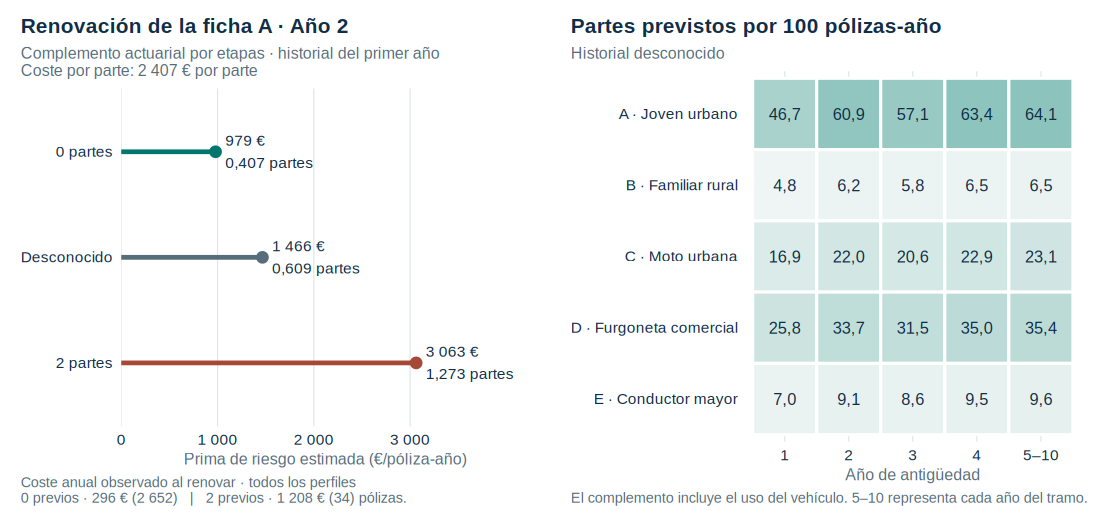

In [ ]:
#@title P5 · Historial y frecuencia de renovación
evalq({
    ficha_a <- perfiles$perfil[1]
    media_a <- rejilla$media[
        rejilla$perfil == ficha_a & rejilla$etapa == "2"
        ]
    coste_por_parte <- sum(desarrollo$coste_total) /
        sum(desarrollo$n_siniestros)

    historiales <- c(
        "0 partes",
        "Desconocido",
        "2 partes"
        )
    frecuencias <- renovar_A(c(0, 2))
    renovacion_a <- data.frame(
        historial = factor(historiales, levels = rev(historiales)),
        frecuencia = c(frecuencias[1], media_a, frecuencias[2])
        )
    renovacion_a$prima <- renovacion_a$frecuencia * coste_por_parte
    renovacion_a$etiqueta <- paste0(
        numero(renovacion_a$prima), " €\n",
        numero(renovacion_a$frecuencia, 3), " partes"
        )

    # Contraste histórico de toda la cartera con dos anualidades observables.
    primer_anio_completo <- subset(panel, anio == 1 & expo_anual == 1)
    segundo_anio <- subset(panel, anio == 2 & expo_anual > 0)
    historial_previo <- primer_anio_completo$n_partes_anual[
        match(segundo_anio$id_poliza, primer_anio_completo$id_poliza)
        ]
    partes_segundo <- subset(partes, anio == 2)
    coste_segundo <- rowsum(partes_segundo$coste_k, partes_segundo$id_poliza)
    segundo_anio$coste <- coste_segundo[
        match(segundo_anio$id_poliza, rownames(coste_segundo)),
        1
        ]
    segundo_anio$coste[is.na(segundo_anio$coste)] <- 0
    segundo_anio$previos <- historial_previo
    segundo_anio$polizas <- 1L
    contraste_p5 <- aggregate(
        cbind(coste, expo_anual, polizas) ~ previos,
        data = subset(segundo_anio, previos %in% c(0, 2)),
        FUN = sum
        )
    contraste_p5$coste_anual <- with(contraste_p5, coste / expo_anual)
    stopifnot(identical(as.integer(contraste_p5$previos), c(0L, 2L)))
    lectura_p5 <- paste0(
        contraste_p5$previos, " previos · ",
        numero(contraste_p5$coste_anual), " € (", numero(contraste_p5$polizas), ")"
        )

    grafico_historial <- ggplot(renovacion_a, aes(y = historial)) +
        geom_segment(
            aes(x = 0, xend = prima, yend = historial, colour = historial),
            linewidth = 1.4
            ) +
        geom_point(aes(x = prima, colour = historial), size = 3) +
        geom_text(
            aes(x = prima, label = etiqueta),
            nudge_x = 100,
            hjust = 0,
            size = 3.4,
            colour = marino
            ) +
        scale_colour_manual(
            values = setNames(c(turquesa, gris, riesgo), historiales),
            guide = "none"
            ) +
        scale_x_continuous(
            breaks = c(0, 1000, 2000, 3000),
            labels = numero,
            expand = expansion(mult = c(0, .34))
            ) +
        labs(
            title = "Renovación de la ficha A · Año 2",
            subtitle = paste0(
                "Complemento actuarial por etapas · historial del primer año\nCoste por parte: ",
                numero(coste_por_parte), " € por parte"
                ),
            x = "Prima de riesgo estimada (€/póliza-año)",
            y = NULL,
            caption = paste0(
                "Coste anual observado al renovar · todos los perfiles\n",
                paste(lectura_p5, collapse = "   |   "),
                " pólizas."
                )
            ) +
        tema_comite

    frecuencias_etapa <- transform(
        rejilla,
        ficha = factor(perfil, levels = rev(perfiles$perfil)),
        tasa = 100 * media
        )
    grafico_etapas <- ggplot(frecuencias_etapa, aes(x = etapa, y = ficha)) +
        geom_tile(aes(fill = tasa), colour = "white", linewidth = .9) +
        geom_text(
            aes(label = numero(tasa, 1)),
            colour = marino,
            size = 3.6
            ) +
        scale_fill_gradient(low = "#EEF5F4", high = "#8CC3BD", guide = "none") +
        labs(
            title = "Partes previstos por 100 pólizas-año",
            subtitle = "Historial desconocido",
            x = "Año de antigüedad",
            y = NULL,
            caption = "El complemento incluye el uso del vehículo. 5–10 representa cada año del tramo."
            ) +
        tema_comite +
        theme(panel.grid = element_blank())

    figura(grafico_historial, grafico_etapas)
}, envir = cierre_comite)